In [0]:
# set whether normal process or being run by Elsevier supporters
permissions = 'default' # default or fulldata
# set the project name
project_name = 'proj_050_teamscience'  # This is the folder name that you work in, e.g. 'test_project_1'

In [0]:
%run /Snippets/header_latest

## Python Libraries and Functions

In [0]:
# libraries 
from pyspark.sql.functions import col, count, explode, array, mean, stddev, filter, percentile_approx, arrays_zip, size, array_distinct, sum, reverse, collect_list, array_sort, posexplode, max, arrays_overlap, lit, when
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import Window
from pyspark.ml.feature import StringIndexer

# make a DF to store everything
model_output_df = pd.DataFrame(columns = ["model", "coef", "se", "t", "p", "r2"])
descriptives_output_df = pd.DataFrame(columns = ["model", "subjareas", "mean", "sd", "sample", "median", "iqr_25", "iqr_75"])

# model summary print out 
def modelsummary(model, hyp_model, df):
    import numpy as np
    print ("Note: the last rows are the information for Intercept")
    print ("##","-------------------------------------------------")
    print ("##","  Estimate   |   Std.Error | t Values  |  P-value")
    coef = np.append(list(model.coefficients),model.intercept)
    Summary=model.summary

    for i in range(len(Summary.pValues)):
        print ("##",'{:10.6f}'.format(coef[i]),\
        '{:10.6f}'.format(Summary.coefficientStandardErrors[i]),\
        '{:8.3f}'.format(Summary.tValues[i]),\
        '{:10.6f}'.format(Summary.pValues[i]))
        # store the data 
        row = pd.DataFrame({"model": hyp_model, "coef": coef[i], "se": Summary.coefficientStandardErrors[i], 
               "t": Summary.tValues[i], "p": Summary.pValues[i], "r2": Summary.r2}, index = [0])
        df = pd.concat([df, row], ignore_index = True, axis = 0)

    print ("##",'---')
    print ("##","Mean squared error: % .6f" \
           % Summary.meanSquaredError, ", RMSE: % .6f" \
           % Summary.rootMeanSquaredError )
    print ("##","Multiple R-squared: %f" % Summary.r2, ", \
            Total iterations: %i"% Summary.totalIterations)
    return(df)

## Research Question 1a

### Descriptive Statistics

We will first calculate the mean, median, and interquartile range of team size by discipline. We will not explicitly compare discipline intercepts in a post hoc format with any form of test. Instead we will use visualization techniques to display the distribution and their interquartile range for readers to examine (i.e., a forest plot).

In [0]:
# load the ANI dataframe which contains author information 
df_ani = spark.read.format("parquet").load(basePath+tablename_ani)
df_ani.createOrReplaceTempView("df_ani")
df_ani.printSchema()
df_ani = df_ani.filter(df_ani.Year > 1969)\
  .filter(df_ani.publication_type == "ar")

df_ani.count()

# display(df_ani)

root
-- Eid: long (nullable = true)
-- Year: integer (nullable = true)
-- title: string (nullable = true)
-- ASJC: array (nullable = true)
 |-- element: string (containsNull = true)
-- subjareas: array (nullable = true)
 |-- element: string (containsNull = true)
-- Af: array (nullable = true)
 |-- element: struct (containsNull = true)
 | |-- affiliation_address_part: string (nullable = true)
 | |-- affiliation_city: string (nullable = true)
 | |-- affiliation_city_group: string (nullable = true)
 | |-- affiliation_country: string (nullable = true)
 | |-- affiliation_ids: array (nullable = true)
 | | |-- element: long (containsNull = true)
 | |-- affiliation_organization: array (nullable = true)
 | | |-- element: string (containsNull = true)
 | |-- affiliation_organization_count: short (nullable = true)
 | |-- affiliation_postal_code: string (nullable = true)
 | |-- affiliation_state: string (nullable = true)
 | |-- affiliation_tag_country: string (nullable = true)
 | |-- affiliation_text: string (nullable = true)
 | |-- afid: long (nullable = true)
 | |-- dptid: long (nullable = true)
-- Au: array (nullable = true)
 |-- element: struct (containsNull = true)
 | |-- Authorseq: integer (nullable = true)
 | |-- auid: long (nullable = true)
 | |-- author_type: string (nullable = true)
 | |-- collaboration: string (nullable = true)
 | |-- degrees: string (nullable = true)
 | |-- email_sha1: string (nullable = true)
 | |-- given_name: string (nullable = true)
 | |-- given_name_pn: string (nullable = true)
 | |-- indexed_name: string (nullable = true)
 | |-- indexed_name_pn: string (nullable = true)
 | |-- initials: string (nullable = true)
 | |-- initials_pn: string (nullable = true)
 | |-- nametext: string (nullable = true)
 | |-- orcid: string (nullable = true)
 | |-- suffix: string (nullable = true)
 | |-- surname: string (nullable = true)
 | |-- surname_pn: string (nullable = true)
-- Au_Af: array (nullable = true)
 |-- element: struct (containsNull = true)
 | |-- Authorseq: short (nullable = true)
 | |-- affiliation_seq: short (nullable = true)
 | |-- validity_B: boolean (nullable = true)
-- Au_cors: array (nullable = true)
 |-- element: struct (containsNull = true)
 | |-- Authorseq: integer (nullable = true)
 | |-- auid: long (nullable = true)
 | |-- author_type: string (nullable = true)
 | |-- collaboration: string (nullable = true)
 | |-- degrees: string (nullable = true)
 | |-- email_sha1: string (nullable = true)
 | |-- given_name: string (nullable = true)
 | |-- given_name_pn: string (nullable = true)
 | |-- indexed_name: string (nullable = true)
 | |-- indexed_name_pn: string (nullable = true)
 | |-- initials: string (nullable = true)
 | |-- initials_pn: string (nullable = true)
 | |-- nametext: string (nullable = true)
 | |-- orcid: string (nullable = true)
 | |-- suffix: string (nullable = true)
 | |-- surname: string (nullable = true)
 | |-- surname_pn: string (nullable = true)
-- abstract: string (nullable = true)
-- abstract_lang: string (nullable = true)
-- publication_type: string (nullable = true)
-- references: array (nullable = true)
 |-- element: long (containsNull = true)
-- copyright_types: array (nullable = true)
 |-- element: string (containsNull = true)
-- title_lang: string (nullable = true)
-- title_original: string (nullable = true)
-- sort_yyyymm: string (nullable = true)
-- openaccess: string (nullable = true)
-- pmid: string (nullable = true)
-- doi: string (nullable = true)
-- n_references: long (nullable = true)
-- correspondence: array (nullable = true)
 |-- element: struct (containsNull = true)
 | |-- country: string (nullable = true)
 | |-- txt: string (nullable = true)
-- orig_load_date: string (nullable = true)
-- date_sort_day: string (nullable = true)
-- date_sort_month: string (nullable = true)
-- datesort: string (nullable = true)
-- issn: string (nullable = true)
-- issue: string (nullable = true)
-- volume: string (nullable = true)
-- firstpage: string (nullable = true)
-- lastpage: stri

In [0]:
df_hyp1 = df_ani.select("Eid", "Year", "Au", "subjareas", "CitationCount")\
  .withColumn("Au", explode("Au"))\
  .withColumn("subjareas", explode("subjareas"))\
  .groupBy("Eid", "Year", "subjareas", "CitationCount")\
  .agg(count("Au").alias("team_size"))

# display(df_hyp1)

summary_df = df_hyp1.select("subjareas", "team_size")\
  .groupBy("subjareas")\
  .agg(mean("team_size").alias("mean"), stddev("team_size").alias("sd"), count("team_size").alias("sample"), percentile_approx("team_size", 0.5, 10000).alias("median"), percentile_approx("team_size", 0.25, 10000).alias("iqr_25"), percentile_approx("team_size", 0.75, 10000).alias("iqr_75"))\
  .toPandas()
summary_df["model"] = "hyp1a"
descriptives_output_df = pd.concat([descriptives_output_df, summary_df], ignore_index = True, axis = 0)

# descriptives_output_df

### Overall Summary

In order to determine if team sizes change overall across time, we will use a linear model of team size predicted by year of publication in which each article is only represented once, regardless of discipline. We will examine if the confidence interval of the slope parameter is different from zero to determine if the predictor was significant.

In [0]:
# get the total number of authors by year 
df_hyp1_overall = df_ani.select("Eid", "Year", "Au", "CitationCount", explode("Au").alias("author"))\
  .groupBy("Eid", "Year", "CitationCount")\
  .agg(count("author").alias("team_size"))

# display(df_hyp1_overall)

# team size ~ year of publication on the entire dataset 
# the "features" or X must be in this feature format
vectorAssembler = VectorAssembler(inputCols = ['Year'], outputCol = "pub_year")
df_hyp1_overall = vectorAssembler.setHandleInvalid("skip").transform(df_hyp1_overall)

# put in the features X and prediction Y
lr = LinearRegression(featuresCol = 'pub_year', labelCol='team_size')
lr_model = lr.fit(df_hyp1_overall)
model_output_df = modelsummary(lr_model, "hyp1a", model_output_df)

# model_output_df

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.102909 0.004338 23.722 0.000000
## -200.971800 8.717657 -23.053 0.000000
## ---
## Mean squared error: 967.454920 , RMSE: 31.103937
## Multiple R-squared: 0.000981 , Total iterations: 0

/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

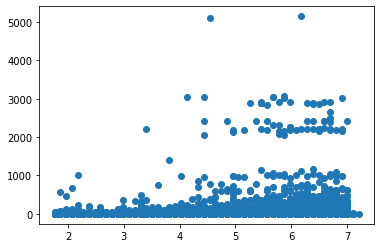

In [0]:
# data screening overall 
if (permissions == "default"):
  residuals = lr_model.summary.residuals.select('residuals').collect()
  predictions = lr_model.summary.predictions.select('prediction').collect()

  plt.scatter(predictions, residuals)
  plt.show()


### Summary By Subject Area

Last, we will calculate each discipline's slope and confidence interval using a linear model of team size predicted by year of publication. Again, we will provide these slopes in a visualization for readers to examine with no official post hoc comparison. While a multilevel model would allow us to embed all disciplines within one model, no *pyspark* multilevel model implementation exists to model data at this scale.

COMP

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.074020 0.001485 49.832 0.000000
## -145.340606 2.988997 -48.625 0.000000
## ---
## Mean squared error: 5.424214 , RMSE: 2.328994
## Multiple R-squared: 0.067167 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

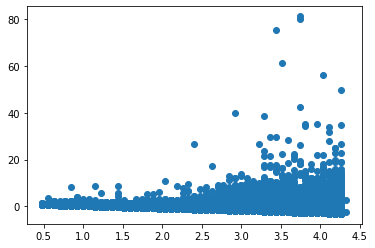

IMMU

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.126950 0.004147 30.612 0.000000
## -248.270603 8.331003 -29.801 0.000000
## ---
## Mean squared error: 42.506911 , RMSE: 6.519732
## Multiple R-squared: 0.033409 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

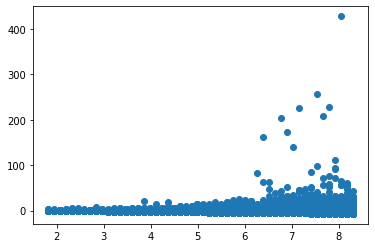

MATE

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.095774 0.001308 73.238 0.000000
## -187.737619 2.630693 -71.364 0.000000
## ---
## Mean squared error: 7.117840 , RMSE: 2.667928
## Multiple R-squared: 0.078049 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

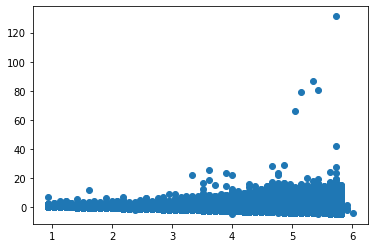

ARTS

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.030213 0.002200 13.731 0.000000
## -58.015819 4.418020 -13.132 0.000000
## ---
## Mean squared error: 6.120462 , RMSE: 2.473957
## Multiple R-squared: 0.017059 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

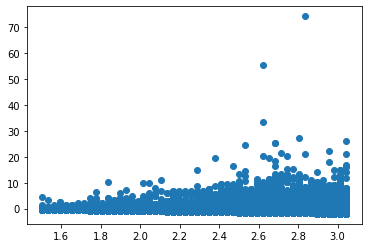

PHYS

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.195395 0.032196 6.069 0.000000
## -384.157478 64.704216 -5.937 0.000000
## ---
## Mean squared error: 6878.470320 , RMSE: 82.936544
## Multiple R-squared: 0.000503 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

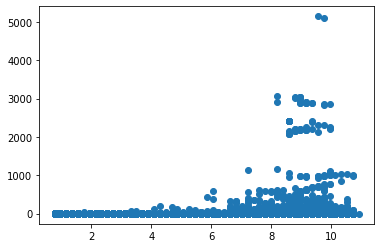

PSYC

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.066061 0.002450 26.959 0.000000
## -129.011013 4.918994 -26.227 0.000000
## ---
## Mean squared error: 13.096201 , RMSE: 3.618867
## Multiple R-squared: 0.036921 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

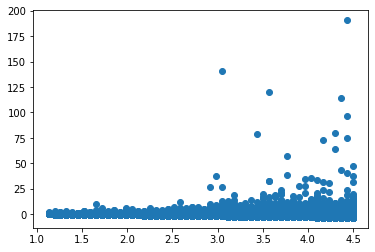

HEAL

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.087115 0.004805 18.132 0.000000
## -170.267718 9.661446 -17.623 0.000000
## ---
## Mean squared error: 10.939315 , RMSE: 3.307463
## Multiple R-squared: 0.049694 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

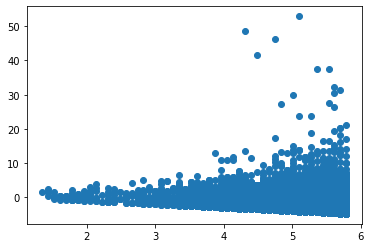

BIOC

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.120758 0.003810 31.692 0.000000
## -236.061743 7.655015 -30.838 0.000000
## ---
## Mean squared error: 140.060904 , RMSE: 11.834733
## Multiple R-squared: 0.008792 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

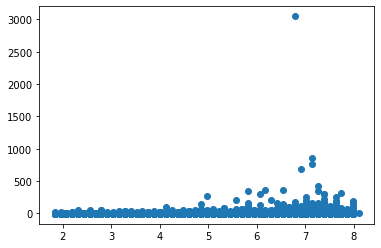

NEUR

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.112012 0.003105 36.073 0.000000
## -219.298582 6.237370 -35.159 0.000000
## ---
## Mean squared error: 22.125786 , RMSE: 4.703806
## Multiple R-squared: 0.048189 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

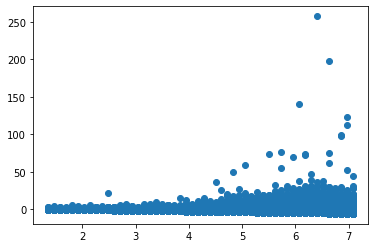

VETE

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.103275 0.006821 15.140 0.000000
## -202.038382 13.708759 -14.738 0.000000
## ---
## Mean squared error: 17.826822 , RMSE: 4.222182
## Multiple R-squared: 0.052021 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

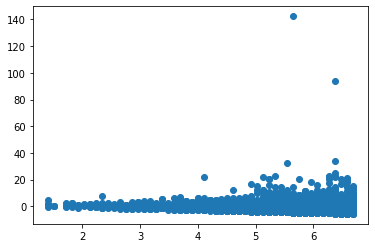

ENGI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.077782 0.009312 8.353 0.000000
## -152.003117 18.728668 -8.116 0.000000
## ---
## Mean squared error: 530.300370 , RMSE: 23.028252
## Multiple R-squared: 0.000933 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

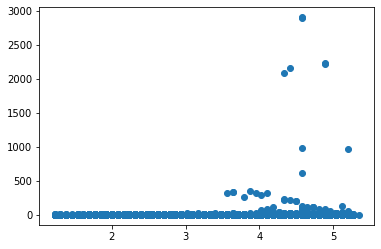

PHAR

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.098144 0.004026 24.376 0.000000
## -191.285437 8.093620 -23.634 0.000000
## ---
## Mean squared error: 28.701208 , RMSE: 5.357351
## Multiple R-squared: 0.026525 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

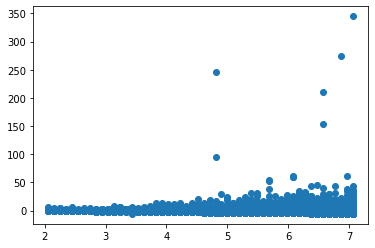

MEDI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.122264 0.003775 32.387 0.000000
## -238.539000 7.583999 -31.453 0.000000
## ---
## Mean squared error: 185.928191 , RMSE: 13.635549
## Multiple R-squared: 0.007023 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

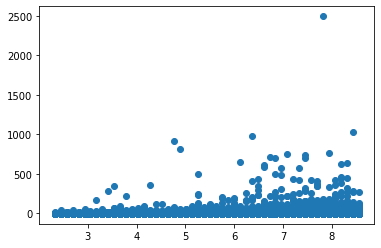

ECON

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.048209 0.001799 26.804 0.000000
## -94.348257 3.613266 -26.112 0.000000
## ---
## Mean squared error: 2.506866 , RMSE: 1.583309
## Multiple R-squared: 0.076490 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

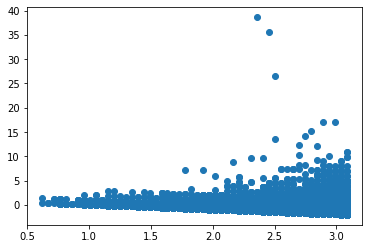

MATH

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.074495 0.040120 1.857 0.063355
## -145.036201 80.620671 -1.799 0.072032
## ---
## Mean squared error: 4027.551793 , RMSE: 63.462995
## Multiple R-squared: 0.000142 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

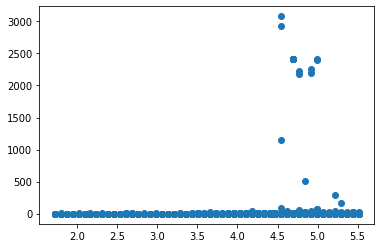

MULT

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.121566 0.017201 7.067 0.000000
## -235.954483 34.553130 -6.829 0.000000
## ---
## Mean squared error: 643.721010 , RMSE: 25.371658
## Multiple R-squared: 0.002273 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

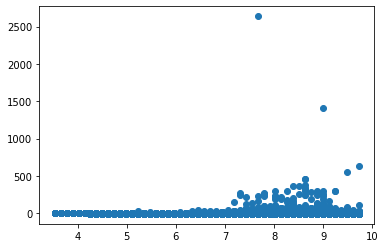

ENVI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.095630 0.002526 37.852 0.000000
## -187.703239 5.081863 -36.936 0.000000
## ---
## Mean squared error: 20.085532 , RMSE: 4.481689
## Multiple R-squared: 0.033941 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

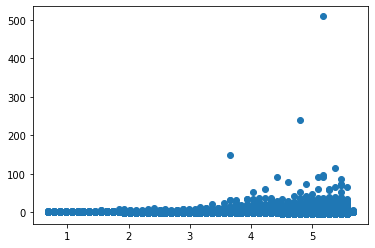

DECI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.059211 0.002871 20.624 0.000000
## -116.153664 5.769770 -20.131 0.000000
## ---
## Mean squared error: 4.206385 , RMSE: 2.050947
## Multiple R-squared: 0.070163 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

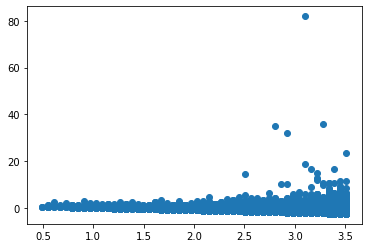

AGRI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.116180 0.002066 56.243 0.000000
## -228.508548 4.152020 -55.036 0.000000
## ---
## Mean squared error: 20.750841 , RMSE: 4.555309
## Multiple R-squared: 0.051621 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

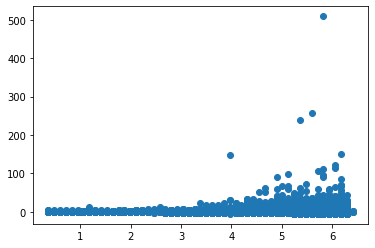

ENER

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.086291 0.002707 31.881 0.000000
## -169.062126 5.448904 -31.027 0.000000
## ---
## Mean squared error: 7.527970 , RMSE: 2.743715
## Multiple R-squared: 0.052932 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

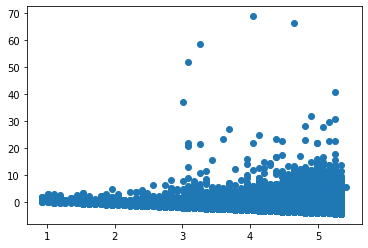

NURS

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.087868 0.007078 12.414 0.000000
## -171.288413 14.231699 -12.036 0.000000
## ---
## Mean squared error: 27.794938 , RMSE: 5.272090
## Multiple R-squared: 0.018548 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

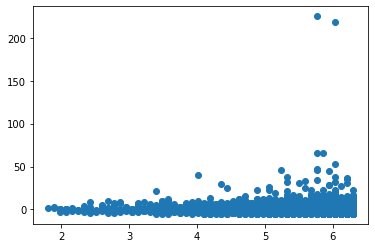

CENG

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.094740 0.001660 57.075 0.000000
## -185.569151 3.339107 -55.574 0.000000
## ---
## Mean squared error: 6.888905 , RMSE: 2.624672
## Multiple R-squared: 0.079222 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

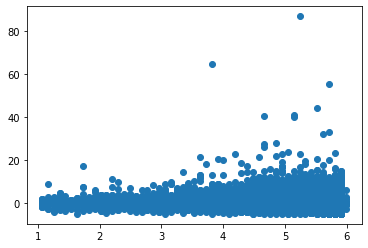

SOCI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.049604 0.001425 34.816 0.000000
## -96.964366 2.863914 -33.857 0.000000
## ---
## Mean squared error: 6.313849 , RMSE: 2.512737
## Multiple R-squared: 0.033776 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

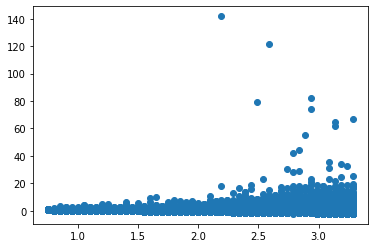

EART

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.137610 0.006765 20.343 0.000000
## -271.085877 13.592527 -19.944 0.000000
## ---
## Mean squared error: 136.074078 , RMSE: 11.665079
## Multiple R-squared: 0.012775 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

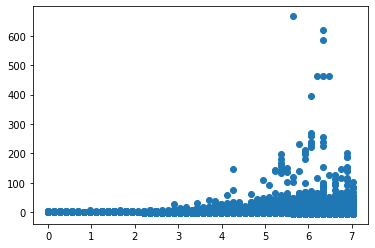

CHEM

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.096557 0.004817 20.044 0.000000
## -189.081563 9.686236 -19.521 0.000000
## ---
## Mean squared error: 135.510796 , RMSE: 11.640910
## Multiple R-squared: 0.005167 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

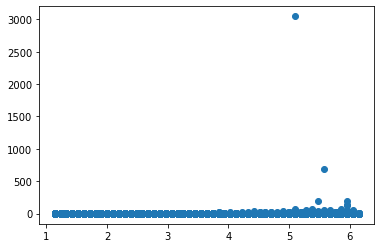

DENT

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.079827 0.004257 18.754 0.000000
## -155.759653 8.548856 -18.220 0.000000
## ---
## Mean squared error: 5.828043 , RMSE: 2.414134
## Multiple R-squared: 0.100182 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

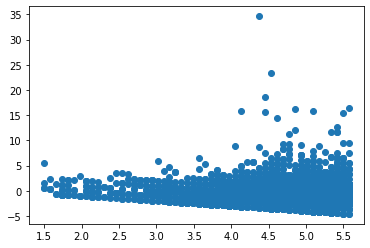

BUSI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.045634 0.002249 20.290 0.000000
## -89.100116 4.520218 -19.711 0.000000
## ---
## Mean squared error: 5.937952 , RMSE: 2.436791
## Multiple R-squared: 0.028833 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

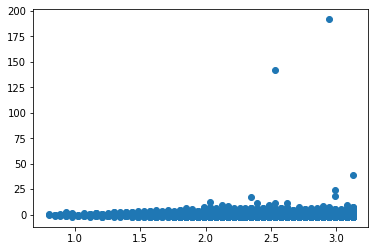

In [0]:
for AREA in descriptives_output_df.subjareas.unique():
  if AREA == 'undefined': continue
  print(AREA)
  print("\n-------\n")
  temp_df = df_hyp1.select("subjareas", "team_size", "Year")\
    .filter(df_hyp1.subjareas == AREA)
  
  vectorAssembler = VectorAssembler(inputCols = ['Year'], outputCol = "pub_year")
  temp_df = vectorAssembler.setHandleInvalid("skip").transform(temp_df)
  lr = LinearRegression(featuresCol = 'pub_year', labelCol='team_size')
  lr_model = lr.fit(temp_df)
  model_output_df = modelsummary(lr_model, ("hyp1a_"+AREA), model_output_df)
  
  # data screening
  if permissions == "default":
    residuals = lr_model.summary.residuals.select('residuals').collect()
    predictions = lr_model.summary.predictions.select('prediction').collect()
    plt.scatter(predictions, residuals)
    plt.show()
  
# model_output_df

## Research Question 1b

### Descriptive Statistics

For this research question, we will examine the impact of team size on article publication metrics for impact. Our hypothesis is that team size impacts article metrics (non-directional). We will run these analyses once for each dependent variable of citation count and weighted citation five year count. We will calculate the mean, median, and interquartile range of each publication metric by discipline. We will visualize these values instead of comparing them directly.

In [0]:
# grab Citations_5y from df_fwci
df_fwci = spark.read.format("parquet").load(fwci_parquet_path)
df_fwci.createOrReplaceTempView("df_fwci")

# display(df_fwci)

# merge this information with tables from above 
df_hyp1_overall = df_hyp1_overall.join(df_fwci.select("Eid", "Citations_5y"), "Eid", "left")

df_hyp1 = df_hyp1.join(df_fwci.select("Eid", "Citations_5y"), "Eid", "left")

In [0]:
# summarize citation count
summary_df = df_hyp1.select("subjareas", "CitationCount")\
  .groupBy("subjareas")\
  .agg(mean("CitationCount").alias("mean"), 
       stddev("CitationCount").alias("sd"), 
       count("CitationCount").alias("sample"), 
       percentile_approx("CitationCount", 0.5, 10000).alias("median"),
       percentile_approx("CitationCount", 0.25, 10000).alias("iqr_25"), 
       percentile_approx("CitationCount", 0.75, 10000).alias("iqr_75"))\
  .toPandas()
summary_df["model"] = "hyp1b_CitationCount"
descriptives_output_df = pd.concat([descriptives_output_df, summary_df], ignore_index = True, axis = 0)

# summarize citation 5y, exclude last 5 years in graph
summary_df = df_hyp1.select("subjareas", "Citations_5y")\
  .groupBy("subjareas")\
  .agg(mean("Citations_5y").alias("mean"), 
       stddev("Citations_5y").alias("sd"), 
       count("Citations_5y").alias("sample"), 
       percentile_approx("Citations_5y", 0.5, 10000).alias("median"),
       percentile_approx("Citations_5y", 0.25, 10000).alias("iqr_25"), 
       percentile_approx("Citations_5y", 0.75, 10000).alias("iqr_75"))\
  .toPandas()
summary_df["model"] = "hyp1b_Citation5y"
descriptives_output_df = pd.concat([descriptives_output_df, summary_df], ignore_index = True, axis = 0)

### Overall Summary 
To determine the impact of team size on publication metrics, we will use a linear model of publication metrics predicted by time (covariate) and team size. We will include time as a covariate, as we expect that older articles will potentially have more or different metrics because they have been around longer to cite. We will examine if the confidence interval of the team size slope parameter is different from zero.

In [0]:
# citation count ~ year of publication + team_size
# the "features" or X must be in this feature format
df_hyp1_overall = df_hyp1_overall.drop("pub_year")
vectorAssembler = VectorAssembler(inputCols = ['Year', 'team_size'], outputCol = "pub_year")
df_hyp1_overall = vectorAssembler.setHandleInvalid("skip").transform(df_hyp1_overall)

# put in the features X and prediction Y
lr = LinearRegression(featuresCol = 'pub_year', labelCol = 'CitationCount')
lr_model = lr.fit(df_hyp1_overall)
model_output_df = modelsummary(lr_model, "hyp1b_CitationCount", model_output_df)

# model_output_df

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.720635 0.109960 -124.779 0.000000
## 0.530589 0.033473 15.851 0.000000
## 27715.459776 220.964248 125.430 0.000000
## ---
## Mean squared error: 620971.558579 , RMSE: 788.017486
## Multiple R-squared: 0.026696 , Total iterations: 0

/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

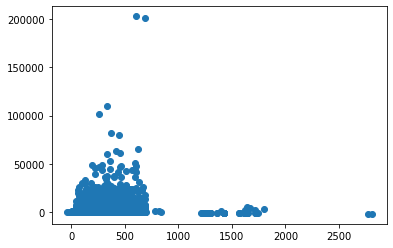

0.0313264517225187

In [0]:
# data screening citation count 
if (permissions == "default"):
  residuals = lr_model.summary.residuals.select('residuals').collect()
  predictions = lr_model.summary.predictions.select('prediction').collect()

  plt.scatter(predictions, residuals)
  plt.show()
  
  print(df_hyp1_overall.stat.corr("Year", "team_size"))

In [0]:
# citation_5y ~ year of publication + team_size
# the "features" or X must be in this feature format
df_hyp1_overall_sub = df_hyp1_overall.drop("pub_year")\
  .filter(df_hyp1_overall.Year < 2017).where(col("Citations_5y").isNotNull())
vectorAssembler = VectorAssembler(inputCols = ['Year', 'team_size'], outputCol = "pub_year")
df_hyp1_overall = vectorAssembler.setHandleInvalid("skip").transform(df_hyp1_overall_sub)

# put in the features X and prediction Y
lr = LinearRegression(featuresCol = 'pub_year', labelCol = 'Citations_5y')
lr_model = lr.fit(df_hyp1_overall)
model_output_df = modelsummary(lr_model, "hyp1b_Citation5y", model_output_df)

# model_output_df

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.597701 0.025280 23.643 0.000000
## 0.329657 0.006438 51.207 0.000000
## -1157.895023 50.716179 -22.831 0.000000
## ---
## Mean squared error: 21081.082764 , RMSE: 145.193260
## Multiple R-squared: 0.007688 , Total iterations: 0

/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

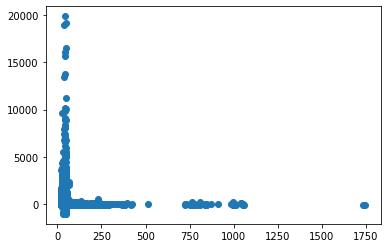

0.037706450310612954

In [0]:
# data screening citation 5y
if (permissions == "default"):
  residuals = lr_model.summary.residuals.select('residuals').collect()
  predictions = lr_model.summary.predictions.select('prediction').collect()

  plt.scatter(predictions, residuals)
  plt.show()

  print(df_hyp1_overall.stat.corr("Year", "team_size"))

### Summary By Subject Area
Last, we will calculate the slope for team size for each discipline separately. We will visualize these differences and the confidence intervals.

COMP

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -27.600037 0.622457 -44.341 0.000000
## 7.917078 2.179406 3.633 0.000281
## 55692.938274 1250.536846 44.535 0.000000
## ---
## Mean squared error: 888522.327227 , RMSE: 942.614623
## Multiple R-squared: 0.055650 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

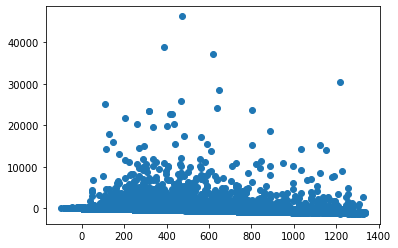

0.2591665581332142
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.645092 0.185367 3.480 0.000502
## 5.486532 0.633562 8.660 0.000000
## -1263.145036 371.687578 -3.398 0.000679
## ---
## Mean squared error: 42368.484257 , RMSE: 205.836062
## Multiple R-squared: 0.005101 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

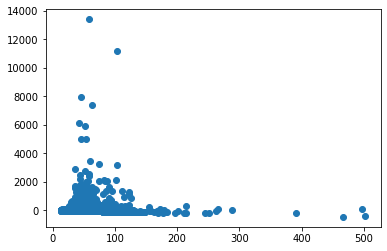

0.22191977997839138
IMMU

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.666514 0.341020 -31.278 0.000000
## 3.683707 0.490994 7.503 0.000000
## 21526.583780 684.468595 31.450 0.000000
## ---
## Mean squared error: 277816.592520 , RMSE: 527.083098
## Multiple R-squared: 0.034943 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

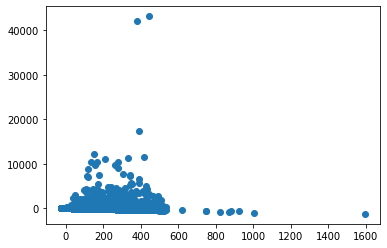

0.1827803759979736
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.097987 0.060103 -1.630 0.103047
## 2.171645 0.089437 24.281 0.000000
## 223.318859 120.434375 1.854 0.063713
## ---
## Mean squared error: 5629.704992 , RMSE: 75.031360
## Multiple R-squared: 0.028111 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

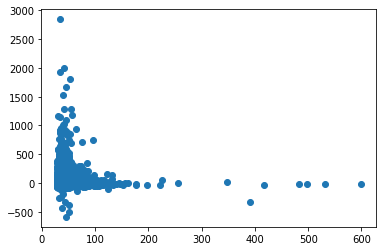

0.2137734635279731
MATE

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.832983 0.239900 -40.988 0.000000
## 6.496244 0.699789 9.283 0.000000
## 19847.027718 481.647964 41.207 0.000000
## ---
## Mean squared error: 220842.925037 , RMSE: 469.939278
## Multiple R-squared: 0.025907 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

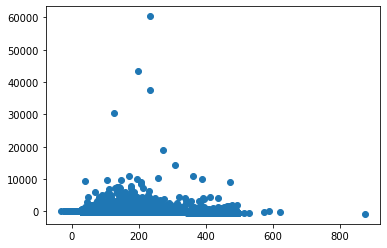

0.2793727103947413
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.738831 0.064449 11.464 0.000000
## 5.128066 0.188276 27.237 0.000000
## -1467.031896 129.165071 -11.358 0.000000
## ---
## Mean squared error: 9282.679307 , RMSE: 96.346662
## Multiple R-squared: 0.026584 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

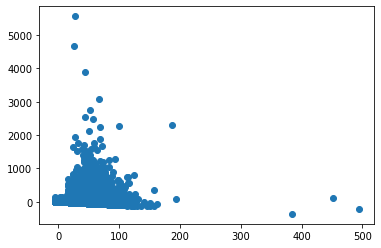

0.2912928871751609
ARTS

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.280616 0.437891 -23.478 0.000000
## 18.555983 1.893000 9.802 0.000000
## 20716.970610 878.563352 23.581 0.000000
## ---
## Mean squared error: 238229.367019 , RMSE: 488.087458
## Multiple R-squared: 0.052128 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

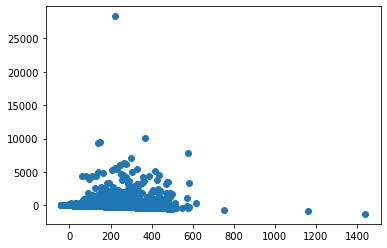

0.13061039780907072
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.143109 0.065313 2.191 0.028470
## 7.302715 0.264274 27.633 0.000000
## -284.255850 130.830904 -2.173 0.029831
## ---
## Mean squared error: 3545.079516 , RMSE: 59.540570
## Multiple R-squared: 0.087193 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

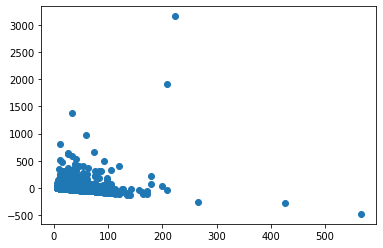

0.12419849217415292
PHYS

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -15.566779 0.355864 -43.744 0.000000
## 0.204492 0.040845 5.006 0.000001
## 31429.374885 715.163535 43.947 0.000000
## ---
## Mean squared error: 839889.952644 , RMSE: 916.455101
## Multiple R-squared: 0.025689 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

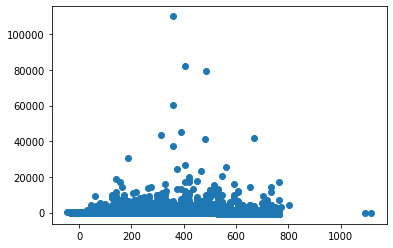

0.022427066723252446
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.788008 0.063073 12.494 0.000000
## 0.164263 0.006096 26.948 0.000000
## -1538.005427 126.544811 -12.154 0.000000
## ---
## Mean squared error: 17293.440281 , RMSE: 131.504526
## Multiple R-squared: 0.016591 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

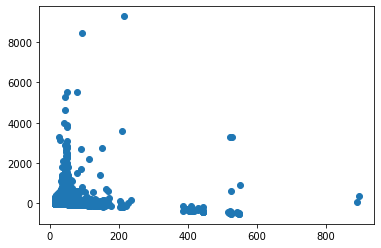

0.037745316433088885
PSYC

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -20.200368 0.643995 -31.367 0.000000
## -1.325679 1.873155 -0.708 0.479125
## 40771.635150 1291.506613 31.569 0.000000
## ---
## Mean squared error: 871134.906875 , RMSE: 933.346081
## Multiple R-squared: 0.051578 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

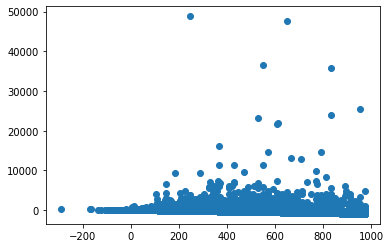

0.1921474645450361
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.427570 0.038654 11.062 0.000000
## 0.495766 0.123469 4.015 0.000060
## -831.233330 77.379143 -10.742 0.000000
## ---
## Mean squared error: 2045.700528 , RMSE: 45.229421
## Multiple R-squared: 0.011042 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

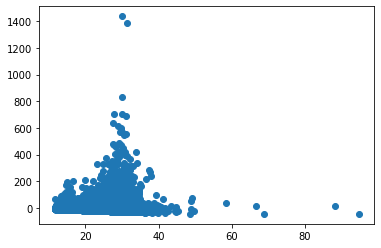

0.20725400399378022
HEAL

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.843040 0.540482 -20.062 0.000000
## 6.350570 1.383054 4.592 0.000004
## 21859.580492 1085.360306 20.140 0.000000
## ---
## Mean squared error: 131535.528197 , RMSE: 362.678271
## Multiple R-squared: 0.060177 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

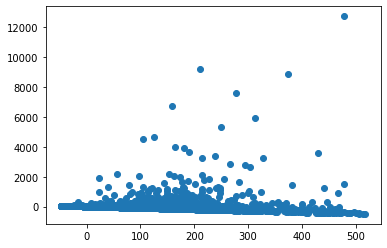

0.22292188425524107
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.310437 0.124356 2.496 0.012585
## 3.049372 0.311982 9.774 0.000000
## -612.477544 249.291753 -2.457 0.014054
## ---
## Mean squared error: 4063.893848 , RMSE: 63.748677
## Multiple R-squared: 0.026619 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

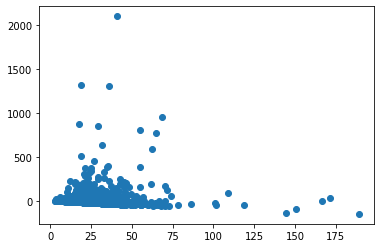

0.21945929836605893
BIOC

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.336037 0.323293 -41.251 0.000000
## 1.332967 0.251026 5.310 0.000000
## 26939.596974 649.343617 41.487 0.000000
## ---
## Mean squared error: 999397.524325 , RMSE: 999.698717
## Multiple R-squared: 0.014823 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

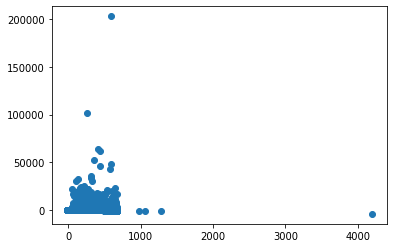

0.09376456755379439
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.439126 0.068547 6.406 0.000000
## 0.749200 0.046306 16.179 0.000000
## -836.804518 137.497403 -6.086 0.000000
## ---
## Mean squared error: 30438.592949 , RMSE: 174.466596
## Multiple R-squared: 0.003644 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

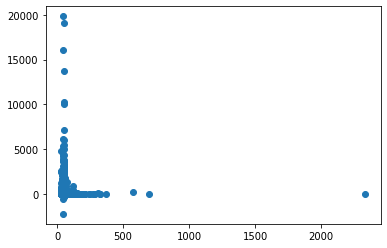

0.09487329550237956
NEUR

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.487197 0.405644 -30.784 0.000000
## 3.594969 0.794977 4.522 0.000006
## 25199.489307 813.841647 30.964 0.000000
## ---
## Mean squared error: 359383.264786 , RMSE: 599.485834
## Multiple R-squared: 0.035750 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

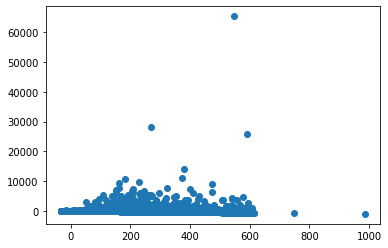

0.2195203103877375
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.015469 0.051756 -0.299 0.765026
## 2.268823 0.102033 22.236 0.000000
## 57.432915 103.684475 0.554 0.579640
## ---
## Mean squared error: 3813.255479 , RMSE: 61.751563
## Multiple R-squared: 0.025324 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

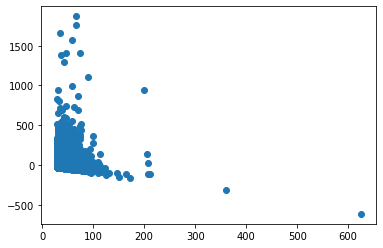

0.23102778602772603
VETE

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.343517 0.104691 -22.385 0.000000
## 0.981406 0.231210 4.245 0.000022
## 4739.296263 210.109157 22.556 0.000000
## ---
## Mean squared error: 3979.675827 , RMSE: 63.084672
## Multiple R-squared: 0.107286 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

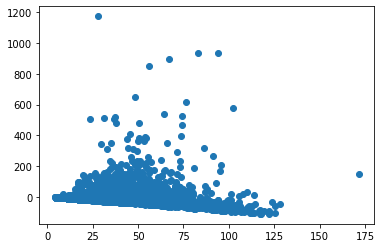

0.22808150553037507
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.266656 0.040019 6.663 0.000000
## 0.722357 0.088172 8.193 0.000000
## -525.890774 80.187585 -6.558 0.000000
## ---
## Mean squared error: 363.398728 , RMSE: 19.063020
## Multiple R-squared: 0.044495 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

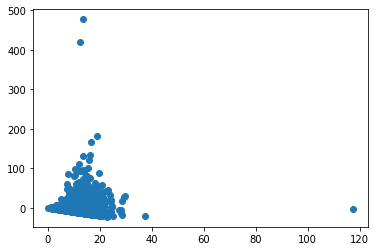

0.20378300837445482
ENGI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.683842 0.193251 -60.459 0.000000
## 0.091768 0.075899 1.209 0.226632
## 23607.463606 388.685298 60.737 0.000000
## ---
## Mean squared error: 228200.080267 , RMSE: 477.702921
## Multiple R-squared: 0.046655 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

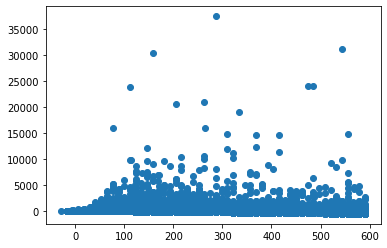

0.03054861431955679
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.076213 0.051304 20.977 0.000000
## 0.076284 0.018489 4.126 0.000037
## -2124.247145 102.976026 -20.629 0.000000
## ---
## Mean squared error: 9757.889715 , RMSE: 98.782031
## Multiple R-squared: 0.009426 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

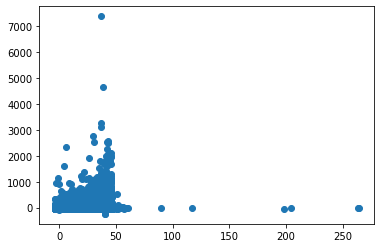

0.03293727544777839
PHAR

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.157500 0.199877 -30.806 0.000000
## 0.602820 0.331688 1.817 0.069165
## 12441.194599 401.478482 30.988 0.000000
## ---
## Mean squared error: 68854.940675 , RMSE: 262.402250
## Multiple R-squared: 0.042149 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

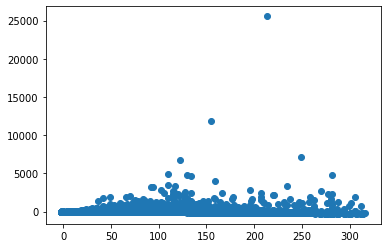

0.1628663309388504
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.223759 0.032132 6.964 0.000000
## 0.472187 0.057895 8.156 0.000000
## -428.120948 64.431779 -6.645 0.000000
## ---
## Mean squared error: 1131.912203 , RMSE: 33.643903
## Multiple R-squared: 0.008611 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

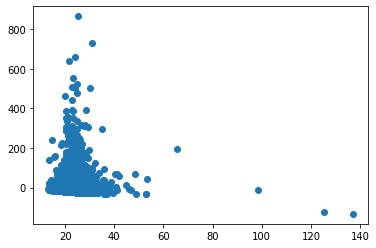

0.16835251523863504
MEDI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.579047 0.148806 -71.093 0.000000
## 3.269091 0.101999 32.050 0.000000
## 21364.413632 298.885421 71.480 0.000000
## ---
## Mean squared error: 286858.461624 , RMSE: 535.591693
## Multiple R-squared: 0.037263 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

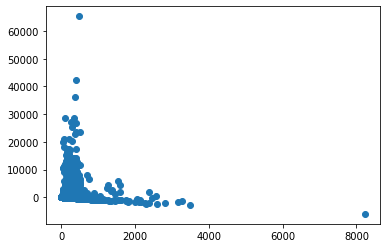

0.08380605869019368
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.529739 0.057296 9.246 0.000000
## 1.770150 0.034865 50.772 0.000000
## -1029.296023 114.919347 -8.957 0.000000
## ---
## Mean squared error: 28438.721768 , RMSE: 168.637842
## Multiple R-squared: 0.023479 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

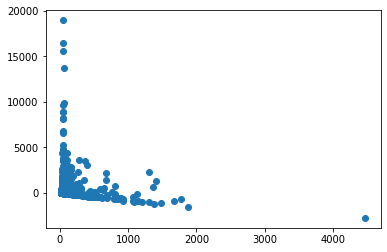

0.09222971151233605
ECON

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -24.694293 1.021950 -24.164 0.000000
## 11.628281 5.862850 1.983 0.047356
## 49791.795218 2049.035923 24.300 0.000000
## ---
## Mean squared error: 747339.833303 , RMSE: 864.488192
## Multiple R-squared: 0.065491 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

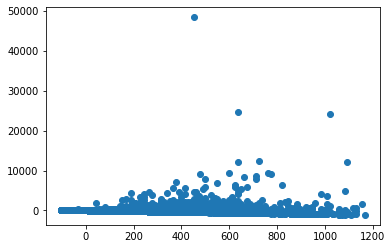

0.27656844456495977
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.338081 0.069189 4.886 0.000001
## 1.724037 0.393337 4.383 0.000012
## -655.149671 138.550123 -4.729 0.000002
## ---
## Mean squared error: 2058.643989 , RMSE: 45.372282
## Multiple R-squared: 0.008575 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

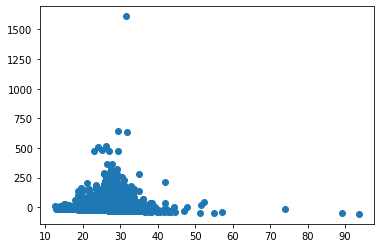

0.22378190421118793
MATH

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -18.628137 0.660051 -28.222 0.000000
## 0.273411 0.105529 2.591 0.009579
## 37629.671813 1326.347278 28.371 0.000000
## ---
## Mean squared error: 1089901.140435 , RMSE: 1043.983305
## Multiple R-squared: 0.031933 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

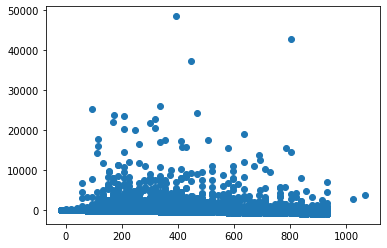

0.011910147007280285
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.010249 0.147282 6.859 0.000000
## 0.102520 0.018897 5.425 0.000000
## -1989.956220 295.399096 -6.737 0.000000
## ---
## Mean squared error: 34879.821390 , RMSE: 186.761402
## Multiple R-squared: 0.004473 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

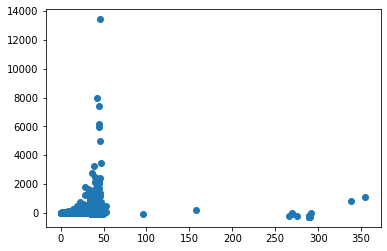

0.022559481203918586
MULT

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -34.065822 1.181358 -28.836 0.000000
## 4.630269 0.463297 9.994 0.000000
## 68792.734594 2372.944443 28.990 0.000000
## ---
## Mean squared error: 3029392.630256 , RMSE: 1740.515047
## Multiple R-squared: 0.039682 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

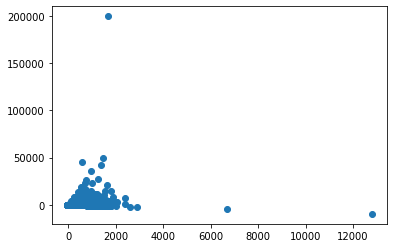

0.047675053302801154
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.833043 0.186952 -4.456 0.000008
## 2.278415 0.064445 35.354 0.000000
## 1775.103073 374.996066 4.734 0.000002
## ---
## Mean squared error: 54257.602093 , RMSE: 232.932613
## Multiple R-squared: 0.068093 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

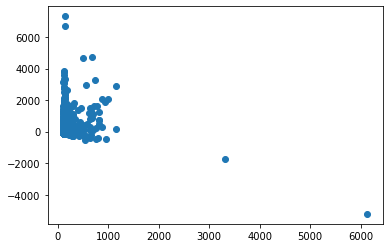

0.06658329827796289
ENVI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.721657 0.172347 -56.408 0.000000
## 1.881889 0.332024 5.668 0.000000
## 19635.777077 346.387137 56.687 0.000000
## ---
## Mean squared error: 90294.024449 , RMSE: 300.489641
## Multiple R-squared: 0.072865 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

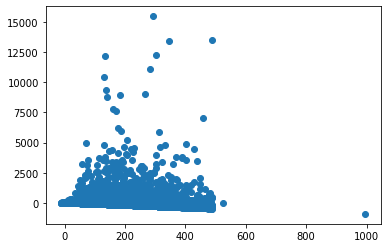

0.18423084411153862
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.621313 0.040537 15.327 0.000000
## 1.830397 0.091453 20.015 0.000000
## -1226.392086 81.284418 -15.088 0.000000
## ---
## Mean squared error: 2813.267270 , RMSE: 53.040242
## Multiple R-squared: 0.029671 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

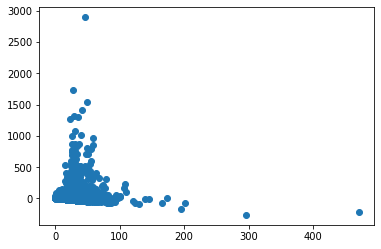

0.21227777187260788
DECI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -28.963428 1.611971 -17.968 0.000000
## 8.704879 7.211205 1.207 0.227432
## 58431.532409 3234.197729 18.067 0.000000
## ---
## Mean squared error: 1232808.479323 , RMSE: 1110.319089
## Multiple R-squared: 0.056327 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

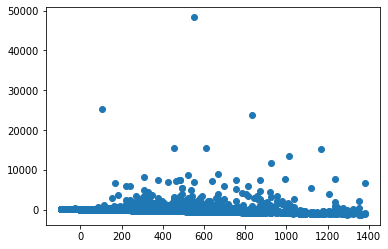

0.26488272543332414
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.194397 0.404818 2.950 0.003191
## 2.746517 1.729761 1.588 0.112409
## -2365.362146 811.116947 -2.916 0.003563
## ---
## Mean squared error: 48270.186950 , RMSE: 219.704772
## Multiple R-squared: 0.003413 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

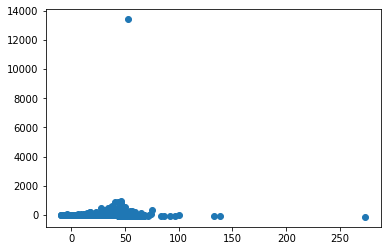

0.2134994265127999
AGRI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.311095 0.241816 -38.505 0.000000
## 2.129656 0.472897 4.503 0.000007
## 18798.040080 485.518631 38.717 0.000000
## ---
## Mean squared error: 269684.882999 , RMSE: 519.311932
## Multiple R-squared: 0.025188 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

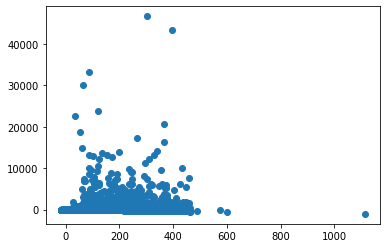

0.22720343995617207
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.432290 0.104668 4.130 0.000036
## 1.460313 0.223802 6.525 0.000000
## -847.474720 209.762759 -4.040 0.000054
## ---
## Mean squared error: 31361.179237 , RMSE: 177.090878
## Multiple R-squared: 0.001866 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

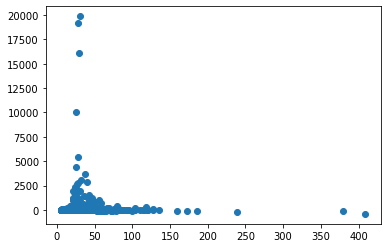

0.25878914288788435
ENER

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.856239 0.173561 -39.503 0.000000
## 2.055642 0.462748 4.442 0.000009
## 13863.950338 348.917951 39.734 0.000000
## ---
## Mean squared error: 29314.398422 , RMSE: 171.214481
## Multiple R-squared: 0.080093 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

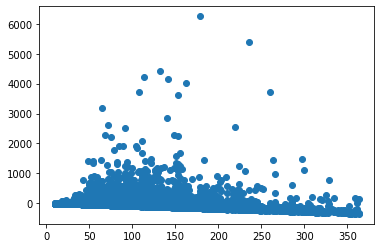

0.2300694094235327
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.140967 0.084214 13.548 0.000000
## 2.056961 0.223382 9.208 0.000000
## -2266.364044 168.998679 -13.411 0.000000
## ---
## Mean squared error: 4002.873072 , RMSE: 63.268263
## Multiple R-squared: 0.030217 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

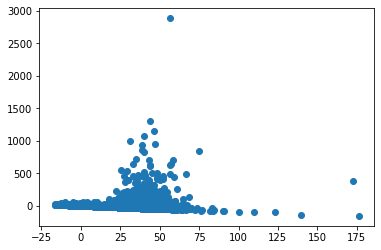

0.2154514680920069
NURS

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.586486 0.360336 -23.829 0.000000
## 3.466988 0.558504 6.208 0.000000
## 17329.981300 724.133679 23.932 0.000000
## ---
## Mean squared error: 70695.167264 , RMSE: 265.885628
## Multiple R-squared: 0.066061 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

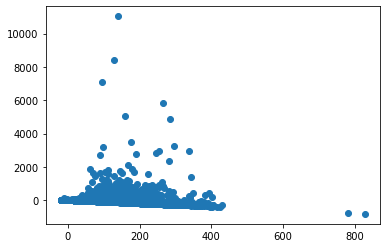

0.13619135188391757
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.146350 0.118337 1.237 0.216240
## 2.167127 0.180629 11.998 0.000000
## -276.402051 237.416472 -1.164 0.244388
## ---
## Mean squared error: 4472.629295 , RMSE: 66.877719
## Multiple R-squared: 0.025626 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

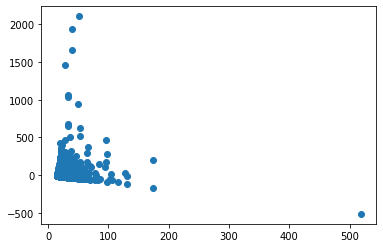

0.14702558130150528
CENG

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.302928 0.226046 -50.003 0.000000
## 9.977165 0.671564 14.857 0.000000
## 22797.459601 453.782388 50.239 0.000000
## ---
## Mean squared error: 117629.844467 , RMSE: 342.972075
## Multiple R-squared: 0.061963 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

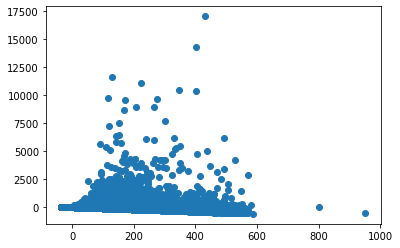

0.2814638195126814
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.521629 0.076637 6.806 0.000000
## 5.724114 0.221952 25.790 0.000000
## -1028.184299 153.621961 -6.693 0.000000
## ---
## Mean squared error: 8349.577593 , RMSE: 91.376023
## Multiple R-squared: 0.032583 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

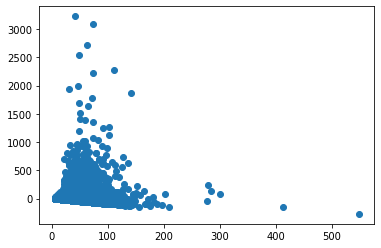

0.27527090789192027
SOCI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.436318 0.330253 -40.685 0.000000
## 4.398327 1.223603 3.595 0.000325
## 27111.662989 663.240995 40.878 0.000000
## ---
## Mean squared error: 327777.592429 , RMSE: 572.518639
## Multiple R-squared: 0.045972 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

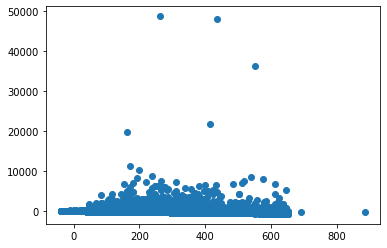

0.18378364958569066
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.348755 0.034656 10.063 0.000000
## 2.070422 0.122500 16.901 0.000000
## -683.601502 69.479593 -9.839 0.000000
## ---
## Mean squared error: 2146.480150 , RMSE: 46.330121
## Multiple R-squared: 0.018237 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

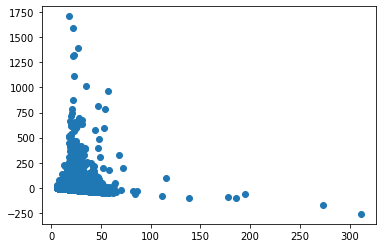

0.14016602723828697
EART

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.721537 0.246355 -47.580 0.000000
## 3.071164 0.202345 15.178 0.000000
## 23656.863391 494.898356 47.801 0.000000
## ---
## Mean squared error: 178166.139113 , RMSE: 422.097310
## Multiple R-squared: 0.068757 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

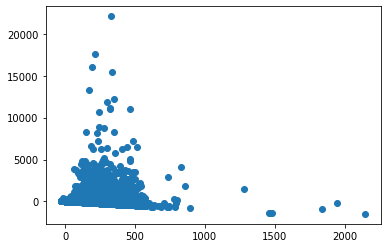

0.11302651373417195
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.329734 0.073848 4.465 0.000008
## 3.013865 0.052976 56.891 0.000000
## -644.193474 148.087725 -4.350 0.000014
## ---
## Mean squared error: 9855.259652 , RMSE: 99.273660
## Multiple R-squared: 0.126820 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

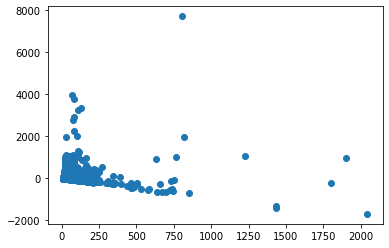

0.11996003513357771
CHEM

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.129007 0.245013 -49.504 0.000000
## 0.137659 0.182403 0.755 0.450433
## 24508.816862 492.583285 49.756 0.000000
## ---
## Mean squared error: 348725.132844 , RMSE: 590.529536
## Multiple R-squared: 0.030806 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

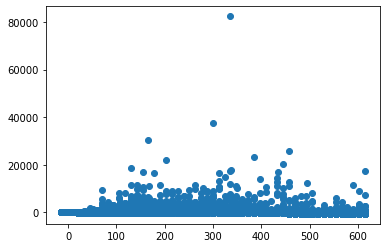

0.07188325931046603
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.849634 0.047008 18.074 0.000000
## 0.099479 0.028594 3.479 0.000504
## -1663.972287 94.363174 -17.634 0.000000
## ---
## Mean squared error: 8333.019413 , RMSE: 91.285373
## Multiple R-squared: 0.006186 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

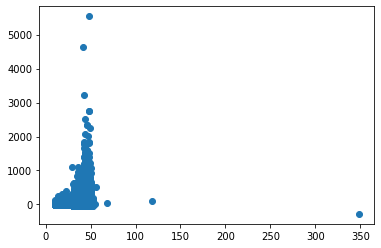

0.057327396254247806
DENT

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -3.934070 0.232090 -16.951 0.000000
## -0.187823 0.920246 -0.204 0.838288
## 7960.259568 464.820194 17.125 0.000000
## ---
## Mean squared error: 15586.304247 , RMSE: 124.845121
## Multiple R-squared: 0.092475 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

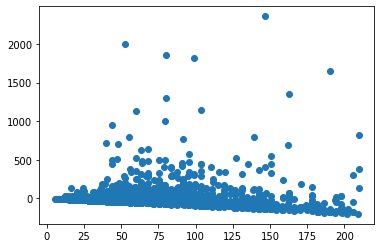

0.31651618995854436
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.327608 0.054862 5.972 0.000000
## 0.594383 0.207757 2.861 0.004260
## -644.371374 109.738401 -5.872 0.000000
## ---
## Mean squared error: 580.005568 , RMSE: 24.083305
## Multiple R-squared: 0.024171 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

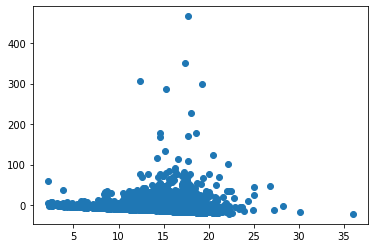

0.30228319060517067
BUSI

-------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -22.039620 0.658074 -33.491 0.000000
## 2.485702 2.448685 1.015 0.310068
## 44478.386744 1321.551603 33.656 0.000000
## ---
## Mean squared error: 493689.272457 , RMSE: 702.630253
## Multiple R-squared: 0.076224 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

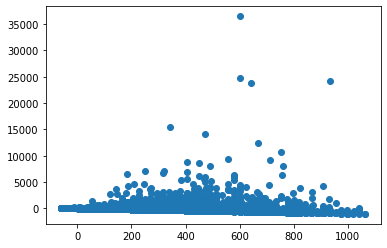

0.16980354164698194
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.605519 0.058768 10.303 0.000000
## 1.056912 0.251365 4.205 0.000026
## -1189.906264 117.786926 -10.102 0.000000
## ---
## Mean squared error: 2120.789085 , RMSE: 46.052026
## Multiple R-squared: 0.014287 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

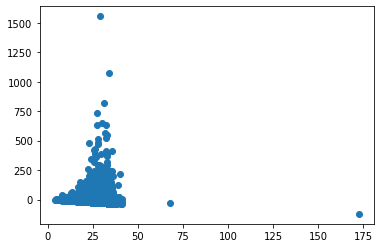

0.1431728913066087

In [0]:
for AREA in descriptives_output_df.subjareas.unique():
  if AREA == 'undefined': continue
  print(AREA)
  print("\n-------\n")
  temp_df = df_hyp1.select("subjareas", "team_size", "Year", "CitationCount", "Citations_5y")\
    .filter(df_hyp1.subjareas == AREA)
  
  vectorAssembler = VectorAssembler(inputCols = ['Year', 'team_size'], outputCol = "pub_year")
  temp_df = vectorAssembler.setHandleInvalid("skip").transform(temp_df)
  lr = LinearRegression(featuresCol = 'pub_year', labelCol='CitationCount')
  lr_model = lr.fit(temp_df)
  model_output_df = modelsummary(lr_model, ("hyp1b_CitationCount_"+AREA), model_output_df)
  
  # data screening
  if permissions == "default":
    residuals = lr_model.summary.residuals.select('residuals').collect()
    predictions = lr_model.summary.predictions.select('prediction').collect()
    plt.scatter(predictions, residuals)
    plt.show()
    print(temp_df.stat.corr("Year", "team_size"))
  
  lr = LinearRegression(featuresCol = 'pub_year', labelCol='Citations_5y')
  lr_model = lr.fit(temp_df.filter(temp_df.Year < 2017).where(col("Citations_5y").isNotNull()))
  model_output_df = modelsummary(lr_model, ("hyp1b_Citation5y_"+AREA), model_output_df)
  
  # data screening
  if permissions == "default":
    residuals = lr_model.summary.residuals.select('residuals').collect()
    predictions = lr_model.summary.predictions.select('prediction').collect()
    plt.scatter(predictions, residuals)
    plt.show()
    print(temp_df.filter(temp_df.Year < 2017).stat.corr("Year", "team_size"))
  
# model_output_df

# Research Question 2

What characteristics of team composition have the greatest influence on article metrics? 

Author independent variables: Author characteristics include affiliation country, affiliation/institution, h-index, gender, and gender ratio. We will transform the affiliation country into a count variable of the number of unique countries. Similarly, we will transform the affiliation/institutions into a count of the number of different affiliations across authors. We will use the h-index of the first and last authors for each article. We will use h-index with and without self-citation if this metric is available through the ICSR system. Last, Elsevier has noted that their inferred gender column has a 97% accuracy, and we will use inferred gender of the first and last authors for each article. From this variable, we will additionally calculate the gender ratio (percent male) as a single variable for each article.

In [0]:
# calculate variables, load tables
# gender
df_gender = spark.read.format("parquet").load(basePath+tablename_gender_inference)

# gender ratio
gender_summary = df_ani.select("Eid", "Au.auid")\
  .withColumn("auid", explode("auid"))\
  .join(df_gender.select("auid", "Inferred_Probable_Gender"), "auid", "left")\
  .groupBy("Eid", "Inferred_Probable_Gender")\
  .agg(count("auid").alias("author_count"))\
  .withColumn("gender_percent", col("author_count")/sum("author_count").over(Window.partitionBy("Eid")))\
  .withColumn("team_size", sum("author_count").over(Window.partitionBy("Eid")))\
  .filter(col("Inferred_Probable_Gender") == "male")\
  .drop("Inferred_Probable_Gender", "author_count")

# display(gender_summary)

In [0]:
# merge all data needed
df_hyp2 = df_ani.select("Eid", "Year", "Au.Authorseq", "Af.affiliation_country", "Af.affiliation_ids", "subjareas", "CitationCount", "Au.auid")\
  .withColumn("country_count", size(array_distinct("affiliation_country")))\
  .withColumn("inst_count", size(array_distinct("affiliation_ids")))\
  .withColumn("auth_combo", arrays_zip("Authorseq", "auid"))\
  .withColumn("auth_combo", explode("auth_combo"))\
  .select("Eid", "Year", "country_count", "inst_count", "subjareas", "CitationCount", col("auth_combo.Authorseq").alias("Authorseq"), col("auth_combo.auid").alias("auid"))\
  .join(df_gender.select("auid", "Inferred_Probable_Gender"), "auid", "left")\
  .join(df_fwci.select("Eid", "Citations_5y"), "Eid", "left")\
  .join(gender_summary, "Eid", "left")
  
# display(df_hyp2)

In [0]:
# calculate h-index for only those we need
df_authors = df_hyp2.select("Authorseq", "auid", "team_size")\
	.filter((col("Authorseq") == 1) | (col("Authorseq") == col("team_size")))

# display(df_authors)

df_hindex = df_ani.withColumn('auid', explode ('Au.auid'))\
	.select('Eid', 'auid', 'Year', 'Title', 'CitationCount')\
	.join(df_authors, "auid", "right")\
	.groupBy("auid")\
	.agg(collect_list('CitationCount').alias('CitationsList'))\
	.withColumn('CitationsList', reverse(array_sort('CitationsList')))\
	.select ('auid', posexplode('CitationsList').alias('CitationPosition', 'CitationCount'))\
	.filter(col('CitationCount') >= (col('CitationPosition') + 1))\
	.groupBy('auid')\
	.agg(max('CitationPosition').alias('HIndexMinus1'))\
	.withColumn('HIndex', col('HIndexMinus1') + 1)\
	.drop(col('HIndexMinus1'))
     
# display(df_hindex)

df_hyp2 = df_hyp2.join(df_hindex, "auid", "left")

# display(df_hyp2)

In [0]:
# no self citation h-index
df_from_corpus = (
  df_ani
  .select(col('eid').alias('from_eid'),
          col('year').alias('from_year'),
          col('Au.auid').alias('from_auids'), 
          size('Au').alias('from_n_Au'),
          col('CitationCount').alias('from_CC'), 
          'references') 
  .withColumn('references_to', explode('references'))
  .withColumnRenamed('year','from_year')
)

# metadata for everything that is cited
df_references_from_to = (
  df_from_corpus
  .join(df_ani
        # which fields to retain of the "to" publication, renaming for clarity
        .select(col('Au.auid').alias("to_auids"), col('year').alias('to_year'), col('eid'), size('Au').alias('to_n_A')),
        #join the "from" article's references to the "to" articles' IDs
        col('references_to') == df_ani['eid'], 'left')
        .withColumnRenamed('eid', 'to_eid')
        .withColumn('self_citation_tf', arrays_overlap('from_auids', 'to_auids'))
)

df_self_cc_counts = (
  df_references_from_to
  .groupBy('to_eid', 'to_auids') 
  .agg(count(lit(True)).alias('fullcitationcount'),
      sum(when(col('self_citation_tf'), lit(1)).otherwise(lit(0))).alias('selfcitationcount'),
      sum(when(col('self_citation_tf'), lit(0)).otherwise(lit(1))).alias('nonselfcitationcount'))
)

# display(df_self_cc_counts)

df_hindex = df_self_cc_counts.withColumn('auid', explode('to_auids'))\
	.groupBy("auid")\
	.agg(collect_list('nonselfcitationcount').alias('CitationsList'))\
	.withColumn('CitationsList', reverse(array_sort('CitationsList')))\
	.select ('auid', posexplode('CitationsList').alias('CitationPosition', 'nonselfcitationcount'))\
	.filter(col('nonselfcitationcount') >= (col('CitationPosition') + 1))\
	.groupBy('auid')\
	.agg(max('CitationPosition').alias('HIndexMinus1'))\
	.withColumn('HIndex_noself', col('HIndexMinus1') + 1)\
	.drop(col('HIndexMinus1'))
     
# display(df_hindex)

df_hyp2 = df_hyp2.join(df_hindex, "auid", "left")

# display(df_hyp2)


In [0]:
# create string index for Inferred Probable Gender 
indexer = StringIndexer(inputCol="Inferred_Probable_Gender", outputCol="IPG_index")
df_hyp2 = indexer.setHandleInvalid("skip").fit(df_hyp2).transform(df_hyp2)

# display(df_hyp2)

### Overall Summary 

For this research question, we will continue to use the model from the previous research question and add other article metrics to determine their contribution to the model. Our hypothesis is that each variable has an impact on the metrics variables (non-directional). Each author independent variable will be modeled separately and compared using confidence intervals as described above for which variable had the strongest impact on publication metrics. 

Using the linear model from the previous research question, we will add each author independent variable (affiliation country count, affiliation/institution count, h-index, gender, and gender ratio) in separate models to calculate their slope. We will determine if these slopes were important by examining if their confidence interval was greater than zero. We will then compare each slope to other slopes to see if their confidence intervals overlap. We have to examine the effects of each author metric separately. When examining first and/or last author information, the single author paper presents a unique problem because they are both first and last author. Therefore, these cannot be included in the same model. In order not to use the same variance twice, single author papers will be treated as first author only, and NA for last author analyses. If these were included in the same model, all single author papers would be dropped, which would bias the results.

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.305320 0.116527 -122.764 0.000000
## -0.020475 0.037552 -0.545 0.585585
## 27.703857 0.973154 28.468 0.000000
## 28857.656481 234.047880 123.298 0.000000
## ---
## Mean squared error: 579837.261299 , RMSE: 761.470460
## Multiple R-squared: 0.030681 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

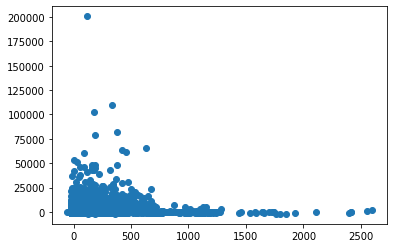

0.08866640386123412
0.5066981398172908
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.420418 0.028021 15.003 0.000000
## 0.012064 0.007689 1.569 0.116632
## 17.019130 0.223916 76.007 0.000000
## -822.722095 56.188255 -14.642 0.000000
## ---
## Mean squared error: 21499.903111 , RMSE: 146.628453
## Multiple R-squared: 0.023606 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

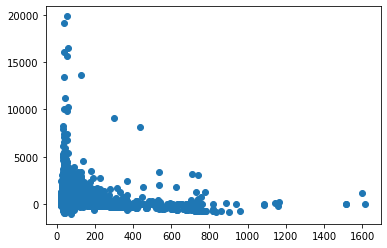

0.103533552395399
0.5331646566769939
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.361917 0.116672 -123.097 0.000000
## -0.427310 0.045770 -9.336 0.000000
## 9.361114 0.319414 29.307 0.000000
## 28989.922096 234.383932 123.686 0.000000
## ---
## Mean squared error: 579780.150999 , RMSE: 761.432959
## Multiple R-squared: 0.030777 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

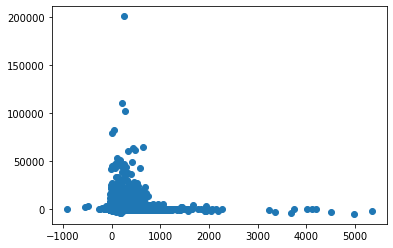

0.09188395751209943
0.7062212040137132
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.351724 0.027982 12.570 0.000000
## -0.316987 0.009698 -32.685 0.000000
## 6.688145 0.075288 88.834 0.000000
## -675.316486 56.122069 -12.033 0.000000
## ---
## Mean squared error: 21378.256584 , RMSE: 146.213052
## Multiple R-squared: 0.029131 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

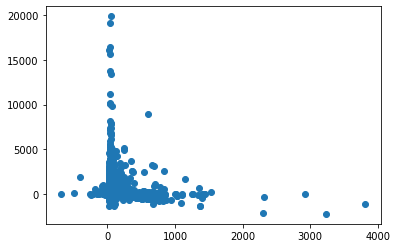

0.10327095589221483
0.7425489407213733
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.624703 0.119358 -114.150 0.000000
## 0.536327 0.032424 16.541 0.000000
## 62.614346 4.274041 14.650 0.000000
## 27491.718109 240.421726 114.348 0.000000
## ---
## Mean squared error: 580540.084473 , RMSE: 761.931811
## Multiple R-squared: 0.029507 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

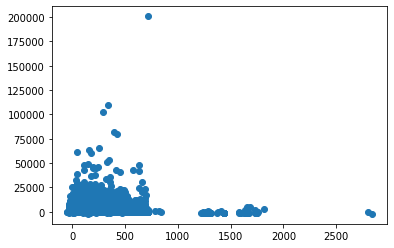

-0.23011794105148153
-0.03942984197737899
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.675402 0.028694 23.538 0.000000
## 0.324811 0.006562 49.500 0.000000
## 7.533460 0.961095 7.838 0.000000
## -1315.795945 57.685993 -22.810 0.000000
## ---
## Mean squared error: 21835.768514 , RMSE: 147.769308
## Multiple R-squared: 0.008353 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

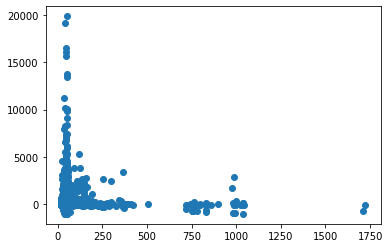

-0.20319952278712541
-0.03794767480350779
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.174316 0.125317 -105.128 0.000000
## 0.597689 0.044445 13.448 0.000000
## 3.193802 0.043258 73.832 0.000000
## 26592.917908 251.828979 105.599 0.000000
## ---
## Mean squared error: 603075.839385 , RMSE: 776.579577
## Multiple R-squared: 0.039526 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

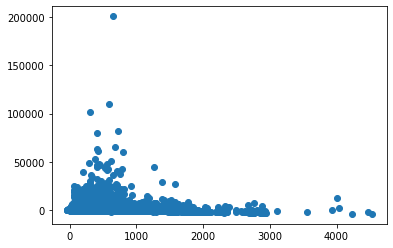

-0.12686080405758765
0.048395530999535884
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.821651 0.028849 28.481 0.000000
## 0.428038 0.008700 49.198 0.000000
## 0.674843 0.008438 79.973 0.000000
## -1612.460759 57.887968 -27.855 0.000000
## ---
## Mean squared error: 21713.103831 , RMSE: 147.353669
## Multiple R-squared: 0.026963 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

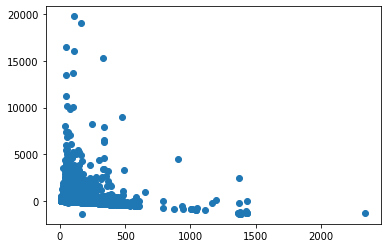

-0.08494685955418615
0.05067051840244233
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.096960 0.154913 -78.089 0.000000
## 0.481850 0.049590 9.717 0.000000
## 80.211086 0.811576 98.834 0.000000
## 24312.474404 311.232725 78.117 0.000000
## ---
## Mean squared error: 730704.031958 , RMSE: 854.812279
## Multiple R-squared: 0.047567 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

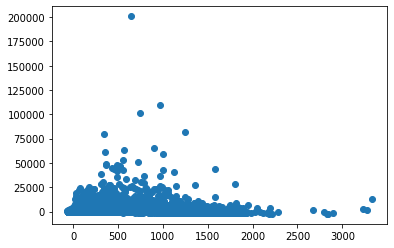

-0.14597313549433938
0.052796497890046694
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.353392 0.031257 43.299 0.000000
## 0.394480 0.008988 43.891 0.000000
## 17.996943 0.149582 120.315 0.000000
## -2705.139382 62.729292 -43.124 0.000000
## ---
## Mean squared error: 23101.070186 , RMSE: 151.990362
## Multiple R-squared: 0.053169 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

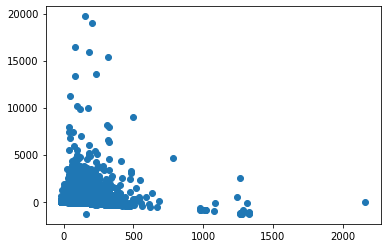

-0.10911051800754144
0.054071649758683636
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.152041 0.143736 -98.458 0.000000
## 0.714340 0.047126 15.158 0.000000
## -15.521115 1.575508 -9.851 0.000000
## 28597.283688 288.654418 99.071 0.000000
## ---
## Mean squared error: 660956.461790 , RMSE: 812.992289
## Multiple R-squared: 0.027894 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

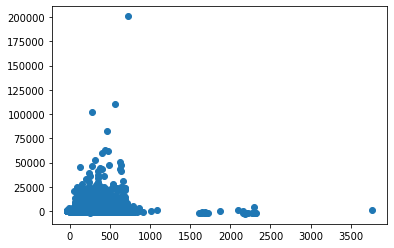

0.1280672507051982
0.018110298676720493
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.708339 0.032306 21.926 0.000000
## 0.432293 0.008835 48.929 0.000000
## -3.613686 0.334469 -10.804 0.000000
## -1375.838335 64.779760 -21.239 0.000000
## ---
## Mean squared error: 21931.810408 , RMSE: 148.093924
## Multiple R-squared: 0.010830 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

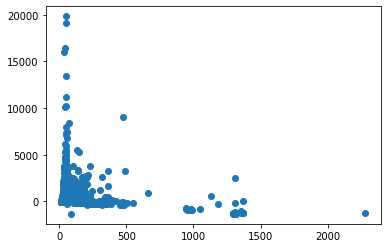

0.13598668664791186
0.01434706937131714
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.021615 0.122171 -114.771 0.000000
## 0.425618 0.033946 12.538 0.000000
## 1.280571 0.019691 65.032 0.000000
## 28296.764916 245.497495 115.263 0.000000
## ---
## Mean squared error: 589485.987194 , RMSE: 767.779908
## Multiple R-squared: 0.037431 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

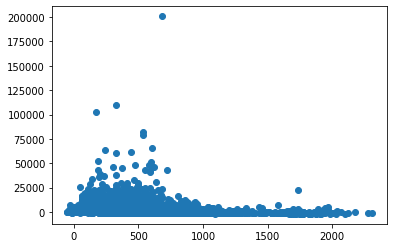

-0.0397835264702394
0.025994071643486695
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.571567 0.028764 19.871 0.000000
## 0.285834 0.006753 42.324 0.000000
## 0.392371 0.004017 97.675 0.000000
## -1112.912336 57.708830 -19.285 0.000000
## ---
## Mean squared error: 21607.602026 , RMSE: 146.995245
## Multiple R-squared: 0.032949 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

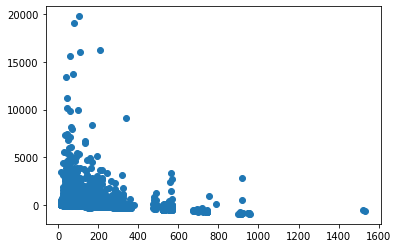

0.018591655728684486
0.02626627461488813
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.101938 0.139009 -101.446 0.000000
## 0.381948 0.036268 10.531 0.000000
## 41.573453 0.484529 85.802 0.000000
## 28378.233435 279.239900 101.627 0.000000
## ---
## Mean squared error: 665412.370006 , RMSE: 815.728123
## Multiple R-squared: 0.043157 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

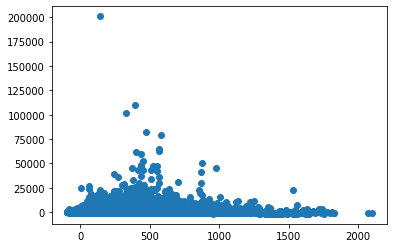

-0.03761960956202841
0.030479788299839154
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.726503 0.030298 23.979 0.000000
## 0.272166 0.006886 39.524 0.000000
## 12.178110 0.095047 128.127 0.000000
## -1446.744903 60.773480 -23.806 0.000000
## ---
## Mean squared error: 22428.007206 , RMSE: 149.759832
## Multiple R-squared: 0.054231 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

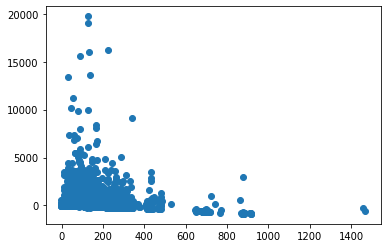

0.02100385702865358
0.030699543827305522
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.314587 0.141077 -101.466 0.000000
## 0.458730 0.039740 11.543 0.000000
## -7.668673 1.863709 -4.115 0.000039
## 28919.635119 283.373265 102.055 0.000000
## ---
## Mean squared error: 631968.490417 , RMSE: 794.964459
## Multiple R-squared: 0.028773 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

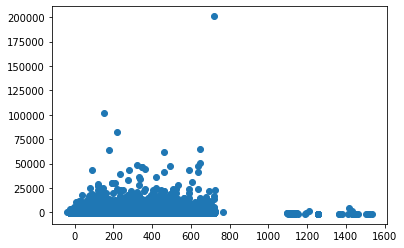

0.09398769398531158
0.009370113229593819
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.697849 0.032966 21.169 0.000000
## 0.272464 0.007732 35.238 0.000000
## -2.182137 0.418019 -5.220 0.000000
## -1355.078123 66.118532 -20.495 0.000000
## ---
## Mean squared error: 22678.315111 , RMSE: 150.593211
## Multiple R-squared: 0.006428 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

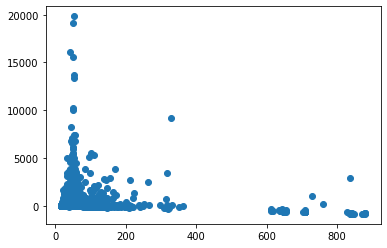

0.0848336508639653
0.007819161641820751

In [0]:
# list of IVs for unique analyses 
independent_vars = ["country_count", "inst_count", "gender_percent", 
                   "HIndex", "HIndex_noself", "IPG_index", 
                   "2HIndex", "2HIndex_noself", "2IPG_index"]

# drop all the nulls in Y
df_hyp2 = df_hyp2.where(col("CitationCount").isNotNull())

# loop over all the variables
for vars in independent_vars:
  # citations overall 
  # create dataframe, for these use unique Eids
  if (vars == "country_count") | (vars == "inst_count") | (vars == "gender_percent"):
    df_hyp2_overall = df_hyp2.dropDuplicates(['Eid'])
  elif (vars == "HIndex") | (vars == "HIndex_noself"):
    df_hyp2_overall = df_hyp2.filter((col("Authorseq") == 1))
  elif (vars == "IPG_index"):
    df_hyp2_overall = df_hyp2.filter((col("Authorseq") == 1))\
      .filter((col("Inferred_Probable_Gender") == "male") | (col("Inferred_Probable_Gender") == "female"))
  elif (vars == "2HIndex") | (vars == "2HIndex_noself"):
    df_hyp2_overall = df_hyp2.filter((col("Authorseq") == col("team_size")))
    vars = vars[1:]
  elif (vars == "2IPG_index"):
    df_hyp2_overall = df_hyp2.filter((col("Authorseq") == col("team_size")))\
      .filter((col("Inferred_Probable_Gender") == "male") | (col("Inferred_Probable_Gender") == "female"))
    vars = vars[1:]    

  # should drop nulls in X
  vectorAssembler = VectorAssembler(inputCols = ['Year', 'team_size', vars], outputCol = "pub_year")
  df_hyp2_overall = vectorAssembler.setHandleInvalid("skip").transform(df_hyp2_overall)
  
  print(vars)
  print("\n----------\n")
  
  # put in the features X and prediction Y
  lr = LinearRegression(featuresCol = 'pub_year', labelCol = 'CitationCount')
  lr_model = lr.fit(df_hyp2_overall)
  model_output_df = modelsummary(lr_model, ("hyp2_CitationCount_"+vars), model_output_df)
  
  if (permissions == "default"):
    residuals = lr_model.summary.residuals.select('residuals').collect()
    predictions = lr_model.summary.predictions.select('prediction').collect()
    
    plt.scatter(predictions, residuals)
    plt.show()
    print(df_hyp2_overall.stat.corr("Year", vars))
    print(df_hyp2_overall.stat.corr("team_size", vars))
  
  ## citations_5y
  # same DF just drop NULL citations_5y and newer articles 
  # if no citationcount then don't trust citations_5y
  df_hyp2_overall = df_hyp2_overall.where(col("Citations_5y").isNotNull())\
    .filter(col("Year") < 2017)
  
  # put in the features X and prediction Y
  lr = LinearRegression(featuresCol = 'pub_year', labelCol = 'Citations_5y')
  lr_model = lr.fit(df_hyp2_overall)
  model_output_df = modelsummary(lr_model, ("hyp2_Citation5y_"+vars), model_output_df)
  
  if (permissions == "default"):
    residuals = lr_model.summary.residuals.select('residuals').collect()
    predictions = lr_model.summary.predictions.select('prediction').collect()
    
    plt.scatter(predictions, residuals)
    plt.show()
    print(df_hyp2_overall.stat.corr("Year", vars))
    print(df_hyp2_overall.stat.corr("team_size", vars))

###Summary By Subject Area
Last, we will calculate each author independent variable separated by discipline and then visualize those slopes for each variable.

COMP

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -27.083208 0.738944 -36.651 0.000000
## 3.636958 2.986498 1.218 0.223313
## 21.319816 9.110970 2.340 0.019292
## 54630.370732 1484.005082 36.813 0.000000
## ---
## Mean squared error: 863689.215447 , RMSE: 929.348813
## Multiple R-squared: 0.058960 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

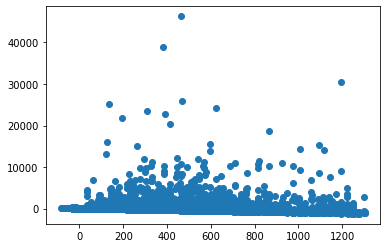

0.10498838089288298
0.3790844138062358
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.749699 0.226104 3.316 0.000916
## 3.610460 0.859943 4.198 0.000027
## 14.583490 2.782741 5.241 0.000000
## -1487.835083 453.160103 -3.283 0.001029
## ---
## Mean squared error: 44604.222290 , RMSE: 211.197117
## Multiple R-squared: 0.006884 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

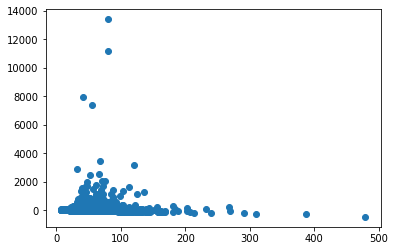

0.12271481370810851
0.3727155806599831
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -27.035231 0.738922 -36.587 0.000000
## -0.404689 3.415469 -0.118 0.905683
## 18.729597 5.635087 3.324 0.000890
## 54539.854173 1484.064048 36.750 0.000000
## ---
## Mean squared error: 863474.914400 , RMSE: 929.233509
## Multiple R-squared: 0.059193 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

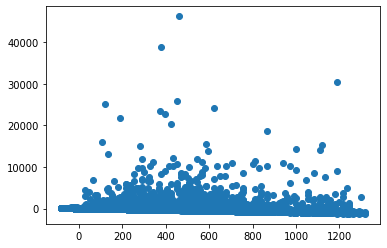

0.14374765844191703
0.5930540303608421
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.798177 0.225909 3.533 0.000412
## 2.642108 0.968812 2.727 0.006396
## 8.006966 1.681756 4.761 0.000002
## -1577.588448 452.882010 -3.483 0.000497
## ---
## Mean squared error: 44619.696171 , RMSE: 211.233748
## Multiple R-squared: 0.006540 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

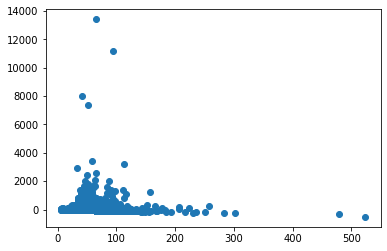

0.12831032297366549
0.5689515718486119
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -26.376946 0.756945 -34.847 0.000000
## 8.786673 2.845324 3.088 0.002017
## 101.776938 24.157633 4.213 0.000025
## 53157.780755 1524.151203 34.877 0.000000
## ---
## Mean squared error: 863217.261696 , RMSE: 929.094862
## Multiple R-squared: 0.059474 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

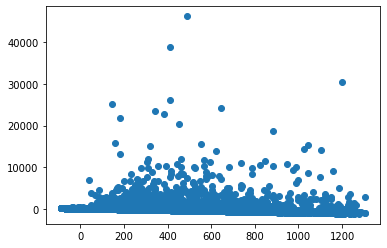

-0.273890693163452
-0.2723158517324731
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.954331 0.229367 4.161 0.000032
## 5.813405 0.818431 7.103 0.000000
## 26.771364 7.003562 3.823 0.000133
## -1903.654256 460.753678 -4.132 0.000036
## ---
## Mean squared error: 44645.706932 , RMSE: 211.295307
## Multiple R-squared: 0.005961 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

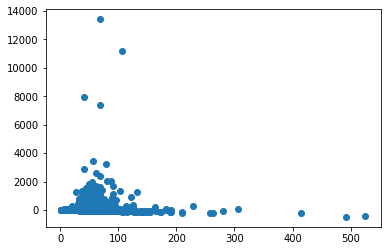

-0.21243178480948904
-0.2271073959165158
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -26.493584 0.798432 -33.182 0.000000
## 9.315309 2.597499 3.586 0.000336
## 5.903400 0.345864 17.069 0.000000
## 53426.400744 1603.920898 33.310 0.000000
## ---
## Mean squared error: 1043494.311883 , RMSE: 1021.515693
## Multiple R-squared: 0.060573 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

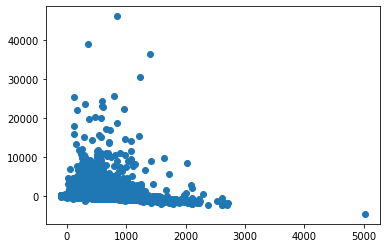

-0.15138583354848342
-0.045402648058864806
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.045903 0.228905 4.569 0.000005
## 5.476477 0.726091 7.542 0.000000
## 0.891699 0.078784 11.318 0.000000
## -2072.614482 459.060054 -4.515 0.000006
## ---
## Mean squared error: 50697.789177 , RMSE: 225.161696
## Multiple R-squared: 0.012828 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

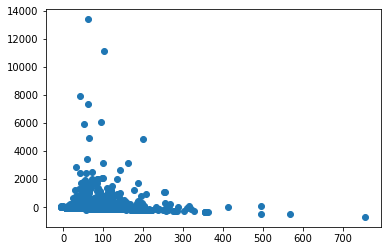

-0.0965669602403992
-0.02099465158603781
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -25.134965 1.108168 -22.682 0.000000
## 7.709081 3.577028 2.155 0.031163
## 171.624922 6.810093 25.202 0.000000
## 50488.366683 2225.422891 22.687 0.000000
## ---
## Mean squared error: 1458118.905092 , RMSE: 1207.525944
## Multiple R-squared: 0.074903 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

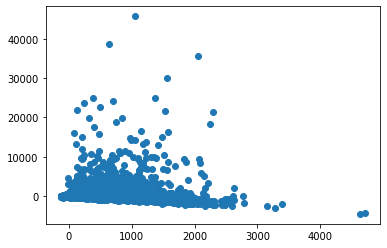

-0.1759745578819133
-0.009027664152539383
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 2.026757 0.265480 7.634 0.000000
## 5.212513 0.831920 6.266 0.000000
## 23.955710 1.419744 16.873 0.000000
## -4065.958411 532.475445 -7.636 0.000000
## ---
## Mean squared error: 59034.324181 , RMSE: 242.969801
## Multiple R-squared: 0.027378 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

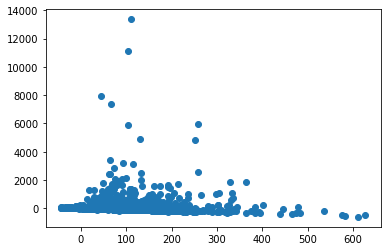

-0.1203280027521681
0.021664705764896406
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -28.283332 0.912097 -31.009 0.000000
## 9.693553 3.255393 2.978 0.002908
## -25.596922 11.756840 -2.177 0.029478
## 57082.719835 1831.499305 31.167 0.000000
## ---
## Mean squared error: 1171968.062301 , RMSE: 1082.574738
## Multiple R-squared: 0.049748 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

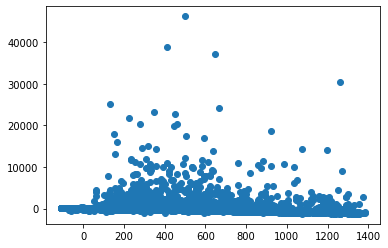

0.09604643913963062
0.10818818026093374
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.963600 0.283973 3.393 0.000693
## 7.247306 1.018234 7.118 0.000000
## -7.375654 3.665577 -2.012 0.044227
## -1900.619558 569.168606 -3.339 0.000842
## ---
## Mean squared error: 64336.979844 , RMSE: 253.647353
## Multiple R-squared: 0.006239 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

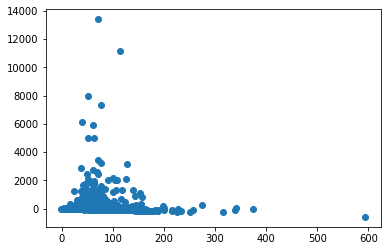

0.084445729383263
0.09377317720844938
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -27.449677 0.769288 -35.682 0.000000
## 6.660646 2.516977 2.646 0.008143
## 2.658128 0.195826 13.574 0.000000
## 55367.278340 1545.214497 35.831 0.000000
## ---
## Mean squared error: 995622.969486 , RMSE: 997.809085
## Multiple R-squared: 0.057369 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

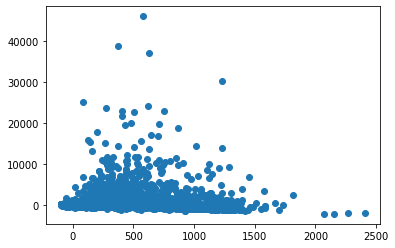

-0.048368075081488396
0.03535362082580386
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.767664 0.229749 3.341 0.000836
## 5.030544 0.736412 6.831 0.000000
## 0.605360 0.051189 11.826 0.000000
## -1513.512630 460.682261 -3.285 0.001021
## ---
## Mean squared error: 50820.814913 , RMSE: 225.434724
## Multiple R-squared: 0.013355 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

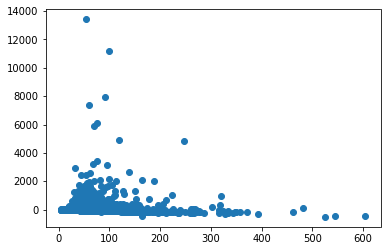

0.011953461626411071
0.052873796120989816
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -28.019994 0.970079 -28.884 0.000000
## 4.162216 3.168856 1.313 0.189038
## 98.783968 4.298828 22.979 0.000000
## 56376.681219 1947.622642 28.946 0.000000
## ---
## Mean squared error: 1270493.149016 , RMSE: 1127.161545
## Multiple R-squared: 0.071188 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

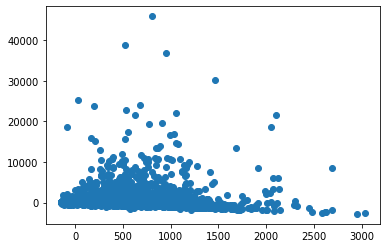

-0.05857018903178301
0.056412447552364624
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.307845 0.258441 5.061 0.000000
## 4.563990 0.820367 5.563 0.000000
## 17.845930 1.003424 17.785 0.000000
## -2618.967708 518.120634 -5.055 0.000000
## ---
## Mean squared error: 57328.710880 , RMSE: 239.434147
## Multiple R-squared: 0.027905 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

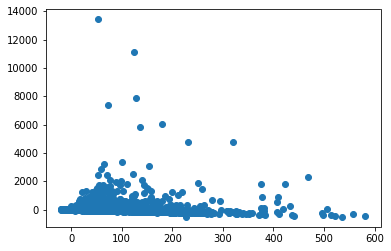

0.0029055792380082357
0.07909559404295123
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -28.531834 0.905136 -31.522 0.000000
## 11.413334 3.142714 3.632 0.000282
## -22.618998 13.124140 -1.723 0.084821
## 57575.100194 1817.759554 31.674 0.000000
## ---
## Mean squared error: 1141126.200182 , RMSE: 1068.235087
## Multiple R-squared: 0.050971 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

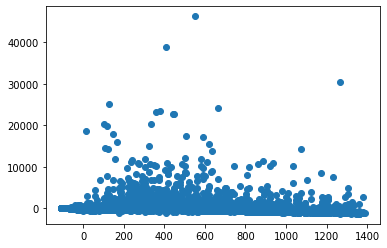

0.07477374600117809
0.11109219753235373
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.756555 0.244859 3.090 0.002008
## 6.242362 0.835392 7.472 0.000000
## -7.111945 3.538922 -2.010 0.044492
## -1484.200881 490.844254 -3.024 0.002502
## ---
## Mean squared error: 47186.743333 , RMSE: 217.225098
## Multiple R-squared: 0.006495 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

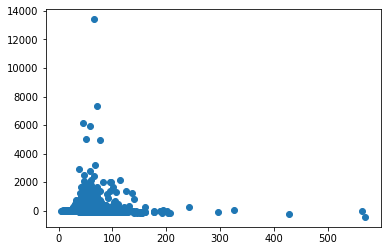

0.06706881489467256
0.10713450041779374
IMMU

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.066920 0.337221 -26.887 0.000000
## 2.193016 0.503691 4.354 0.000013
## 6.336578 2.815013 2.251 0.024405
## 18302.767911 676.845590 27.041 0.000000
## ---
## Mean squared error: 122049.533086 , RMSE: 349.355883
## Multiple R-squared: 0.061656 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

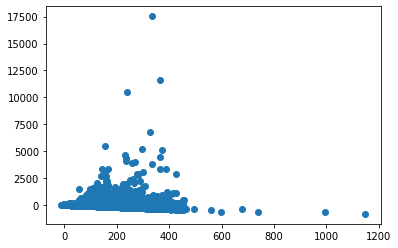

0.11279192326394315
0.5769004919578556
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.320732 0.082253 -3.899 0.000097
## 1.026939 0.138937 7.391 0.000000
## 2.930757 0.674023 4.348 0.000014
## 674.422893 164.796498 4.092 0.000043
## ---
## Mean squared error: 4772.920015 , RMSE: 69.086323
## Multiple R-squared: 0.019071 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

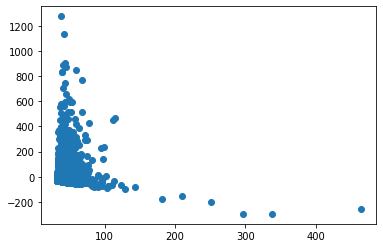

0.12294126268563162
0.5768692976141125
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.064417 0.337014 -26.896 0.000000
## 0.624491 0.718270 0.869 0.384627
## 4.499139 1.192823 3.772 0.000163
## 18305.201900 676.487509 27.059 0.000000
## ---
## Mean squared error: 121949.297549 , RMSE: 349.212396
## Multiple R-squared: 0.062427 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

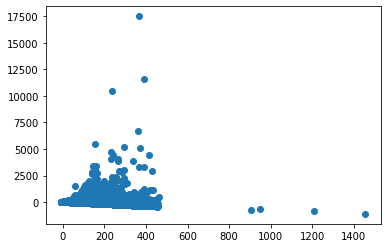

0.14042534045271307
0.8213589779025537
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.330142 0.082292 -4.012 0.000061
## 0.826529 0.166662 4.959 0.000001
## 1.274889 0.284398 4.483 0.000007
## 695.439188 164.879988 4.218 0.000025
## ---
## Mean squared error: 4772.251718 , RMSE: 69.081486
## Multiple R-squared: 0.019208 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

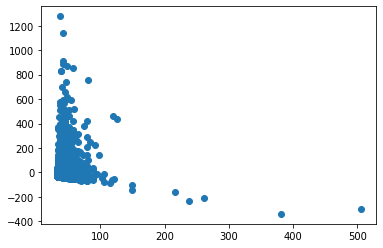

0.17040559503488598
0.7364895449842974
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.895370 0.343315 -25.910 0.000000
## 2.934423 0.415898 7.056 0.000000
## 35.291567 14.905090 2.368 0.017913
## 17945.127773 690.639954 25.983 0.000000
## ---
## Mean squared error: 122043.627197 , RMSE: 349.347430
## Multiple R-squared: 0.061702 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

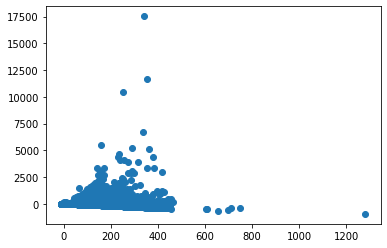

-0.20575255966833655
-0.12706564558982747
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.256149 0.083241 -3.077 0.002096
## 1.433358 0.115103 12.453 0.000000
## 16.016130 3.375338 4.745 0.000002
## 538.290414 167.077376 3.222 0.001279
## ---
## Mean squared error: 4770.891703 , RMSE: 69.071642
## Multiple R-squared: 0.019488 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

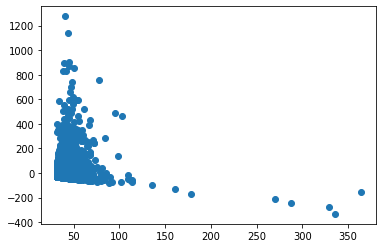

-0.18005080686621172
-0.1477705460004322
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.126439 0.348713 -29.039 0.000000
## 3.657085 0.466278 7.843 0.000000
## 1.620636 0.136013 11.915 0.000000
## 20429.383866 700.027629 29.184 0.000000
## ---
## Mean squared error: 224300.994624 , RMSE: 473.604260
## Multiple R-squared: 0.046618 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

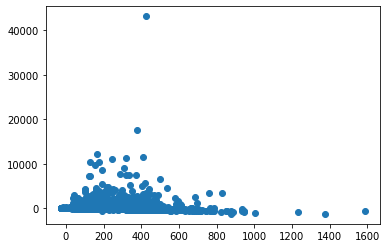

-0.16779543857134538
0.003950079352206692
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.024583 0.068816 -0.357 0.720926
## 2.128309 0.098834 21.534 0.000000
## 0.349909 0.022839 15.321 0.000000
## 74.169074 137.936534 0.538 0.590788
## ---
## Mean squared error: 5998.736348 , RMSE: 77.451510
## Multiple R-squared: 0.038110 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

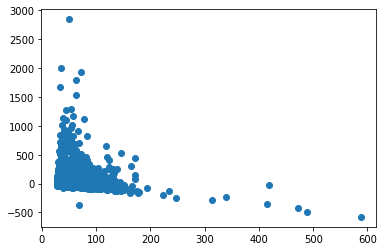

-0.1356774076602448
0.015250022354908561
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.778505 0.430933 -20.371 0.000000
## 3.273344 0.548294 5.970 0.000000
## 50.648831 2.376287 21.314 0.000000
## 17650.979788 865.088752 20.404 0.000000
## ---
## Mean squared error: 267101.924539 , RMSE: 516.819044
## Multiple R-squared: 0.054484 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

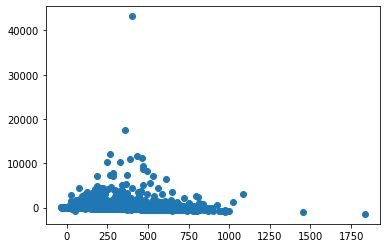

-0.19755438617336626
0.0401134025798148
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.472016 0.073916 6.386 0.000000
## 2.019134 0.107760 18.737 0.000000
## 11.834632 0.371596 31.848 0.000000
## -938.660021 148.209027 -6.333 0.000000
## ---
## Mean squared error: 6167.499745 , RMSE: 78.533431
## Multiple R-squared: 0.083428 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

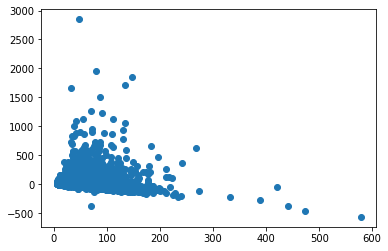

-0.16547306479881996
0.06371098186913624
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.982080 0.403404 -27.224 0.000000
## 5.779389 0.662458 8.724 0.000000
## -12.889859 3.827234 -3.368 0.000759
## 22158.630213 808.957205 27.392 0.000000
## ---
## Mean squared error: 244482.871488 , RMSE: 494.452092
## Multiple R-squared: 0.041661 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

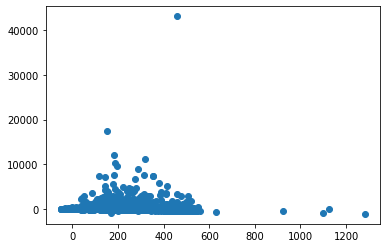

0.13897702341519677
0.07917379822105416
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.091136 0.075487 -1.207 0.227331
## 2.673969 0.116313 22.989 0.000000
## -3.843543 0.663596 -5.792 0.000000
## 210.901994 151.176354 1.395 0.163015
## ---
## Mean squared error: 5699.321228 , RMSE: 75.493849
## Multiple R-squared: 0.037667 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

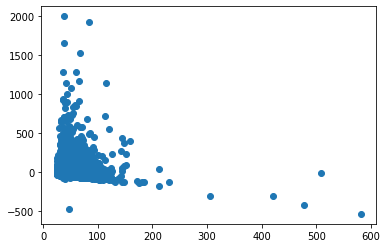

0.14870874054984234
0.07220722544417046
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.108447 0.343122 -29.460 0.000000
## 3.431006 0.456226 7.520 0.000000
## 1.152801 0.065369 17.635 0.000000
## 20378.599761 688.864007 29.583 0.000000
## ---
## Mean squared error: 224173.299485 , RMSE: 473.469428
## Multiple R-squared: 0.053127 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

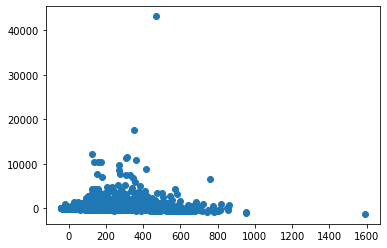

-0.11042425476413174
0.02933297016553154
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.066636 0.066489 -1.002 0.316254
## 1.971367 0.092609 21.287 0.000000
## 0.361310 0.010807 33.432 0.000000
## 152.198993 133.265061 1.142 0.253437
## ---
## Mean squared error: 5662.821444 , RMSE: 75.251721
## Multiple R-squared: 0.082071 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

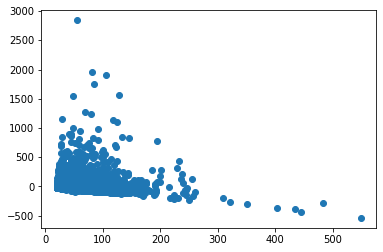

-0.04087358930097501
0.04528436896035423
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.779703 0.380251 -25.719 0.000000
## 2.946810 0.491722 5.993 0.000000
## 31.620679 1.383199 22.861 0.000000
## 19661.798613 763.387450 25.756 0.000000
## ---
## Mean squared error: 244897.688701 , RMSE: 494.871386
## Multiple R-squared: 0.059679 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

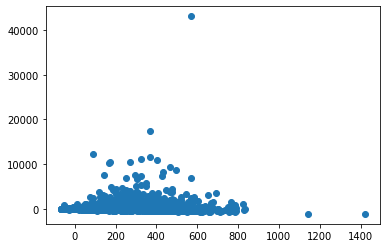

-0.10718000877248447
0.0673486715253427
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.105313 0.067917 1.551 0.121012
## 1.717976 0.093983 18.280 0.000000
## 9.913145 0.220848 44.887 0.000000
## -210.183453 136.134226 -1.544 0.122620
## ---
## Mean squared error: 5597.542051 , RMSE: 74.816723
## Multiple R-squared: 0.126173 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

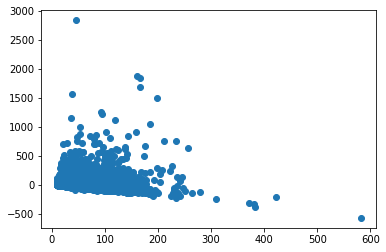

-0.03734277746095522
0.09188712947731897
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.382412 0.401305 -25.872 0.000000
## 3.027308 0.504652 5.999 0.000000
## -8.254663 4.603131 -1.793 0.072946
## 20966.683988 805.290001 26.036 0.000000
## ---
## Mean squared error: 237393.437090 , RMSE: 487.230374
## Multiple R-squared: 0.037295 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

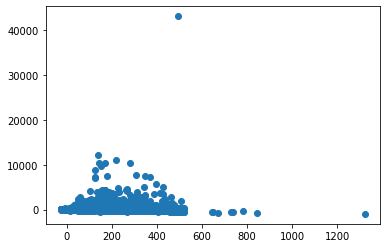

0.12311850868228782
0.05151815639840109
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.024243 0.078840 0.307 0.758471
## 1.846234 0.104636 17.644 0.000000
## -2.372225 0.856709 -2.769 0.005630
## -17.179303 157.977729 -0.109 0.913406
## ---
## Mean squared error: 6047.546190 , RMSE: 77.765971
## Multiple R-squared: 0.022806 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

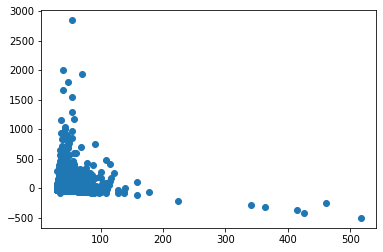

0.10470920716844664
0.05563046843477809
MATE

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.181070 1.024439 -10.914 0.000000
## -0.660319 3.006989 -0.220 0.826191
## 34.383746 11.267541 3.052 0.002282
## 22544.486531 2057.028312 10.960 0.000000
## ---
## Mean squared error: 643513.313926 , RMSE: 802.192816
## Multiple R-squared: 0.013192 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

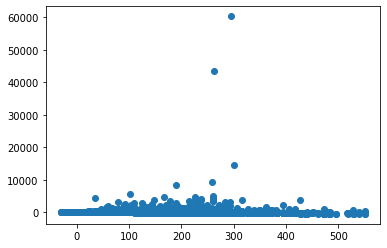

0.07752197502566885
0.35141623278884565
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.698435 0.165480 4.221 0.000025
## 2.739206 0.481755 5.686 0.000000
## 5.119337 1.773578 2.886 0.003909
## -1385.619455 331.678551 -4.178 0.000030
## ---
## Mean squared error: 9820.711085 , RMSE: 99.099501
## Multiple R-squared: 0.015285 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

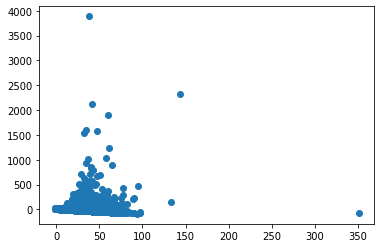

0.12090557370451031
0.3851546119033891
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.348589 1.024171 -11.081 0.000000
## -3.698542 3.405464 -1.086 0.277478
## 21.708475 6.669231 3.255 0.001138
## 22897.866450 2056.024709 11.137 0.000000
## ---
## Mean squared error: 643432.680521 , RMSE: 802.142556
## Multiple R-squared: 0.013315 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

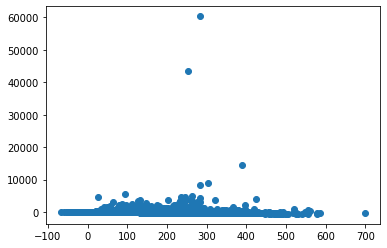

0.18959982476115034
0.5809845631852006
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.693350 0.165628 4.186 0.000029
## 2.604500 0.547321 4.759 0.000002
## 2.197720 1.067545 2.059 0.039565
## -1372.095262 331.971589 -4.133 0.000036
## ---
## Mean squared error: 9826.728947 , RMSE: 99.129859
## Multiple R-squared: 0.014682 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

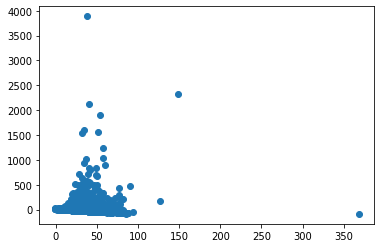

0.19357954528594254
0.5952441062299679
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.009077 1.040511 -10.580 0.000000
## 3.619309 2.925867 1.237 0.216114
## 46.288517 31.873603 1.452 0.146462
## 22199.906551 2093.040285 10.607 0.000000
## ---
## Mean squared error: 643966.370676 , RMSE: 802.475153
## Multiple R-squared: 0.012497 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

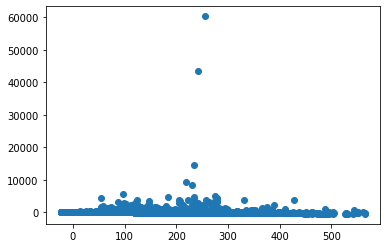

-0.25316741733317827
-0.3174101152400605
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.779209 0.166872 4.669 0.000003
## 3.625148 0.461616 7.853 0.000000
## 16.038216 4.830027 3.321 0.000903
## -1554.300889 334.974528 -4.640 0.000004
## ---
## Mean squared error: 9816.754176 , RMSE: 99.079535
## Multiple R-squared: 0.015682 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

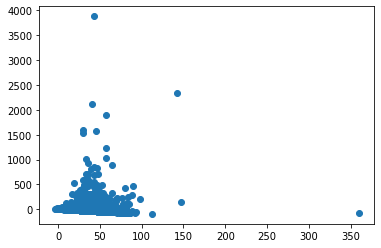

-0.19955639655262747
-0.2843653824493569
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.567662 0.301409 -31.743 0.000000
## 6.999445 0.822862 8.506 0.000000
## 2.364773 0.093636 25.255 0.000000
## 19294.190775 605.191544 31.881 0.000000
## ---
## Mean squared error: 256943.899570 , RMSE: 506.896340
## Multiple R-squared: 0.035388 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

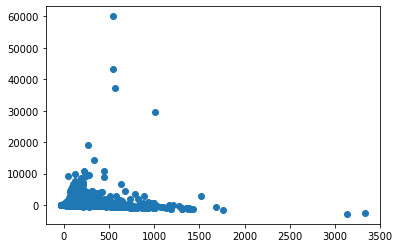

-0.12330623784317069
-0.053391258810495903
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.869765 0.077603 11.208 0.000000
## 5.399204 0.213978 25.233 0.000000
## 0.376939 0.019490 19.340 0.000000
## -1734.213712 155.562176 -11.148 0.000000
## ---
## Mean squared error: 10437.032009 , RMSE: 102.161793
## Multiple R-squared: 0.036318 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

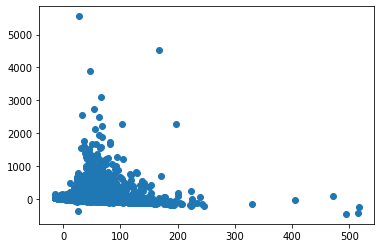

-0.06715298774082576
-0.037978275594787204
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.332503 0.385865 -21.594 0.000000
## 6.967164 1.044477 6.670 0.000000
## 64.781761 1.838823 35.230 0.000000
## 16723.124247 774.453442 21.593 0.000000
## ---
## Mean squared error: 324949.764167 , RMSE: 570.043651
## Multiple R-squared: 0.047063 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

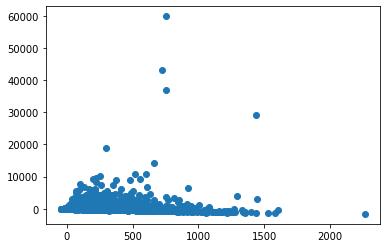

-0.12409326555552393
-0.012256236820919383
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.342351 0.083626 16.052 0.000000
## 5.288954 0.229512 23.044 0.000000
## 13.832396 0.354265 39.045 0.000000
## -2702.360876 167.634142 -16.121 0.000000
## ---
## Mean squared error: 10983.288013 , RMSE: 104.801183
## Multiple R-squared: 0.075351 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

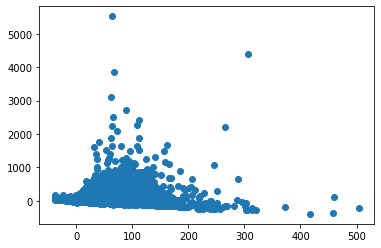

-0.06658599388908584
0.00981903031409846
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.112467 0.376073 -26.890 0.000000
## 6.575130 1.093732 6.012 0.000000
## -9.056999 3.992190 -2.269 0.023294
## 20415.377253 754.899360 27.044 0.000000
## ---
## Mean squared error: 308783.445115 , RMSE: 555.682864
## Multiple R-squared: 0.021394 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

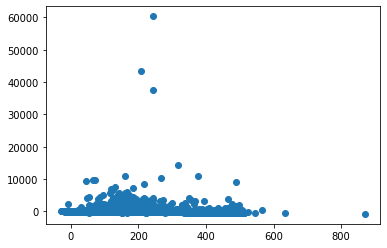

0.09449459839411767
0.11099391450636827
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.769008 0.084244 9.128 0.000000
## 5.176741 0.247049 20.954 0.000000
## -4.776055 0.853306 -5.597 0.000000
## -1525.941240 168.814047 -9.039 0.000000
## ---
## Mean squared error: 9280.977377 , RMSE: 96.337829
## Multiple R-squared: 0.027858 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

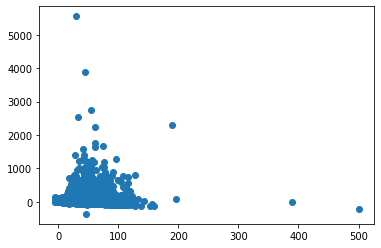

0.09686634002506317
0.11370027842851393
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.184945 0.293965 -34.647 0.000000
## 5.303047 0.810890 6.540 0.000000
## 0.692894 0.026467 26.179 0.000000
## 20542.134512 590.199506 34.805 0.000000
## ---
## Mean squared error: 252989.405900 , RMSE: 502.980522
## Multiple R-squared: 0.036943 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

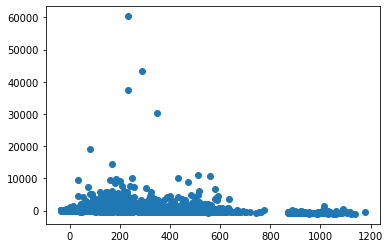

-0.025349599892196897
0.07724843631518494
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.698394 0.075694 9.227 0.000000
## 4.571957 0.209247 21.850 0.000000
## 0.244600 0.005804 42.141 0.000000
## -1391.500714 151.720999 -9.171 0.000000
## ---
## Mean squared error: 9973.506736 , RMSE: 99.867446
## Multiple R-squared: 0.073053 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

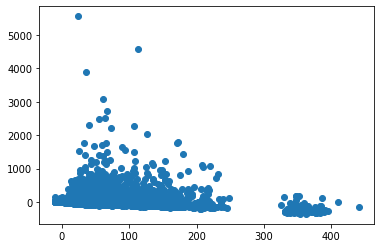

0.050997303148314466
0.09972940024556236
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.194480 0.338117 -30.151 0.000000
## 4.090410 0.935388 4.373 0.000012
## 27.447808 0.831978 32.991 0.000000
## 20511.895876 678.549875 30.229 0.000000
## ---
## Mean squared error: 288603.972456 , RMSE: 537.218738
## Multiple R-squared: 0.044598 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

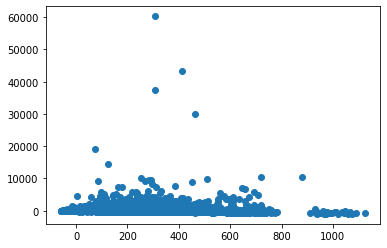

-0.005117458685013385
0.11461032687815201
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.767434 0.079184 9.692 0.000000
## 4.115758 0.220518 18.664 0.000000
## 9.344880 0.173671 53.808 0.000000
## -1547.021852 158.677361 -9.749 0.000000
## ---
## Mean squared error: 10170.124347 , RMSE: 100.847034
## Multiple R-squared: 0.106867 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

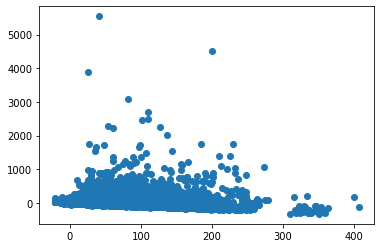

0.07735205940850137
0.13971076173755662
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.880047 0.302626 -32.648 0.000000
## 6.641860 0.861813 7.707 0.000000
## -0.856273 4.029524 -0.212 0.831718
## 19943.619358 607.480889 32.830 0.000000
## ---
## Mean squared error: 201713.138380 , RMSE: 449.124858
## Multiple R-squared: 0.030521 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

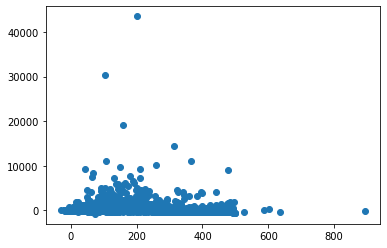

0.08823365359476501
0.06621383447409801
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.788698 0.090984 8.669 0.000000
## 5.093249 0.262070 19.435 0.000000
## -1.045320 1.192291 -0.877 0.380641
## -1565.971220 182.329125 -8.589 0.000000
## ---
## Mean squared error: 10937.789854 , RMSE: 104.583889
## Multiple R-squared: 0.024158 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

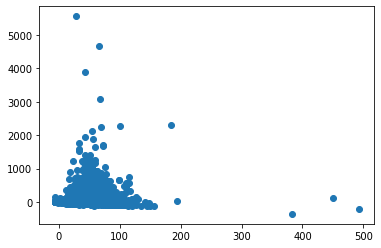

0.07583703380390099
0.05557750268474211
ARTS

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.668800 0.634925 -18.378 0.000000
## 17.393626 2.915143 5.967 0.000000
## 41.399410 11.256173 3.678 0.000237
## 23463.786879 1272.507138 18.439 0.000000
## ---
## Mean squared error: 325899.895272 , RMSE: 570.876427
## Multiple R-squared: 0.050956 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

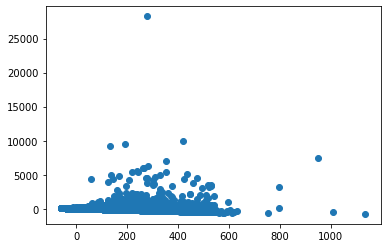

0.1392029591643515
0.4087222421821892
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.061427 0.093103 0.660 0.509427
## 6.880053 0.393978 17.463 0.000000
## 21.195504 1.667699 12.709 0.000000
## -145.378061 186.337391 -0.780 0.435315
## ---
## Mean squared error: 4737.035394 , RMSE: 68.826124
## Multiple R-squared: 0.123894 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

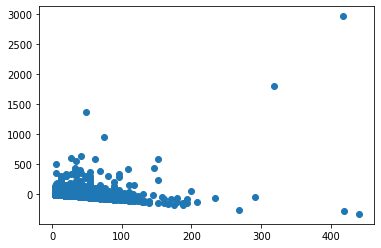

0.11674309185434716
0.3923509548784668
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.755161 0.634671 -18.522 0.000000
## 8.559272 3.768701 2.271 0.023168
## 31.544083 6.399246 4.929 0.000001
## 23656.126074 1272.567375 18.589 0.000000
## ---
## Mean squared error: 325398.366028 , RMSE: 570.436996
## Multiple R-squared: 0.052416 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

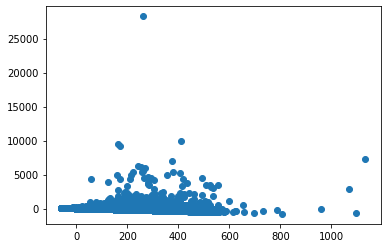

0.16270204929456336
0.7110756596323294
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.008221 0.091929 0.089 0.928742
## 2.591812 0.500225 5.181 0.000000
## 15.949353 0.895432 17.812 0.000000
## -29.219901 184.041115 -0.159 0.873857
## ---
## Mean squared error: 4608.920384 , RMSE: 67.889030
## Multiple R-squared: 0.147589 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

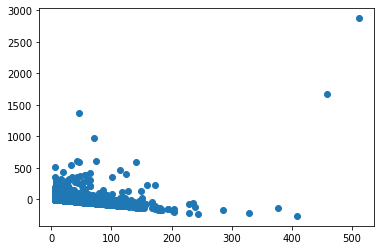

0.1546102138647492
0.7026095355282092
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.307428 0.636481 -17.766 0.000000
## 24.510543 3.026526 8.099 0.000000
## 56.034035 27.728866 2.021 0.043340
## 22730.922475 1279.486094 17.766 0.000000
## ---
## Mean squared error: 326340.879837 , RMSE: 571.262531
## Multiple R-squared: 0.049672 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

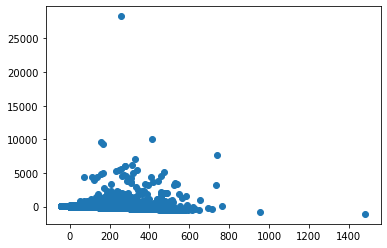

-0.16016395050244533
-0.47792360447043647
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.199374 0.094314 2.114 0.034567
## 10.019506 0.414981 24.144 0.000000
## 24.509664 3.840240 6.382 0.000000
## -422.085989 189.210909 -2.231 0.025737
## ---
## Mean squared error: 4841.420719 , RMSE: 69.580318
## Multiple R-squared: 0.104589 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

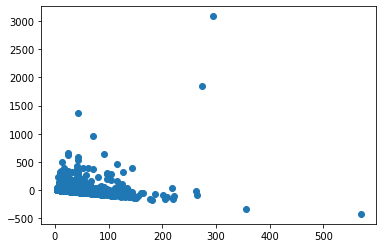

-0.14677740081892188
-0.47299948861982466
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.246661 0.652325 -15.708 0.000000
## 13.392182 2.451546 5.463 0.000000
## 4.215340 0.227176 18.555 0.000000
## 20634.571171 1308.033043 15.775 0.000000
## ---
## Mean squared error: 320527.771225 , RMSE: 566.151721
## Multiple R-squared: 0.091590 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

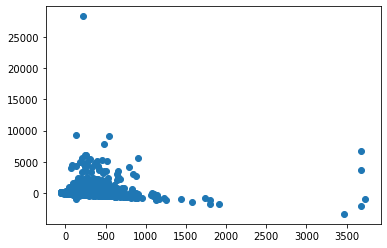

-0.08905191837349838
0.10090961038455323
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.248333 0.094077 2.640 0.008322
## 7.083842 0.335820 21.094 0.000000
## 0.318464 0.029683 10.729 0.000000
## -497.243896 188.408962 -2.639 0.008334
## ---
## Mean squared error: 4809.713361 , RMSE: 69.352097
## Multiple R-squared: 0.106828 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

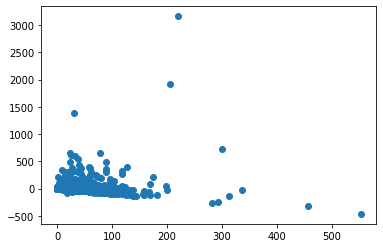

-0.06369563167041581
0.12250051437154308
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.412768 0.847885 -11.101 0.000000
## 9.206027 2.994639 3.074 0.002122
## 96.901091 5.482292 17.675 0.000000
## 18851.722232 1700.142994 11.088 0.000000
## ---
## Mean squared error: 401949.922872 , RMSE: 633.995207
## Multiple R-squared: 0.092211 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

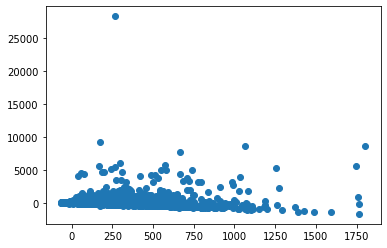

-0.14853158917508982
0.1602778517793848
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.508028 0.108892 4.665 0.000003
## 6.799510 0.376209 18.074 0.000000
## 8.122482 0.657454 12.354 0.000000
## -1026.881204 218.159540 -4.707 0.000003
## ---
## Mean squared error: 5439.186025 , RMSE: 73.750837
## Multiple R-squared: 0.117874 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

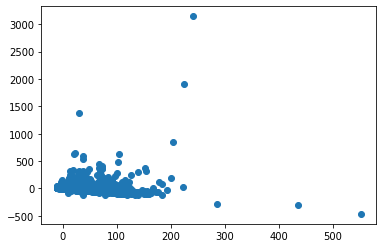

-0.1197062198201066
0.18391837843890926
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.727185 0.662355 -16.196 0.000000
## 13.498384 2.670113 5.055 0.000000
## -8.016134 9.033357 -0.887 0.374901
## 21637.880133 1328.285794 16.290 0.000000
## ---
## Mean squared error: 321257.439576 , RMSE: 566.795765
## Multiple R-squared: 0.041503 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

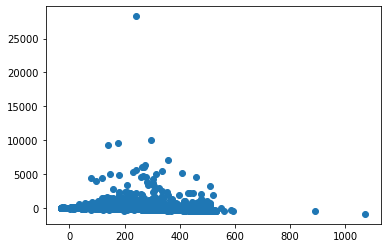

0.13786547928181622
0.22776559780544786
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.229373 0.067408 3.403 0.000672
## 4.481472 0.253897 17.651 0.000000
## -1.325056 0.876550 -1.512 0.130681
## -448.846531 134.974255 -3.325 0.000889
## ---
## Mean squared error: 2248.169689 , RMSE: 47.414868
## Multiple R-squared: 0.065693 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

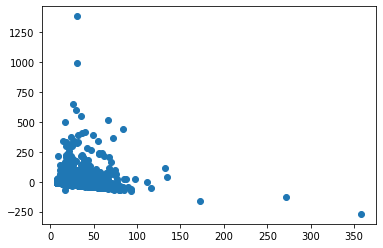

0.14350931186704774
0.22143728121897965
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.585563 0.666065 -17.394 0.000000
## 16.370630 2.522612 6.490 0.000000
## 1.009189 0.188508 5.354 0.000000
## 23340.259225 1335.569263 17.476 0.000000
## ---
## Mean squared error: 334871.545470 , RMSE: 578.680867
## Multiple R-squared: 0.050532 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

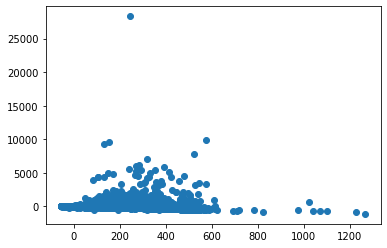

-0.025535149958901257
0.15138819830454933
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.164945 0.095427 1.728 0.083955
## 7.138785 0.340959 20.937 0.000000
## 0.130054 0.024389 5.332 0.000000
## -328.845538 191.104561 -1.721 0.085350
## ---
## Mean squared error: 4885.996867 , RMSE: 69.899906
## Multiple R-squared: 0.090942 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

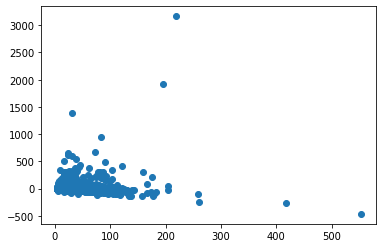

0.0033141338746038355
0.17397631410095055
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.104845 0.829525 -14.593 0.000000
## 13.638972 3.052787 4.468 0.000008
## 38.920506 4.507636 8.634 0.000000
## 24337.099496 1662.493838 14.639 0.000000
## ---
## Mean squared error: 408489.628515 , RMSE: 639.131934
## Multiple R-squared: 0.055023 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

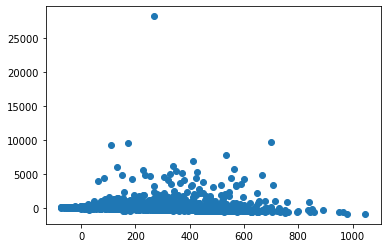

-0.023168910375746435
0.206886593594829
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.295011 0.109077 2.705 0.006863
## 7.128079 0.384203 18.553 0.000000
## 3.961847 0.553809 7.154 0.000000
## -594.065648 218.422311 -2.720 0.006556
## ---
## Mean squared error: 5517.465473 , RMSE: 74.279644
## Multiple R-squared: 0.097955 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

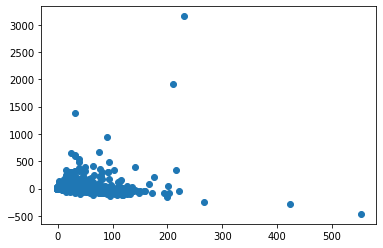

-0.006729867096967333
0.22790385584316566
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.365497 0.672324 -16.905 0.000000
## 20.482794 2.645494 7.743 0.000000
## -7.806650 10.010256 -0.780 0.435499
## 22900.571564 1348.519892 16.982 0.000000
## ---
## Mean squared error: 329658.022312 , RMSE: 574.158534
## Multiple R-squared: 0.047399 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

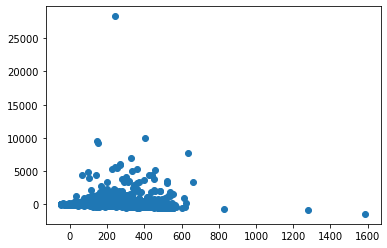

0.07656413774987417
0.19149216933156538
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.156556 0.102010 1.535 0.124916
## 8.274741 0.373632 22.147 0.000000
## -1.987774 1.459283 -1.362 0.173210
## -312.602692 204.299330 -1.530 0.126051
## ---
## Mean squared error: 5125.867706 , RMSE: 71.595165
## Multiple R-squared: 0.095016 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

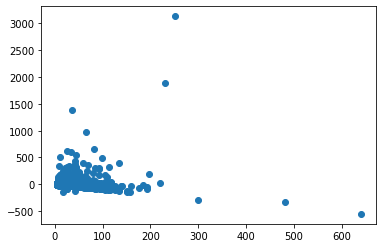

0.058344450809231355
0.1788224936693705
PHYS

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -19.693172 0.960832 -20.496 0.000000
## -0.014137 0.139811 -0.101 0.919461
## 11.671798 7.272279 1.605 0.108518
## 39721.402395 1927.709953 20.605 0.000000
## ---
## Mean squared error: 1745351.633599 , RMSE: 1321.117570
## Multiple R-squared: 0.022813 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

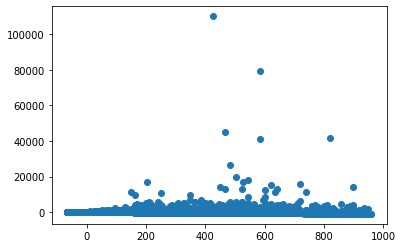

0.09422820020447216
0.8629161547914079
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.267970 0.129488 2.069 0.038520
## -0.005022 0.017631 -0.285 0.775786
## 10.685944 0.961991 11.108 0.000000
## -502.798914 259.452978 -1.938 0.052652
## ---
## Mean squared error: 22969.366365 , RMSE: 151.556479
## Multiple R-squared: 0.035329 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

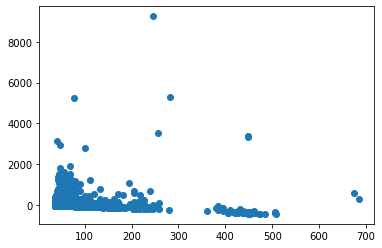

0.11136499111001151
0.8786158080020848
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -19.755244 0.959223 -20.595 0.000000
## -0.378421 0.237656 -1.592 0.111335
## 6.053013 2.461724 2.459 0.013948
## 39850.999132 1925.231818 20.699 0.000000
## ---
## Mean squared error: 1745018.022315 , RMSE: 1320.991303
## Multiple R-squared: 0.023000 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

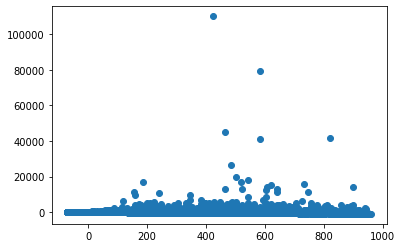

0.06943098794423763
0.9547527345747452
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.200704 0.128340 1.564 0.117876
## -0.345175 0.029496 -11.702 0.000000
## 5.677086 0.313498 18.109 0.000000
## -363.585136 257.260687 -1.413 0.157590
## ---
## Mean squared error: 22657.816912 , RMSE: 150.525137
## Multiple R-squared: 0.048413 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

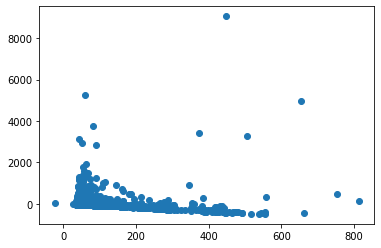

0.08728932588642856
0.9589470261977682
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -19.244007 0.966881 -19.903 0.000000
## 0.185887 0.070573 2.634 0.008447
## 66.144933 38.397401 1.723 0.084971
## 38792.490429 1945.585533 19.939 0.000000
## ---
## Mean squared error: 1745313.982248 , RMSE: 1321.103320
## Multiple R-squared: 0.022834 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

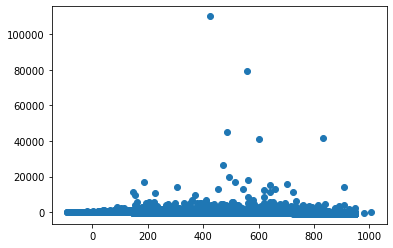

-0.16324265653018227
-0.05716477296647619
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.513672 0.130416 3.939 0.000082
## 0.168762 0.008451 19.968 0.000000
## 17.718235 4.965486 3.568 0.000360
## -991.370370 262.026525 -3.783 0.000155
## ---
## Mean squared error: 23141.516819 , RMSE: 152.123361
## Multiple R-squared: 0.028099 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

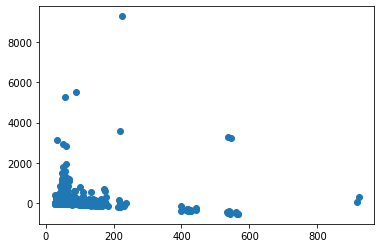

-0.1509348920091399
-0.0627442779294343
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -15.624523 0.436276 -35.813 0.000000
## 0.092420 0.061280 1.508 0.131516
## 3.456818 0.145315 23.788 0.000000
## 31512.956293 876.875551 35.938 0.000000
## ---
## Mean squared error: 962846.220003 , RMSE: 981.247278
## Multiple R-squared: 0.033442 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

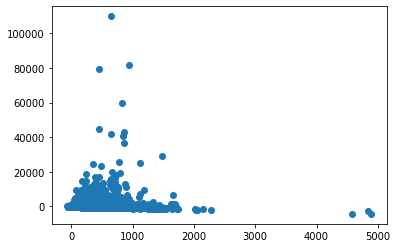

-0.10911805185069508
0.10669603510656568
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.013305 0.072481 13.980 0.000000
## 0.184673 0.008622 21.420 0.000000
## 0.530309 0.020987 25.268 0.000000
## -1994.883875 145.455895 -13.715 0.000000
## ---
## Mean squared error: 18194.789492 , RMSE: 134.888063
## Multiple R-squared: 0.030023 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

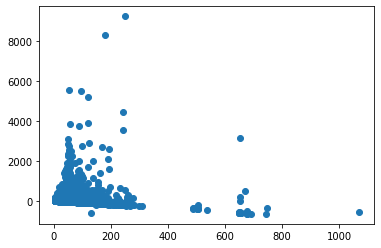

-0.06172612935295339
0.11129493689667723
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -15.645801 0.524930 -29.806 0.000000
## 0.110568 0.067717 1.633 0.102519
## 69.796665 2.431348 28.707 0.000000
## 31447.546768 1054.672673 29.817 0.000000
## ---
## Mean squared error: 1157947.658955 , RMSE: 1076.079764
## Multiple R-squared: 0.037356 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

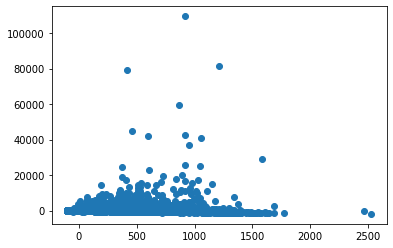

-0.10202384450774729
0.0704383618692952
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.396002 0.077552 18.001 0.000000
## 0.180123 0.008849 20.354 0.000000
## 13.247646 0.334353 39.622 0.000000
## -2782.708539 155.634057 -17.880 0.000000
## ---
## Mean squared error: 19300.165677 , RMSE: 138.925036
## Multiple R-squared: 0.054018 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

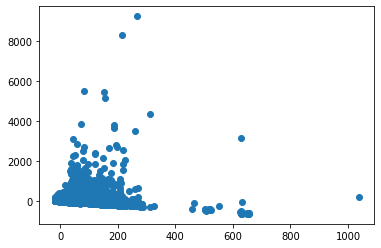

-0.06765596973437067
0.07126995735710902
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -16.517577 0.500863 -32.978 0.000000
## 0.249406 0.063701 3.915 0.000090
## -18.964390 7.013940 -2.704 0.006857
## 33353.692450 1006.030063 33.154 0.000000
## ---
## Mean squared error: 1044645.401601 , RMSE: 1022.078961
## Multiple R-squared: 0.024621 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

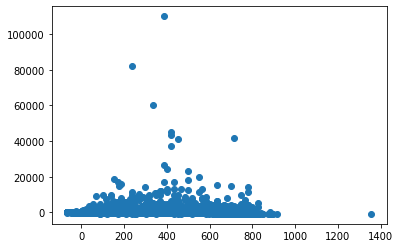

0.11886533894205083
0.006845159383911657
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.934403 0.083539 11.185 0.000000
## 0.206989 0.008923 23.196 0.000000
## -5.474765 1.145564 -4.779 0.000002
## -1828.013139 167.544883 -10.911 0.000000
## ---
## Mean squared error: 19596.834587 , RMSE: 139.988694
## Multiple R-squared: 0.019792 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

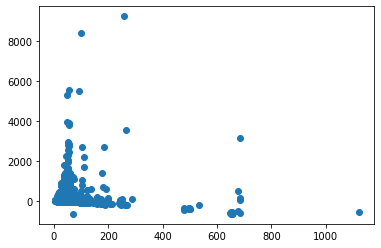

0.1180946229115965
0.002682723621437292
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -16.662979 0.428455 -38.891 0.000000
## 0.120563 0.045376 2.657 0.007887
## 1.102011 0.060881 18.101 0.000000
## 33609.908868 861.049161 39.034 0.000000
## ---
## Mean squared error: 959144.428507 , RMSE: 979.359193
## Multiple R-squared: 0.029651 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

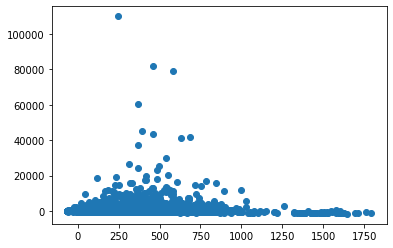

-0.012785467755275075
0.035446761450644466
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.749554 0.072020 10.408 0.000000
## 0.127373 0.006444 19.765 0.000000
## 0.334072 0.008968 37.251 0.000000
## -1468.582522 144.499509 -10.163 0.000000
## ---
## Mean squared error: 18053.444556 , RMSE: 134.363107
## Multiple R-squared: 0.041804 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

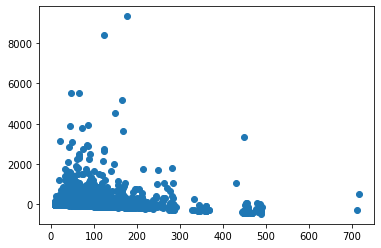

0.0484224057572719
0.036241026267740006
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -17.158046 0.480286 -35.725 0.000000
## 0.116585 0.048235 2.417 0.015650
## 39.692875 1.579623 25.128 0.000000
## 34517.517314 964.821712 35.776 0.000000
## ---
## Mean squared error: 1075923.281432 , RMSE: 1037.267218
## Multiple R-squared: 0.034277 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

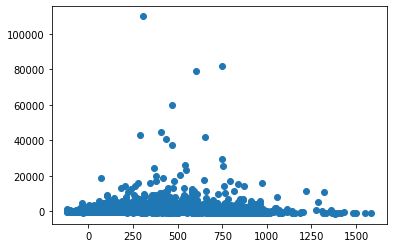

-0.0020101315840355947
0.0269001605158263
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.842850 0.075307 11.192 0.000000
## 0.126335 0.006562 19.252 0.000000
## 10.471326 0.225879 46.358 0.000000
## -1676.673785 151.048585 -11.100 0.000000
## ---
## Mean squared error: 18720.631049 , RMSE: 136.823357
## Multiple R-squared: 0.060589 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

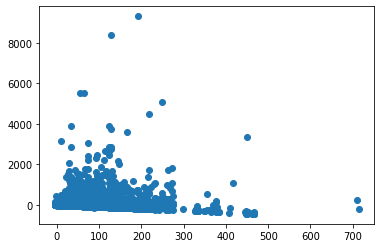

0.058363497026661014
0.027010577444128634
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -15.802006 0.395849 -39.919 0.000000
## 0.113256 0.042753 2.649 0.008075
## -2.178600 6.708723 -0.325 0.745378
## 31905.708240 795.187403 40.124 0.000000
## ---
## Mean squared error: 661408.073040 , RMSE: 813.269988
## Multiple R-squared: 0.034316 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

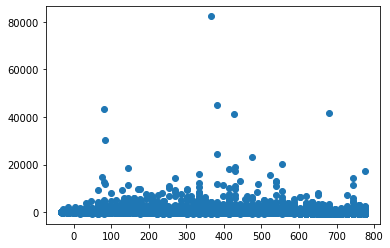

0.09593320104738931
-0.005603252611578951
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.821515 0.078489 10.467 0.000000
## 0.104119 0.007113 14.639 0.000000
## -0.583391 1.320881 -0.442 0.658732
## -1602.813060 157.431159 -10.181 0.000000
## ---
## Mean squared error: 17497.471888 , RMSE: 132.278010
## Multiple R-squared: 0.009665 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

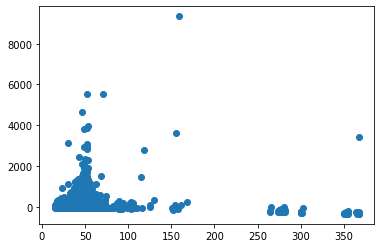

0.08642559730943736
-0.006590513508718361
PSYC

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -25.187987 1.416776 -17.778 0.000000
## -11.256602 7.151374 -1.574 0.115534
## 29.817336 16.307467 1.828 0.067536
## 50847.508743 2840.480270 17.901 0.000000
## ---
## Mean squared error: 1254715.599741 , RMSE: 1120.140884
## Multiple R-squared: 0.061261 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

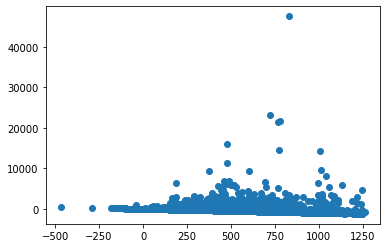

0.04518013355218863
0.7595763482899047
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.624472 0.085654 7.291 0.000000
## -1.023643 0.440523 -2.324 0.020188
## 4.322604 0.954341 4.529 0.000006
## -1221.118312 171.447287 -7.122 0.000000
## ---
## Mean squared error: 3004.288406 , RMSE: 54.811389
## Multiple R-squared: 0.017312 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

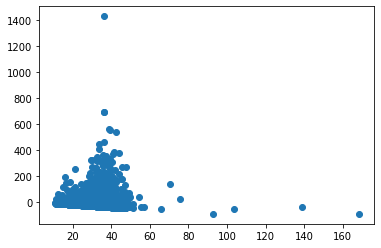

0.056821489762539076
0.7761666691839735
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -25.548157 1.394894 -18.315 0.000000
## -12.481323 8.605139 -1.450 0.146990
## 19.169823 12.392712 1.547 0.121954
## 51573.475495 2795.958996 18.446 0.000000
## ---
## Mean squared error: 1254930.997107 , RMSE: 1120.237027
## Multiple R-squared: 0.061100 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

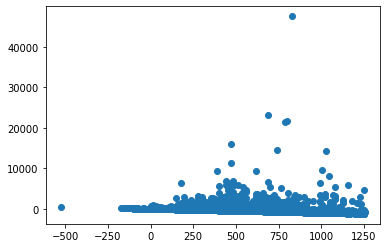

0.15361747274049678
0.8502322252762838
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.577521 0.084495 6.835 0.000000
## -2.031752 0.541315 -3.753 0.000177
## 4.107765 0.746398 5.503 0.000000
## -1126.571613 169.091036 -6.663 0.000000
## ---
## Mean squared error: 2997.531836 , RMSE: 54.749720
## Multiple R-squared: 0.019522 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

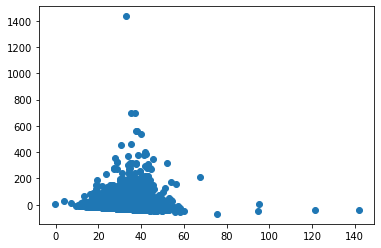

0.15777565132118548
0.8656506026835405
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -24.250459 1.430308 -16.955 0.000000
## 4.116656 4.740960 0.868 0.385259
## 248.606344 58.649443 4.239 0.000023
## 48803.660474 2876.565378 16.966 0.000000
## ---
## Mean squared error: 1251410.504782 , RMSE: 1118.664608
## Multiple R-squared: 0.063734 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

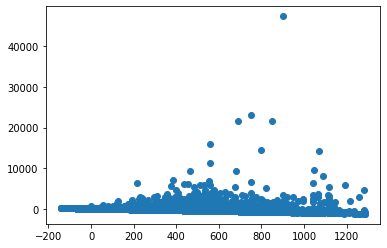

-0.2820618943881645
-0.3084792370551158
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.686386 0.086363 7.948 0.000000
## 1.045536 0.284382 3.677 0.000239
## 21.376910 3.218599 6.642 0.000000
## -1359.277259 173.341719 -7.842 0.000000
## ---
## Mean squared error: 2988.025848 , RMSE: 54.662838
## Multiple R-squared: 0.022631 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

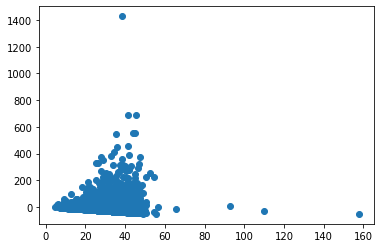

-0.2635852442601426
-0.30760411152414524
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -18.428904 0.683109 -26.978 0.000000
## -1.299895 1.749097 -0.743 0.457385
## 2.496000 0.175306 14.238 0.000000
## 37181.369745 1370.021329 27.139 0.000000
## ---
## Mean squared error: 661177.110524 , RMSE: 813.127979
## Multiple R-squared: 0.075665 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

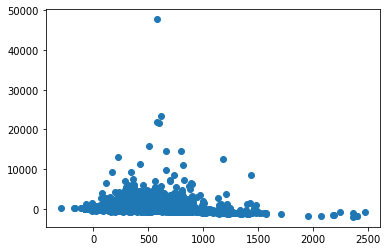

-0.15280128657635048
-0.02522375286409236
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.584838 0.047455 12.324 0.000000
## 0.305769 0.135936 2.249 0.024510
## 0.148397 0.010320 14.379 0.000000
## -1146.795825 95.020790 -12.069 0.000000
## ---
## Mean squared error: 2241.624515 , RMSE: 47.345797
## Multiple R-squared: 0.030558 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

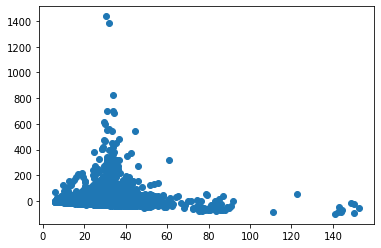

-0.1076371455769509
-0.019086671975321805
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -16.905397 0.830323 -20.360 0.000000
## -2.279796 2.153024 -1.059 0.289676
## 89.691246 4.254452 21.082 0.000000
## 33971.498109 1665.482135 20.397 0.000000
## ---
## Mean squared error: 762439.398608 , RMSE: 873.177759
## Multiple R-squared: 0.089623 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

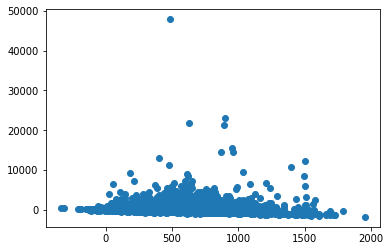

-0.21626217990382632
-0.03276265724729789
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.859578 0.050594 16.990 0.000000
## 0.250518 0.140658 1.781 0.074936
## 5.357928 0.237181 22.590 0.000000
## -1705.548879 101.368674 -16.825 0.000000
## ---
## Mean squared error: 2287.207476 , RMSE: 47.824758
## Multiple R-squared: 0.064850 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

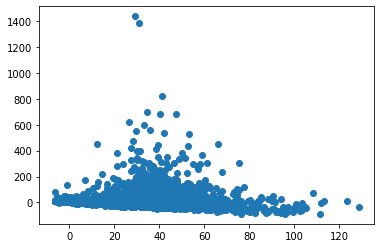

-0.1757395864303655
-0.02454275977732517
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -18.846994 0.712090 -26.467 0.000000
## -0.536862 1.764568 -0.304 0.760946
## -31.007955 7.986948 -3.882 0.000104
## 38075.416679 1427.117846 26.680 0.000000
## ---
## Mean squared error: 656119.483908 , RMSE: 810.012027
## Multiple R-squared: 0.063333 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

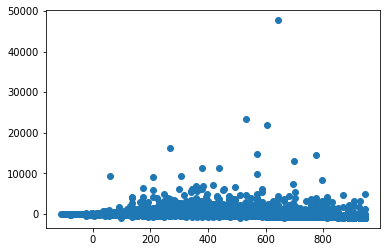

0.22582959665285474
0.155027331068769
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.609423 0.051930 11.736 0.000000
## 0.445651 0.146096 3.050 0.002292
## -4.480061 0.551133 -8.129 0.000000
## -1191.034127 103.914713 -11.462 0.000000
## ---
## Mean squared error: 2342.847560 , RMSE: 48.402971
## Multiple R-squared: 0.019451 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

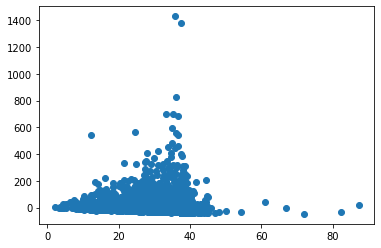

0.2166122723600506
0.17324015444337415
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -19.926235 0.675331 -29.506 0.000000
## -1.464751 1.740082 -0.842 0.399931
## 1.137635 0.157652 7.216 0.000000
## 40204.145439 1354.192827 29.689 0.000000
## ---
## Mean squared error: 665563.943262 , RMSE: 815.821024
## Multiple R-squared: 0.067065 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

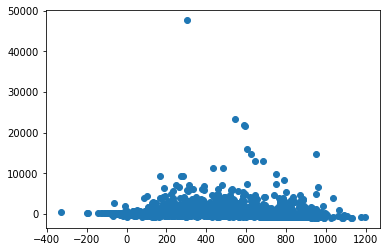

-0.028581122774249203
0.020756284720510304
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.499020 0.047630 10.477 0.000000
## 0.270825 0.138383 1.957 0.050364
## 0.089370 0.009560 9.348 0.000000
## -973.938856 95.349561 -10.214 0.000000
## ---
## Mean squared error: 2269.980285 , RMSE: 47.644310
## Multiple R-squared: 0.019767 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

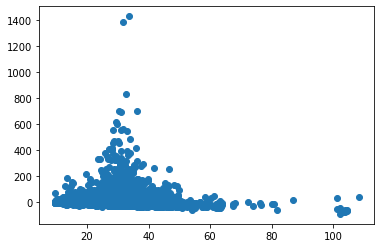

0.018523357200783117
0.03848906569757459
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -20.401505 0.772744 -26.401 0.000000
## -2.570537 2.156737 -1.192 0.233338
## 46.133553 3.660793 12.602 0.000000
## 41074.818498 1548.748622 26.521 0.000000
## ---
## Mean squared error: 741049.050026 , RMSE: 860.842059
## Multiple R-squared: 0.072045 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

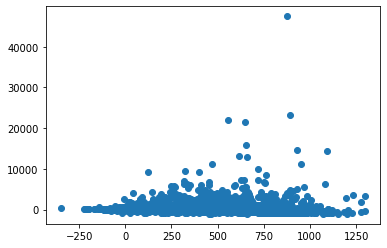

-0.04312969157688827
0.01929935939829826
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.611315 0.050070 12.209 0.000000
## 0.187711 0.142643 1.316 0.188220
## 3.253934 0.215107 15.127 0.000000
## -1203.854366 100.227527 -12.011 0.000000
## ---
## Mean squared error: 2330.219502 , RMSE: 48.272347
## Multiple R-squared: 0.036847 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

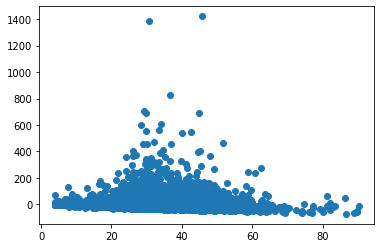

0.00047061254206138935
0.03276138461332042
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -20.288871 0.729233 -27.822 0.000000
## -0.585984 1.866319 -0.314 0.753543
## -21.022668 8.750510 -2.402 0.016300
## 40964.169259 1462.159495 28.016 0.000000
## ---
## Mean squared error: 701298.307913 , RMSE: 837.435554
## Multiple R-squared: 0.063906 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

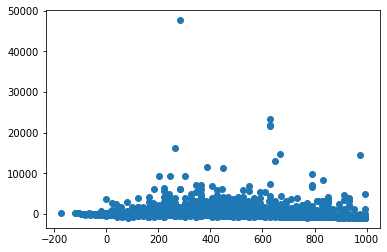

0.10295928635842938
0.12029873867067643
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.500469 0.051403 9.736 0.000000
## 0.393242 0.150474 2.613 0.008980
## -1.960282 0.575977 -3.403 0.000668
## -974.621460 102.892445 -9.472 0.000000
## ---
## Mean squared error: 2307.613003 , RMSE: 48.037621
## Multiple R-squared: 0.012443 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

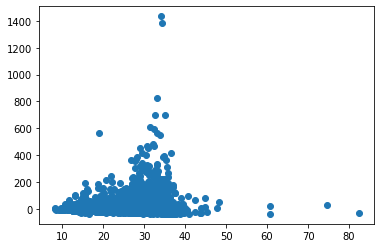

0.09903068264305703
0.12105707667253415
HEAL

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.989706 0.806221 -16.112 0.000000
## 5.395034 2.339474 2.306 0.021158
## 15.398002 8.027213 1.918 0.055156
## 26159.035938 1617.877787 16.169 0.000000
## ---
## Mean squared error: 177239.039435 , RMSE: 420.997672
## Multiple R-squared: 0.063142 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

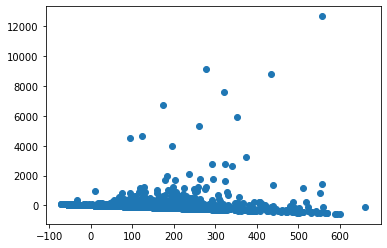

0.16566980637917475
0.43747085940525265
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.127199 0.105399 1.207 0.227603
## 1.876432 0.300616 6.242 0.000000
## 3.112185 1.035883 3.004 0.002685
## -246.402958 211.185686 -1.167 0.243408
## ---
## Mean squared error: 1822.409568 , RMSE: 42.689689
## Multiple R-squared: 0.032502 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

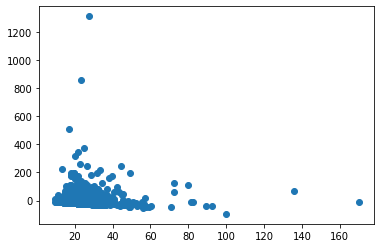

0.16207607231548463
0.4658427149654117
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.103414 0.811022 -16.157 0.000000
## 3.682247 2.707960 1.360 0.173977
## 8.452817 3.956601 2.136 0.032711
## 26395.382447 1627.736064 16.216 0.000000
## ---
## Mean squared error: 177198.471774 , RMSE: 420.949488
## Multiple R-squared: 0.063357 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

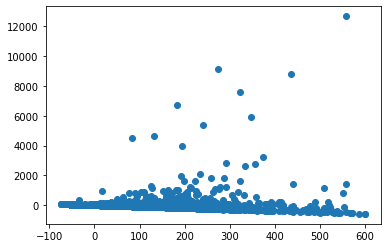

0.2454135136253755
0.6401957420307768
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.114932 0.105849 1.086 0.277657
## 1.726484 0.335059 5.153 0.000000
## 1.476297 0.533041 2.770 0.005650
## -220.454200 212.098593 -1.039 0.298712
## ---
## Mean squared error: 1823.300989 , RMSE: 42.700129
## Multiple R-squared: 0.032029 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

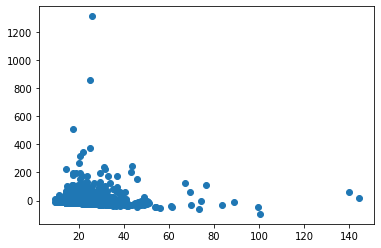

0.22739716352396575
0.6171962947574278
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.730609 0.807706 -15.761 0.000000
## 8.058555 2.170677 3.712 0.000208
## 50.237106 27.278198 1.842 0.065602
## 25616.634160 1623.194540 15.782 0.000000
## ---
## Mean squared error: 177252.246574 , RMSE: 421.013357
## Multiple R-squared: 0.063073 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

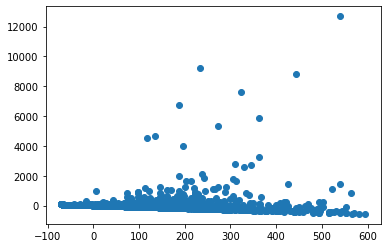

-0.14233948629702287
-0.22428216273107227
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.178675 0.105605 1.692 0.090775
## 2.461854 0.274576 8.966 0.000000
## 10.772174 3.258706 3.306 0.000960
## -354.845317 211.860799 -1.675 0.094067
## ---
## Mean squared error: 1821.161043 , RMSE: 42.675063
## Multiple R-squared: 0.033165 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

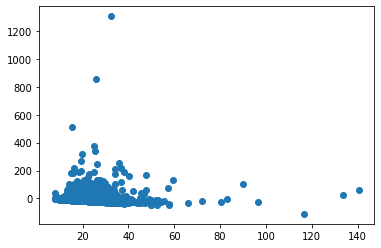

-0.1395881255433648
-0.22631389274493716
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.699128 0.690285 -15.500 0.000000
## 5.343560 1.634147 3.270 0.001083
## 3.957772 0.198448 19.944 0.000000
## 21549.002434 1385.877812 15.549 0.000000
## ---
## Mean squared error: 149378.506819 , RMSE: 386.495158
## Multiple R-squared: 0.134111 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

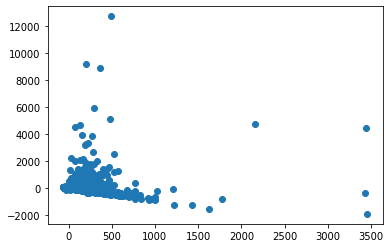

-0.14227209165502194
0.0025428288079435237
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.441091 0.149078 2.959 0.003109
## 2.894415 0.349347 8.285 0.000000
## 0.272428 0.034475 7.902 0.000000
## -875.721802 298.854478 -2.930 0.003409
## ---
## Mean squared error: 4311.801057 , RMSE: 65.664306
## Multiple R-squared: 0.042494 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

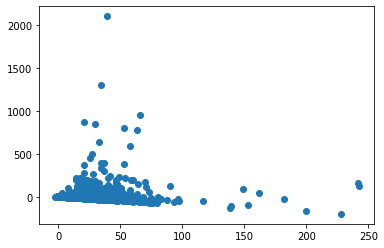

-0.10957807879482334
0.014417916688644386
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.738657 0.915012 -11.736 0.000000
## 6.220678 2.099297 2.963 0.003064
## 76.161618 4.962259 15.348 0.000000
## 21527.326739 1836.629927 11.721 0.000000
## ---
## Mean squared error: 195570.086657 , RMSE: 442.233068
## Multiple R-squared: 0.109605 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

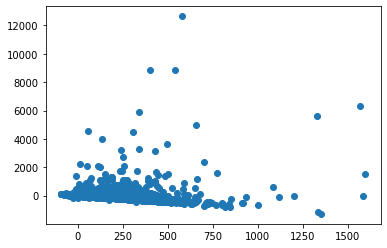

-0.18154905880481742
0.008019017120659139
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.766741 0.166687 4.600 0.000004
## 2.946747 0.385211 7.650 0.000000
## 7.136052 0.798062 8.942 0.000000
## -1537.641702 334.216326 -4.601 0.000004
## ---
## Mean squared error: 4731.665689 , RMSE: 68.787104
## Multiple R-squared: 0.054163 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

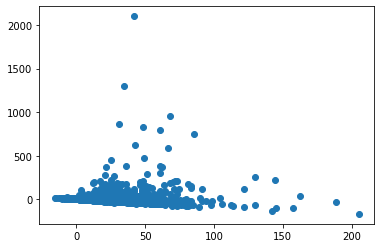

-0.1400640731542002
0.02319402569257942
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.800191 0.706249 -16.708 0.000000
## 7.151924 1.691912 4.227 0.000024
## -5.264208 6.379504 -0.825 0.409320
## 23790.946328 1417.763435 16.781 0.000000
## ---
## Mean squared error: 142578.452130 , RMSE: 377.595620
## Multiple R-squared: 0.064139 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

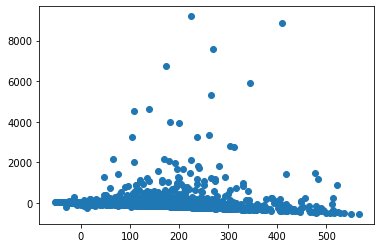

0.11091609460922768
0.10484776881945727
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.294631 0.167565 1.758 0.078799
## 2.948614 0.383926 7.680 0.000000
## -2.102023 1.391237 -1.511 0.130921
## -577.810582 335.816873 -1.721 0.085427
## ---
## Mean squared error: 4655.139164 , RMSE: 68.228580
## Multiple R-squared: 0.023882 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

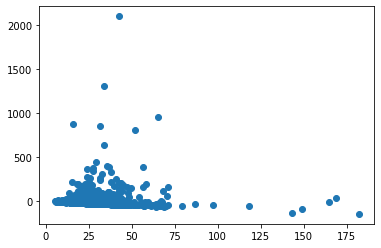

0.13393705319602076
0.10824946251218502
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.715445 0.682026 -17.177 0.000000
## 4.978270 1.647745 3.021 0.002530
## 2.945315 0.162007 18.180 0.000000
## 23582.967601 1369.397908 17.221 0.000000
## ---
## Mean squared error: 147777.606751 , RMSE: 384.418531
## Multiple R-squared: 0.124101 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

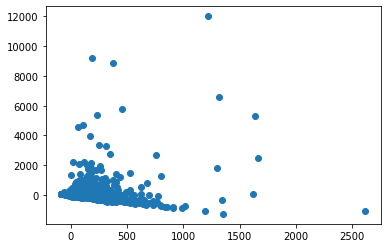

-0.07922015883214598
0.035305466556195875
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.287634 0.146708 1.961 0.050008
## 2.811017 0.345858 8.128 0.000000
## 0.191961 0.028089 6.834 0.000000
## -568.361043 294.091732 -1.933 0.053368
## ---
## Mean squared error: 4103.870535 , RMSE: 64.061459
## Multiple R-squared: 0.037569 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

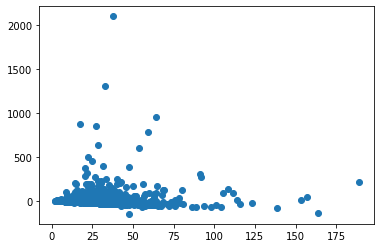

-0.016654557609255657
0.049649846391733116
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.177830 0.811540 -15.006 0.000000
## 4.720941 1.932206 2.443 0.014596
## 55.337460 3.455057 16.016 0.000000
## 24436.064752 1628.830131 15.002 0.000000
## ---
## Mean squared error: 175991.563208 , RMSE: 419.513484
## Multiple R-squared: 0.115664 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

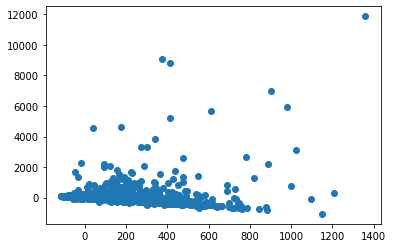

-0.07445722969676354
0.06879018030018236
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.462715 0.158874 2.912 0.003611
## 2.759135 0.372624 7.405 0.000000
## 4.737303 0.587393 8.065 0.000000
## -925.636374 318.446096 -2.907 0.003678
## ---
## Mean squared error: 4403.584772 , RMSE: 66.359512
## Multiple R-squared: 0.046748 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

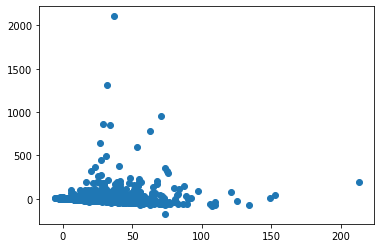

-0.019638393583375827
0.08531467845565946
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.090669 0.761972 -17.180 0.000000
## 6.381917 1.873868 3.406 0.000666
## -4.645227 7.757763 -0.599 0.549350
## 26388.330601 1529.839586 17.249 0.000000
## ---
## Mean squared error: 161487.493695 , RMSE: 401.855066
## Multiple R-squared: 0.067780 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

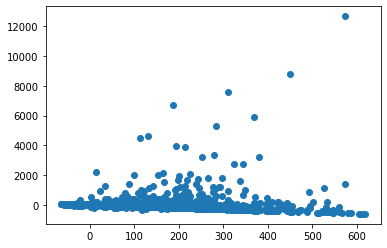

0.06695746715759605
0.07016787743007659
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.238134 0.164708 1.446 0.148342
## 2.739893 0.381208 7.187 0.000000
## 1.108686 1.550572 0.715 0.474656
## -465.775786 330.152117 -1.411 0.158414
## ---
## Mean squared error: 4378.474021 , RMSE: 66.170039
## Multiple R-squared: 0.021803 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

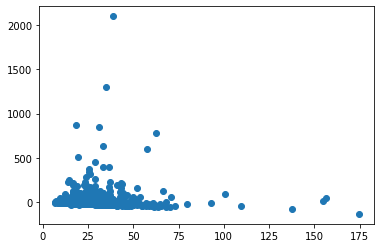

0.07613431100501804
0.09265202244134056
BIOC

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.125463 0.312795 -41.962 0.000000
## 0.646598 0.227977 2.836 0.004566
## 22.114635 2.941576 7.518 0.000000
## 26495.157012 627.916446 42.195 0.000000
## ---
## Mean squared error: 685232.815149 , RMSE: 827.787905
## Multiple R-squared: 0.020849 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

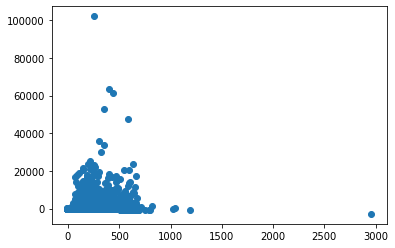

0.10157389107973136
0.3770608137763452
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.351163 0.066422 5.287 0.000000
## 0.393589 0.042038 9.363 0.000000
## 11.656423 0.590171 19.751 0.000000
## -670.720027 133.161450 -5.037 0.000000
## ---
## Mean squared error: 20859.063799 , RMSE: 144.426673
## Multiple R-squared: 0.011768 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

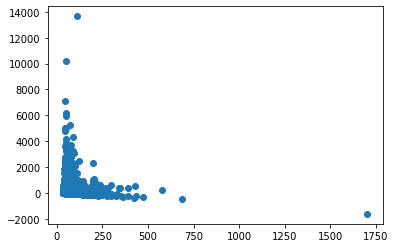

0.1142312560961775
0.3838995748129456
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.194697 0.314027 -42.018 0.000000
## 0.258869 0.260464 0.994 0.320287
## 6.796762 1.007042 6.749 0.000000
## 26650.291088 630.456770 42.271 0.000000
## ---
## Mean squared error: 685322.361054 , RMSE: 827.841990
## Multiple R-squared: 0.020722 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

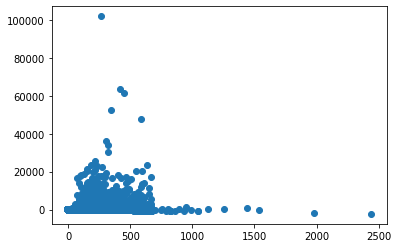

0.14459377314959915
0.5871307134654021
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.307486 0.066668 4.612 0.000004
## 0.142432 0.048523 2.935 0.003333
## 3.917905 0.200969 19.495 0.000000
## -575.085401 133.675846 -4.302 0.000017
## ---
## Mean squared error: 20862.180503 , RMSE: 144.437462
## Multiple R-squared: 0.011620 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

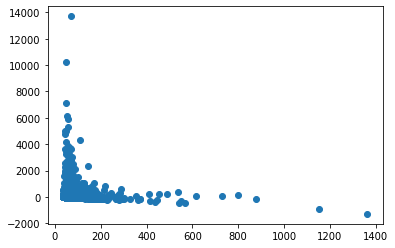

0.15041539725267852
0.6012942786029762
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.028688 0.320979 -37.475 0.000000
## 1.440809 0.211958 6.798 0.000000
## 146.934323 12.138757 12.105 0.000000
## 24240.672442 646.206411 37.512 0.000000
## ---
## Mean squared error: 684498.871296 , RMSE: 827.344470
## Multiple R-squared: 0.021898 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

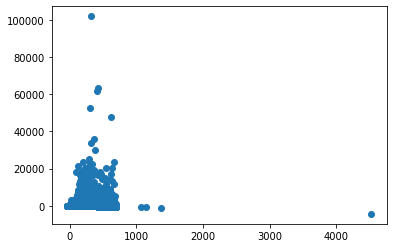

-0.2432168333778098
-0.08106687865426933
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.646137 0.067647 9.552 0.000000
## 0.737723 0.039054 18.890 0.000000
## 31.756097 2.374145 13.376 0.000000
## -1265.530531 135.952298 -9.309 0.000000
## ---
## Mean squared error: 20924.813467 , RMSE: 144.654117
## Multiple R-squared: 0.008653 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

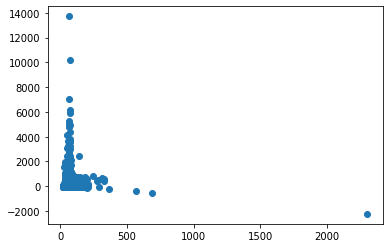

-0.20569017334351825
-0.07556367935162055
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.974994 0.303139 -39.503 0.000000
## 1.107433 0.212038 5.223 0.000000
## 2.860875 0.112931 25.333 0.000000
## 24185.873101 608.941312 39.718 0.000000
## ---
## Mean squared error: 698076.529243 , RMSE: 835.509742
## Multiple R-squared: 0.025482 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

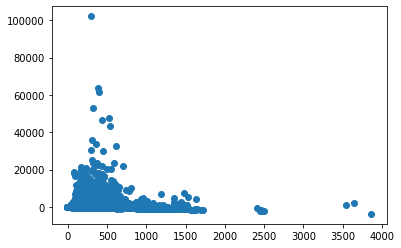

-0.14684074809904493
0.01829355302915667
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.712868 0.078557 9.074 0.000000
## 0.668586 0.048830 13.692 0.000000
## 0.693623 0.025148 27.582 0.000000
## -1390.460593 157.617148 -8.822 0.000000
## ---
## Mean squared error: 33331.371946 , RMSE: 182.568814
## Multiple R-squared: 0.012799 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

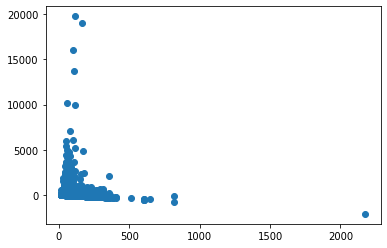

-0.11244163252999054
0.02402520537982125
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.927139 0.368099 -26.969 0.000000
## 0.543625 0.233375 2.329 0.019840
## 85.289900 1.927063 44.259 0.000000
## 19946.578925 739.352103 26.978 0.000000
## ---
## Mean squared error: 822619.879921 , RMSE: 906.983947
## Multiple R-squared: 0.037495 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

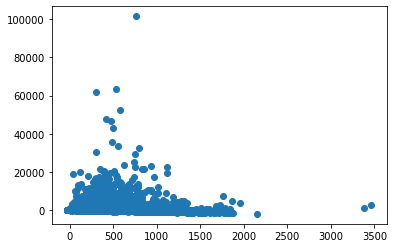

-0.16125367029156557
0.050898607339248406
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.369378 0.084585 16.189 0.000000
## 0.514617 0.050525 10.185 0.000000
## 20.406605 0.408390 49.968 0.000000
## -2737.719398 169.749623 -16.128 0.000000
## ---
## Mean squared error: 35288.554136 , RMSE: 187.852480
## Multiple R-squared: 0.037103 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

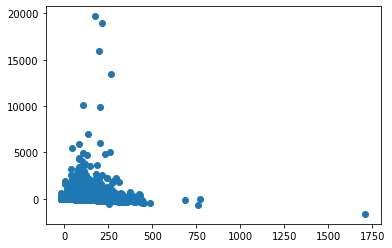

-0.12637672555232624
0.057727758011154824
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.996265 0.365733 -35.535 0.000000
## 1.153503 0.245277 4.703 0.000003
## -24.952982 3.592145 -6.947 0.000000
## 26283.192057 734.133871 35.802 0.000000
## ---
## Mean squared error: 828928.132134 , RMSE: 910.454904
## Multiple R-squared: 0.018305 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

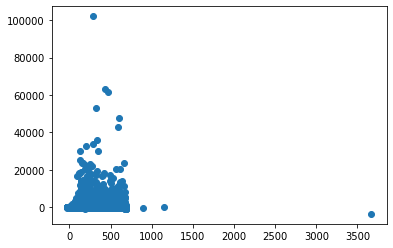

0.13017096541604667
0.03231752721571961
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.694212 0.093080 7.458 0.000000
## 0.590068 0.053381 11.054 0.000000
## -7.618413 0.855270 -8.908 0.000000
## -1339.785406 186.624116 -7.179 0.000000
## ---
## Mean squared error: 37274.680367 , RMSE: 193.066518
## Multiple R-squared: 0.004114 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

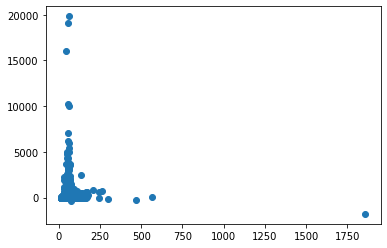

0.13347892165003972
0.02973352924616052
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.610855 0.295223 -42.716 0.000000
## 1.112213 0.215251 5.167 0.000000
## 1.267230 0.043658 29.026 0.000000
## 25450.052841 593.001498 42.917 0.000000
## ---
## Mean squared error: 687275.132804 , RMSE: 829.020586
## Multiple R-squared: 0.027619 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

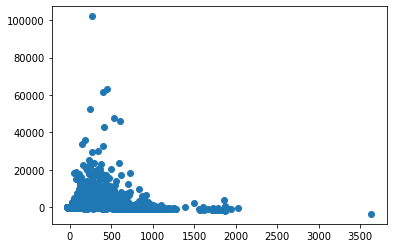

-0.05075173691951258
0.030937800910451604
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.432419 0.077794 5.559 0.000000
## 0.691343 0.049857 13.867 0.000000
## 0.381059 0.010038 37.962 0.000000
## -833.611852 156.053906 -5.342 0.000000
## ---
## Mean squared error: 32994.248882 , RMSE: 181.643191
## Multiple R-squared: 0.021240 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

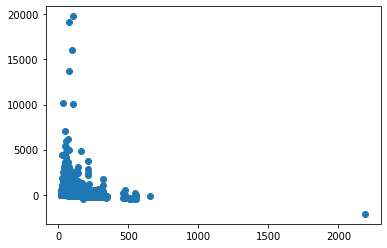

0.010496019177257463
0.031727413863046776
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.267708 0.325196 -37.724 0.000000
## 0.715527 0.226055 3.165 0.001550
## 42.221938 1.013390 41.664 0.000000
## 24670.685232 653.095706 37.775 0.000000
## ---
## Mean squared error: 745683.765237 , RMSE: 863.529829
## Multiple R-squared: 0.035871 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

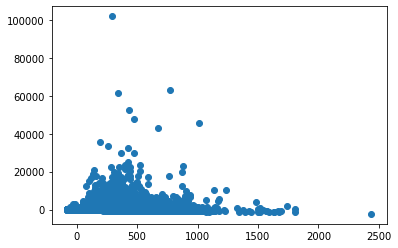

-0.05209536120605208
0.058233038981283194
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.581947 0.080628 7.218 0.000000
## 0.581452 0.050544 11.504 0.000000
## 12.259228 0.227614 53.860 0.000000
## -1159.881274 161.722415 -7.172 0.000000
## ---
## Mean squared error: 33684.172179 , RMSE: 183.532483
## Multiple R-squared: 0.040336 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

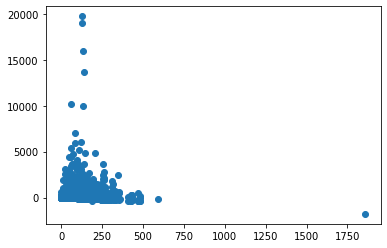

0.01101225509911873
0.0577347633220819
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.990229 0.365834 -35.508 0.000000
## 1.207881 0.248192 4.867 0.000001
## -14.962137 4.456671 -3.357 0.000788
## 26259.030988 734.502603 35.751 0.000000
## ---
## Mean squared error: 820760.252411 , RMSE: 905.958196
## Multiple R-squared: 0.017449 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

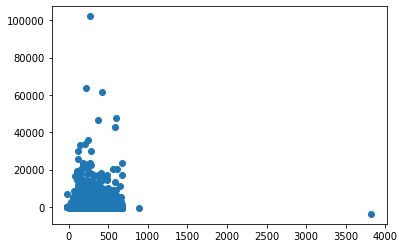

0.10412097690366723
0.02981854274161832
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.685027 0.097830 7.002 0.000000
## 0.649345 0.056730 11.446 0.000000
## -6.155723 1.138369 -5.407 0.000000
## -1324.582015 196.192013 -6.751 0.000000
## ---
## Mean squared error: 40794.251123 , RMSE: 201.975868
## Multiple R-squared: 0.003588 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

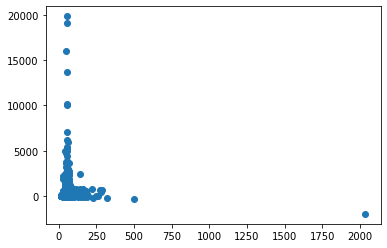

0.08940839398824973
0.025832049622220035
NEUR

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.573068 0.480263 -26.180 0.000000
## 7.149366 1.203991 5.938 0.000000
## -1.218199 5.773055 -0.211 0.832881
## 25378.962553 962.435851 26.370 0.000000
## ---
## Mean squared error: 150191.597183 , RMSE: 387.545607
## Multiple R-squared: 0.070742 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

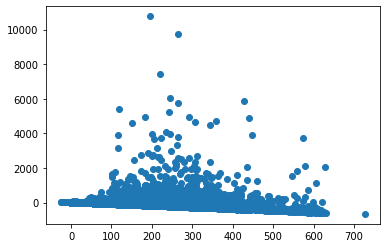

0.1345247526106644
0.38424083272153536
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.254904 0.095277 -2.675 0.007480
## 3.895760 0.235426 16.548 0.000000
## 2.549728 1.116459 2.284 0.022413
## 534.810762 190.715701 2.804 0.005057
## ---
## Mean squared error: 4026.480060 , RMSE: 63.454551
## Multiple R-squared: 0.043740 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

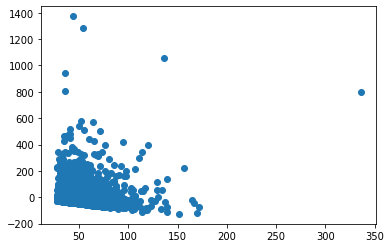

0.14031137633713636
0.34599039000153853
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.661723 0.481828 -26.279 0.000000
## 5.306970 1.431548 3.707 0.000211
## 5.753412 2.928123 1.965 0.049459
## 25550.897781 965.542743 26.463 0.000000
## ---
## Mean squared error: 150128.136777 , RMSE: 387.463723
## Multiple R-squared: 0.071135 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

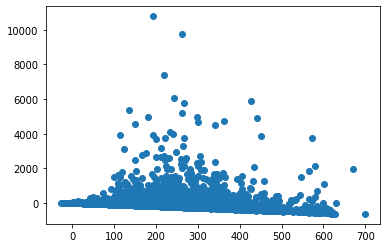

0.24071249250960347
0.6463541636866807
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.287502 0.095517 -3.010 0.002621
## 3.305955 0.276831 11.942 0.000000
## 2.664293 0.574479 4.638 0.000004
## 600.375226 191.200755 3.140 0.001696
## ---
## Mean squared error: 4017.815433 , RMSE: 63.386240
## Multiple R-squared: 0.045798 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

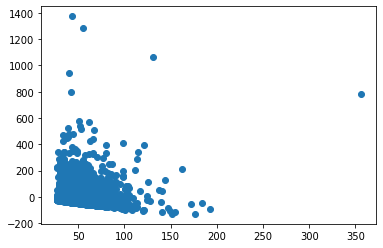

0.24506188247727692
0.6216815594661385
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.919406 0.487126 -24.469 0.000000
## 8.730168 1.141511 7.648 0.000000
## 127.000518 17.545348 7.238 0.000000
## 23984.423291 978.575766 24.510 0.000000
## ---
## Mean squared error: 149325.715286 , RMSE: 386.426856
## Multiple R-squared: 0.076099 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

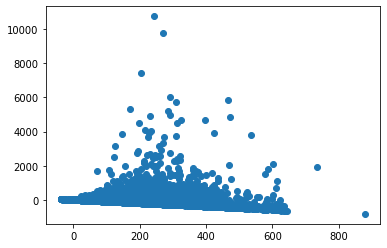

-0.2423319570012448
-0.25465845443541746
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.126065 0.095747 -1.317 0.187999
## 4.471347 0.226804 19.715 0.000000
## 26.563009 3.121752 8.509 0.000000
## 261.439696 192.026352 1.361 0.173403
## ---
## Mean squared error: 3990.988669 , RMSE: 63.174272
## Multiple R-squared: 0.052169 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

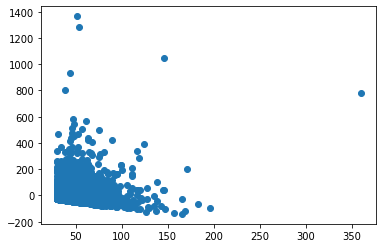

-0.20415654353844784
-0.2522346485473827
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.000610 0.465062 -25.804 0.000000
## 3.421834 0.849123 4.030 0.000056
## 1.942453 0.118086 16.450 0.000000
## 24205.519387 933.073556 25.942 0.000000
## ---
## Mean squared error: 374427.813975 , RMSE: 611.905069
## Multiple R-squared: 0.045484 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

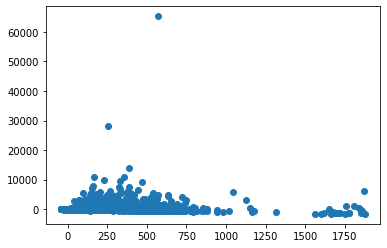

-0.1168369130542925
-0.016434585429856013
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.052948 0.058043 0.912 0.361660
## 2.178498 0.107827 20.204 0.000000
## 0.224821 0.012683 17.726 0.000000
## -81.121289 116.304453 -0.697 0.485505
## ---
## Mean squared error: 4016.418969 , RMSE: 63.375224
## Multiple R-squared: 0.040467 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

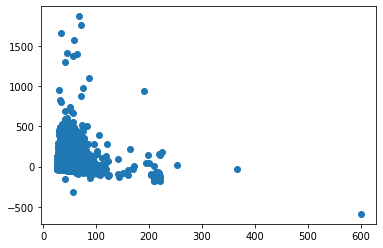

-0.08755829533089836
-0.006383129516748439
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.472473 0.571819 -18.314 0.000000
## 2.981243 0.986894 3.021 0.002524
## 65.893207 2.883325 22.853 0.000000
## 21034.055205 1147.510468 18.330 0.000000
## ---
## Mean squared error: 437222.975993 , RMSE: 661.228384
## Multiple R-squared: 0.054620 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

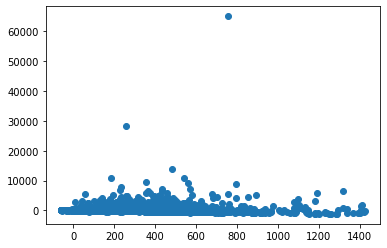

-0.19890330702541836
-0.0036266670619078457
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.479652 0.062317 7.697 0.000000
## 2.067292 0.112454 18.384 0.000000
## 8.894899 0.286816 31.013 0.000000
## -950.263799 124.932565 -7.606 0.000000
## ---
## Mean squared error: 4092.648113 , RMSE: 63.973808
## Multiple R-squared: 0.079331 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

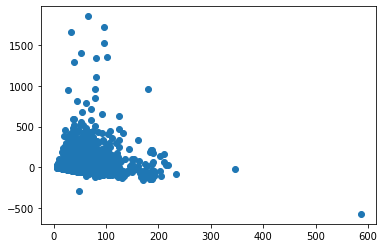

-0.16668437559850838
0.01355280116820713
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.476119 0.372675 -30.794 0.000000
## 4.589952 0.785006 5.847 0.000000
## -16.542965 3.543935 -4.668 0.000003
## 23177.165867 747.158535 31.020 0.000000
## ---
## Mean squared error: 201317.643441 , RMSE: 448.684347
## Multiple R-squared: 0.053707 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

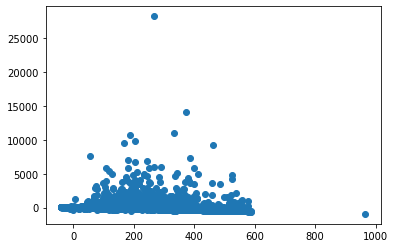

0.14878291275205566
0.11257807528956175
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.020459 0.066647 -0.307 0.758862
## 3.064904 0.146264 20.955 0.000000
## -3.176962 0.584958 -5.431 0.000000
## 66.592919 133.427879 0.499 0.617721
## ---
## Mean squared error: 4264.864696 , RMSE: 65.305932
## Multiple R-squared: 0.031953 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

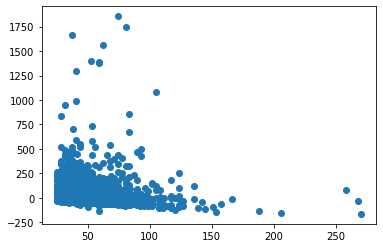

0.15933001437165822
0.10986954981202901
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.510574 0.459165 -27.246 0.000000
## 3.647655 0.877615 4.156 0.000032
## 0.997381 0.070452 14.157 0.000000
## 25220.807870 921.238466 27.377 0.000000
## ---
## Mean squared error: 372694.354325 , RMSE: 610.486981
## Multiple R-squared: 0.043267 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

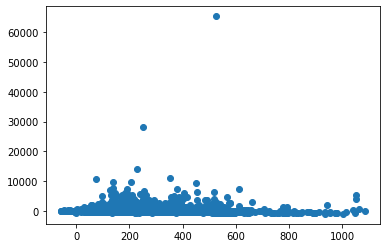

-0.07081040691502953
0.011594294680503218
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.037993 0.057599 -0.660 0.509517
## 2.192890 0.107498 20.399 0.000000
## 0.204905 0.007598 26.970 0.000000
## 97.292550 115.404884 0.843 0.399210
## ---
## Mean squared error: 3949.745598 , RMSE: 62.847002
## Multiple R-squared: 0.062868 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

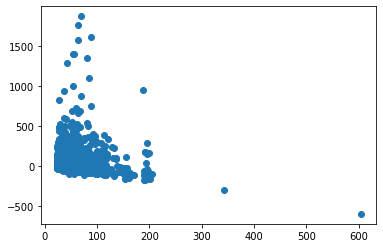

-0.005289987399029494
0.02479379681418221
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.417105 0.508195 -24.434 0.000000
## 3.003354 0.961753 3.123 0.001794
## 29.602116 1.715666 17.254 0.000000
## 24976.081583 1019.633967 24.495 0.000000
## ---
## Mean squared error: 403390.636340 , RMSE: 635.130409
## Multiple R-squared: 0.046532 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

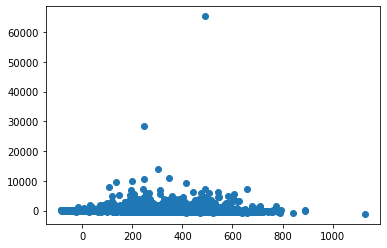

-0.09105172338451639
0.05408195881729321
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.091518 0.059146 1.547 0.121802
## 1.965935 0.109164 18.009 0.000000
## 6.768284 0.178367 37.946 0.000000
## -175.946391 118.510268 -1.485 0.137655
## ---
## Mean squared error: 3907.538796 , RMSE: 62.510310
## Multiple R-squared: 0.100760 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

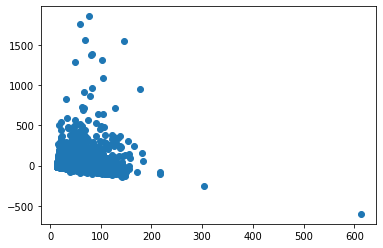

-0.017786124015431545
0.07200495092508505
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.981665 0.550466 -23.583 0.000000
## 3.663719 1.017339 3.601 0.000318
## -13.847904 6.364347 -2.176 0.029579
## 26204.300043 1104.124152 23.733 0.000000
## ---
## Mean squared error: 436384.785341 , RMSE: 660.594267
## Multiple R-squared: 0.031756 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

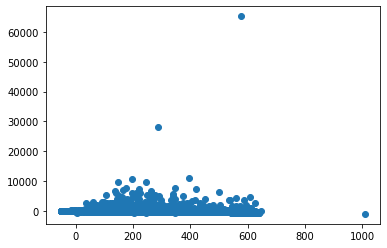

0.12038054328569055
0.08054076722080016
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.049174 0.065995 0.745 0.456216
## 2.152707 0.119216 18.057 0.000000
## -3.452746 0.728667 -4.738 0.000002
## -68.833329 132.212835 -0.521 0.602636
## ---
## Mean squared error: 4212.357324 , RMSE: 64.902676
## Multiple R-squared: 0.025006 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

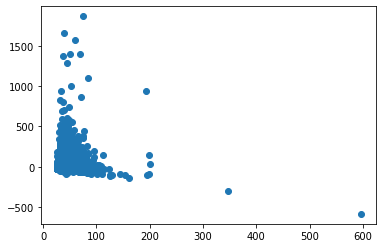

0.09329632741255067
0.06471779959129825
VETE

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.078681 0.169451 -12.267 0.000000
## 1.008732 0.689737 1.462 0.143853
## 9.088086 2.706286 3.358 0.000808
## 4188.920714 339.166954 12.351 0.000000
## ---
## Mean squared error: 3854.039472 , RMSE: 62.080911
## Multiple R-squared: 0.112430 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

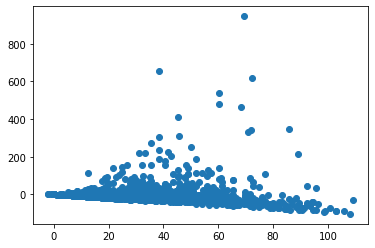

0.1315436635355343
0.3425465830994017
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.127939 0.042017 3.045 0.002394
## 0.597071 0.183991 3.245 0.001216
## 3.420491 0.772624 4.427 0.000011
## -254.795109 83.958784 -3.035 0.002475
## ---
## Mean squared error: 154.090979 , RMSE: 12.413339
## Multiple R-squared: 0.061736 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

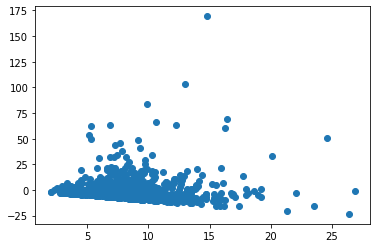

0.11241416167203978
0.25848529376403145
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.126607 0.169778 -12.526 0.000000
## 0.124287 0.769306 0.162 0.871680
## 5.301654 1.330278 3.985 0.000071
## 4289.716488 339.801892 12.624 0.000000
## ---
## Mean squared error: 3840.340647 , RMSE: 61.970482
## Multiple R-squared: 0.115585 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

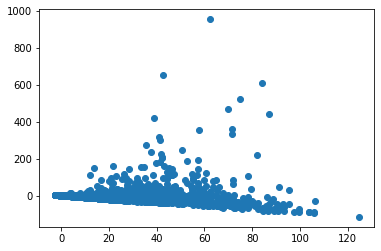

0.256066460095451
0.5680896735556465
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.108508 0.042651 2.544 0.011120
## 0.445368 0.199267 2.235 0.025655
## 1.441525 0.364346 3.956 0.000082
## -213.870411 85.209684 -2.510 0.012246
## ---
## Mean squared error: 154.740776 , RMSE: 12.439485
## Multiple R-squared: 0.057779 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

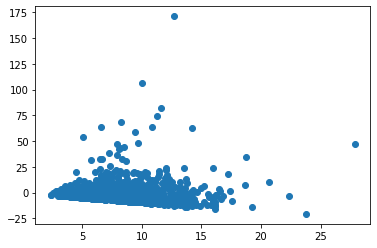

0.26942798415478053
0.4795840885819667
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.053378 0.169869 -12.088 0.000000
## 2.188915 0.680084 3.219 0.001321
## 18.401132 7.665667 2.400 0.016517
## 4134.040304 340.238172 12.150 0.000000
## ---
## Mean squared error: 3870.570220 , RMSE: 62.213907
## Multiple R-squared: 0.108623 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

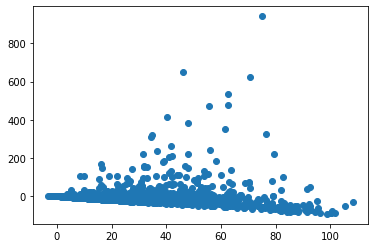

-0.12658287593175366
-0.29399958759018047
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.136832 0.042348 3.231 0.001277
## 0.884863 0.188059 4.705 0.000003
## 3.113199 1.781413 1.748 0.080867
## -271.459009 84.664209 -3.206 0.001391
## ---
## Mean squared error: 156.852966 , RMSE: 12.524095
## Multiple R-squared: 0.044918 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

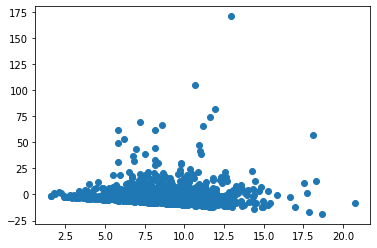

-0.08431971569768447
-0.29589391236093415
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.649628 0.139928 -18.936 0.000000
## 1.036999 0.268564 3.861 0.000115
## 0.638750 0.112878 5.659 0.000000
## 5353.607980 280.860040 19.061 0.000000
## ---
## Mean squared error: 4502.453361 , RMSE: 67.100323
## Multiple R-squared: 0.116593 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

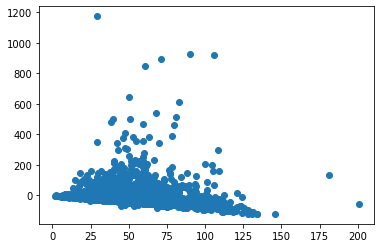

-0.07560608270942408
0.0007561877023772914
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.253589 0.046206 5.488 0.000000
## 0.751773 0.088013 8.542 0.000000
## 0.245819 0.031965 7.690 0.000000
## -500.935872 92.623303 -5.408 0.000000
## ---
## Mean squared error: 323.475941 , RMSE: 17.985437
## Multiple R-squared: 0.073757 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

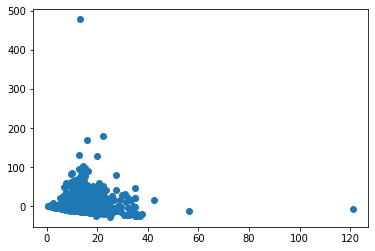

-0.02874869503618038
0.02930116017877597
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.278604 0.179744 -12.677 0.000000
## 1.065042 0.325707 3.270 0.001091
## 15.642172 1.716917 9.111 0.000000
## 4592.409069 360.745330 12.730 0.000000
## ---
## Mean squared error: 5549.729606 , RMSE: 74.496507
## Multiple R-squared: 0.103200 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

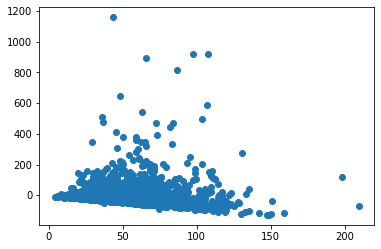

-0.11395839791423092
0.025004955531138684
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.374298 0.050229 7.452 0.000000
## 0.752576 0.093522 8.047 0.000000
## 4.978164 0.446827 11.141 0.000000
## -748.295205 100.734553 -7.428 0.000000
## ---
## Mean squared error: 336.746173 , RMSE: 18.350645
## Multiple R-squared: 0.113915 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

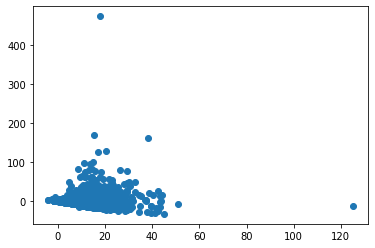

-0.10445644897579968
0.050691660118324725
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.925701 0.155595 -18.803 0.000000
## 1.194270 0.294813 4.051 0.000052
## -1.029524 1.428189 -0.721 0.471059
## 5912.321767 312.261966 18.934 0.000000
## ---
## Mean squared error: 4882.953119 , RMSE: 69.878130
## Multiple R-squared: 0.121515 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

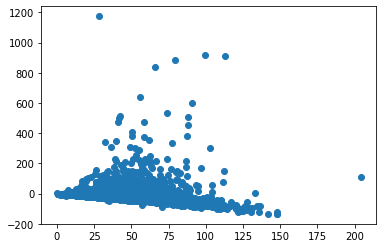

0.1517767338149577
0.07791341754430002
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.228857 0.054923 4.167 0.000032
## 0.790237 0.099016 7.981 0.000000
## -0.152741 0.466433 -0.327 0.743352
## -449.735199 110.050649 -4.087 0.000046
## ---
## Mean squared error: 361.690663 , RMSE: 19.018167
## Multiple R-squared: 0.048668 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

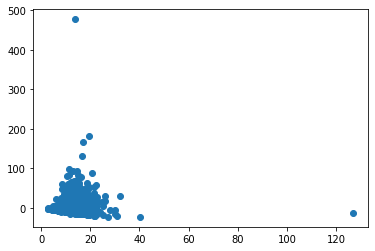

0.17512079675608944
0.0561904794888391
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.765619 0.135830 -20.361 0.000000
## 0.900127 0.259837 3.464 0.000539
## 0.397811 0.068731 5.788 0.000000
## 5586.836597 272.672483 20.489 0.000000
## ---
## Mean squared error: 4244.167818 , RMSE: 65.147278
## Multiple R-squared: 0.125215 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

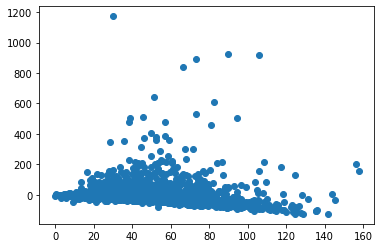

-0.0253093347526963
0.04006262009107741
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.227356 0.045813 4.963 0.000001
## 0.677421 0.086351 7.845 0.000000
## 0.167925 0.021266 7.896 0.000000
## -448.184526 91.848048 -4.880 0.000001
## ---
## Mean squared error: 306.874899 , RMSE: 17.517845
## Multiple R-squared: 0.069240 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

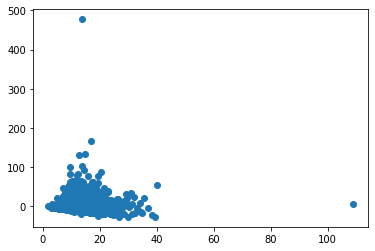

0.005093786775829177
0.06887328521084582
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.658323 0.159238 -16.694 0.000000
## 1.058091 0.316506 3.343 0.000840
## 10.728707 1.148428 9.342 0.000000
## 5357.689139 319.582960 16.765 0.000000
## ---
## Mean squared error: 4849.789714 , RMSE: 69.640432
## Multiple R-squared: 0.125942 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

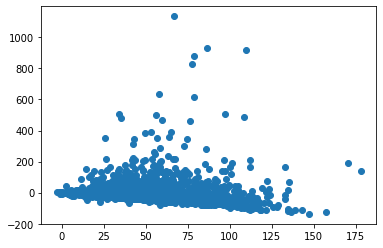

-0.05371826036515582
0.03976650928760782
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.302214 0.048481 6.234 0.000000
## 0.680082 0.090275 7.533 0.000000
## 3.921949 0.324721 12.078 0.000000
## -603.094071 97.211005 -6.204 0.000000
## ---
## Mean squared error: 312.822295 , RMSE: 17.686783
## Multiple R-squared: 0.111173 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

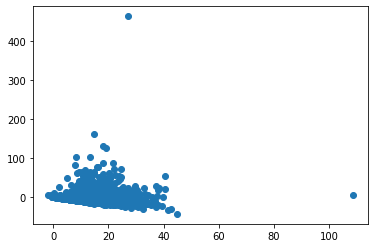

-0.03636970777277869
0.0666525911189512
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -2.780143 0.157586 -17.642 0.000000
## 0.715750 0.355362 2.014 0.044100
## -1.688061 1.564224 -1.079 0.280615
## 5622.259031 316.189094 17.781 0.000000
## ---
## Mean squared error: 4543.960451 , RMSE: 67.408905
## Multiple R-squared: 0.113559 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

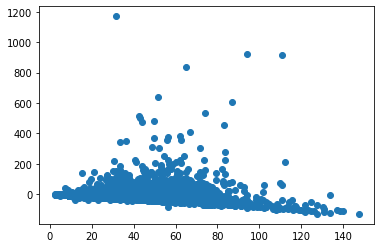

0.12078516117804534
0.05351790231064493
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.254295 0.056874 4.471 0.000008
## 0.908073 0.148111 6.131 0.000000
## -0.473466 0.530962 -0.892 0.372662
## -501.155069 113.930091 -4.399 0.000012
## ---
## Mean squared error: 359.556255 , RMSE: 18.961969
## Multiple R-squared: 0.038386 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

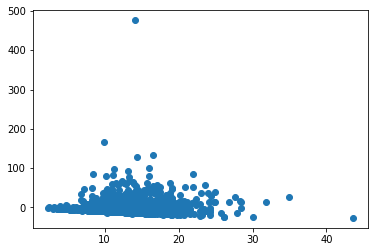

0.11545878470108914
0.048485849879093705
ENGI

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.650982 0.267836 -43.500 0.000000
## -0.363800 0.096782 -3.759 0.000171
## 20.985180 3.637179 5.770 0.000000
## 23504.435827 538.148905 43.676 0.000000
## ---
## Mean squared error: 199367.408371 , RMSE: 446.505776
## Multiple R-squared: 0.058657 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

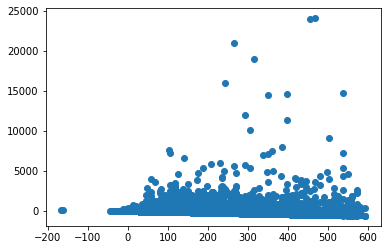

0.07226412705602969
0.6765215116477867
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.895512 0.055821 16.043 0.000000
## -0.147968 0.019099 -7.747 0.000000
## 10.554626 0.760882 13.872 0.000000
## -1778.695497 111.936837 -15.890 0.000000
## ---
## Mean squared error: 5582.188888 , RMSE: 74.714047
## Multiple R-squared: 0.023145 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

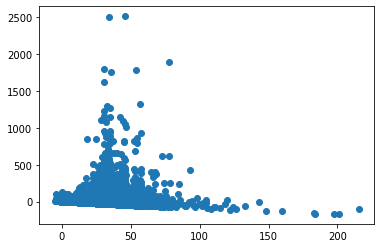

0.08242065404895343
0.6778421791863689
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.638551 0.268615 -43.328 0.000000
## -0.550330 0.167342 -3.289 0.001008
## 6.395522 1.715628 3.728 0.000194
## 23495.275893 539.754787 43.530 0.000000
## ---
## Mean squared error: 199494.192946 , RMSE: 446.647728
## Multiple R-squared: 0.058058 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

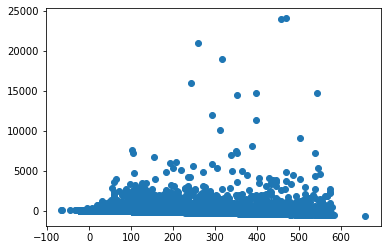

0.06678610881610983
0.9041061299564699
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.907581 0.056043 16.194 0.000000
## -0.295648 0.037222 -7.943 0.000000
## 3.753294 0.395128 9.499 0.000000
## -1795.695161 112.399511 -15.976 0.000000
## ---
## Mean squared error: 5609.140889 , RMSE: 74.894198
## Multiple R-squared: 0.018429 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

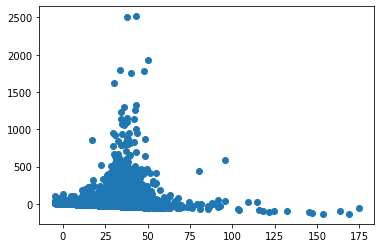

0.06496938795141556
0.925298513521833
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.439981 0.275799 -41.479 0.000000
## 0.016315 0.071311 0.229 0.819038
## 13.472668 9.741688 1.383 0.166678
## 23098.505136 555.926620 41.550 0.000000
## ---
## Mean squared error: 199572.623342 , RMSE: 446.735518
## Multiple R-squared: 0.057688 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

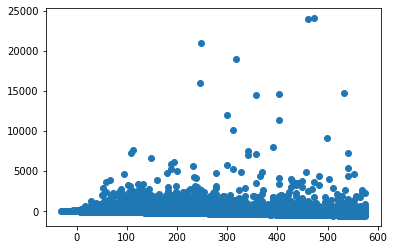

-0.2481275879975547
-0.028172071870077878
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.908481 0.057271 15.863 0.000000
## 0.030393 0.014098 2.156 0.031114
## -8.329107 1.969134 -4.230 0.000023
## -1786.521663 115.201593 -15.508 0.000000
## ---
## Mean squared error: 5628.377527 , RMSE: 75.022513
## Multiple R-squared: 0.015062 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

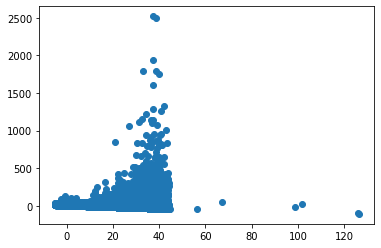

-0.2225864025005328
-0.0273409716779228
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.029069 0.252843 -47.575 0.000000
## -0.015840 0.098017 -0.162 0.871621
## 2.636862 0.109343 24.115 0.000000
## 24290.861000 508.551530 47.765 0.000000
## ---
## Mean squared error: 273302.127752 , RMSE: 522.783060
## Multiple R-squared: 0.052879 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

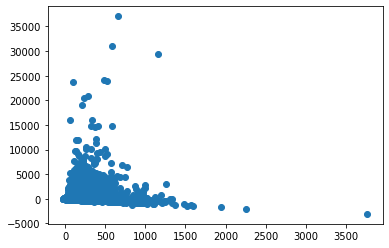

-0.11174251026917223
0.05033909039725714
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.304340 0.065056 20.049 0.000000
## 0.042682 0.020169 2.116 0.034337
## 0.508134 0.023296 21.812 0.000000
## -2583.567074 130.606625 -19.781 0.000000
## ---
## Mean squared error: 11505.632232 , RMSE: 107.264310
## Multiple R-squared: 0.021317 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

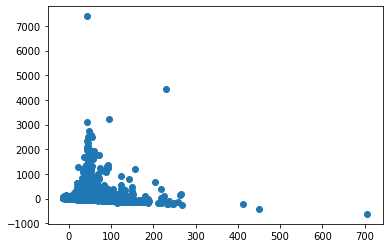

-0.06188411150161184
0.054196240375347815
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.468764 0.331651 -34.581 0.000000
## -0.104043 0.112863 -0.922 0.356609
## 75.826861 2.166562 34.999 0.000000
## 23070.629500 666.765022 34.601 0.000000
## ---
## Mean squared error: 361270.846879 , RMSE: 601.058106
## Multiple R-squared: 0.061982 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

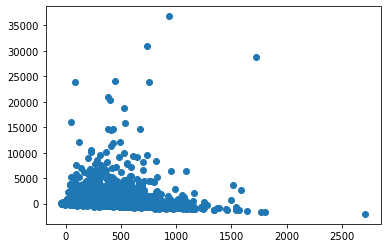

-0.11766073672280472
0.047176338155993716
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.797133 0.071931 24.984 0.000000
## 0.016903 0.021090 0.801 0.422887
## 16.987585 0.423709 40.093 0.000000
## -3593.349555 144.409509 -24.883 0.000000
## ---
## Mean squared error: 12572.462202 , RMSE: 112.126991
## Multiple R-squared: 0.059252 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

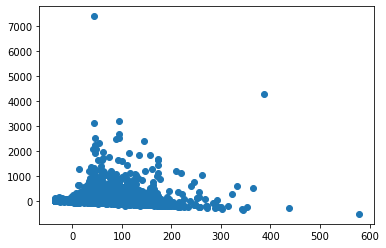

-0.06982811711824413
0.05050699272653618
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.576180 0.283824 -44.310 0.000000
## 0.072559 0.099221 0.731 0.464611
## -4.060586 3.901463 -1.041 0.297981
## 25408.657133 570.561107 44.533 0.000000
## ---
## Mean squared error: 274881.706837 , RMSE: 524.291624
## Multiple R-squared: 0.047547 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

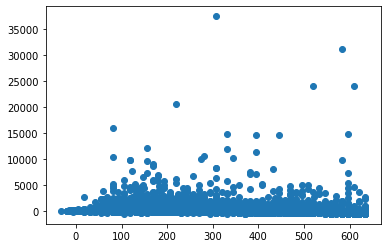

0.10481582523699585
0.013685202583258251
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.149066 0.071568 16.056 0.000000
## 0.051702 0.019761 2.616 0.008892
## -1.353346 0.983131 -1.377 0.168657
## -2268.379895 143.597293 -15.797 0.000000
## ---
## Mean squared error: 10856.361435 , RMSE: 104.193865
## Multiple R-squared: 0.009682 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

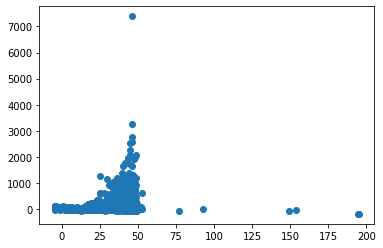

0.11008361295732517
0.011525609825198745
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.521300 0.247514 -50.588 0.000000
## 0.017158 0.082251 0.209 0.834762
## 0.892387 0.034022 26.229 0.000000
## 25282.275427 497.801284 50.788 0.000000
## ---
## Mean squared error: 266168.736924 , RMSE: 515.915436
## Multiple R-squared: 0.054589 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

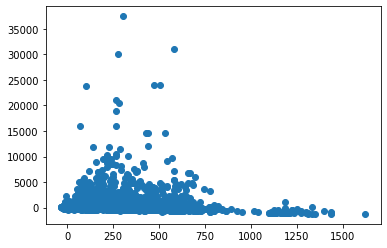

-0.018754820219470995
0.026418235816823066
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.092780 0.064107 17.046 0.000000
## 0.041629 0.019747 2.108 0.035029
## 0.339278 0.007702 44.053 0.000000
## -2162.289443 128.685079 -16.803 0.000000
## ---
## Mean squared error: 11047.317266 , RMSE: 105.106219
## Multiple R-squared: 0.056414 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

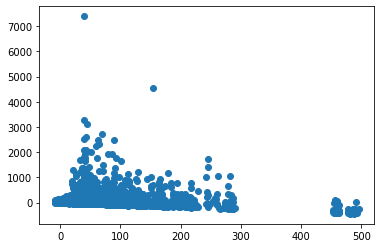

0.04036356408372981
0.029177523141603854
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.871639 0.297662 -43.242 0.000000
## -0.039089 0.090830 -0.430 0.666942
## 37.298335 1.080761 34.511 0.000000
## 25926.183178 598.313953 43.332 0.000000
## ---
## Mean squared error: 323900.949517 , RMSE: 569.122965
## Multiple R-squared: 0.062549 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

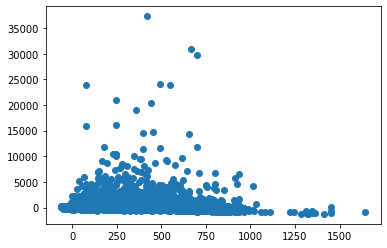

-0.004306370709427075
0.03301755791148065
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.265249 0.068920 18.358 0.000000
## 0.020819 0.020332 1.024 0.305849
## 12.733954 0.225878 56.375 0.000000
## -2528.441611 138.299554 -18.282 0.000000
## ---
## Mean squared error: 11696.015261 , RMSE: 108.148117
## Multiple R-squared: 0.095307 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

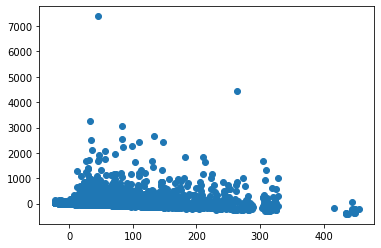

0.05414958955002502
0.03657296107829301
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.865890 0.303838 -42.345 0.000000
## 0.070698 0.104143 0.679 0.497235
## -1.620763 4.974827 -0.326 0.744583
## 25994.347207 610.841940 42.555 0.000000
## ---
## Mean squared error: 313573.013563 , RMSE: 559.975904
## Multiple R-squared: 0.043485 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

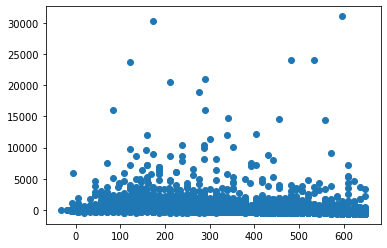

0.08900818456129847
0.005320158848584683
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.141154 0.075337 15.147 0.000000
## 0.051496 0.020716 2.486 0.012934
## -1.157918 1.249186 -0.927 0.353967
## -2252.150406 151.169471 -14.898 0.000000
## ---
## Mean squared error: 11950.397475 , RMSE: 109.317874
## Multiple R-squared: 0.008702 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

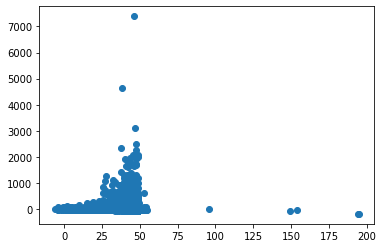

0.08811181879991743
0.0022412398935942237
PHAR

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.618592 0.402759 -16.433 0.000000
## 0.360114 0.801010 0.450 0.653036
## 9.138713 5.497105 1.662 0.096480
## 13365.337855 808.341434 16.534 0.000000
## ---
## Mean squared error: 71754.196200 , RMSE: 267.869737
## Multiple R-squared: 0.049117 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

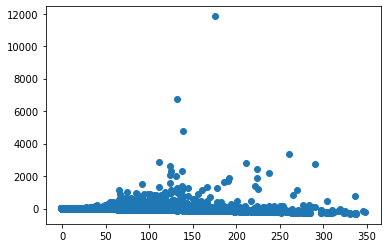

0.09201315875000926
0.2286205566194738
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.272861 0.067527 4.041 0.000054
## 0.147788 0.116427 1.269 0.204389
## 3.818563 0.919881 4.151 0.000034
## -528.775940 135.337467 -3.907 0.000095
## ---
## Mean squared error: 1317.711160 , RMSE: 36.300291
## Multiple R-squared: 0.010797 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

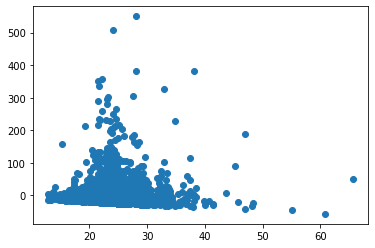

0.09705224369954715
0.18716052793198512
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.650564 0.405181 -16.414 0.000000
## 0.015637 0.904117 0.017 0.986202
## 3.405146 2.439807 1.396 0.162875
## 13435.728711 813.173758 16.523 0.000000
## ---
## Mean squared error: 71765.198779 , RMSE: 267.890274
## Multiple R-squared: 0.048971 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

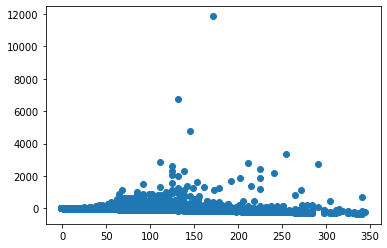

0.19179963989647952
0.5182984323284502
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.269889 0.067900 3.975 0.000072
## 0.042915 0.131698 0.326 0.744548
## 1.186978 0.403281 2.943 0.003266
## -519.877275 136.102329 -3.820 0.000136
## ---
## Mean squared error: 1320.562059 , RMSE: 36.339539
## Multiple R-squared: 0.008656 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

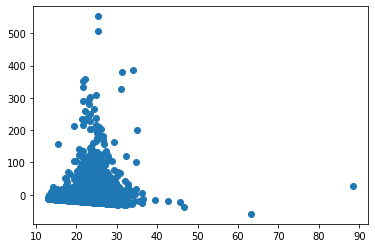

0.16736929955794697
0.5017820116970304
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.153901 0.413259 -14.891 0.000000
## 1.275828 0.793753 1.607 0.108040
## 67.105514 15.322202 4.380 0.000012
## 12404.261653 831.845395 14.912 0.000000
## ---
## Mean squared error: 71533.519160 , RMSE: 267.457509
## Multiple R-squared: 0.052041 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

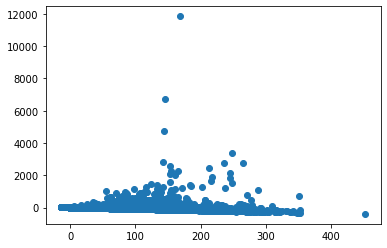

-0.2648843200317655
-0.21704612842970808
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.399795 0.068758 5.815 0.000000
## 0.367522 0.115736 3.176 0.001507
## 16.463557 2.353736 6.995 0.000000
## -788.425142 138.189038 -5.705 0.000000
## ---
## Mean squared error: 1307.272993 , RMSE: 36.156230
## Multiple R-squared: 0.018632 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

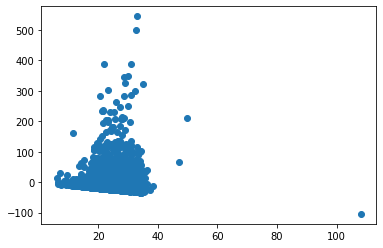

-0.2388625681514315
-0.1903041566337823
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -5.727618 0.183831 -31.157 0.000000
## 0.629271 0.277761 2.266 0.023493
## 1.285602 0.098986 12.988 0.000000
## 11568.993245 369.236046 31.332 0.000000
## ---
## Mean squared error: 44502.556836 , RMSE: 210.956291
## Multiple R-squared: 0.066506 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

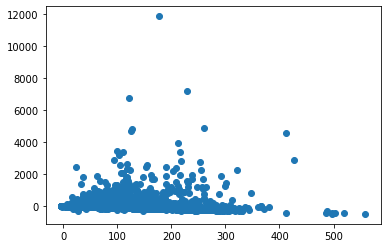

-0.1128393017052077
-0.022006803864869813
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.288964 0.035683 8.098 0.000000
## 0.424928 0.060279 7.049 0.000000
## 0.302909 0.016891 17.934 0.000000
## -560.421260 71.563810 -7.831 0.000000
## ---
## Mean squared error: 1140.409878 , RMSE: 33.769955
## Multiple R-squared: 0.031457 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

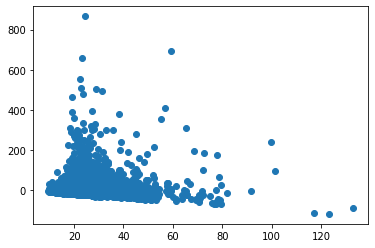

-0.06657880703543091
-0.013996642377507508
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -5.347413 0.235942 -22.664 0.000000
## 0.461610 0.327566 1.409 0.158795
## 29.679056 1.653294 17.951 0.000000
## 10772.688349 473.745648 22.739 0.000000
## ---
## Mean squared error: 55960.250165 , RMSE: 236.559190
## Multiple R-squared: 0.064670 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

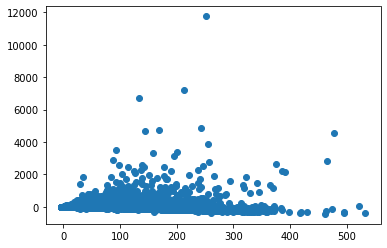

-0.1151411085036456
-0.0019521366069000237
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.490992 0.038971 12.599 0.000000
## 0.339048 0.063768 5.317 0.000000
## 5.980447 0.254479 23.501 0.000000
## -971.181100 78.165396 -12.425 0.000000
## ---
## Mean squared error: 1202.021187 , RMSE: 34.670177
## Multiple R-squared: 0.056986 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

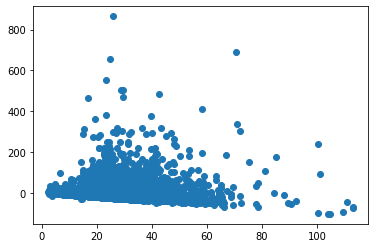

-0.08805942668535112
0.01263131668525121
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -5.969259 0.218254 -27.350 0.000000
## 0.557791 0.398402 1.400 0.161515
## -4.935332 2.078294 -2.375 0.017577
## 12069.422081 437.998081 27.556 0.000000
## ---
## Mean squared error: 50376.282998 , RMSE: 224.446615
## Multiple R-squared: 0.056362 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

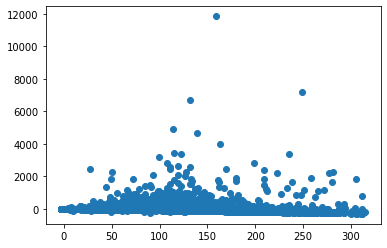

0.14530915177133377
0.08557363910206046
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.246935 0.042851 5.763 0.000000
## 0.576284 0.094743 6.083 0.000000
## -1.570140 0.384388 -4.085 0.000044
## -472.874165 85.846252 -5.508 0.000000
## ---
## Mean squared error: 1262.661007 , RMSE: 35.533942
## Multiple R-squared: 0.009256 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

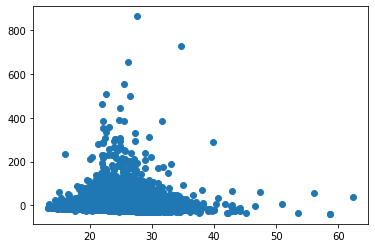

0.1502784492963474
0.10018711811878092
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -5.889146 0.178603 -32.973 0.000000
## 0.299112 0.276813 1.081 0.279910
## 0.370413 0.043379 8.539 0.000000
## 11897.471384 358.677620 33.170 0.000000
## ---
## Mean squared error: 43523.634744 , RMSE: 208.623188
## Multiple R-squared: 0.062125 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

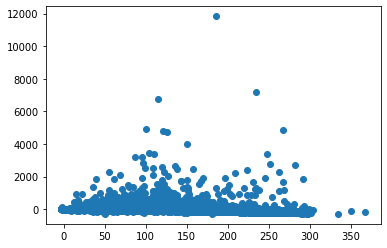

-0.0047062322191923165
0.009186124007451207
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.225531 0.035867 6.288 0.000000
## 0.354665 0.061446 5.772 0.000000
## 0.128224 0.007907 16.217 0.000000
## -432.843714 71.913641 -6.019 0.000000
## ---
## Mean squared error: 1154.376578 , RMSE: 33.976118
## Multiple R-squared: 0.026489 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

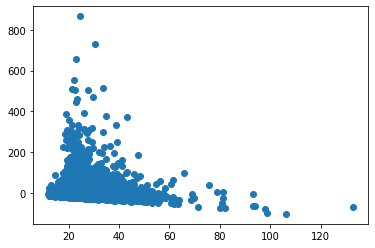

0.052193351694638644
0.023920025289564877
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -5.875963 0.206586 -28.443 0.000000
## 0.262639 0.328260 0.800 0.423668
## 11.684774 0.989773 11.806 0.000000
## 11854.510301 414.700242 28.586 0.000000
## ---
## Mean squared error: 49807.271345 , RMSE: 223.175427
## Multiple R-squared: 0.059736 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

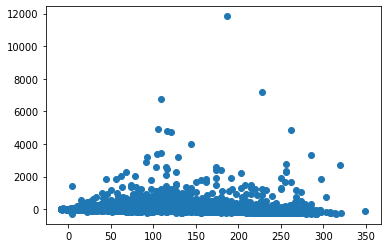

-0.020796754913710344
0.008524964887882859
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.322020 0.037843 8.509 0.000000
## 0.312921 0.063603 4.920 0.000001
## 3.806582 0.168606 22.577 0.000000
## -631.599427 75.863467 -8.325 0.000000
## ---
## Mean squared error: 1187.681028 , RMSE: 34.462748
## Multiple R-squared: 0.048274 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

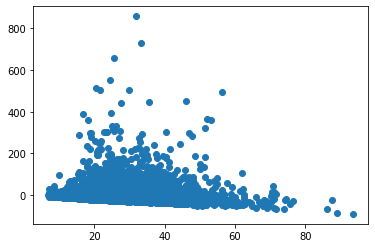

0.02453850374099052
0.016645325325317917
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -5.930804 0.221904 -26.727 0.000000
## 0.296491 0.340617 0.870 0.384068
## -7.455160 2.588190 -2.880 0.003977
## 11993.018422 445.541659 26.918 0.000000
## ---
## Mean squared error: 51781.880691 , RMSE: 227.556324
## Multiple R-squared: 0.054670 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

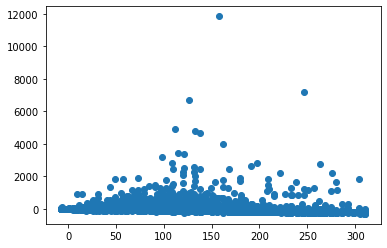

0.102319859433292
0.06502319832492458
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.260939 0.043123 6.051 0.000000
## 0.408396 0.080770 5.056 0.000000
## -1.229880 0.480143 -2.561 0.010437
## -500.687689 86.434962 -5.793 0.000000
## ---
## Mean squared error: 1266.009856 , RMSE: 35.581032
## Multiple R-squared: 0.007874 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

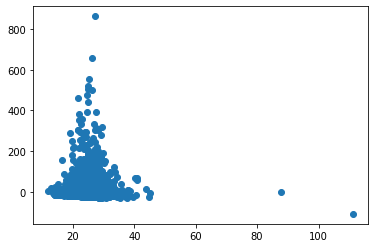

0.09312150423354729
0.06002310817762864
MEDI

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.457912 0.206775 -55.413 0.000000
## 1.404326 0.127498 11.014 0.000000
## 40.609897 1.335493 30.408 0.000000
## 23092.514039 415.201803 55.618 0.000000
## ---
## Mean squared error: 314713.150053 , RMSE: 560.993004
## Multiple R-squared: 0.048529 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

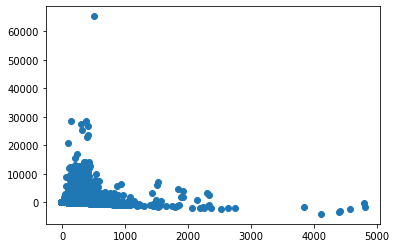

0.08427394140817147
0.4670463044721092
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.486811 0.076604 6.355 0.000000
## 0.789081 0.041389 19.065 0.000000
## 23.982913 0.467902 51.256 0.000000
## -967.950113 153.613052 -6.301 0.000000
## ---
## Mean squared error: 29513.416206 , RMSE: 171.794692
## Multiple R-squared: 0.067766 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

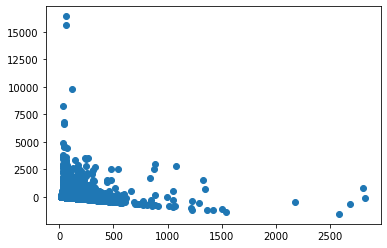

0.10142672776295439
0.448989393882258
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.565676 0.207651 -55.698 0.000000
## 1.425292 0.134223 10.619 0.000000
## 9.160663 0.372131 24.617 0.000000
## 23339.844043 416.985101 55.973 0.000000
## ---
## Mean squared error: 315864.995903 , RMSE: 562.018679
## Multiple R-squared: 0.045047 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

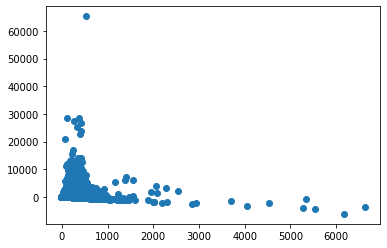

0.11585765075183241
0.5413360586449194
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.412768 0.077079 5.355 0.000000
## 0.722120 0.043224 16.707 0.000000
## 6.088871 0.132586 45.924 0.000000
## -802.397948 154.579473 -5.191 0.000000
## ---
## Mean squared error: 29728.948734 , RMSE: 172.420848
## Multiple R-squared: 0.060958 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

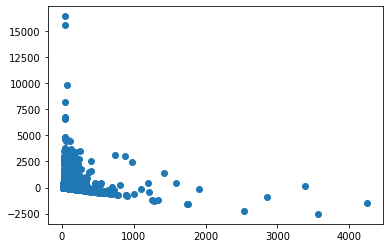

0.12879518524271452
0.513354108387136
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.021131 0.211229 -52.176 0.000000
## 3.216893 0.113751 28.280 0.000000
## 19.387049 8.006728 2.421 0.015465
## 22252.260754 425.076329 52.349 0.000000
## ---
## Mean squared error: 318057.205941 , RMSE: 563.965607
## Multiple R-squared: 0.038419 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

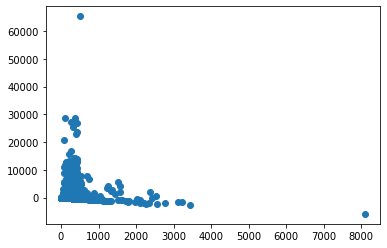

-0.18990803656430352
-0.06961093023367093
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.817386 0.078893 10.361 0.000000
## 1.739217 0.037830 45.975 0.000000
## 9.621061 2.783145 3.457 0.000547
## -1607.630890 158.510048 -10.142 0.000000
## ---
## Mean squared error: 30634.332391 , RMSE: 175.026662
## Multiple R-squared: 0.032360 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

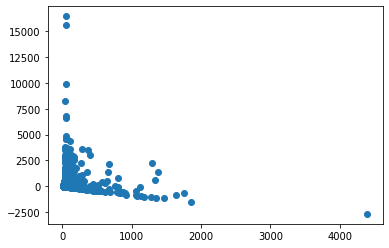

-0.16759342409440509
-0.06738061920804862
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.716380 0.165951 -58.550 0.000000
## 2.743332 0.104924 26.146 0.000000
## 3.075969 0.046479 66.180 0.000000
## 19606.721601 333.312605 58.824 0.000000
## ---
## Mean squared error: 272208.499053 , RMSE: 521.736043
## Multiple R-squared: 0.070507 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

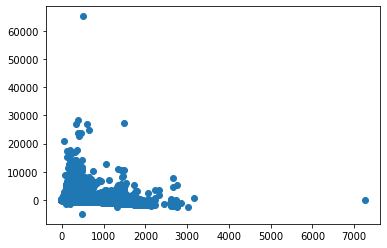

-0.11746882603931506
0.0410783479484818
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.851487 0.058496 14.556 0.000000
## 1.604790 0.033813 47.461 0.000000
## 0.872724 0.014069 62.032 0.000000
## -1682.776774 117.349112 -14.340 0.000000
## ---
## Mean squared error: 24037.935120 , RMSE: 155.041721
## Multiple R-squared: 0.061553 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

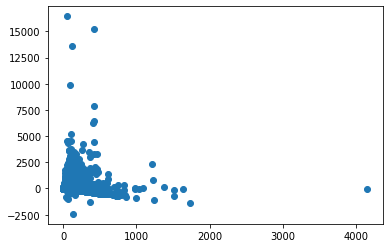

-0.07965235051798972
0.04478328220054663
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.224196 0.202066 -40.700 0.000000
## 2.332543 0.117724 19.814 0.000000
## 80.851334 0.979999 82.501 0.000000
## 16493.440063 405.779091 40.646 0.000000
## ---
## Mean squared error: 317998.428839 , RMSE: 563.913494
## Multiple R-squared: 0.089994 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

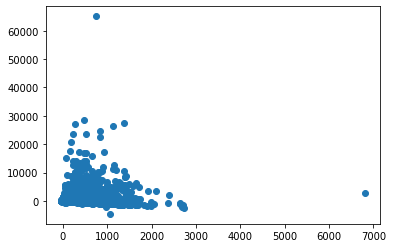

-0.14061743604392207
0.0771920915413727
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.489357 0.063546 23.438 0.000000
## 1.441374 0.035192 40.957 0.000000
## 23.151294 0.284173 81.469 0.000000
## -2995.938714 127.501328 -23.497 0.000000
## ---
## Mean squared error: 25416.545196 , RMSE: 159.425673
## Multiple R-squared: 0.092566 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

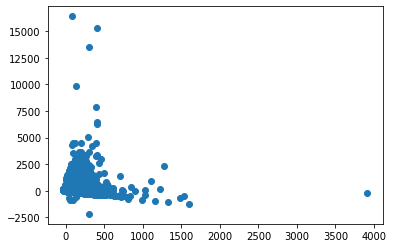

-0.10709201400763024
0.08185208604289085
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.917172 0.174116 -62.701 0.000000
## 3.141569 0.110223 28.502 0.000000
## -10.546879 1.698136 -6.211 0.000000
## 22057.997573 349.513704 63.111 0.000000
## ---
## Mean squared error: 250863.245330 , RMSE: 500.862501
## Multiple R-squared: 0.044453 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

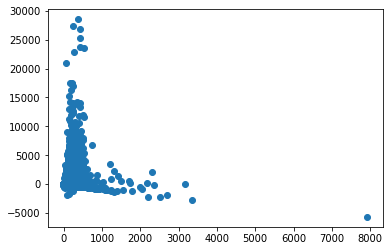

0.1508633018588544
0.02632291688470013
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.593193 0.057179 10.374 0.000000
## 1.753588 0.032249 54.377 0.000000
## -3.785056 0.521354 -7.260 0.000000
## -1152.472119 114.634391 -10.053 0.000000
## ---
## Mean squared error: 18303.143286 , RMSE: 135.289110
## Multiple R-squared: 0.038418 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

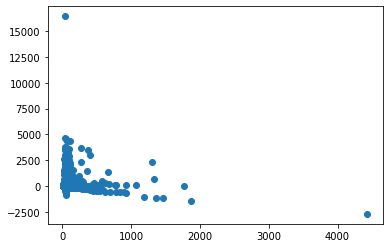

0.15352857760229213
0.022599757297946964
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.798290 0.161623 -66.812 0.000000
## 3.178163 0.101102 31.435 0.000000
## 1.021633 0.027940 36.565 0.000000
## 21785.836359 324.631591 67.109 0.000000
## ---
## Mean squared error: 263928.384225 , RMSE: 513.739607
## Multiple R-squared: 0.051179 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

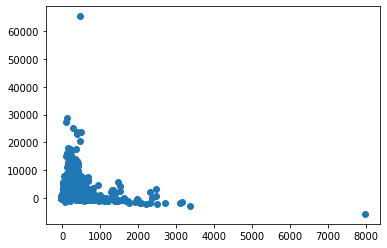

-0.046385925354741585
0.03442524140188391
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.488167 0.059247 8.240 0.000000
## 1.736996 0.033148 52.402 0.000000
## 0.354887 0.008897 39.889 0.000000
## -953.362048 118.843202 -8.022 0.000000
## ---
## Mean squared error: 24455.889619 , RMSE: 156.383790
## Multiple R-squared: 0.044317 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

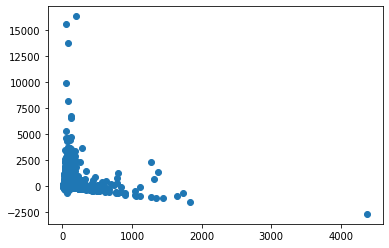

0.011351138505361137
0.03476411842060284
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.652734 0.181052 -58.838 0.000000
## 3.050853 0.108279 28.176 0.000000
## 34.535168 0.652191 52.953 0.000000
## 21426.879843 363.578362 58.933 0.000000
## ---
## Mean squared error: 289847.377346 , RMSE: 538.374755
## Multiple R-squared: 0.060729 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

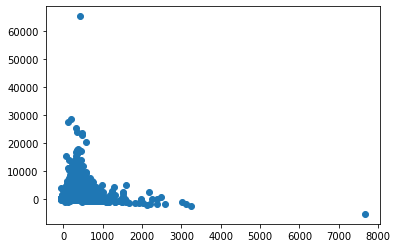

-0.046504564670865625
0.05642862988306895
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.644490 0.062442 10.321 0.000000
## 1.671491 0.034014 49.142 0.000000
## 11.773021 0.202937 58.013 0.000000
## -1289.985206 125.233473 -10.301 0.000000
## ---
## Mean squared error: 25309.378141 , RMSE: 159.089214
## Multiple R-squared: 0.062912 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

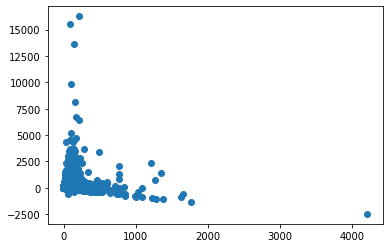

0.015801685422574305
0.058200178217683106
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.015104 0.183490 -60.031 0.000000
## 2.936419 0.111369 26.367 0.000000
## 0.168884 2.094460 0.081 0.935733
## 22248.562611 368.445413 60.385 0.000000
## ---
## Mean squared error: 270119.977087 , RMSE: 519.730677
## Multiple R-squared: 0.040103 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

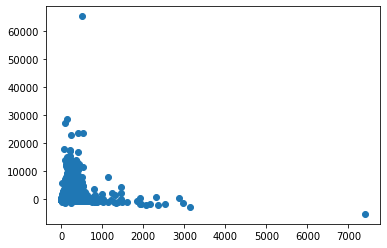

0.10864396279529312
0.03042208361106398
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.612009 0.065438 9.353 0.000000
## 1.582239 0.035268 44.863 0.000000
## -1.023261 0.709564 -1.442 0.149278
## -1190.510888 131.234921 -9.072 0.000000
## ---
## Mean squared error: 23227.964081 , RMSE: 152.407231
## Multiple R-squared: 0.027317 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

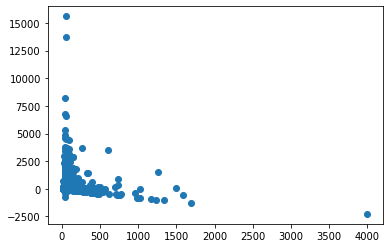

0.09325371515400066
0.03170627195445867
ECON

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -23.614650 1.164941 -20.271 0.000000
## 14.433769 7.756384 1.861 0.062842
## -9.709195 16.062850 -0.604 0.545583
## 47628.195949 2334.152183 20.405 0.000000
## ---
## Mean squared error: 409857.068277 , RMSE: 640.200803
## Multiple R-squared: 0.107167 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

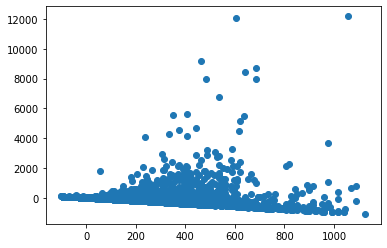

0.1712890830332954
0.4128171110065305
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.308226 0.114761 2.686 0.007279
## 1.652968 0.718024 2.302 0.021404
## 1.637090 1.488756 1.100 0.271587
## -596.469096 229.631731 -2.598 0.009441
## ---
## Mean squared error: 2465.892163 , RMSE: 49.657750
## Multiple R-squared: 0.008172 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

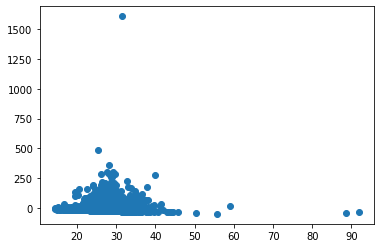

0.19279573885285334
0.4131297057975494
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -23.781812 1.164292 -20.426 0.000000
## 4.100999 9.402094 0.436 0.662733
## 16.253187 11.655167 1.395 0.163252
## 47942.850772 2333.366991 20.547 0.000000
## ---
## Mean squared error: 409675.652747 , RMSE: 640.059101
## Multiple R-squared: 0.107563 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

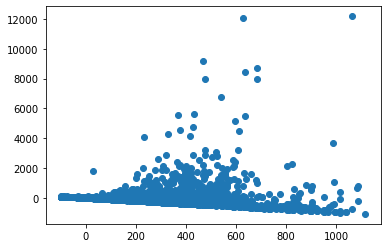

0.22110558703699634
0.6688810195834601
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.280424 0.114530 2.448 0.014408
## 0.038858 0.885292 0.044 0.964993
## 3.614238 1.109028 3.259 0.001132
## -541.735063 229.240126 -2.363 0.018188
## ---
## Mean squared error: 2457.470294 , RMSE: 49.572879
## Multiple R-squared: 0.011559 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

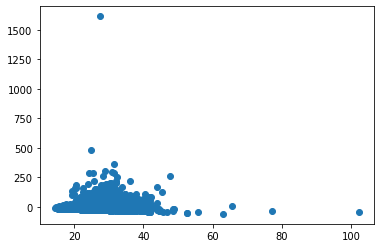

0.22851400586123052
0.6820186434302955
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -23.778318 1.171929 -20.290 0.000000
## 10.748492 7.612663 1.412 0.158060
## -31.920192 44.633306 -0.715 0.474554
## 47976.035030 2354.902632 20.373 0.000000
## ---
## Mean squared error: 409840.278587 , RMSE: 640.187690
## Multiple R-squared: 0.107204 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

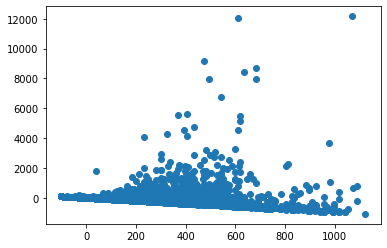

-0.2149249007556375
-0.3789034466709194
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.336665 0.114861 2.931 0.003406
## 2.181361 0.700447 3.114 0.001863
## 3.858449 3.979971 0.969 0.332398
## -655.399720 230.462420 -2.844 0.004490
## ---
## Mean squared error: 2466.134029 , RMSE: 49.660186
## Multiple R-squared: 0.008074 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

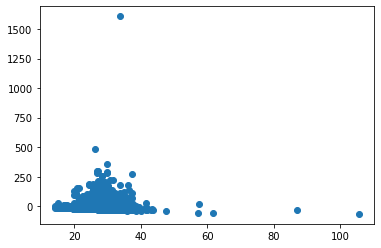

-0.18909714060544658
-0.35458980165792436
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -25.440915 1.355646 -18.767 0.000000
## 9.126193 7.352158 1.241 0.214543
## 5.021169 0.530735 9.461 0.000000
## 51263.802291 2717.242286 18.866 0.000000
## ---
## Mean squared error: 936247.765821 , RMSE: 967.598970
## Multiple R-squared: 0.073525 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

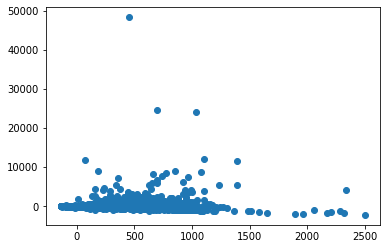

-0.10878483263059607
-0.021678616720781065
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.478075 0.082848 5.770 0.000000
## 1.250357 0.448686 2.787 0.005345
## 0.314749 0.027840 11.306 0.000000
## -936.333717 165.889462 -5.644 0.000000
## ---
## Mean squared error: 2296.475401 , RMSE: 47.921555
## Multiple R-squared: 0.032975 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

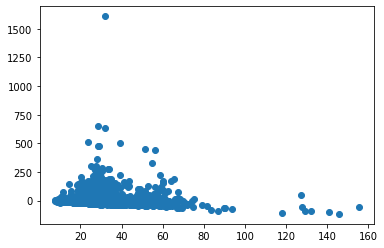

-0.07096501770663165
-0.0023439746083299953
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -25.325826 1.684112 -15.038 0.000000
## 9.284338 9.033949 1.028 0.304130
## 114.186664 9.129312 12.508 0.000000
## 50865.947021 3375.336568 15.070 0.000000
## ---
## Mean squared error: 1114583.772739 , RMSE: 1055.738496
## Multiple R-squared: 0.080796 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

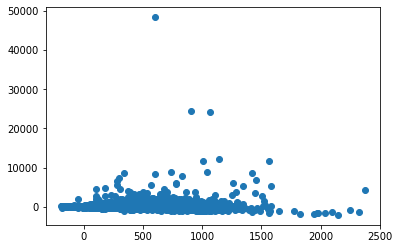

-0.15167055755889974
-0.0299503435412851
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.765986 0.088730 8.633 0.000000
## 1.014415 0.469698 2.160 0.030846
## 6.899393 0.437992 15.752 0.000000
## -1521.465008 177.711766 -8.561 0.000000
## ---
## Mean squared error: 2368.336739 , RMSE: 48.665560
## Multiple R-squared: 0.063452 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

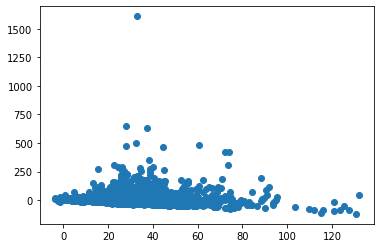

-0.11878898302232234
-0.007993433148965943
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -23.799232 1.051129 -22.642 0.000000
## 8.478204 6.035072 1.405 0.160129
## -15.239606 14.498961 -1.051 0.293266
## 48001.232735 2106.966823 22.782 0.000000
## ---
## Mean squared error: 532558.304992 , RMSE: 729.765925
## Multiple R-squared: 0.088776 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

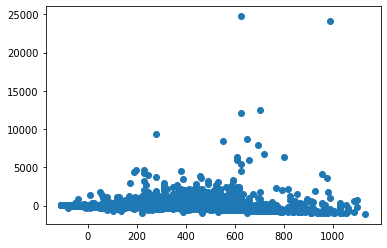

0.15306881870461705
0.1895187553418735
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.444687 0.086667 5.131 0.000000
## 1.458232 0.475380 3.068 0.002172
## -2.989310 1.164308 -2.567 0.010278
## -866.798372 173.515709 -4.996 0.000001
## ---
## Mean squared error: 2243.859731 , RMSE: 47.369397
## Multiple R-squared: 0.010705 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

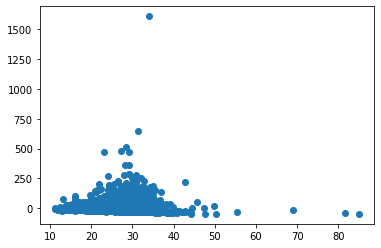

0.12054097788331233
0.1557166474755874
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -25.703341 1.356252 -18.952 0.000000
## 8.040567 7.356052 1.093 0.274411
## 4.436023 0.481606 9.211 0.000000
## 51798.262988 2718.273821 19.056 0.000000
## ---
## Mean squared error: 942427.393078 , RMSE: 970.786997
## Multiple R-squared: 0.072590 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

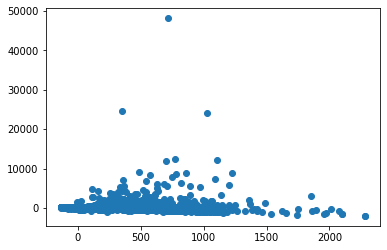

-0.08645171409508486
0.0033345272181956264
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.480836 0.082682 5.816 0.000000
## 1.171375 0.447358 2.618 0.008860
## 0.291516 0.025100 11.614 0.000000
## -941.540655 165.552348 -5.687 0.000000
## ---
## Mean squared error: 2282.744510 , RMSE: 47.778076
## Multiple R-squared: 0.034368 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

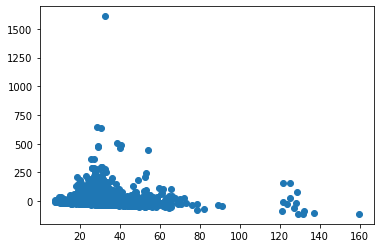

-0.06600434360822416
0.016519896071700797
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -26.259936 1.660318 -15.816 0.000000
## 8.235962 8.874339 0.928 0.353416
## 99.681317 8.630219 11.550 0.000000
## 52772.134192 3326.967649 15.862 0.000000
## ---
## Mean squared error: 1109782.048171 , RMSE: 1053.461935
## Multiple R-squared: 0.077640 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

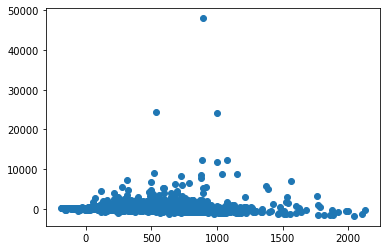

-0.11849660571288242
-0.003544746904154729
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.729800 0.088482 8.248 0.000000
## 0.931291 0.469460 1.984 0.047343
## 6.468726 0.417057 15.510 0.000000
## -1447.924373 177.202865 -8.171 0.000000
## ---
## Mean squared error: 2357.256702 , RMSE: 48.551588
## Multiple R-squared: 0.061176 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

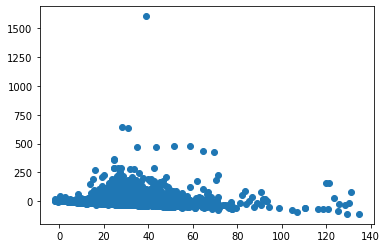

-0.10632087015931677
0.0122061727856786
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -26.696397 1.451677 -18.390 0.000000
## 12.890389 8.994621 1.433 0.151878
## -2.215250 21.417454 -0.103 0.917624
## 53824.381049 2909.244133 18.501 0.000000
## ---
## Mean squared error: 1021296.761265 , RMSE: 1010.592282
## Multiple R-squared: 0.059180 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

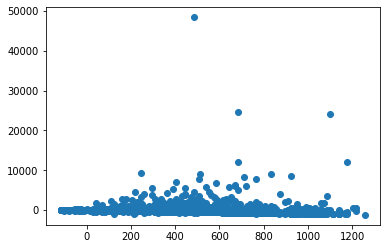

0.11566718603140753
0.1948737181633709
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.366575 0.089799 4.082 0.000045
## 1.855890 0.569252 3.260 0.001122
## -1.191773 1.260524 -0.945 0.344479
## -711.377007 179.733521 -3.958 0.000077
## ---
## Mean squared error: 2392.139780 , RMSE: 48.909506
## Multiple R-squared: 0.008125 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

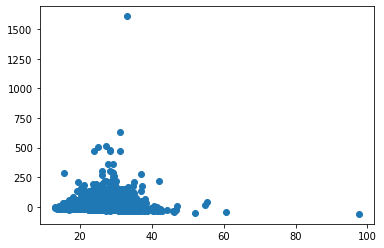

0.10683309182596902
0.1893779809382894
MATH

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.548420 0.529712 -19.913 0.000000
## 0.706202 0.132226 5.341 0.000000
## -27.176233 7.891033 -3.444 0.000577
## 21332.622521 1062.081413 20.086 0.000000
## ---
## Mean squared error: 236766.967163 , RMSE: 486.587060
## Multiple R-squared: 0.063243 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

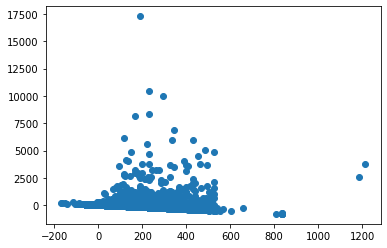

0.0641203151195191
0.9270556560849098
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.329799 0.074823 4.408 0.000011
## 0.175981 0.017710 9.937 0.000000
## -4.523219 1.078809 -4.193 0.000028
## -635.664941 149.758065 -4.245 0.000022
## ---
## Mean squared error: 3271.278747 , RMSE: 57.195094
## Multiple R-squared: 0.065569 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

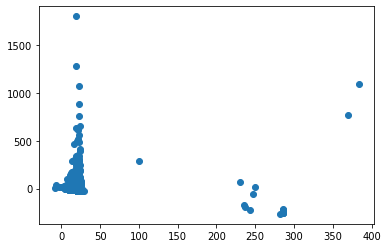

0.0813340274731589
0.9440823360946848
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.445053 0.529059 -19.743 0.000000
## 1.664873 0.277938 5.990 0.000000
## -17.355221 3.437048 -5.049 0.000000
## 21116.679346 1061.402658 19.895 0.000000
## ---
## Mean squared error: 236297.109676 , RMSE: 486.104011
## Multiple R-squared: 0.065102 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

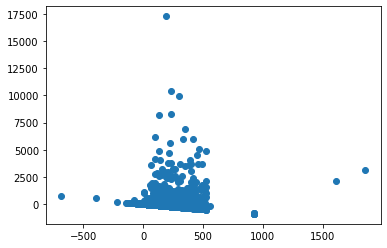

0.03963932647805597
0.9839630433470087
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.382689 0.073866 5.181 0.000000
## 0.489311 0.035013 13.975 0.000000
## -4.826453 0.434686 -11.103 0.000000
## -739.953077 147.961147 -5.001 0.000001
## ---
## Mean squared error: 3207.365819 , RMSE: 56.633610
## Multiple R-squared: 0.083825 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

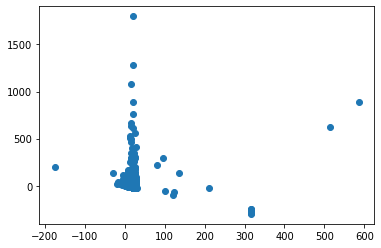

0.05589546592814281
0.9863049214414753
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.661105 0.540910 -19.710 0.000000
## 0.285863 0.049365 5.791 0.000000
## 21.441952 22.570525 0.950 0.342147
## 21504.860609 1089.968101 19.730 0.000000
## ---
## Mean squared error: 237145.904009 , RMSE: 486.976287
## Multiple R-squared: 0.061744 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

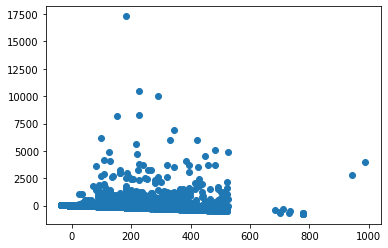

-0.235399195040479
-0.0506395677621805
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.279728 0.076122 3.675 0.000240
## 0.105714 0.005818 18.170 0.000000
## -1.044996 3.082123 -0.339 0.734585
## -540.773097 153.106985 -3.532 0.000416
## ---
## Mean squared error: 3282.084506 , RMSE: 57.289480
## Multiple R-squared: 0.062482 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

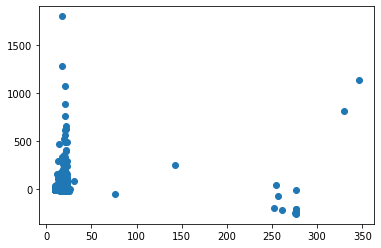

-0.2252584140810285
-0.06084849631828407
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -18.577420 0.868291 -21.395 0.000000
## 1.203868 0.362116 3.325 0.000887
## 4.504314 0.319372 14.104 0.000000
## 37498.030988 1744.556925 21.494 0.000000
## ---
## Mean squared error: 1356827.715749 , RMSE: 1164.829479
## Multiple R-squared: 0.038913 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

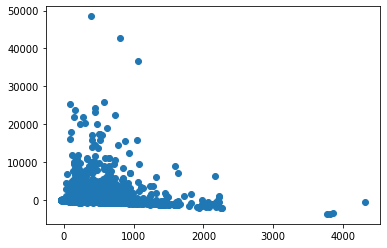

-0.09081736935373003
0.02728974561424423
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.269792 0.187488 6.773 0.000000
## 0.380369 0.065092 5.844 0.000000
## 0.515135 0.058899 8.746 0.000000
## -2513.358635 376.065223 -6.683 0.000000
## ---
## Mean squared error: 43263.455545 , RMSE: 207.998691
## Multiple R-squared: 0.011365 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

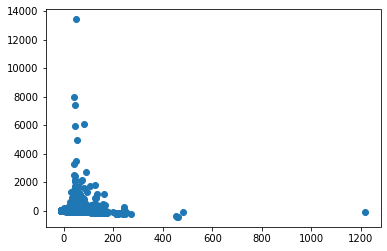

-0.04887125892571454
0.030109017101780777
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -16.910869 1.075314 -15.726 0.000000
## 1.166069 0.402956 2.894 0.003812
## 139.742686 6.429036 21.736 0.000000
## 33951.010612 2159.536507 15.721 0.000000
## ---
## Mean squared error: 1673892.419202 , RMSE: 1293.789944
## Multiple R-squared: 0.053867 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

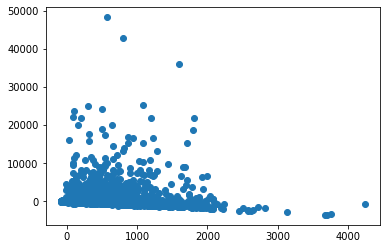

-0.10520558644997774
0.018429865295960586
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.774566 0.207083 8.569 0.000000
## 0.372272 0.068476 5.437 0.000000
## 16.908928 1.136459 14.879 0.000000
## -3548.687154 415.367613 -8.543 0.000000
## ---
## Mean squared error: 47875.618969 , RMSE: 218.804979
## Multiple R-squared: 0.025300 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

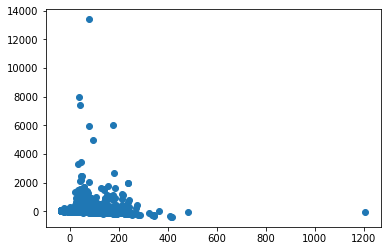

-0.07298868165881957
0.020562071624647217
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -19.151174 0.926455 -20.671 0.000000
## 1.313608 0.360601 3.643 0.000271
## -26.221611 16.544231 -1.585 0.113002
## 38705.357890 1860.487476 20.804 0.000000
## ---
## Mean squared error: 1342346.144017 , RMSE: 1158.596627
## Multiple R-squared: 0.030448 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

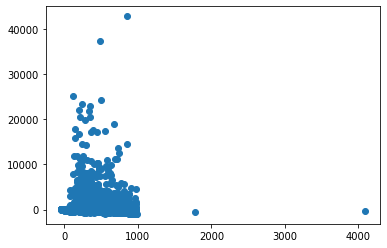

0.11329529562933029
0.0067957730446615355
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.342165 0.224329 5.983 0.000000
## 0.388674 0.071566 5.431 0.000000
## -8.599419 3.980528 -2.160 0.030766
## -2649.802782 449.717354 -5.892 0.000000
## ---
## Mean squared error: 52201.242127 , RMSE: 228.475911
## Multiple R-squared: 0.006329 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

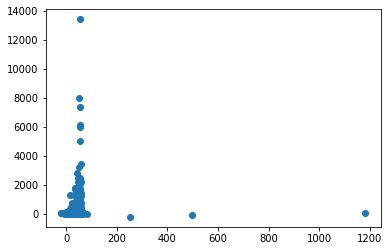

0.11506003510518538
0.004768757196067295
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -18.910547 0.838812 -22.544 0.000000
## 0.130112 0.123610 1.053 0.292536
## 3.666805 0.218478 16.783 0.000000
## 38155.268549 1685.299603 22.640 0.000000
## ---
## Mean squared error: 1284777.875968 , RMSE: 1133.480426
## Multiple R-squared: 0.042772 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

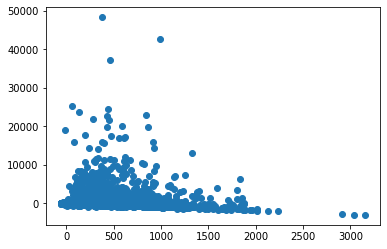

-0.025800075496933503
0.026565166712169366
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.142456 0.188094 6.074 0.000000
## 0.070637 0.022689 3.113 0.001854
## 0.532348 0.043073 12.359 0.000000
## -2260.603427 377.241512 -5.992 0.000000
## ---
## Mean squared error: 43192.478855 , RMSE: 207.828003
## Multiple R-squared: 0.014968 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

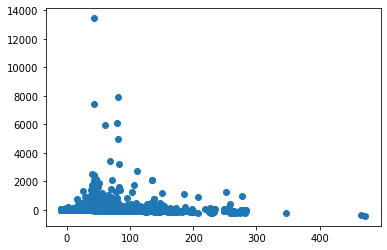

0.022290544550637344
0.027287219512648526
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -18.834894 0.976433 -19.289 0.000000
## 0.134370 0.133173 1.009 0.312996
## 115.888860 4.575983 25.325 0.000000
## 37809.811559 1960.691100 19.284 0.000000
## ---
## Mean squared error: 1491465.224538 , RMSE: 1221.255593
## Multiple R-squared: 0.063609 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

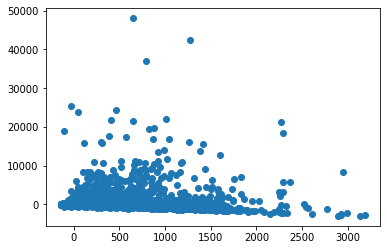

-0.01832693237605084
0.012800923673141024
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.392750 0.203193 6.854 0.000000
## 0.070634 0.023570 2.997 0.002734
## 15.832753 0.862978 18.347 0.000000
## -2787.288712 407.410563 -6.841 0.000000
## ---
## Mean squared error: 46624.623216 , RMSE: 215.927356
## Multiple R-squared: 0.031461 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

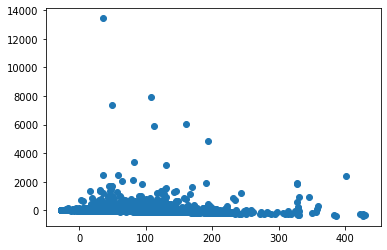

0.018401190559105347
0.012644529009795248
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -18.501688 0.946388 -19.550 0.000000
## 0.008879 0.137078 0.065 0.948354
## -7.241878 18.486575 -0.392 0.695258
## 37400.269901 1900.708325 19.677 0.000000
## ---
## Mean squared error: 1402498.811631 , RMSE: 1184.271427
## Multiple R-squared: 0.026258 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

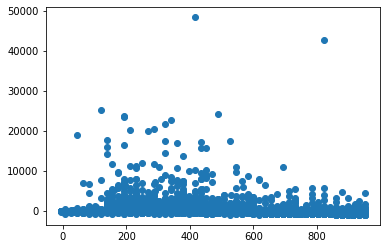

0.0973999410916813
-0.005626877953036412
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.215181 0.209571 5.798 0.000000
## 0.027617 0.024789 1.114 0.265261
## -2.969009 4.148225 -0.716 0.474174
## -2395.964513 420.171872 -5.702 0.000000
## ---
## Mean squared error: 45745.782500 , RMSE: 213.882637
## Multiple R-squared: 0.003285 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

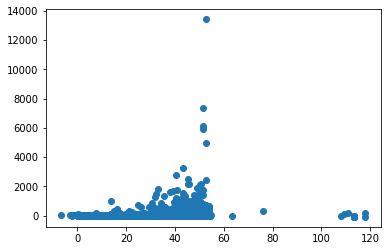

0.08624749200413197
-0.006755174388005121
MULT

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -33.618188 1.498419 -22.436 0.000000
## 4.063746 0.578421 7.026 0.000000
## 17.379298 10.101206 1.721 0.085358
## 67921.267354 3006.053963 22.595 0.000000
## ---
## Mean squared error: 3955556.653649 , RMSE: 1988.858128
## Multiple R-squared: 0.032860 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

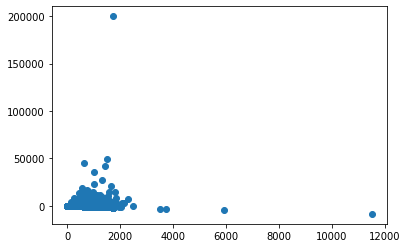

0.11954410720724222
0.3923214510804031
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.798801 0.237800 3.359 0.000784
## 1.863966 0.076582 24.340 0.000000
## 17.607228 1.546526 11.385 0.000000
## -1497.073834 476.235734 -3.144 0.001673
## ---
## Mean squared error: 66973.078802 , RMSE: 258.791574
## Multiple R-squared: 0.077554 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

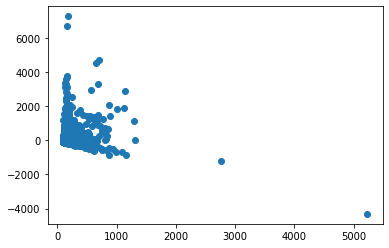

0.16655976680064932
0.3456839505722976
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -33.753975 1.497703 -22.537 0.000000
## 3.600039 0.620109 5.805 0.000000
## 6.868078 2.560963 2.682 0.007329
## 68203.480728 3005.557616 22.692 0.000000
## ---
## Mean squared error: 3954527.579901 , RMSE: 1988.599402
## Multiple R-squared: 0.033111 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

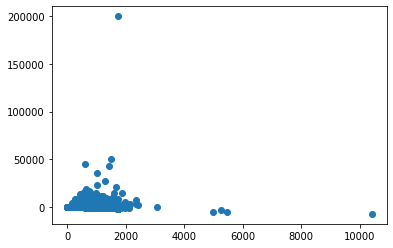

0.11775796079653014
0.5140411083946219
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.377454 0.235026 1.606 0.108296
## 1.250542 0.082186 15.216 0.000000
## 10.422935 0.472917 22.040 0.000000
## -653.035106 470.828203 -1.387 0.165468
## ---
## Mean squared error: 65190.985786 , RMSE: 255.325255
## Multiple R-squared: 0.102099 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

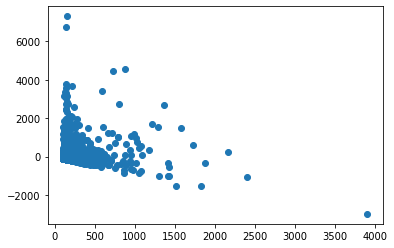

0.17864408154632444
0.5063839763241921
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -31.762220 1.540098 -20.623 0.000000
## 4.541000 0.533241 8.516 0.000000
## 276.230088 67.953496 4.065 0.000048
## 64063.251156 3101.465230 20.656 0.000000
## ---
## Mean squared error: 3952260.314724 , RMSE: 1988.029254
## Multiple R-squared: 0.033666 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

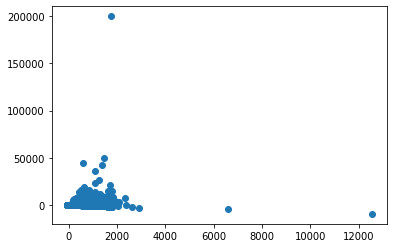

-0.25630531320873584
-0.05620147892293504
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.406165 0.242455 5.800 0.000000
## 2.170359 0.072476 29.946 0.000000
## 38.516246 10.003258 3.850 0.000119
## -2709.583420 487.292814 -5.560 0.000000
## ---
## Mean squared error: 67568.460575 , RMSE: 259.939340
## Multiple R-squared: 0.069353 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

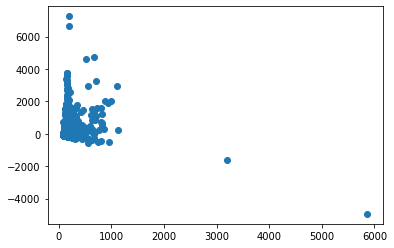

-0.22852512189466356
-0.06142684082338898
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -31.601500 1.364698 -23.156 0.000000
## 4.025160 0.485427 8.292 0.000000
## 6.060193 0.420897 14.398 0.000000
## 63788.811246 2741.880949 23.265 0.000000
## ---
## Mean squared error: 3247729.874901 , RMSE: 1802.145908
## Multiple R-squared: 0.048861 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

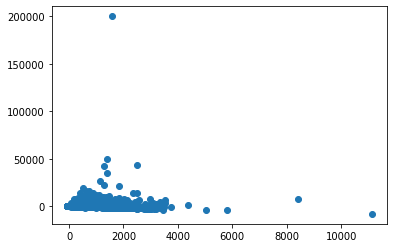

-0.2247830915215512
0.044561065334418705
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.093110 0.205648 -0.453 0.650726
## 2.101308 0.065571 32.046 0.000000
## 0.959675 0.055505 17.290 0.000000
## 283.276743 412.659242 0.686 0.492429
## ---
## Mean squared error: 55239.575390 , RMSE: 235.031009
## Multiple R-squared: 0.081432 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

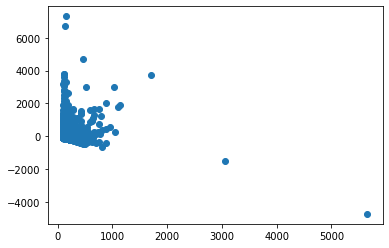

-0.19484565102785212
0.045599925337523065
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -27.825893 1.634762 -17.021 0.000000
## 3.185640 0.530640 6.003 0.000000
## 132.356817 7.278476 18.185 0.000000
## 55997.492688 3285.110647 17.046 0.000000
## ---
## Mean squared error: 3804527.319780 , RMSE: 1950.519756
## Multiple R-squared: 0.050852 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

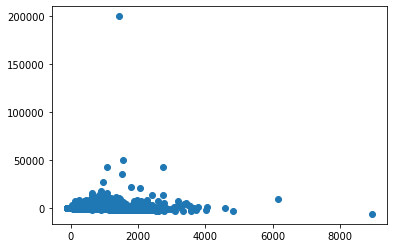

-0.25012906663879214
0.10373570019718838
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.405236 0.215950 6.507 0.000000
## 1.873505 0.066448 28.195 0.000000
## 28.517763 0.897229 31.784 0.000000
## -2770.382199 433.558169 -6.390 0.000000
## ---
## Mean squared error: 55830.195899 , RMSE: 236.284142
## Multiple R-squared: 0.123647 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

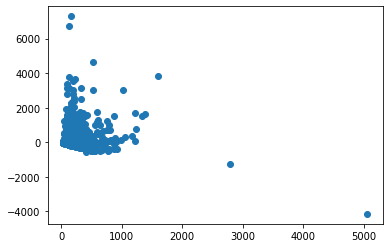

-0.21284350592039514
0.1083726188254582
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -35.518197 1.633831 -21.739 0.000000
## 4.198910 0.540111 7.774 0.000000
## -48.117225 18.185733 -2.646 0.008156
## 71756.847646 3279.244517 21.882 0.000000
## ---
## Mean squared error: 3934235.794089 , RMSE: 1983.490810
## Multiple R-squared: 0.035551 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

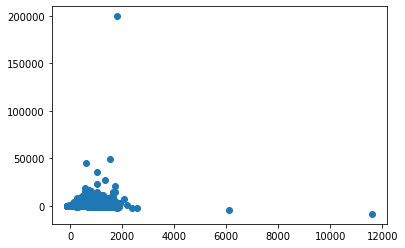

0.1743600494012309
0.019114806778072445
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.164430 0.226535 -0.726 0.467944
## 2.024568 0.065911 30.717 0.000000
## -16.577567 2.452810 -6.759 0.000000
## 448.470469 454.111338 0.988 0.323379
## ---
## Mean squared error: 54629.120574 , RMSE: 233.728733
## Multiple R-squared: 0.074966 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

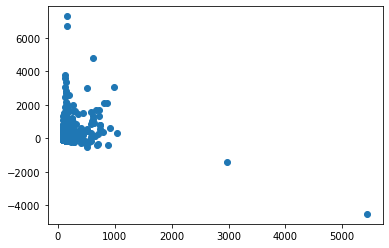

0.16525292877706327
0.019944318479833047
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -33.212153 1.303395 -25.481 0.000000
## 4.873834 0.510438 9.548 0.000000
## 2.090475 0.136981 15.261 0.000000
## 66990.403710 2618.622143 25.582 0.000000
## ---
## Mean squared error: 3116101.040852 , RMSE: 1765.248153
## Multiple R-squared: 0.051947 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

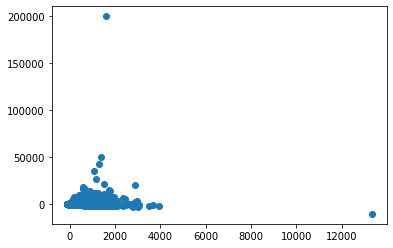

-0.1332502068190903
0.018025275353020377
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.439651 0.198366 -2.216 0.026681
## 2.401398 0.069794 34.407 0.000000
## 0.592413 0.018438 32.131 0.000000
## 958.190063 397.965956 2.408 0.016064
## ---
## Mean squared error: 53359.939926 , RMSE: 230.997705
## Multiple R-squared: 0.125901 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

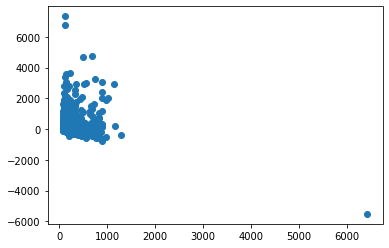

-0.0662330498133734
0.015642908908070748
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -32.189423 1.427551 -22.549 0.000000
## 4.570650 0.542274 8.429 0.000000
## 62.862429 3.587371 17.523 0.000000
## 64782.824807 2868.486329 22.584 0.000000
## ---
## Mean squared error: 3370203.866680 , RMSE: 1835.811501
## Multiple R-squared: 0.054065 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

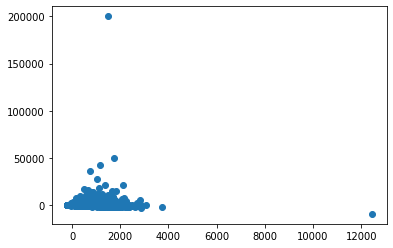

-0.15455562629833675
0.058176117032903776
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.052723 0.201956 0.261 0.794050
## 2.257391 0.069587 32.440 0.000000
## 18.913099 0.466904 40.507 0.000000
## -78.480573 405.233066 -0.194 0.846439
## ---
## Mean squared error: 52781.308557 , RMSE: 229.741830
## Multiple R-squared: 0.158668 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

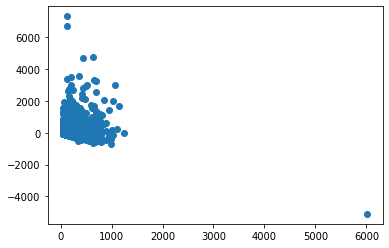

-0.0778467803712567
0.05483754962247855
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -37.078038 1.649347 -22.480 0.000000
## 4.921837 0.604378 8.144 0.000000
## -47.559730 22.473908 -2.116 0.034343
## 74870.887790 3311.607565 22.609 0.000000
## ---
## Mean squared error: 3941353.313388 , RMSE: 1985.284190
## Multiple R-squared: 0.037380 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

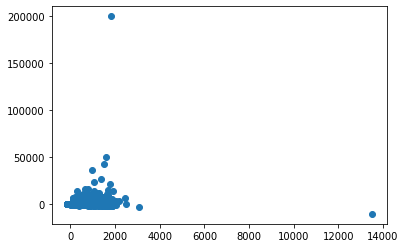

0.12114136233375093
0.0337033825925978
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.417712 0.237804 -1.757 0.079023
## 2.287399 0.076188 30.023 0.000000
## -16.711316 3.227785 -5.177 0.000000
## 952.035568 476.869233 1.996 0.045910
## ---
## Mean squared error: 59195.062979 , RMSE: 243.300355
## Multiple R-squared: 0.071828 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

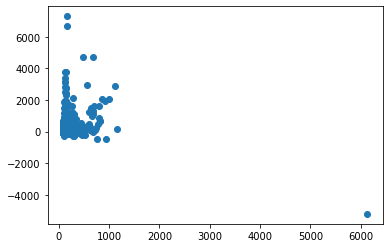

0.09916179108809386
0.03985199702323329
ENVI

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.179999 0.351129 -31.840 0.000000
## 1.703907 0.930900 1.830 0.067219
## 11.921702 2.937333 4.059 0.000050
## 22556.494338 705.564477 31.969 0.000000
## ---
## Mean squared error: 88091.601285 , RMSE: 296.802293
## Multiple R-squared: 0.085514 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

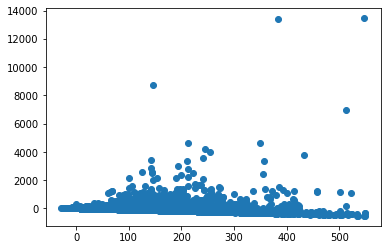

0.11488584732232512
0.5468181847338635
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.574803 0.076623 7.502 0.000000
## 1.792895 0.195821 9.156 0.000000
## 3.758135 0.642672 5.848 0.000000
## -1138.743591 153.678287 -7.410 0.000000
## ---
## Mean squared error: 2270.488223 , RMSE: 47.649640
## Multiple R-squared: 0.052073 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

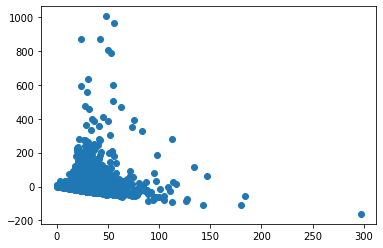

0.11806559061330708
0.5759863409695222
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.214502 0.350955 -31.954 0.000000
## -0.480563 1.153517 -0.417 0.676974
## 9.258889 1.856734 4.987 0.000001
## 22630.787334 705.177630 32.092 0.000000
## ---
## Mean squared error: 88025.438562 , RMSE: 296.690813
## Multiple R-squared: 0.086201 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

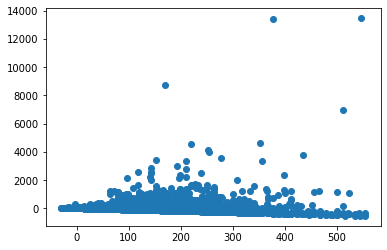

0.17858011977644359
0.7433439029235107
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.566138 0.076495 7.401 0.000000
## 1.073759 0.242633 4.425 0.000010
## 3.098432 0.410861 7.541 0.000000
## -1120.013104 153.414513 -7.301 0.000000
## ---
## Mean squared error: 2263.235505 , RMSE: 47.573475
## Multiple R-squared: 0.055101 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

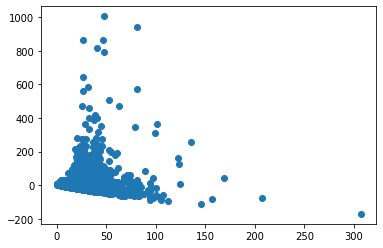

0.17198325258704558
0.7570139077201226
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.079824 0.358864 -30.875 0.000000
## 4.077873 0.810343 5.032 0.000000
## 19.244518 11.391855 1.689 0.091186
## 22350.365383 722.641052 30.929 0.000000
## ---
## Mean squared error: 88199.162965 , RMSE: 296.983439
## Multiple R-squared: 0.084397 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

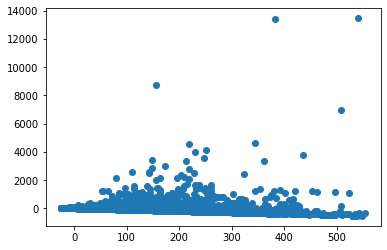

-0.2588391901176558
-0.2939277872033771
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.605437 0.077733 7.789 0.000000
## 2.560170 0.166224 15.402 0.000000
## 6.748311 2.273314 2.968 0.003003
## -1202.333112 156.152477 -7.700 0.000000
## ---
## Mean squared error: 2278.662106 , RMSE: 47.735334
## Multiple R-squared: 0.048660 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

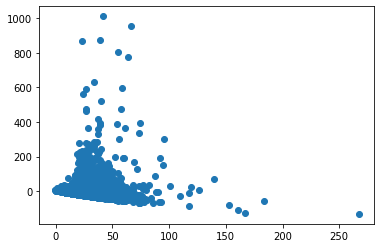

-0.20924437007148972
-0.27281120724547847
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.568123 0.198908 -48.103 0.000000
## 1.799516 0.339460 5.301 0.000000
## 1.663155 0.084982 19.571 0.000000
## 19315.851891 399.828198 48.310 0.000000
## ---
## Mean squared error: 87929.631723 , RMSE: 296.529310
## Multiple R-squared: 0.084548 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

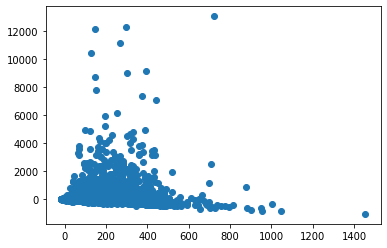

-0.11414915189776843
0.011348104755499985
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.659514 0.047897 13.769 0.000000
## 1.785838 0.098022 18.219 0.000000
## 0.264453 0.016662 15.872 0.000000
## -1304.923228 96.070910 -13.583 0.000000
## ---
## Mean squared error: 3015.469361 , RMSE: 54.913289
## Multiple R-squared: 0.039882 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

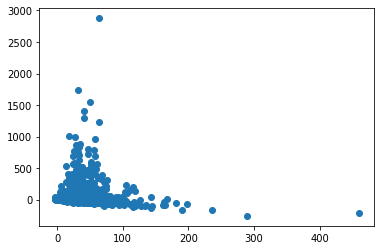

-0.052193294413971116
0.02469199124049387
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.997250 0.252474 -35.636 0.000000
## 1.430862 0.403189 3.549 0.000388
## 37.460123 1.398988 26.777 0.000000
## 18121.333136 507.360869 35.717 0.000000
## ---
## Mean squared error: 110432.678888 , RMSE: 332.314127
## Multiple R-squared: 0.084688 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

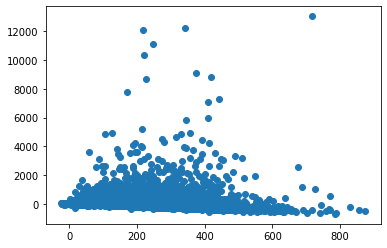

-0.13657095505100247
0.03646869054579032
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.938803 0.051248 18.319 0.000000
## 1.621026 0.102376 15.834 0.000000
## 6.751627 0.252886 26.698 0.000000
## -1873.447389 102.813380 -18.222 0.000000
## ---
## Mean squared error: 3149.354771 , RMSE: 56.119112
## Multiple R-squared: 0.067116 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

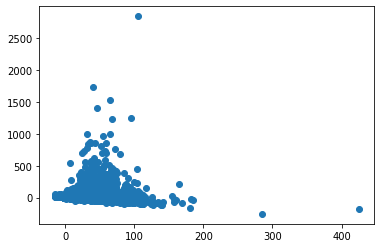

-0.08984391789224358
0.060569874987370376
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.454602 0.209795 -45.066 0.000000
## 1.985626 0.351802 5.644 0.000000
## -8.409501 2.091548 -4.021 0.000058
## 19103.249341 421.506294 45.321 0.000000
## ---
## Mean squared error: 82383.496075 , RMSE: 287.025253
## Multiple R-squared: 0.078716 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

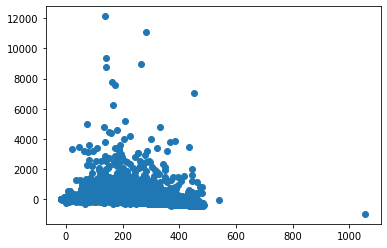

0.1286261867521559
0.07737618664076246
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.630872 0.054899 11.492 0.000000
## 1.915638 0.112504 17.027 0.000000
## -2.764587 0.519664 -5.320 0.000000
## -1244.014646 110.062011 -11.303 0.000000
## ---
## Mean squared error: 3231.856780 , RMSE: 56.849422
## Multiple R-squared: 0.029710 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

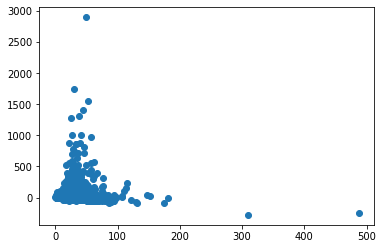

0.14328459720920003
0.10796759154419035
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.278116 0.200012 -51.388 0.000000
## 1.751340 0.347187 5.044 0.000000
## 0.623890 0.042578 14.653 0.000000
## 20748.032775 401.994758 51.613 0.000000
## ---
## Mean squared error: 91378.008754 , RMSE: 302.287957
## Multiple R-squared: 0.081196 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

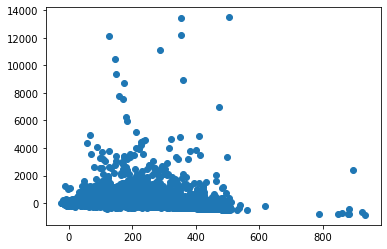

-0.0001846157946038064
0.030692202790393863
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.525546 0.046287 11.354 0.000000
## 1.726919 0.096322 17.929 0.000000
## 0.288600 0.008361 34.517 0.000000
## -1038.307288 92.823491 -11.186 0.000000
## ---
## Mean squared error: 2799.608117 , RMSE: 52.911323
## Multiple R-squared: 0.079171 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

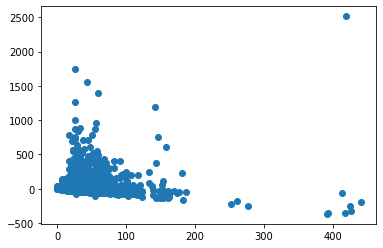

0.0570865766627776
0.03487129257617614
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.391405 0.233763 -44.453 0.000000
## 1.630949 0.391390 4.167 0.000031
## 19.292982 0.958579 20.127 0.000000
## 20945.436150 469.585807 44.604 0.000000
## ---
## Mean squared error: 107067.751975 , RMSE: 327.212090
## Multiple R-squared: 0.080367 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

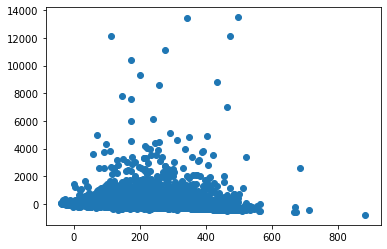

0.004101314806533174
0.04098951821616515
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.658238 0.048814 13.485 0.000000
## 1.659835 0.100176 16.569 0.000000
## 6.308928 0.179855 35.078 0.000000
## -1313.044923 97.870740 -13.416 0.000000
## ---
## Mean squared error: 2926.669221 , RMSE: 54.098699
## Multiple R-squared: 0.087053 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

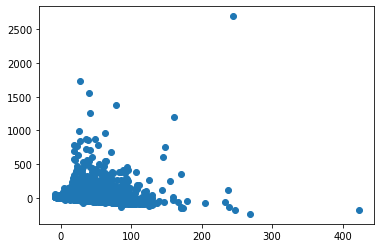

0.050248978862182284
0.051356619982827804
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.204298 0.235392 -43.350 0.000000
## 1.798120 0.401473 4.479 0.000008
## -2.410773 2.764463 -0.872 0.383185
## 20610.451019 473.009473 43.573 0.000000
## ---
## Mean squared error: 104311.462079 , RMSE: 322.972850
## Multiple R-squared: 0.071212 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

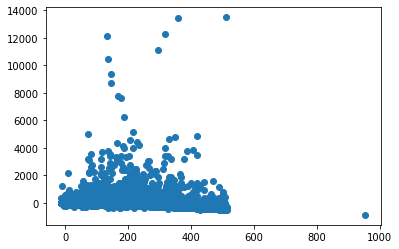

0.08688587560567818
0.05728371273995418
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.603691 0.054342 11.109 0.000000
## 1.713537 0.111247 15.403 0.000000
## -0.892457 0.611986 -1.458 0.144778
## -1189.734612 108.960336 -10.919 0.000000
## ---
## Mean squared error: 3183.595851 , RMSE: 56.423363
## Multiple R-squared: 0.025924 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

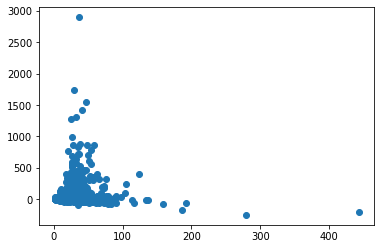

0.08606385124731777
0.07689282769822924
DECI

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -34.725300 4.510803 -7.698 0.000000
## 26.023013 24.071386 1.081 0.279860
## -25.939478 68.917267 -0.376 0.706691
## 70035.869727 9044.600745 7.743 0.000000
## ---
## Mean squared error: 2532579.846642 , RMSE: 1591.408133
## Multiple R-squared: 0.043656 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

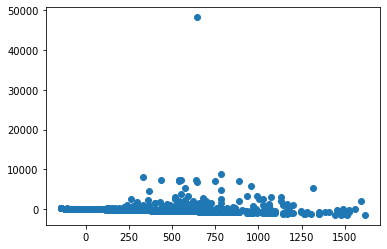

0.14085988204687291
0.44572939955973323
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.165589 0.211704 0.782 0.434301
## 3.616242 1.138328 3.177 0.001535
## 1.721399 3.172745 0.543 0.587555
## -313.767867 423.979958 -0.740 0.459441
## ---
## Mean squared error: 3658.791117 , RMSE: 60.487942
## Multiple R-squared: 0.017409 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

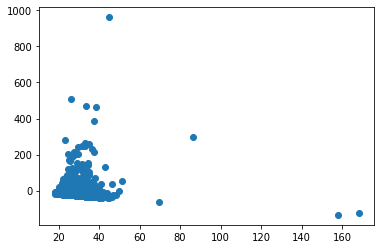

0.1259388256625674
0.49107741679973593
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -34.860555 4.504457 -7.739 0.000000
## 1.268119 33.550909 0.038 0.969855
## 40.617704 49.765401 0.816 0.414542
## 70251.909297 9034.815216 7.776 0.000000
## ---
## Mean squared error: 2531574.818743 , RMSE: 1591.092335
## Multiple R-squared: 0.044035 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

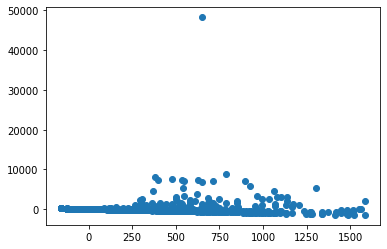

0.17478000411980527
0.7701773323962452
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.170036 0.211485 0.804 0.421583
## 3.532490 1.565838 2.256 0.024287
## 0.726311 2.300454 0.316 0.752277
## -321.496193 423.659304 -0.759 0.448118
## ---
## Mean squared error: 3659.502654 , RMSE: 60.493823
## Multiple R-squared: 0.017218 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

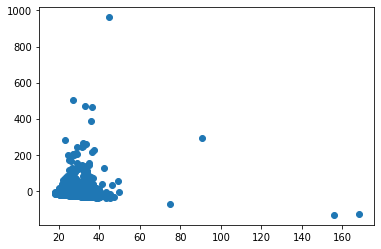

0.14054667199250523
0.7754797089523051
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -35.105304 4.555265 -7.707 0.000000
## 19.639689 22.479704 0.874 0.382461
## -74.468494 171.398492 -0.434 0.664014
## 70832.432030 9159.035295 7.734 0.000000
## ---
## Mean squared error: 2532489.555228 , RMSE: 1591.379765
## Multiple R-squared: 0.043690 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

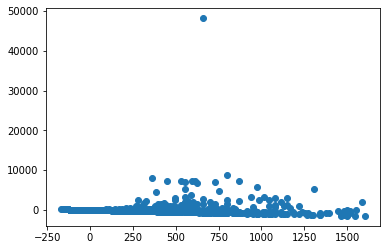

-0.20084047411705497
-0.28735345672641704
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.199524 0.212838 0.937 0.348757
## 4.188487 1.031296 4.061 0.000053
## 7.893047 7.519876 1.050 0.294144
## -386.671160 427.231387 -0.905 0.365650
## ---
## Mean squared error: 3655.843416 , RMSE: 60.463571
## Multiple R-squared: 0.018200 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

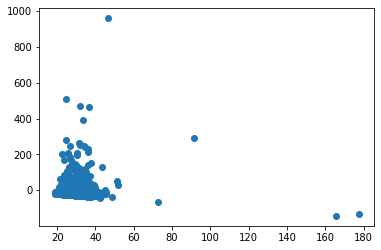

-0.1575810554909799
-0.27213954527216927
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -27.863506 1.972627 -14.125 0.000000
## 7.937421 7.889241 1.006 0.314421
## 3.739861 0.780747 4.790 0.000002
## 56186.508324 3958.638359 14.193 0.000000
## ---
## Mean squared error: 1321600.302039 , RMSE: 1149.608760
## Multiple R-squared: 0.055940 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

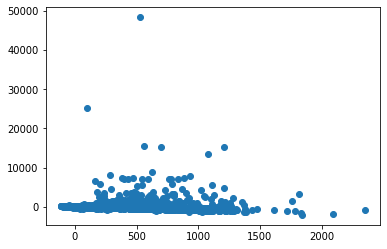

-0.13681172829768254
0.018401798454353732
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.388779 0.518345 2.679 0.007416
## 2.571112 2.003883 1.283 0.199562
## 0.282328 0.171973 1.642 0.100749
## -2757.101544 1038.917104 -2.654 0.007998
## ---
## Mean squared error: 60025.424111 , RMSE: 245.000866
## Multiple R-squared: 0.004018 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

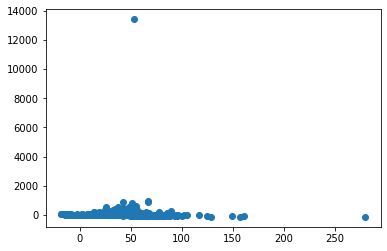

-0.0893863123581031
0.05495684633636161
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -27.381558 2.454392 -11.156 0.000000
## 4.854124 9.419796 0.515 0.606369
## 92.704421 13.337281 6.951 0.000000
## 55094.325087 4925.554537 11.185 0.000000
## ---
## Mean squared error: 1616472.221179 , RMSE: 1271.405608
## Multiple R-squared: 0.057438 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

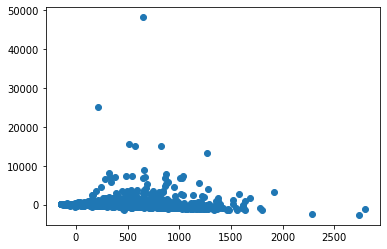

-0.16533683277080594
0.04638006509785436
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.834280 0.564053 3.252 0.001159
## 2.021661 2.121288 0.953 0.340650
## 8.623652 2.762099 3.122 0.001813
## -3660.504389 1130.925635 -3.237 0.001222
## ---
## Mean squared error: 64965.893239 , RMSE: 254.884078
## Multiple R-squared: 0.007175 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

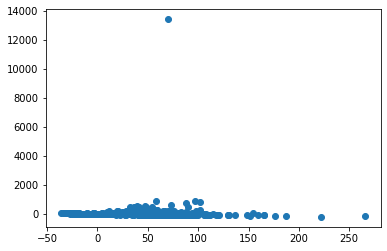

-0.13160004149670051
0.07625962880017044
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -27.206052 1.546040 -17.597 0.000000
## 17.370690 7.754314 2.240 0.025144
## -7.402746 20.848280 -0.355 0.722553
## 54867.211187 3099.932859 17.699 0.000000
## ---
## Mean squared error: 708562.510709 , RMSE: 841.761552
## Multiple R-squared: 0.083249 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

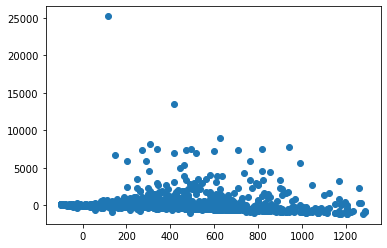

0.14002289689963035
0.14432985997858877
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.354955 0.617527 2.194 0.028311
## 5.327494 3.184049 1.673 0.094410
## -8.297649 8.285896 -1.001 0.316717
## -2690.151107 1236.632570 -2.175 0.029690
## ---
## Mean squared error: 72204.259295 , RMSE: 268.708502
## Multiple R-squared: 0.003790 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

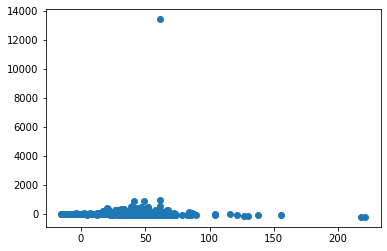

0.12361344157129726
0.14454202385456777
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -26.432286 1.899417 -13.916 0.000000
## -1.738718 7.741274 -0.225 0.822298
## 5.039427 0.587146 8.583 0.000000
## 53310.185661 3811.096428 13.988 0.000000
## ---
## Mean squared error: 1248370.873798 , RMSE: 1117.305184
## Multiple R-squared: 0.064155 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

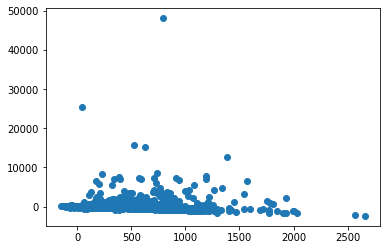

-0.04133739437169488
0.13537662593041955
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.397270 0.518759 2.693 0.007108
## 2.147010 2.021470 1.062 0.288269
## 0.304500 0.146627 2.077 0.037909
## -2773.593558 1039.637553 -2.668 0.007672
## ---
## Mean squared error: 60036.572351 , RMSE: 245.023616
## Multiple R-squared: 0.004573 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

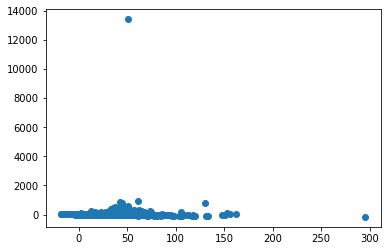

-0.030318706208054557
0.13511705127578064
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -26.557292 2.227993 -11.920 0.000000
## -2.905017 8.824742 -0.329 0.742031
## 115.207523 10.911561 10.558 0.000000
## 53391.370957 4469.347291 11.946 0.000000
## ---
## Mean squared error: 1454369.719710 , RMSE: 1205.972520
## Multiple R-squared: 0.071617 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

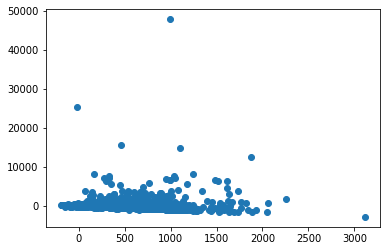

-0.051600620294788346
0.10499162543955663
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.642301 0.555053 2.959 0.003112
## 2.119757 2.109814 1.005 0.315117
## 5.648390 2.496341 2.263 0.023728
## -3270.702396 1112.469111 -2.940 0.003307
## ---
## Mean squared error: 64391.203275 , RMSE: 253.754218
## Multiple R-squared: 0.005504 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

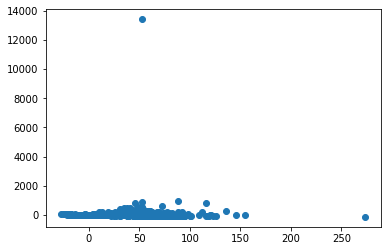

-0.05050494216425339
0.09097572725984289
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -27.553826 2.121949 -12.985 0.000000
## 8.766525 8.512492 1.030 0.303154
## -17.478435 32.317869 -0.541 0.588660
## 55602.140703 4257.762751 13.059 0.000000
## ---
## Mean squared error: 1389169.145683 , RMSE: 1178.630199
## Multiple R-squared: 0.046971 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

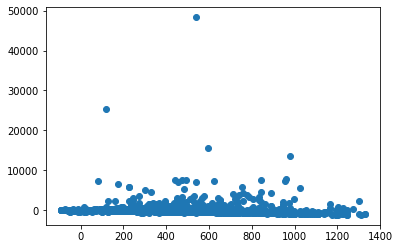

0.05476794651521586
0.0923690403028892
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.450836 0.619345 2.343 0.019229
## 3.066495 2.314349 1.325 0.185291
## -2.938980 9.030105 -0.325 0.744856
## -2877.907446 1241.034615 -2.319 0.020475
## ---
## Mean squared error: 73623.226030 , RMSE: 271.336002
## Multiple R-squared: 0.003387 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

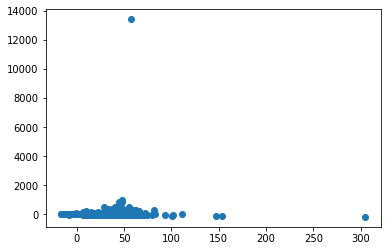

0.04688566162547391
0.09197483527305873
AGRI

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.241120 0.265956 -34.747 0.000000
## 0.467714 0.599592 0.780 0.435364
## 12.016591 2.517938 4.772 0.000002
## 18648.917982 534.043677 34.920 0.000000
## ---
## Mean squared error: 273774.198174 , RMSE: 523.234363
## Multiple R-squared: 0.023828 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

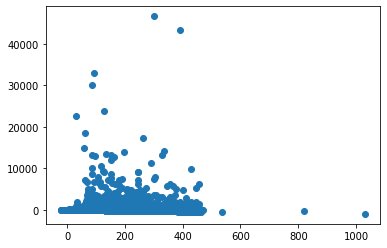

0.13342029237480577
0.5939053893676751
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.453440 0.122270 3.709 0.000209
## 0.682823 0.289182 2.361 0.018220
## 5.370094 1.145258 4.689 0.000003
## -893.278679 245.055995 -3.645 0.000268
## ---
## Mean squared error: 35647.851996 , RMSE: 188.806388
## Multiple R-squared: 0.002277 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

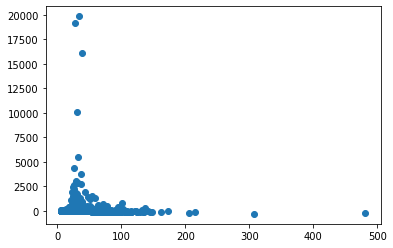

0.15288743080794603
0.5473032843613043
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.216545 0.266191 -34.624 0.000000
## 0.613740 0.841357 0.729 0.465721
## 2.887468 1.299333 2.222 0.026269
## 18609.584098 534.510915 34.816 0.000000
## ---
## Mean squared error: 273870.225750 , RMSE: 523.326118
## Multiple R-squared: 0.023485 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

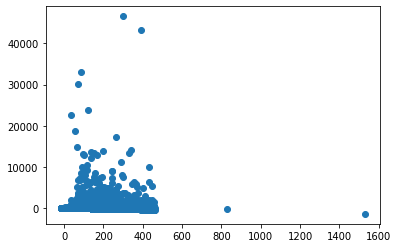

0.16141027196324453
0.8206414815199138
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.454294 0.122302 3.715 0.000204
## 0.509981 0.368853 1.383 0.166792
## 2.058014 0.634812 3.242 0.001188
## -891.244517 245.129886 -3.636 0.000277
## ---
## Mean squared error: 35658.927176 , RMSE: 188.835715
## Multiple R-squared: 0.001967 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

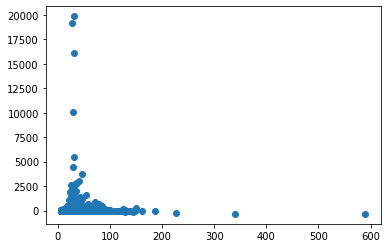

0.20733128780719945
0.7601844028055441
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.779849 0.273175 -32.140 0.000000
## 2.757100 0.493883 5.582 0.000000
## 68.989801 9.429103 7.317 0.000000
## 17688.853779 549.937564 32.165 0.000000
## ---
## Mean squared error: 273608.768416 , RMSE: 523.076255
## Multiple R-squared: 0.024417 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

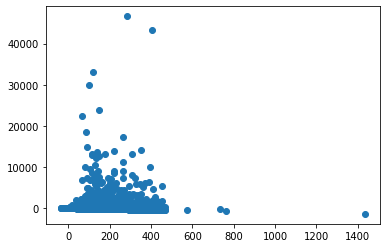

-0.26735311502329134
-0.22021228749741611
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.646389 0.124529 5.191 0.000000
## 1.773853 0.249500 7.110 0.000000
## 30.249703 3.964573 7.630 0.000000
## -1295.848903 250.124142 -5.181 0.000000
## ---
## Mean squared error: 35612.933581 , RMSE: 188.713893
## Multiple R-squared: 0.003255 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

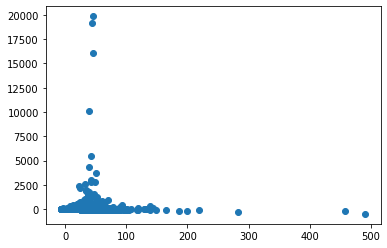

-0.24283627150659817
-0.24392777336548116
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.603323 0.291607 -29.503 0.000000
## 1.960663 0.506398 3.872 0.000108
## 2.709317 0.128518 21.081 0.000000
## 17356.287435 585.674534 29.635 0.000000
## ---
## Mean squared error: 288700.899661 , RMSE: 537.308942
## Multiple R-squared: 0.031779 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

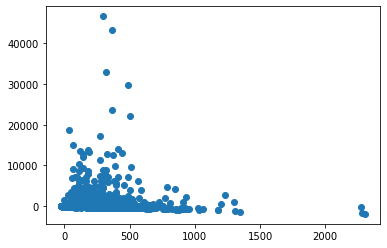

-0.15834815134748836
-0.01863461655710202
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.689850 0.128140 5.384 0.000000
## 1.344447 0.249400 5.391 0.000000
## 0.768155 0.047318 16.234 0.000000
## -1370.191564 256.915395 -5.333 0.000000
## ---
## Mean squared error: 36531.224000 , RMSE: 191.131431
## Multiple R-squared: 0.008897 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

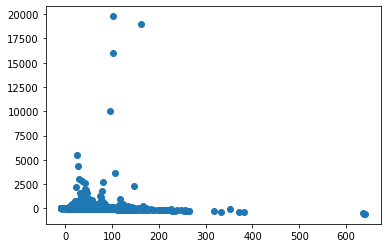

-0.11360441270735422
-0.01861789089265589
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -7.559446 0.364566 -20.735 0.000000
## 1.323446 0.596619 2.218 0.026544
## 56.418522 2.079340 27.133 0.000000
## 15186.662302 732.175029 20.742 0.000000
## ---
## Mean squared error: 355399.149396 , RMSE: 596.153629
## Multiple R-squared: 0.036311 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

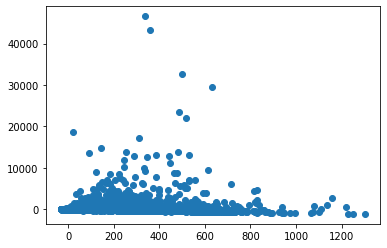

-0.1833230813442359
0.016202478591084715
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.123565 0.140966 7.970 0.000000
## 1.034553 0.268649 3.851 0.000118
## 14.566321 0.723720 20.127 0.000000
## -2257.739208 282.726936 -7.986 0.000000
## ---
## Mean squared error: 39924.511655 , RMSE: 199.811190
## Multiple R-squared: 0.014317 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

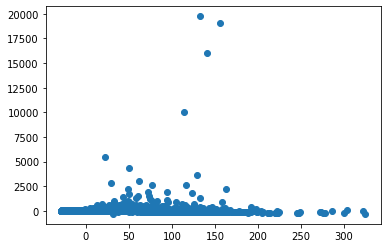

-0.14910953670197485
0.02664465718729022
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.165011 0.311498 -29.422 0.000000
## 2.428729 0.570213 4.259 0.000021
## -10.871783 3.012847 -3.608 0.000308
## 18514.317775 625.168414 29.615 0.000000
## ---
## Mean squared error: 288054.467398 , RMSE: 536.707059
## Multiple R-squared: 0.023763 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

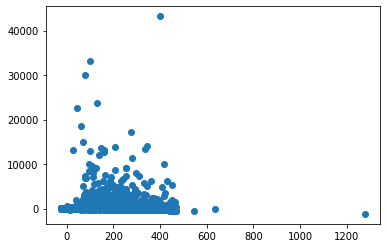

0.1611850171595913
0.09211641382692991
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.607177 0.156069 3.890 0.000100
## 1.674358 0.328897 5.091 0.000000
## -5.094746 1.414639 -3.601 0.000317
## -1194.081498 312.660233 -3.819 0.000134
## ---
## Mean squared error: 45227.458732 , RMSE: 212.667484
## Multiple R-squared: 0.002065 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

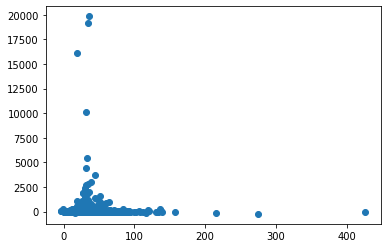

0.1763088587030363
0.12533877397938717
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.127032 0.280870 -32.496 0.000000
## 1.627231 0.497175 3.273 0.001065
## 1.683888 0.070571 23.861 0.000000
## 18403.795630 564.032020 32.629 0.000000
## ---
## Mean squared error: 279121.300415 , RMSE: 528.319317
## Multiple R-squared: 0.034228 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

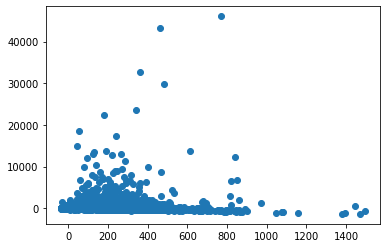

-0.03938765449967439
0.02713965817723419
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.440252 0.127700 3.448 0.000566
## 1.221491 0.250622 4.874 0.000001
## 0.448576 0.027477 16.326 0.000000
## -869.718807 255.973539 -3.398 0.000680
## ---
## Mean squared error: 36514.655470 , RMSE: 191.088083
## Multiple R-squared: 0.008979 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

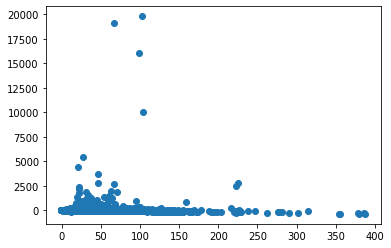

0.019040025722983696
0.04561609627063082
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.015404 0.319074 -28.255 0.000000
## 1.034559 0.551266 1.877 0.060567
## 33.984123 1.291226 26.319 0.000000
## 18130.456615 640.574884 28.303 0.000000
## ---
## Mean squared error: 316797.164656 , RMSE: 562.847372
## Multiple R-squared: 0.036010 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

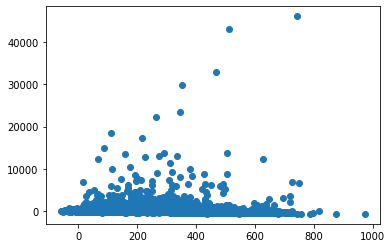

-0.03595874101303815
0.06542356691804155
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.609725 0.135180 4.510 0.000006
## 0.936968 0.263784 3.552 0.000383
## 8.982413 0.489838 18.337 0.000000
## -1221.766782 270.946936 -4.509 0.000007
## ---
## Mean squared error: 38641.442392 , RMSE: 196.574267
## Multiple R-squared: 0.011676 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

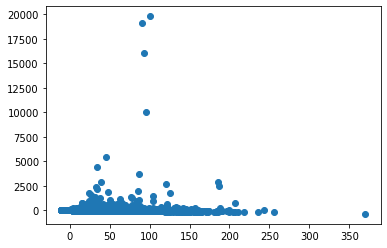

0.011513513357460271
0.09232540263042655
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.271130 0.332276 -27.902 0.000000
## 1.868982 0.588297 3.177 0.001490
## -3.201072 3.849446 -0.832 0.405659
## 18724.917822 667.039687 28.072 0.000000
## ---
## Mean squared error: 331430.273167 , RMSE: 575.699812
## Multiple R-squared: 0.020342 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

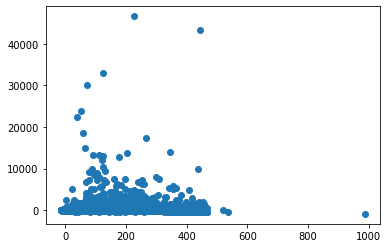

0.10609336601667656
0.05907597072933072
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.603375 0.155203 3.888 0.000101
## 1.330216 0.306652 4.338 0.000014
## -2.436289 1.709039 -1.426 0.154015
## -1186.957576 311.025080 -3.816 0.000136
## ---
## Mean squared error: 45477.025399 , RMSE: 213.253430
## Multiple R-squared: 0.001581 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

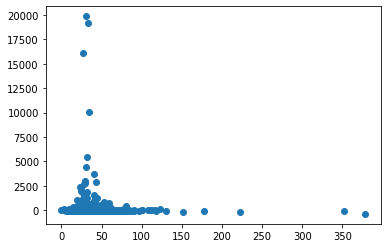

0.09899292431409266
0.07058129298192628
ENER

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.083837 0.239494 -25.403 0.000000
## 3.725051 0.596017 6.250 0.000000
## 9.872496 2.317841 4.259 0.000021
## 12287.147798 481.734561 25.506 0.000000
## ---
## Mean squared error: 23591.109171 , RMSE: 153.593975
## Multiple R-squared: 0.083058 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

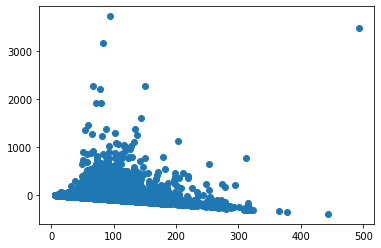

0.10380432710261861
0.4036894383546541
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.574424 0.171000 9.207 0.000000
## 2.373588 0.410950 5.776 0.000000
## 4.534928 1.794991 2.526 0.011559
## -3141.456831 343.300101 -9.151 0.000000
## ---
## Mean squared error: 6776.026311 , RMSE: 82.316622
## Multiple R-squared: 0.039964 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

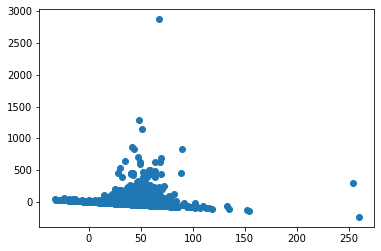

0.09557885178063959
0.45339058709651675
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.067295 0.240162 -25.263 0.000000
## 4.090608 0.676920 6.043 0.000000
## 2.335945 1.459300 1.601 0.109479
## 12261.006459 483.077881 25.381 0.000000
## ---
## Mean squared error: 23640.261948 , RMSE: 153.753901
## Multiple R-squared: 0.081147 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

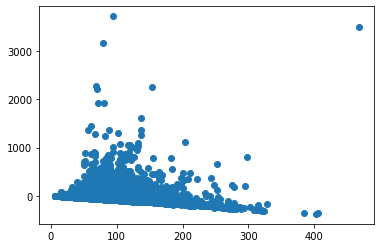

0.1530171034977026
0.5964896852983186
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.601271 0.171200 9.353 0.000000
## 3.124376 0.462866 6.750 0.000000
## -1.126813 1.102978 -1.022 0.307024
## -3190.308994 343.715893 -9.282 0.000000
## ---
## Mean squared error: 6784.654523 , RMSE: 82.369014
## Multiple R-squared: 0.038742 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

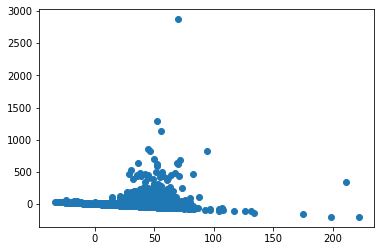

0.12131619206786498
0.6130658036758144
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -5.821499 0.242652 -23.991 0.000000
## 5.416433 0.562857 9.623 0.000000
## 36.305314 6.894388 5.266 0.000000
## 11743.940140 488.992912 24.017 0.000000
## ---
## Mean squared error: 23560.961654 , RMSE: 153.495803
## Multiple R-squared: 0.084229 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

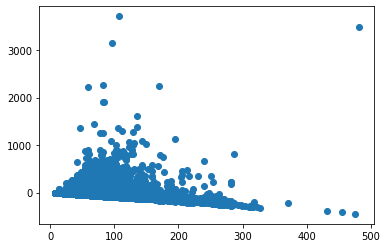

-0.20331272469180248
-0.2574586450749029
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.637917 0.172329 9.505 0.000000
## 2.992479 0.375324 7.973 0.000000
## 10.050004 4.861288 2.067 0.038762
## -3271.802523 346.479833 -9.443 0.000000
## ---
## Mean squared error: 6779.431737 , RMSE: 82.337305
## Multiple R-squared: 0.039482 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

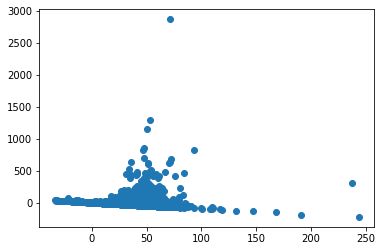

-0.15272212320895168
-0.2158000741378799
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.948459 0.211445 -32.862 0.000000
## 2.611384 0.520521 5.017 0.000001
## 0.911125 0.071743 12.700 0.000000
## 14042.553703 425.124434 33.032 0.000000
## ---
## Mean squared error: 31562.192257 , RMSE: 177.657514
## Multiple R-squared: 0.084461 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

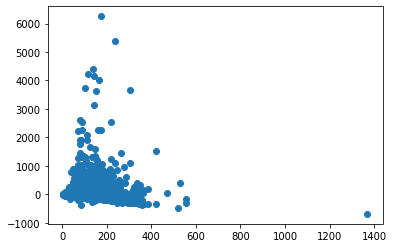

-0.06837463632214251
-0.011994513863927124
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.223923 0.102360 11.957 0.000000
## 2.064593 0.248828 8.297 0.000000
## 0.332940 0.028291 11.769 0.000000
## -2435.042869 205.464016 -11.851 0.000000
## ---
## Mean squared error: 4432.493915 , RMSE: 66.576977
## Multiple R-squared: 0.043746 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

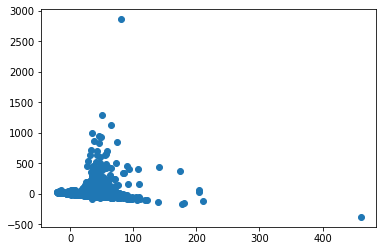

-0.006257788881940476
0.0019403793149655449
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.260515 0.270966 -23.104 0.000000
## 2.197029 0.665798 3.300 0.000971
## 27.473221 1.441344 19.061 0.000000
## 12630.773724 544.486220 23.198 0.000000
## ---
## Mean squared error: 40531.082237 , RMSE: 201.323328
## Multiple R-squared: 0.083610 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

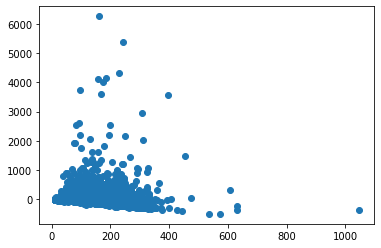

-0.062145802294173415
0.03606934686789466
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.493647 0.109824 13.600 0.000000
## 1.771455 0.264585 6.695 0.000000
## 11.036178 0.534830 20.635 0.000000
## -2989.602878 220.417248 -13.563 0.000000
## ---
## Mean squared error: 4652.604045 , RMSE: 68.210000
## Multiple R-squared: 0.084559 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

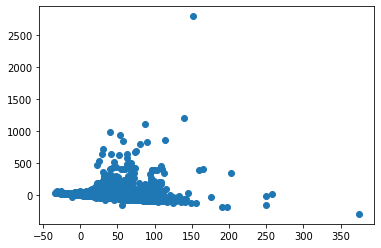

0.0009370421223543099
0.055691772970663043
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.688955 0.236746 -28.254 0.000000
## 3.489132 0.610197 5.718 0.000000
## -5.613322 2.463553 -2.279 0.022716
## 13524.088134 475.945288 28.415 0.000000
## ---
## Mean squared error: 31230.813794 , RMSE: 176.722420
## Multiple R-squared: 0.078821 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

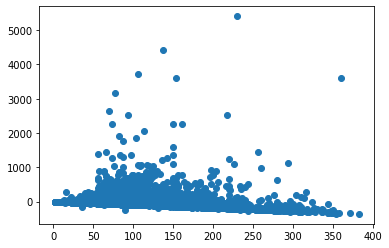

0.09141526017090774
0.07100854417427072
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.201281 0.124293 9.665 0.000000
## 2.202364 0.304862 7.224 0.000000
## -3.267326 1.314241 -2.486 0.012943
## -2386.099044 249.443523 -9.566 0.000000
## ---
## Mean squared error: 5125.282410 , RMSE: 71.591078
## Multiple R-squared: 0.028512 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

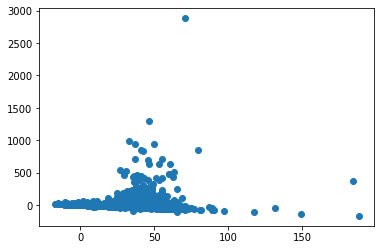

0.09956441255153439
0.07221615730333583
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.858495 0.204254 -33.578 0.000000
## -0.615121 0.516680 -1.191 0.233859
## 0.335356 0.019121 17.539 0.000000
## 13875.630091 410.615462 33.792 0.000000
## ---
## Mean squared error: 29612.436158 , RMSE: 172.082643
## Multiple R-squared: 0.094934 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

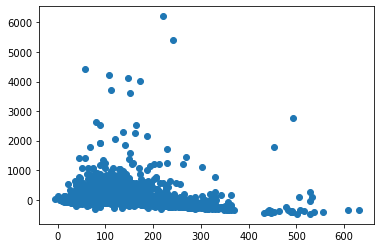

0.00954393335722232
0.11151849924267385
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.143009 0.100425 11.382 0.000000
## 1.044146 0.253602 4.117 0.000039
## 0.218717 0.008836 24.753 0.000000
## -2270.383248 201.555750 -11.264 0.000000
## ---
## Mean squared error: 4190.441787 , RMSE: 64.733622
## Multiple R-squared: 0.089796 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

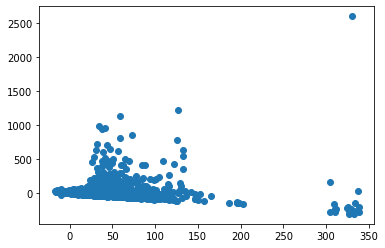

0.0687711981093476
0.11807126002406751
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.764915 0.241831 -27.974 0.000000
## -2.080805 0.629027 -3.308 0.000943
## 13.289617 0.627784 21.169 0.000000
## 13675.047171 485.825722 28.148 0.000000
## ---
## Mean squared error: 34893.476591 , RMSE: 186.797957
## Multiple R-squared: 0.097687 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

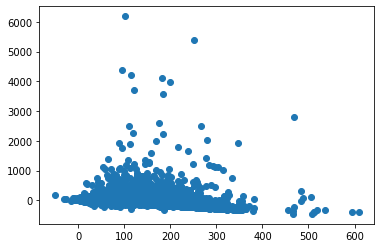

0.049502171641890365
0.16442903384681534
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.191866 0.106748 11.165 0.000000
## 0.672923 0.278831 2.413 0.015828
## 7.575380 0.264611 28.628 0.000000
## -2379.060198 214.169691 -11.108 0.000000
## ---
## Mean squared error: 4342.005594 , RMSE: 65.893896
## Multiple R-squared: 0.120215 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

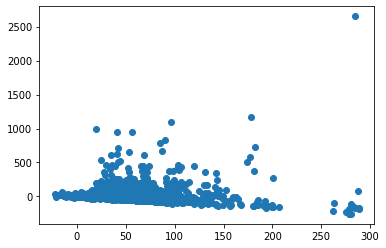

0.11198062159430526
0.16627935735772637
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.876531 0.253985 -27.075 0.000000
## 0.288185 0.674025 0.428 0.668982
## -4.219961 3.176369 -1.329 0.184028
## 13916.668831 510.562280 27.258 0.000000
## ---
## Mean squared error: 35550.333804 , RMSE: 188.547962
## Multiple R-squared: 0.074274 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

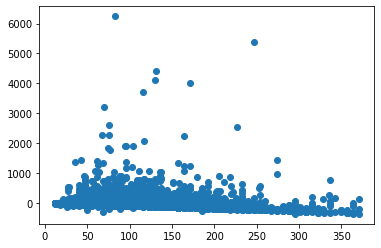

0.09331971981682097
0.03673280851848738
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.227401 0.125682 9.766 0.000000
## 1.522416 0.324743 4.688 0.000003
## -1.519598 1.668066 -0.911 0.362335
## -2435.883618 252.211197 -9.658 0.000000
## ---
## Mean squared error: 5129.453877 , RMSE: 71.620206
## Multiple R-squared: 0.022929 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

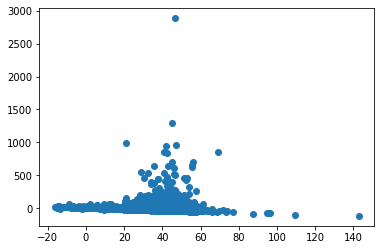

0.08210802643779135
0.04128913271280317
NURS

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.557736 0.577550 -11.354 0.000000
## 0.610601 1.341454 0.455 0.649095
## 6.652240 4.090768 1.626 0.104279
## 13230.524973 1161.986332 11.386 0.000000
## ---
## Mean squared error: 11168.300597 , RMSE: 105.680181
## Multiple R-squared: 0.134250 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

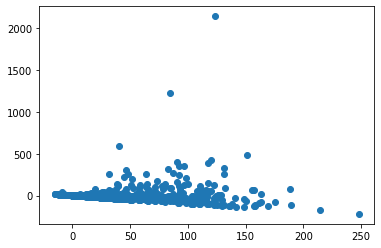

0.03273022595634974
0.46718412680627514
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.052788 0.166903 0.316 0.751911
## 0.187923 0.328827 0.571 0.567904
## 3.359396 0.958381 3.505 0.000494
## -95.764686 335.278811 -0.286 0.775274
## ---
## Mean squared error: 450.745725 , RMSE: 21.230773
## Multiple R-squared: 0.036451 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

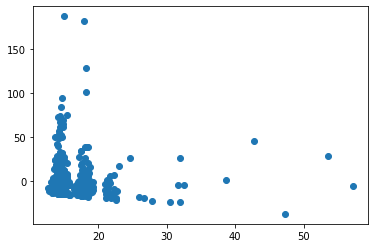

0.043964387142428896
0.5146455068005243
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.669735 0.579333 -11.513 0.000000
## 0.704854 1.428964 0.493 0.621952
## 2.654890 2.280038 1.164 0.244580
## 13457.820859 1165.210592 11.550 0.000000
## ---
## Mean squared error: 11184.873212 , RMSE: 105.758561
## Multiple R-squared: 0.132966 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

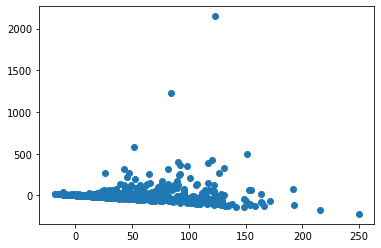

0.17081721355835264
0.571244967298628
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -0.042911 0.167896 -0.256 0.798373
## 0.095345 0.340123 0.280 0.779335
## 2.149482 0.597140 3.600 0.000348
## 96.259304 337.170475 0.285 0.775378
## ---
## Mean squared error: 450.196320 , RMSE: 21.217830
## Multiple R-squared: 0.037625 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

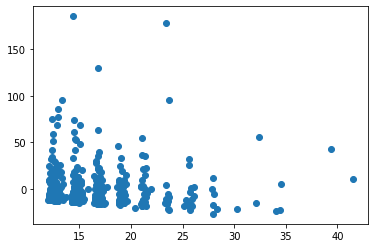

0.18340748363490317
0.571635478674462
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -6.741128 0.580785 -11.607 0.000000
## 0.591636 1.312948 0.451 0.652378
## -30.365055 16.517474 -1.838 0.066351
## 13622.115569 1169.572185 11.647 0.000000
## ---
## Mean squared error: 11158.867211 , RMSE: 105.635540
## Multiple R-squared: 0.134982 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

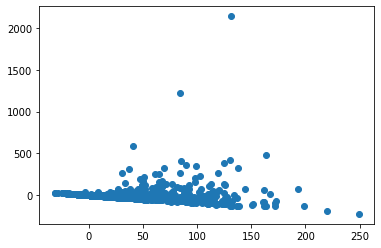

-0.18621461871879066
-0.45004546609648777
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.001938 0.168903 0.011 0.990851
## 0.542557 0.314168 1.727 0.084749
## -7.140016 4.003143 -1.784 0.075053
## 12.848175 339.505632 0.038 0.969826
## ---
## Mean squared error: 458.343883 , RMSE: 21.408967
## Multiple R-squared: 0.020208 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

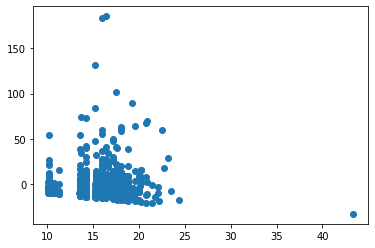

-0.14811230828446517
-0.43791032776650235
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.909035 0.452787 -19.676 0.000000
## 3.227238 0.595874 5.416 0.000000
## 1.073726 0.142972 7.510 0.000000
## 17974.789149 909.809866 19.757 0.000000
## ---
## Mean squared error: 69245.503571 , RMSE: 263.145404
## Multiple R-squared: 0.083063 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

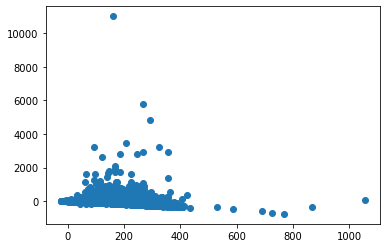

-0.12389771653902584
0.050954939170338207
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.306758 0.165024 1.859 0.063116
## 1.822128 0.221199 8.237 0.000000
## 0.280386 0.042220 6.641 0.000000
## -596.721908 331.105662 -1.802 0.071584
## ---
## Mean squared error: 5836.303810 , RMSE: 76.395705
## Multiple R-squared: 0.030248 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

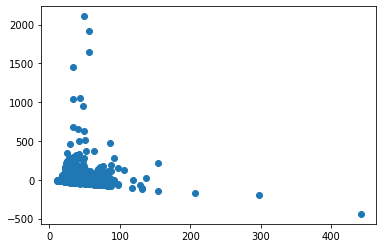

-0.060108703827402785
0.07676140310906658
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.240988 0.593271 -13.891 0.000000
## 4.270184 0.833592 5.123 0.000000
## 32.511139 2.869950 11.328 0.000000
## 16581.564092 1191.429051 13.917 0.000000
## ---
## Mean squared error: 86416.746416 , RMSE: 293.967254
## Multiple R-squared: 0.084108 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

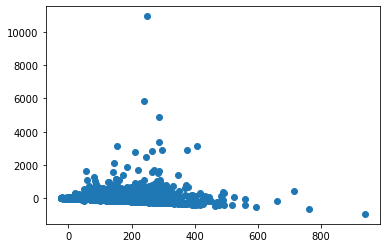

-0.1496537944066557
0.06401666377681452
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.598982 0.181887 3.293 0.001000
## 3.178783 0.320879 9.906 0.000000
## 9.351674 0.791801 11.811 0.000000
## -1204.295567 364.832016 -3.301 0.000973
## ---
## Mean squared error: 6146.876905 , RMSE: 78.402021
## Multiple R-squared: 0.072885 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

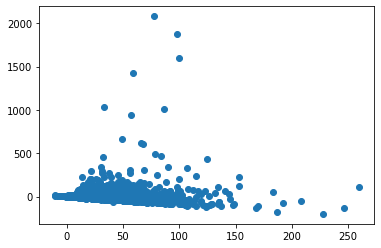

-0.1057884760118343
0.11586153384020279
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.295163 0.495706 -18.751 0.000000
## 3.162307 0.634026 4.988 0.000001
## -1.457358 4.018815 -0.363 0.716895
## 18761.351625 995.579747 18.845 0.000000
## ---
## Mean squared error: 72234.595277 , RMSE: 268.764944
## Multiple R-squared: 0.074028 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

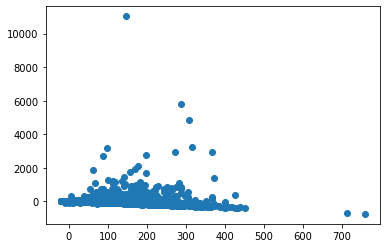

0.1687657594508653
0.06109440058503226
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.287073 0.185867 1.545 0.122559
## 1.897222 0.235876 8.043 0.000000
## -1.380316 1.360990 -1.014 0.310560
## -554.102514 372.715269 -1.487 0.137197
## ---
## Mean squared error: 5967.650736 , RMSE: 77.250571
## Multiple R-squared: 0.020753 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

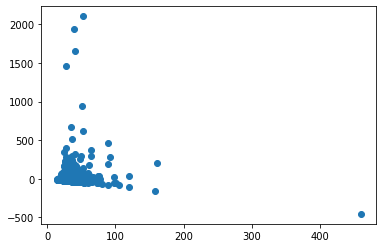

0.18636384220931182
0.0721006811622418
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.692283 0.432573 -20.094 0.000000
## 3.247243 0.578691 5.611 0.000000
## 0.425387 0.058085 7.324 0.000000
## 17537.580393 869.207030 20.177 0.000000
## ---
## Mean squared error: 65692.926512 , RMSE: 256.306314
## Multiple R-squared: 0.080421 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

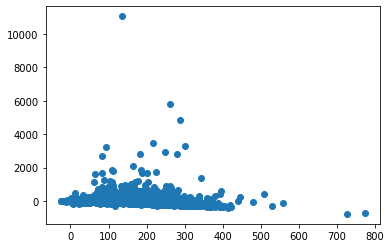

-0.06532568687478317
0.05271363043301107
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.228840 0.164048 1.395 0.163102
## 1.875603 0.221176 8.480 0.000000
## 0.117215 0.017975 6.521 0.000000
## -440.707568 329.125990 -1.339 0.180636
## ---
## Mean squared error: 5808.057040 , RMSE: 76.210610
## Multiple R-squared: 0.030307 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

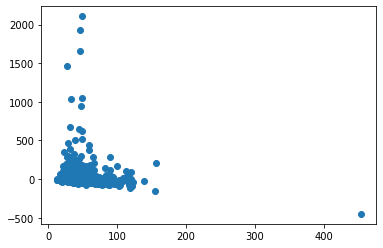

0.001427034234128846
0.06991261839464288
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.894238 0.511838 -17.377 0.000000
## 6.172255 0.939531 6.570 0.000000
## 15.058305 1.619985 9.295 0.000000
## 17899.477632 1027.614689 17.418 0.000000
## ---
## Mean squared error: 75278.132608 , RMSE: 274.368607
## Multiple R-squared: 0.084861 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

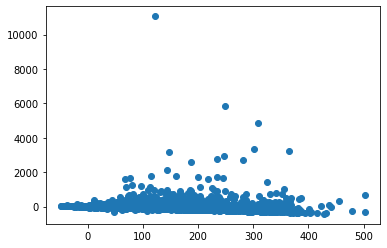

-0.07317544420076015
0.13435281081712852
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.286748 0.176601 1.624 0.104519
## 2.971024 0.307429 9.664 0.000000
## 4.607037 0.486124 9.477 0.000000
## -571.594568 354.132495 -1.614 0.106594
## ---
## Mean squared error: 6053.726857 , RMSE: 77.805699
## Multiple R-squared: 0.056830 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

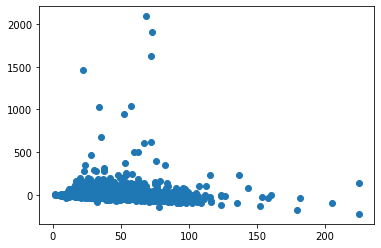

0.0010040811404355922
0.1587951748416232
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -8.884253 0.500235 -17.760 0.000000
## 2.234025 0.644123 3.468 0.000529
## -2.416421 4.488776 -0.538 0.590379
## 17940.991014 1004.920845 17.853 0.000000
## ---
## Mean squared error: 73290.211579 , RMSE: 270.721650
## Multiple R-squared: 0.066378 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

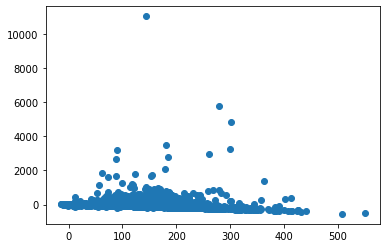

0.15013843413300446
0.06139996881117216
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.358096 0.196946 1.818 0.069116
## 1.470763 0.259292 5.672 0.000000
## -2.817241 1.658418 -1.699 0.089459
## -693.105870 395.052551 -1.754 0.079443
## ---
## Mean squared error: 6804.177741 , RMSE: 82.487440
## Multiple R-squared: 0.012090 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

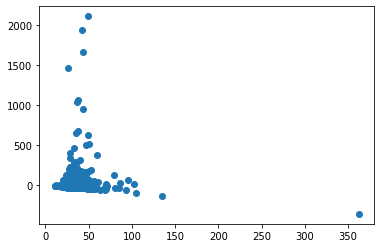

0.11680259758071758
0.053979098417696145
CENG

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.664273 0.258830 -37.338 0.000000
## 6.910631 0.840463 8.222 0.000000
## 17.990028 3.159215 5.694 0.000000
## 19481.604716 519.552958 37.497 0.000000
## ---
## Mean squared error: 88828.543455 , RMSE: 298.041177
## Multiple R-squared: 0.056405 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

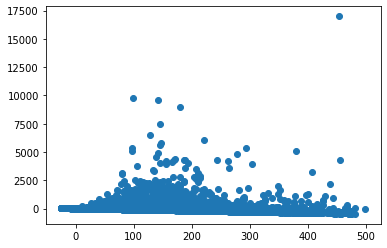

0.08939872490378203
0.2826241689036027
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.654974 0.101574 6.448 0.000000
## 4.910504 0.330993 14.836 0.000000
## 5.898980 1.252275 4.711 0.000002
## -1303.689890 203.569636 -6.404 0.000000
## ---
## Mean squared error: 8263.192251 , RMSE: 90.902103
## Multiple R-squared: 0.028204 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

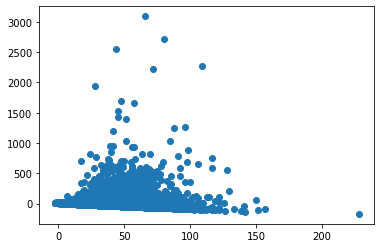

0.09859784404898042
0.31040215874256716
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.640604 0.259347 -37.173 0.000000
## 8.800972 0.926650 9.498 0.000000
## -2.521488 1.885934 -1.337 0.181236
## 19453.304529 520.520334 37.373 0.000000
## ---
## Mean squared error: 88942.573610 , RMSE: 298.232415
## Multiple R-squared: 0.055193 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

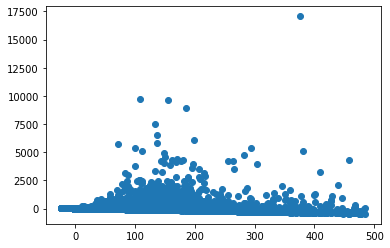

0.1989177018277219
0.5140422255411153
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.656780 0.101685 6.459 0.000000
## 5.385411 0.362670 14.849 0.000000
## -0.059559 0.769158 -0.077 0.938279
## -1301.758196 203.776929 -6.388 0.000000
## ---
## Mean squared error: 8274.708105 , RMSE: 90.965423
## Multiple R-squared: 0.026849 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

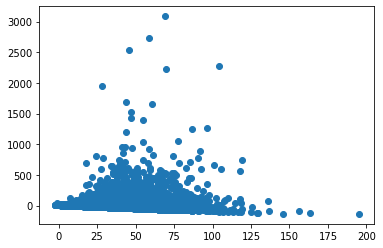

0.18123660424165894
0.5131031793230036
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -9.486452 0.262652 -36.118 0.000000
## 9.096121 0.841689 10.807 0.000000
## 31.277455 8.011046 3.904 0.000095
## 19120.144055 528.194721 36.199 0.000000
## ---
## Mean squared error: 88892.458758 , RMSE: 298.148384
## Multiple R-squared: 0.055726 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

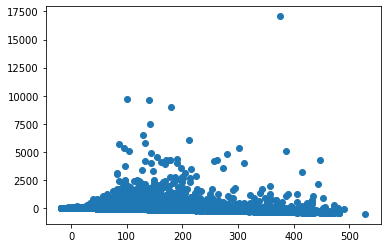

-0.250889436495964
-0.3280136326787335
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.725554 0.102769 7.060 0.000000
## 5.731535 0.326478 17.556 0.000000
## 13.116999 2.961404 4.429 0.000010
## -1448.942987 206.294173 -7.024 0.000000
## ---
## Mean squared error: 8264.525236 , RMSE: 90.909434
## Multiple R-squared: 0.028047 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

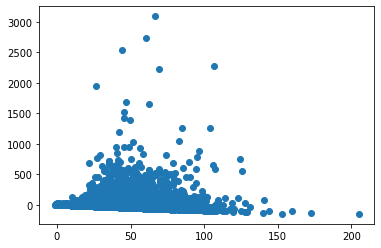

-0.23031478208070433
-0.3013217601440487
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.404070 0.276927 -41.181 0.000000
## 11.108164 0.796078 13.954 0.000000
## 1.984611 0.090957 21.819 0.000000
## 22982.112618 555.922658 41.340 0.000000
## ---
## Mean squared error: 135340.944944 , RMSE: 367.887136
## Multiple R-squared: 0.072844 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

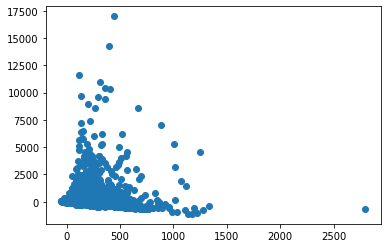

-0.1263928566090277
-0.043255481856034665
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.606921 0.090167 6.731 0.000000
## 5.906656 0.254628 23.197 0.000000
## 0.336312 0.024537 13.707 0.000000
## -1202.517524 180.764754 -6.652 0.000000
## ---
## Mean squared error: 9331.357101 , RMSE: 96.598950
## Multiple R-squared: 0.038688 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

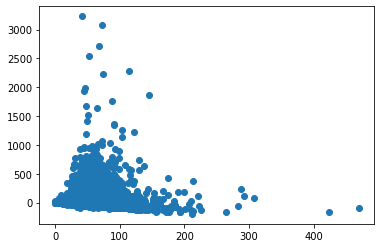

-0.07197875713753046
-0.02517227964109967
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.307435 0.343344 -30.021 0.000000
## 12.403689 0.993137 12.489 0.000000
## 54.666492 1.658035 32.971 0.000000
## 20696.142758 689.004466 30.038 0.000000
## ---
## Mean squared error: 164512.097941 , RMSE: 405.600910
## Multiple R-squared: 0.086089 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

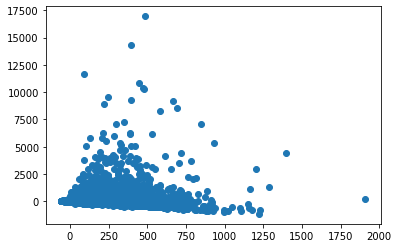

-0.12783456589846912
-0.003557093122344564
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.087209 0.095029 11.441 0.000000
## 5.812453 0.268298 21.664 0.000000
## 13.641101 0.416728 32.734 0.000000
## -2186.734857 190.520698 -11.478 0.000000
## ---
## Mean squared error: 9568.566823 , RMSE: 97.819051
## Multiple R-squared: 0.084732 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

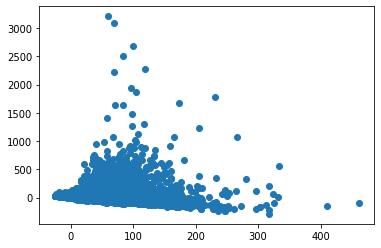

-0.07115395389350786
0.024298838652497826
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.276469 0.325652 -34.627 0.000000
## 11.286310 0.999194 11.295 0.000000
## -14.367346 3.251466 -4.419 0.000010
## 22746.546230 653.448791 34.810 0.000000
## ---
## Mean squared error: 146082.271522 , RMSE: 382.207106
## Multiple R-squared: 0.056726 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

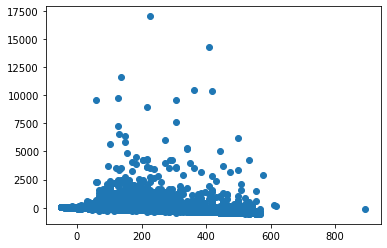

0.11127208563266636
0.10793590024850686
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.649900 0.099585 6.526 0.000000
## 5.834593 0.295186 19.766 0.000000
## -6.634271 0.964118 -6.881 0.000000
## -1282.581485 199.554304 -6.427 0.000000
## ---
## Mean squared error: 8698.853843 , RMSE: 93.267646
## Multiple R-squared: 0.035482 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

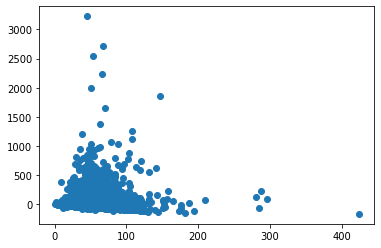

0.10440361265696174
0.10260128292424844
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.448803 0.264738 -43.246 0.000000
## 8.501137 0.758144 11.213 0.000000
## 0.782523 0.023634 33.110 0.000000
## 23073.173940 531.439651 43.416 0.000000
## ---
## Mean squared error: 129075.438871 , RMSE: 359.270704
## Multiple R-squared: 0.091242 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

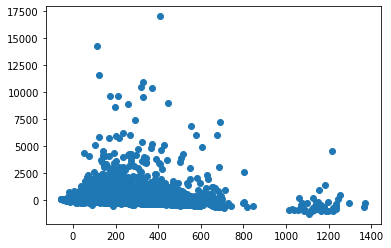

-0.04001382621820232
0.06046642500103798
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.443898 0.086236 5.148 0.000000
## 4.933967 0.240495 20.516 0.000000
## 0.259007 0.006522 39.712 0.000000
## -878.394278 172.869289 -5.081 0.000000
## ---
## Mean squared error: 8693.092616 , RMSE: 93.236756
## Multiple R-squared: 0.094884 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

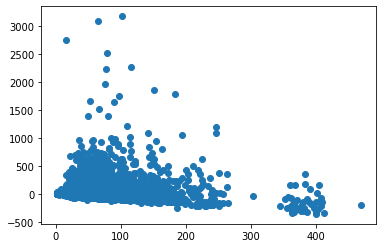

0.04893958392821501
0.0882433593979022
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.533314 0.295097 -39.083 0.000000
## 8.554250 0.851056 10.051 0.000000
## 26.740291 0.698688 38.272 0.000000
## 23188.078743 592.179818 39.157 0.000000
## ---
## Mean squared error: 142385.963796 , RMSE: 377.340647
## Multiple R-squared: 0.101348 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

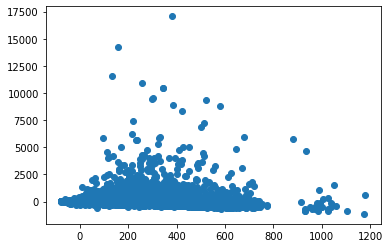

-0.020206143177998157
0.07922727657507775
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.453502 0.088292 5.136 0.000000
## 4.622094 0.245298 18.843 0.000000
## 9.451108 0.188126 50.238 0.000000
## -916.855722 176.953382 -5.181 0.000000
## ---
## Mean squared error: 8641.430462 , RMSE: 92.959295
## Multiple R-squared: 0.135935 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

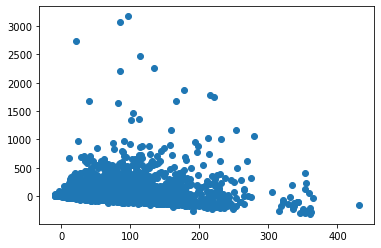

0.07838531952452894
0.1120710930975557
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.804485 0.333747 -35.370 0.000000
## 11.826383 1.012506 11.680 0.000000
## -1.694195 4.211268 -0.402 0.687467
## 23802.925222 669.756161 35.540 0.000000
## ---
## Mean squared error: 155777.581918 , RMSE: 394.686688
## Multiple R-squared: 0.056626 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

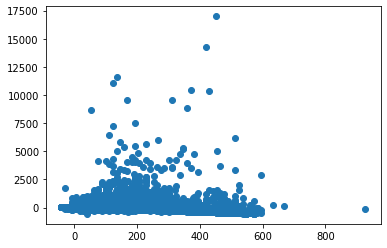

0.08480441073190753
0.05536827014199389
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.579382 0.100047 5.791 0.000000
## 6.295688 0.294944 21.345 0.000000
## -3.363725 1.259853 -2.670 0.007595
## -1144.596647 200.497452 -5.709 0.000000
## ---
## Mean squared error: 8935.921146 , RMSE: 94.530001
## Multiple R-squared: 0.038183 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

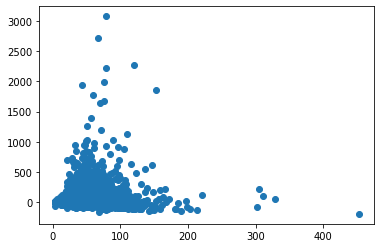

0.06288355242410519
0.03976400197543576
SOCI

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.327827 0.507393 -22.326 0.000000
## 5.594384 2.758850 2.028 0.042627
## 10.576568 8.212772 1.288 0.197861
## 22844.292497 1018.564995 22.428 0.000000
## ---
## Mean squared error: 112960.057813 , RMSE: 336.095311
## Multiple R-squared: 0.079922 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

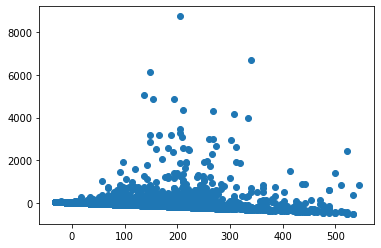

0.10332395129678984
0.3395119816035527
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.240783 0.065224 3.692 0.000226
## 1.700478 0.344072 4.942 0.000001
## 3.250524 1.061787 3.061 0.002218
## -472.619671 130.746032 -3.615 0.000304
## ---
## Mean squared error: 1125.568754 , RMSE: 33.549497
## Multiple R-squared: 0.017141 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

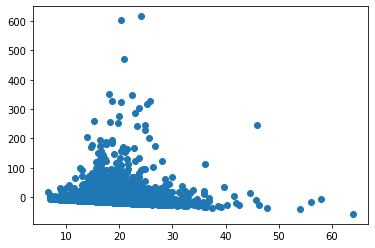

0.08512352313933619
0.32943416891029775
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.320045 0.507572 -22.302 0.000000
## 4.904358 3.419532 1.434 0.151564
## 4.370478 5.214980 0.838 0.402031
## 22835.847304 1019.072733 22.408 0.000000
## ---
## Mean squared error: 112978.790066 , RMSE: 336.123177
## Multiple R-squared: 0.079770 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

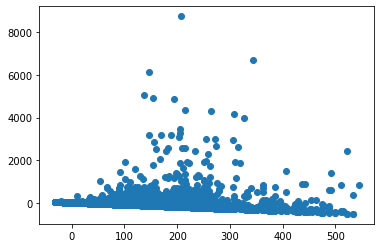

0.15733267274445753
0.6571996433244195
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.245504 0.065347 3.757 0.000174
## 1.799065 0.415926 4.325 0.000016
## 0.629884 0.676466 0.931 0.351836
## -479.427664 131.002389 -3.660 0.000256
## ---
## Mean squared error: 1127.915136 , RMSE: 33.584448
## Multiple R-squared: 0.015092 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

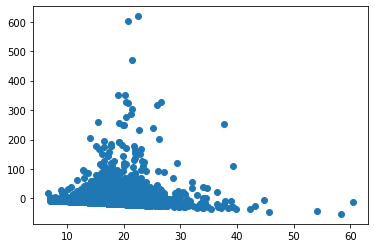

0.1333882090406242
0.6278008158627973
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.313411 0.510448 -22.164 0.000000
## 6.331237 3.126817 2.025 0.042932
## -4.767056 19.230521 -0.248 0.804228
## 22830.067267 1027.326356 22.223 0.000000
## ---
## Mean squared error: 112991.349854 , RMSE: 336.141860
## Multiple R-squared: 0.079667 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

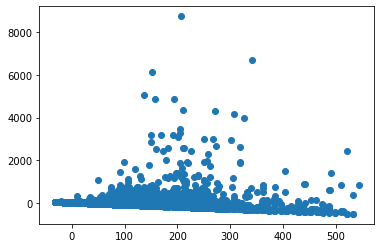

-0.19827494358810682
-0.5684234055154165
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.248746 0.065531 3.796 0.000149
## 2.028399 0.393716 5.152 0.000000
## -0.117080 2.336780 -0.050 0.960042
## -485.332608 131.633486 -3.687 0.000230
## ---
## Mean squared error: 1128.154189 , RMSE: 33.588007
## Multiple R-squared: 0.014883 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

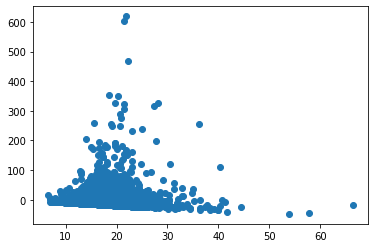

-0.15651550442562953
-0.569806440001702
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.732756 0.457034 -30.048 0.000000
## 3.051306 1.458790 2.092 0.036480
## 2.208189 0.184472 11.970 0.000000
## 27700.246388 917.689702 30.185 0.000000
## ---
## Mean squared error: 386221.003436 , RMSE: 621.466816
## Multiple R-squared: 0.051305 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

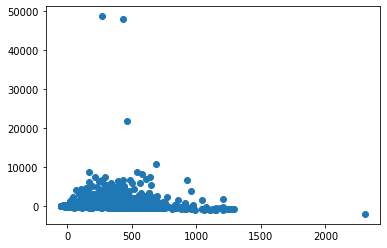

-0.12659414175236983
0.019354953109997193
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.464811 0.043030 10.802 0.000000
## 1.803510 0.132644 13.597 0.000000
## 0.192005 0.014379 13.353 0.000000
## -916.191074 86.268009 -10.620 0.000000
## ---
## Mean squared error: 2194.397196 , RMSE: 46.844393
## Multiple R-squared: 0.032500 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

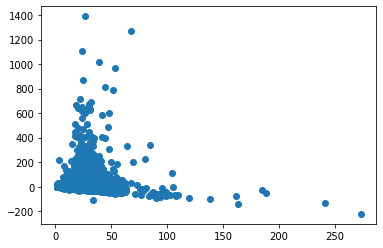

-0.08640535121295456
0.041483060230848
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.653877 0.607003 -22.494 0.000000
## 1.410170 1.812596 0.778 0.436590
## 65.272754 3.837978 17.007 0.000000
## 27460.568495 1218.600455 22.535 0.000000
## ---
## Mean squared error: 504137.368715 , RMSE: 710.026316
## Multiple R-squared: 0.055346 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

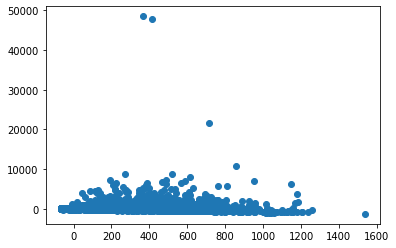

-0.1585460472358616
0.04141436133046896
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.737012 0.048413 15.223 0.000000
## 1.611046 0.143639 11.216 0.000000
## 5.840512 0.276154 21.149 0.000000
## -1468.027193 97.088708 -15.120 0.000000
## ---
## Mean squared error: 2397.449437 , RMSE: 48.963756
## Multiple R-squared: 0.056893 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

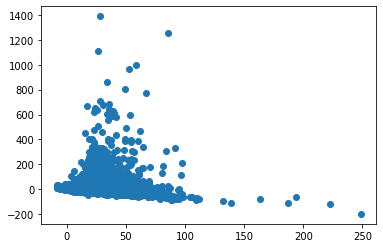

-0.12892841607419747
0.062242538862331706
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -13.576190 0.381976 -35.542 0.000000
## 3.967575 1.293466 3.067 0.002162
## -4.094127 4.438261 -0.922 0.356299
## 27398.207447 766.863070 35.728 0.000000
## ---
## Mean squared error: 257708.640099 , RMSE: 507.650116
## Multiple R-squared: 0.061460 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

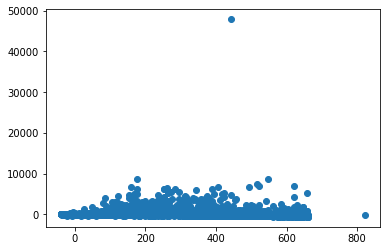

0.13845679083027987
0.21736942883114502
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.410284 0.043095 9.520 0.000000
## 1.839659 0.139689 13.170 0.000000
## -1.391395 0.485696 -2.865 0.004180
## -805.030261 86.375208 -9.320 0.000000
## ---
## Mean squared error: 1989.574123 , RMSE: 44.604642
## Multiple R-squared: 0.021237 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

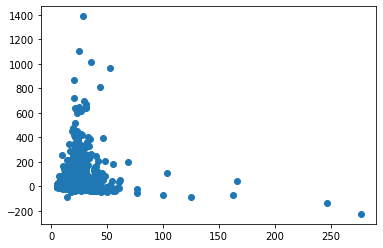

0.12615331193881926
0.20822726438904554
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.217945 0.455212 -31.234 0.000000
## 2.510634 1.470452 1.707 0.087764
## 1.885591 0.178237 10.579 0.000000
## 28679.630383 913.948962 31.380 0.000000
## ---
## Mean squared error: 390915.790561 , RMSE: 625.232589
## Multiple R-squared: 0.050004 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

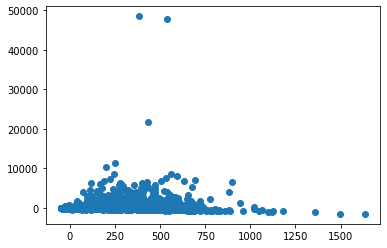

-0.049816344272832505
0.06591596550745174
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.416422 0.043193 9.641 0.000000
## 1.657080 0.133672 12.397 0.000000
## 0.148306 0.014693 10.094 0.000000
## -818.318761 86.587739 -9.451 0.000000
## ---
## Mean squared error: 2224.944503 , RMSE: 47.169317
## Multiple R-squared: 0.025377 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

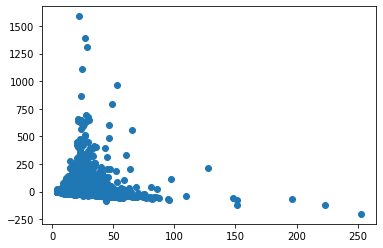

-0.015814960659786156
0.0675723458027168
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.897786 0.582399 -25.580 0.000000
## 0.964502 1.792448 0.538 0.590521
## 53.836970 3.563953 15.106 0.000000
## 29978.405422 1168.676344 25.652 0.000000
## ---
## Mean squared error: 497048.063018 , RMSE: 705.016357
## Multiple R-squared: 0.053079 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

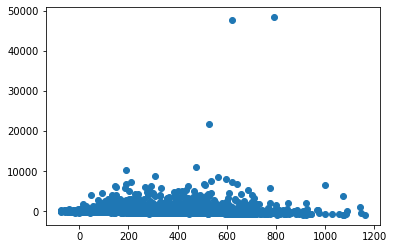

-0.04791290280752771
0.08425355140548822
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.600310 0.048225 12.448 0.000000
## 1.500579 0.144843 10.360 0.000000
## 4.528170 0.269438 16.806 0.000000
## -1191.362220 96.666363 -12.324 0.000000
## ---
## Mean squared error: 2436.075140 , RMSE: 49.356612
## Multiple R-squared: 0.042352 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

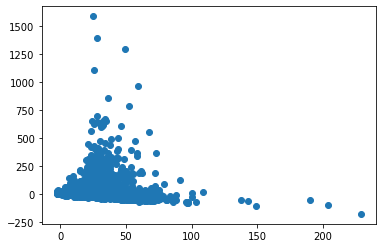

-0.031167909133029394
0.07710190538481873
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.267089 0.476279 -29.955 0.000000
## 4.050948 1.594799 2.540 0.011090
## -5.163698 5.862700 -0.881 0.378452
## 28791.281905 956.314060 30.107 0.000000
## ---
## Mean squared error: 406143.222520 , RMSE: 637.293671
## Multiple R-squared: 0.043768 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

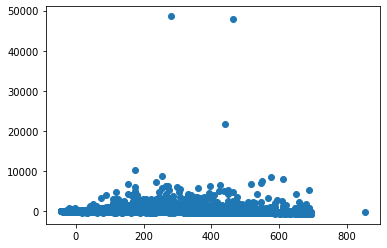

0.08587152537666624
0.1776487427941114
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.390305 0.042873 9.104 0.000000
## 1.610206 0.133708 12.043 0.000000
## -0.245048 0.510269 -0.480 0.631069
## -764.971400 85.939420 -8.901 0.000000
## ---
## Mean squared error: 1989.583739 , RMSE: 44.604750
## Multiple R-squared: 0.018855 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

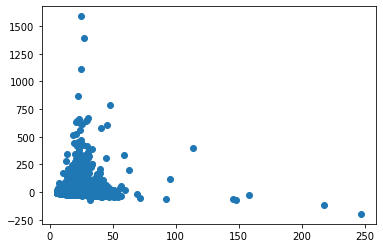

0.06766295799840817
0.17410649253850882
EART

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.515273 0.312947 -39.992 0.000000
## 2.616072 0.299855 8.724 0.000000
## 3.641579 2.317997 1.571 0.116196
## 25252.908684 628.396001 40.186 0.000000
## ---
## Mean squared error: 196121.664001 , RMSE: 442.856257
## Multiple R-squared: 0.068332 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

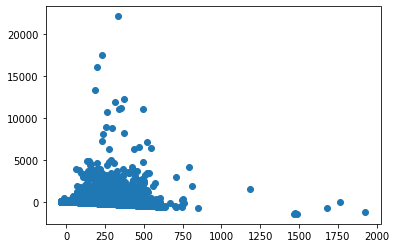

0.15138338396357665
0.6978548329517489
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.396357 0.100189 3.956 0.000077
## 2.965090 0.082470 35.954 0.000000
## 0.344900 0.700543 0.492 0.622491
## -776.280056 200.790123 -3.866 0.000111
## ---
## Mean squared error: 12150.750956 , RMSE: 110.230445
## Multiple R-squared: 0.134666 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

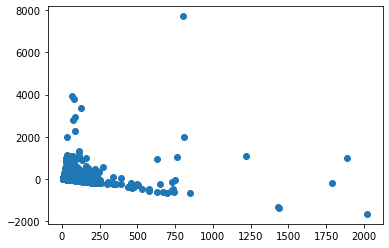

0.18720267889837974
0.6941482967959469
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.514591 0.313229 -39.954 0.000000
## 2.296280 0.499039 4.601 0.000004
## 1.789467 1.245297 1.437 0.150737
## 25254.160893 629.103281 40.143 0.000000
## ---
## Mean squared error: 196125.091292 , RMSE: 442.860126
## Multiple R-squared: 0.068316 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

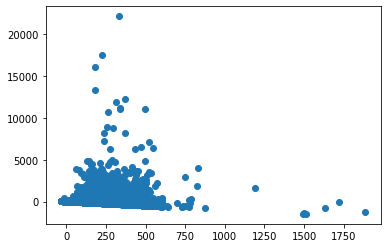

0.14783718698275217
0.90235954847042
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.285106 0.099861 2.855 0.004308
## 1.888366 0.142011 13.297 0.000000
## 3.230530 0.376875 8.572 0.000000
## -556.975227 200.201746 -2.782 0.005407
## ---
## Mean squared error: 12097.904244 , RMSE: 109.990473
## Multiple R-squared: 0.138429 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

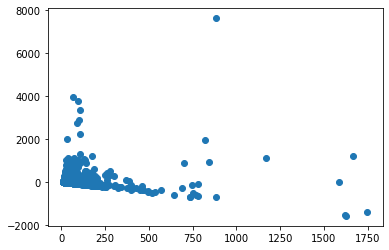

0.16589796030966378
0.9083198356539737
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.110171 0.322851 -37.510 0.000000
## 2.979522 0.216203 13.781 0.000000
## 47.805278 11.644470 4.105 0.000040
## 24413.244818 650.653926 37.521 0.000000
## ---
## Mean squared error: 195999.437142 , RMSE: 442.718237
## Multiple R-squared: 0.068913 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

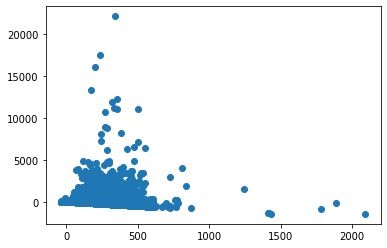

-0.27232849896739025
-0.06976569079201292
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.555440 0.101550 5.470 0.000000
## 3.010305 0.059761 50.372 0.000000
## 22.785466 3.402683 6.696 0.000000
## -1110.179069 204.180974 -5.437 0.000000
## ---
## Mean squared error: 12118.513679 , RMSE: 110.084121
## Multiple R-squared: 0.136961 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

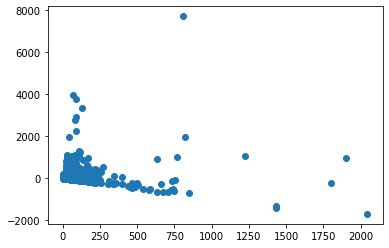

-0.22946852431091094
-0.06904190868176441
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.717314 0.283982 -41.261 0.000000
## 3.021253 0.218333 13.838 0.000000
## 1.492263 0.113659 13.129 0.000000
## 23632.088810 570.605823 41.416 0.000000
## ---
## Mean squared error: 178262.661594 , RMSE: 422.211631
## Multiple R-squared: 0.075388 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

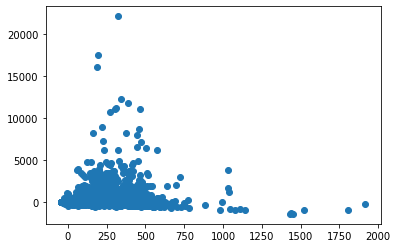

-0.10692390738823304
0.10131425273540952
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.338853 0.088054 3.848 0.000119
## 3.235689 0.060823 53.199 0.000000
## 0.548899 0.030026 18.281 0.000000
## -670.816536 176.610309 -3.798 0.000146
## ---
## Mean squared error: 11020.436497 , RMSE: 104.978267
## Multiple R-squared: 0.153547 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

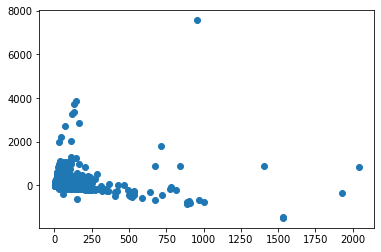

-0.022510684459561916
0.11403760223761784
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.328374 0.333737 -33.944 0.000000
## 2.802047 0.239401 11.704 0.000000
## 29.416553 1.422945 20.673 0.000000
## 22800.811537 670.418985 34.010 0.000000
## ---
## Mean squared error: 205737.731677 , RMSE: 453.583214
## Multiple R-squared: 0.078021 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

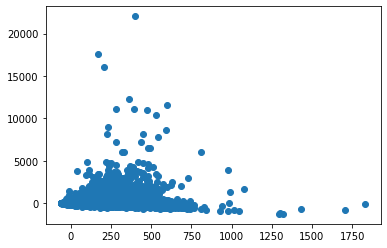

-0.11963287424040005
0.10984250983805875
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.562882 0.092791 6.066 0.000000
## 3.180761 0.062344 51.020 0.000000
## 8.333019 0.354163 23.529 0.000000
## -1132.635533 186.130456 -6.085 0.000000
## ---
## Mean squared error: 11485.636031 , RMSE: 107.171060
## Multiple R-squared: 0.164888 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

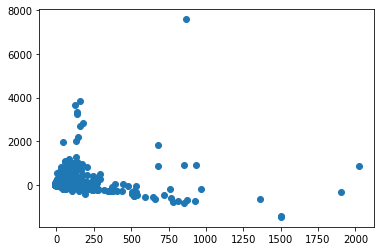

-0.05636316463277807
0.11551517474943854
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.673608 0.297857 -39.192 0.000000
## 3.123927 0.216133 14.454 0.000000
## -12.067479 3.673066 -3.285 0.001020
## 23568.099597 598.040119 39.409 0.000000
## ---
## Mean squared error: 164474.622321 , RMSE: 405.554709
## Multiple R-squared: 0.076668 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

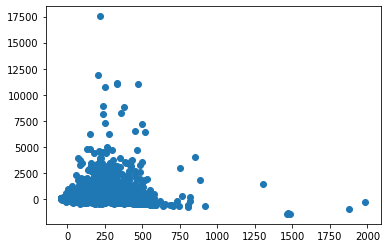

0.1455754725174252
0.038022682286747427
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.408414 0.101167 4.037 0.000054
## 3.376501 0.064777 52.125 0.000000
## -4.303638 1.189276 -3.619 0.000297
## -800.268948 202.794034 -3.946 0.000080
## ---
## Mean squared error: 11961.035898 , RMSE: 109.366521
## Multiple R-squared: 0.154711 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

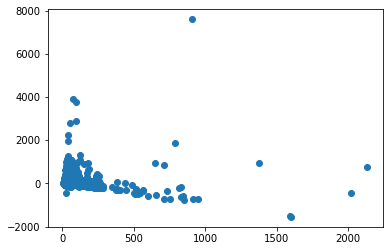

0.15327905324716418
0.031234648864460056
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.316513 0.285545 -43.133 0.000000
## 3.229210 0.220859 14.621 0.000000
## 0.761262 0.090888 8.376 0.000000
## 24842.719266 573.624502 43.308 0.000000
## ---
## Mean squared error: 183117.802486 , RMSE: 427.922659
## Multiple R-squared: 0.071660 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

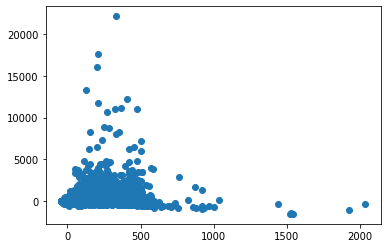

0.005180761354989097
0.055995804906630496
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.196361 0.087491 2.244 0.024821
## 3.351287 0.060335 55.545 0.000000
## 0.382580 0.025142 15.217 0.000000
## -383.808323 175.449127 -2.188 0.028712
## ---
## Mean squared error: 10746.395148 , RMSE: 103.664821
## Multiple R-squared: 0.153637 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

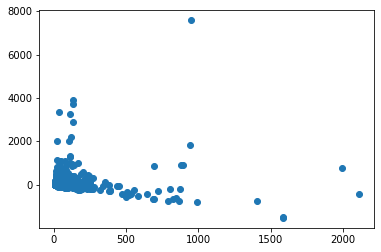

0.056528057438310284
0.057711102839317116
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.411592 0.322499 -38.486 0.000000
## 3.314060 0.239428 13.842 0.000000
## 15.063456 1.248144 12.069 0.000000
## 25006.967270 647.572210 38.616 0.000000
## ---
## Mean squared error: 206329.211200 , RMSE: 454.234753
## Multiple R-squared: 0.069105 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

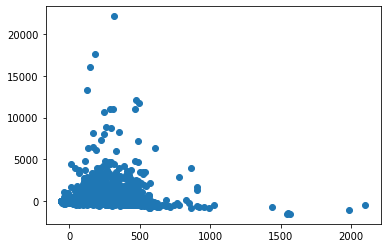

0.0009668282809579644
0.04378238434757003
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.309805 0.091900 3.371 0.000750
## 3.381475 0.062166 54.394 0.000000
## 5.190637 0.321455 16.147 0.000000
## -618.500538 184.246425 -3.357 0.000790
## ---
## Mean squared error: 11263.315081 , RMSE: 106.128767
## Multiple R-squared: 0.157333 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

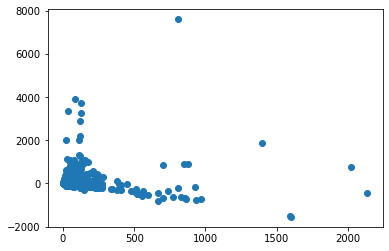

0.0494140679566794
0.0466284652520355
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.027276 0.322827 -37.256 0.000000
## 2.826449 0.276120 10.236 0.000000
## -5.927145 4.707169 -1.259 0.207982
## 24277.374431 648.243627 37.451 0.000000
## ---
## Mean squared error: 194155.750213 , RMSE: 440.631082
## Multiple R-squared: 0.065456 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

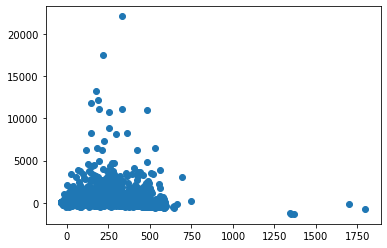

0.10880552211512277
0.042140600315235636
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.446822 0.080209 5.571 0.000000
## 2.470838 0.061025 40.489 0.000000
## -1.194479 1.121575 -1.065 0.286892
## -874.400276 160.798396 -5.438 0.000000
## ---
## Mean squared error: 7525.035900 , RMSE: 86.746965
## Multiple R-squared: 0.102388 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

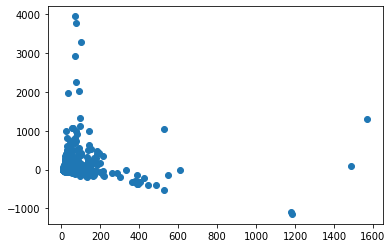

0.10936100587684063
0.04303638142098265
CHEM

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.638440 0.513327 -28.517 0.000000
## 0.095489 1.861498 0.051 0.959089
## 9.595507 6.921118 1.386 0.165631
## 29557.149792 1029.429018 28.712 0.000000
## ---
## Mean squared error: 657164.247495 , RMSE: 810.656677
## Multiple R-squared: 0.026249 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

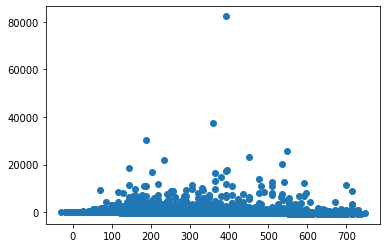

0.09947024639826821
0.3737429702098902
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.629756 0.081552 7.722 0.000000
## 1.246572 0.307918 4.048 0.000052
## 3.174669 1.100436 2.885 0.003919
## -1231.271760 163.299962 -7.540 0.000000
## ---
## Mean squared error: 10933.001720 , RMSE: 104.560995
## Multiple R-squared: 0.005456 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

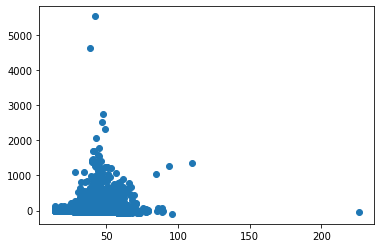

0.10609357445982838
0.3791198538763029
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.665540 0.513371 -28.567 0.000000
## -1.262125 2.130463 -0.592 0.553575
## 7.624280 4.111772 1.854 0.063711
## 29615.588707 1029.383075 28.770 0.000000
## ---
## Mean squared error: 657133.850097 , RMSE: 810.637928
## Multiple R-squared: 0.026294 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

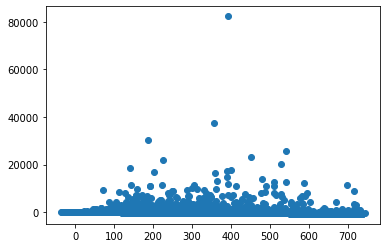

0.1921752350050497
0.6008505045324971
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.625214 0.081565 7.665 0.000000
## 1.035474 0.342144 3.026 0.002477
## 1.950966 0.680162 2.868 0.004129
## -1220.746488 163.314133 -7.475 0.000000
## ---
## Mean squared error: 10933.044961 , RMSE: 104.561202
## Multiple R-squared: 0.005452 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

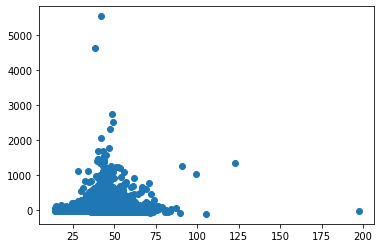

0.17444862184285714
0.5654287963433048
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -14.035691 0.523158 -26.829 0.000000
## 3.819445 1.796057 2.127 0.033463
## 108.215514 18.133610 5.968 0.000000
## 28279.970781 1051.651682 26.891 0.000000
## ---
## Mean squared error: 656489.428848 , RMSE: 810.240353
## Multiple R-squared: 0.027249 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

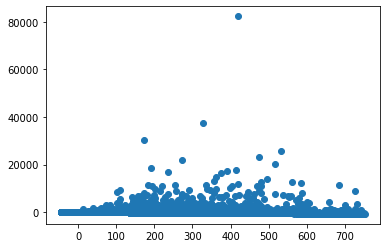

-0.27169379908982466
-0.3195043878503502
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.744485 0.082671 9.005 0.000000
## 2.180965 0.295815 7.373 0.000000
## 22.079852 2.710724 8.145 0.000000
## -1474.509578 165.888041 -8.889 0.000000
## ---
## Mean squared error: 10906.693481 , RMSE: 104.435116
## Multiple R-squared: 0.007850 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

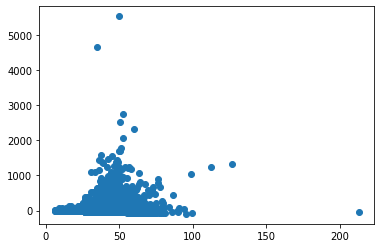

-0.242401137361838
-0.30398815611322216
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.051890 0.287171 -38.485 0.000000
## 0.050039 0.190864 0.262 0.793189
## 3.213995 0.101443 31.683 0.000000
## 22316.147001 577.396529 38.650 0.000000
## ---
## Mean squared error: 378501.824275 , RMSE: 615.225019
## Multiple R-squared: 0.042881 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

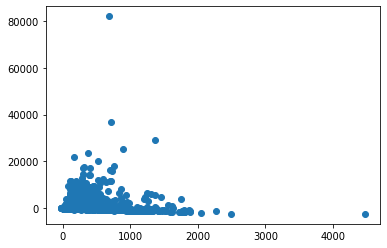

-0.1298704195718052
0.004027690678428972
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.008003 0.052223 19.302 0.000000
## 0.082912 0.028972 2.862 0.004215
## 0.451586 0.015655 28.847 0.000000
## -1985.675743 104.848312 -18.939 0.000000
## ---
## Mean squared error: 8514.037886 , RMSE: 92.271544
## Multiple R-squared: 0.023501 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

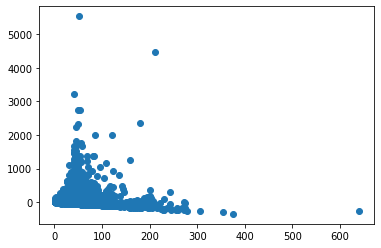

-0.07916360244228482
0.010686072427722567
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -10.235650 0.350912 -29.169 0.000000
## 0.021659 0.212018 0.102 0.918632
## 75.391440 1.851882 40.711 0.000000
## 20570.684347 705.342052 29.164 0.000000
## ---
## Mean squared error: 460021.074361 , RMSE: 678.248534
## Multiple R-squared: 0.052406 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

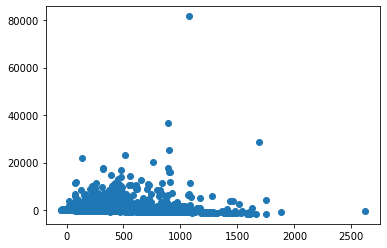

-0.12357334190649462
0.003125039833344652
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.379519 0.055113 25.031 0.000000
## 0.073342 0.029509 2.485 0.012945
## 13.349917 0.267006 49.999 0.000000
## -2750.157993 110.654103 -24.854 0.000000
## ---
## Mean squared error: 8810.922469 , RMSE: 93.866514
## Multiple R-squared: 0.064069 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

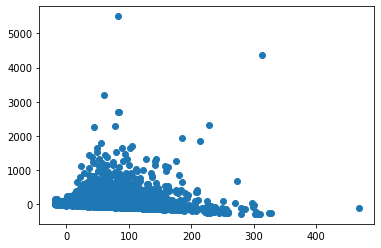

-0.07577968092815167
0.00757479617275376
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -11.774594 0.357613 -32.926 0.000000
## 0.086801 0.211949 0.410 0.682148
## -16.667027 3.899597 -4.274 0.000019
## 23806.447646 718.486664 33.134 0.000000
## ---
## Mean squared error: 457736.448929 , RMSE: 676.562228
## Multiple R-squared: 0.025494 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

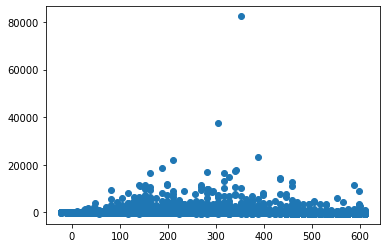

0.12487265144052713
0.020585604183530146
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.901872 0.059997 15.032 0.000000
## 0.070954 0.029330 2.419 0.015561
## -5.292976 0.635462 -8.329 0.000000
## -1766.060193 120.371186 -14.672 0.000000
## ---
## Mean squared error: 8643.214691 , RMSE: 92.968891
## Multiple R-squared: 0.008289 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

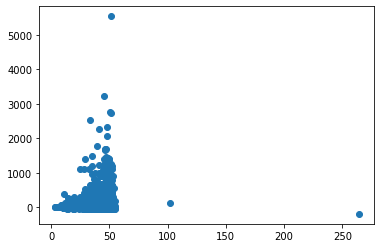

0.12041754642512262
0.015545543774468356
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.329203 0.283748 -43.451 0.000000
## 0.056397 0.192372 0.293 0.769396
## 0.948781 0.031500 30.120 0.000000
## 24882.226514 570.448262 43.619 0.000000
## ---
## Mean squared error: 384492.027409 , RMSE: 620.074211
## Multiple R-squared: 0.042161 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

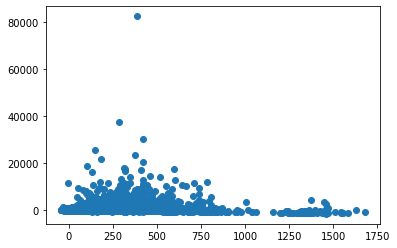

-0.01801837702534751
0.014448398734393946
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.736137 0.050727 14.512 0.000000
## 0.072678 0.028260 2.572 0.010120
## 0.262390 0.004853 54.067 0.000000
## -1445.168720 101.821566 -14.193 0.000000
## ---
## Mean squared error: 8094.998444 , RMSE: 89.972209
## Multiple R-squared: 0.063860 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

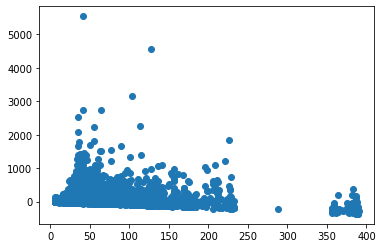

0.05179940883629901
0.017723135226406617
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.607220 0.313031 -40.275 0.000000
## 0.012605 0.202268 0.062 0.950308
## 32.747503 0.880201 37.205 0.000000
## 25372.698960 629.099064 40.332 0.000000
## ---
## Mean squared error: 422885.402220 , RMSE: 650.296396
## Multiple R-squared: 0.049169 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

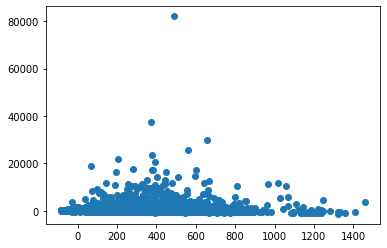

0.0006506257278604264
0.016540016657717652
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.751052 0.052227 14.381 0.000000
## 0.062856 0.028403 2.213 0.026902
## 8.720541 0.133127 65.506 0.000000
## -1492.787435 104.799419 -14.244 0.000000
## ---
## Mean squared error: 8164.993295 , RMSE: 90.360352
## Multiple R-squared: 0.093639 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

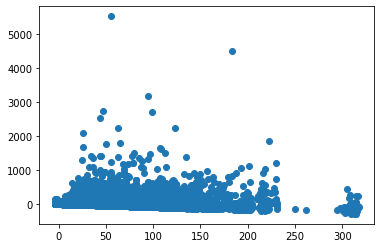

0.07478916871023679
0.019284660341483986
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -12.533352 0.357833 -35.026 0.000000
## 0.057001 0.213296 0.267 0.789286
## -10.273437 5.012980 -2.049 0.040432
## 25329.847059 719.066221 35.226 0.000000
## ---
## Mean squared error: 464841.268146 , RMSE: 681.792687
## Multiple R-squared: 0.027626 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

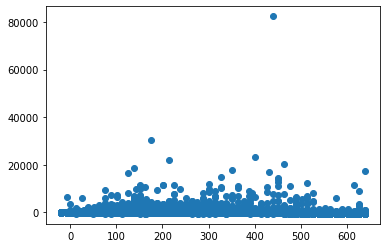

0.08213241945415936
0.015923960754891348
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.865330 0.060117 14.394 0.000000
## 0.064444 0.029599 2.177 0.029473
## -3.685586 0.834044 -4.419 0.000010
## -1693.786220 120.630728 -14.041 0.000000
## ---
## Mean squared error: 8791.363379 , RMSE: 93.762271
## Multiple R-squared: 0.006832 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

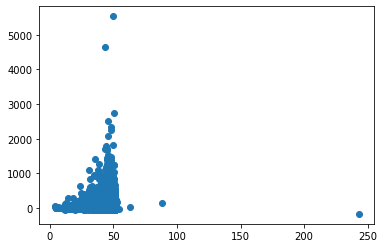

0.06603446509263393
0.011009265562204737
DENT

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -3.908884 0.261485 -14.949 0.000000
## -1.089498 1.102675 -0.988 0.323223
## 7.016335 3.221380 2.178 0.029495
## 7905.273316 524.053256 15.085 0.000000
## ---
## Mean squared error: 14592.054010 , RMSE: 120.797575
## Multiple R-squared: 0.091332 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

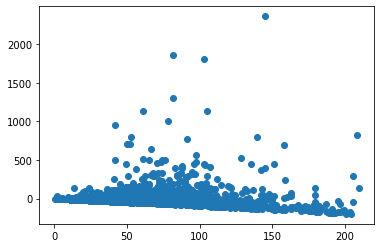

0.07816373208232164
0.40499890555301904
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.339465 0.066728 5.087 0.000000
## 0.205771 0.267192 0.770 0.441322
## 3.568261 0.850870 4.194 0.000029
## -670.973972 133.551734 -5.024 0.000001
## ---
## Mean squared error: 620.718082 , RMSE: 24.914214
## Multiple R-squared: 0.031602 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

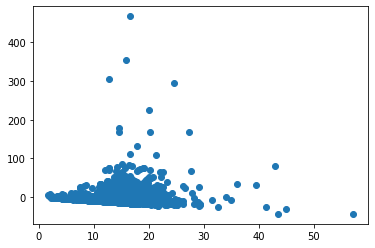

0.10621870429299808
0.4384602848974373
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -3.967588 0.261437 -15.176 0.000000
## -1.804943 1.174766 -1.536 0.124560
## 5.069304 1.814547 2.794 0.005251
## 8024.877991 523.802582 15.320 0.000000
## ---
## Mean squared error: 14574.258127 , RMSE: 120.723892
## Multiple R-squared: 0.092440 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

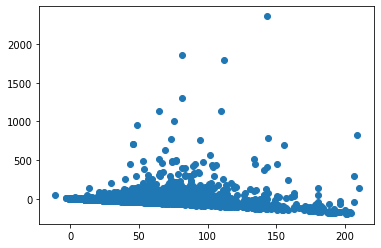

0.18931335857241205
0.5345726134418884
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.315898 0.066796 4.729 0.000002
## -0.021391 0.285231 -0.075 0.940226
## 2.048706 0.441195 4.644 0.000004
## -622.246527 133.661853 -4.655 0.000003
## ---
## Mean squared error: 619.428461 , RMSE: 24.888320
## Multiple R-squared: 0.033614 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

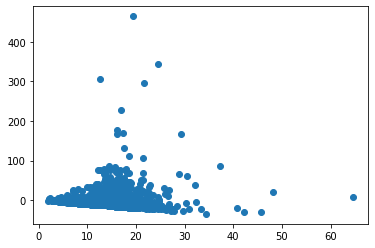

0.20035005003656736
0.5572028701653792
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -3.854017 0.262876 -14.661 0.000000
## 0.462381 1.035396 0.447 0.655221
## 25.809416 9.943722 2.596 0.009499
## 7783.257002 527.537962 14.754 0.000000
## ---
## Mean squared error: 14580.461965 , RMSE: 120.749584
## Multiple R-squared: 0.092054 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

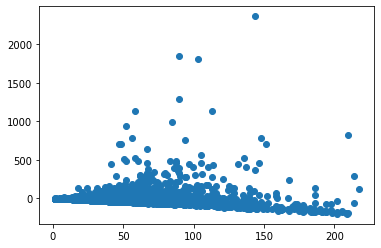

-0.17721139133637784
-0.2571481731871123
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.346258 0.067179 5.154 0.000000
## 0.800760 0.249801 3.206 0.001370
## 4.489559 2.350906 1.910 0.056321
## -684.935527 134.582280 -5.089 0.000000
## ---
## Mean squared error: 625.282577 , RMSE: 25.005651
## Multiple R-squared: 0.024481 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

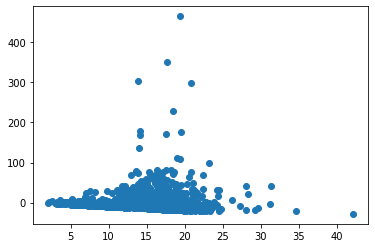

-0.14511371007402704
-0.26943128618227385
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -3.687756 0.277969 -13.267 0.000000
## -0.792239 1.011496 -0.783 0.433565
## 2.378173 0.237842 9.999 0.000000
## 7458.018101 556.866361 13.393 0.000000
## ---
## Mean squared error: 15188.743144 , RMSE: 123.242619
## Multiple R-squared: 0.119835 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

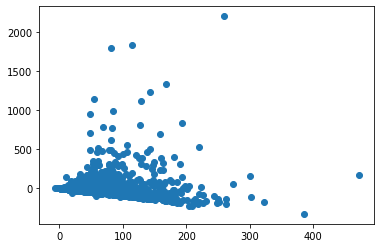

-0.09141778678587942
0.003969766806861234
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.397442 0.065893 6.032 0.000000
## 0.527729 0.230975 2.285 0.022433
## 0.428514 0.049139 8.721 0.000000
## -786.157942 131.877619 -5.961 0.000000
## ---
## Mean squared error: 601.436010 , RMSE: 24.524192
## Multiple R-squared: 0.060897 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

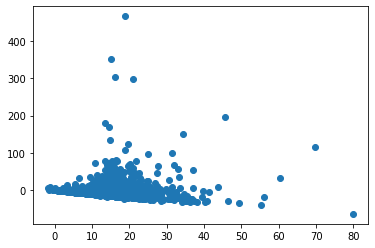

-0.054100968495484444
0.01317959236757137
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -3.206779 0.341666 -9.386 0.000000
## -0.782506 1.198345 -0.653 0.513840
## 39.666731 3.173373 12.500 0.000000
## 6450.935455 684.208329 9.428 0.000000
## ---
## Mean squared error: 17999.438333 , RMSE: 134.161985
## Multiple R-squared: 0.125663 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

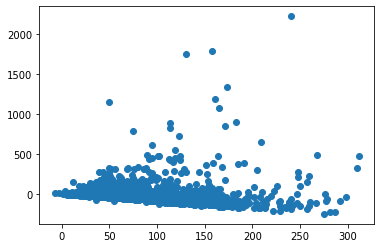

-0.08398560792515813
-0.022778865377624295
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.523329 0.069401 7.541 0.000000
## 0.533088 0.240889 2.213 0.027026
## 7.789414 0.604852 12.878 0.000000
## -1046.946554 138.902274 -7.537 0.000000
## ---
## Mean squared error: 610.506294 , RMSE: 24.708426
## Multiple R-squared: 0.116660 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

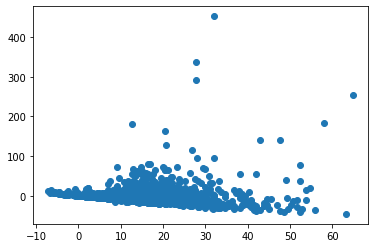

-0.0634595379510408
-0.008013196330497626
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -4.092188 0.320248 -12.778 0.000000
## 0.147709 1.156839 0.128 0.898413
## -6.136440 3.313120 -1.852 0.064153
## 8280.858618 641.594877 12.907 0.000000
## ---
## Mean squared error: 16565.185981 , RMSE: 128.705812
## Multiple R-squared: 0.090318 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

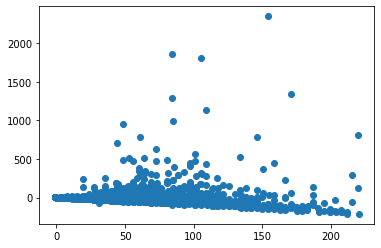

0.18618406366451945
0.1483273917207981
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.355218 0.077562 4.580 0.000005
## 0.769506 0.267077 2.881 0.004018
## -1.570574 0.778912 -2.016 0.043940
## -699.848197 155.222048 -4.509 0.000007
## ---
## Mean squared error: 653.430037 , RMSE: 25.562278
## Multiple R-squared: 0.025351 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

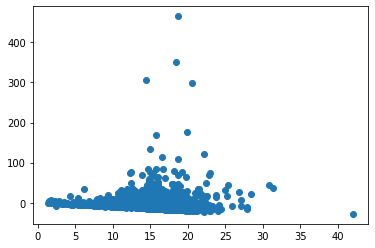

0.16000024015274503
0.14277540506272693
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -4.031649 0.272989 -14.769 0.000000
## -0.654240 1.032798 -0.633 0.526489
## 0.880321 0.127396 6.910 0.000000
## 8153.075556 546.786045 14.911 0.000000
## ---
## Mean squared error: 14401.252191 , RMSE: 120.005217
## Multiple R-squared: 0.108568 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

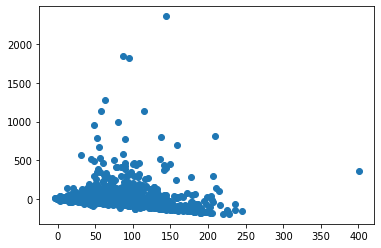

-0.009926774825801727
0.09091326488351326
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.321433 0.066832 4.810 0.000002
## 0.376975 0.243266 1.550 0.121393
## 0.291583 0.026452 11.023 0.000000
## -633.309380 133.719615 -4.736 0.000002
## ---
## Mean squared error: 583.757780 , RMSE: 24.161080
## Multiple R-squared: 0.079821 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

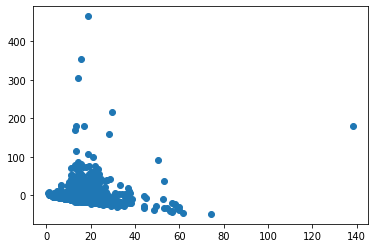

0.04355049990361375
0.12803115643024068
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -3.948141 0.318960 -12.378 0.000000
## -0.919875 1.226636 -0.750 0.453388
## 17.326448 2.266376 7.645 0.000000
## 7966.929298 638.442403 12.479 0.000000
## ---
## Mean squared error: 16553.181647 , RMSE: 128.659169
## Multiple R-squared: 0.099263 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

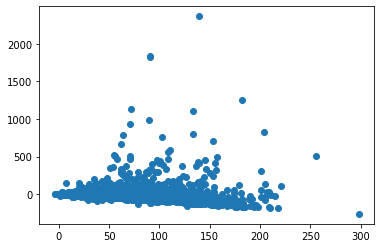

0.02407306836109537
0.08405825897846413
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.375198 0.071137 5.274 0.000000
## 0.391729 0.258268 1.517 0.129506
## 5.225816 0.462861 11.290 0.000000
## -747.098023 142.285118 -5.251 0.000000
## ---
## Mean squared error: 610.515896 , RMSE: 24.708620
## Multiple R-squared: 0.090830 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

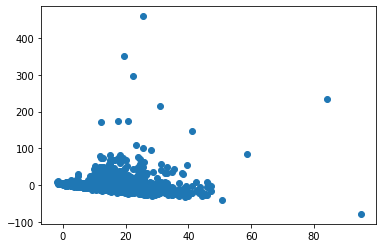

0.04808186094329484
0.10651171049913724
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -4.069487 0.338334 -12.028 0.000000
## -0.726066 1.386501 -0.524 0.600573
## -0.913476 4.008931 -0.228 0.819780
## 8238.865626 677.425478 12.162 0.000000
## ---
## Mean squared error: 17661.590241 , RMSE: 132.896916
## Multiple R-squared: 0.084537 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

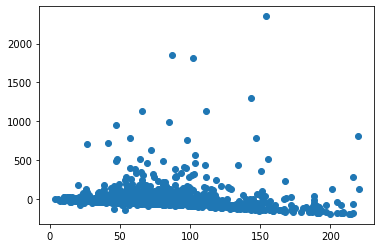

0.12534562952377767
0.09490221746043692
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.312112 0.085436 3.653 0.000269
## 0.669868 0.341014 1.964 0.049689
## 0.236263 1.008489 0.234 0.814807
## -612.912791 170.891376 -3.587 0.000347
## ---
## Mean squared error: 751.755413 , RMSE: 27.418158
## Multiple R-squared: 0.017042 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

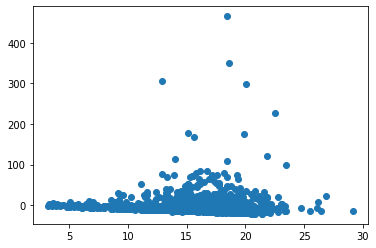

0.09080186937555172
0.10232723113270724
BUSI

-------

country_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -23.047997 0.707995 -32.554 0.000000
## 2.971421 3.056206 0.972 0.330945
## -2.089230 9.348096 -0.223 0.823157
## 46513.617501 1421.483264 32.722 0.000000
## ---
## Mean squared error: 421648.303318 , RMSE: 649.344518
## Multiple R-squared: 0.096958 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

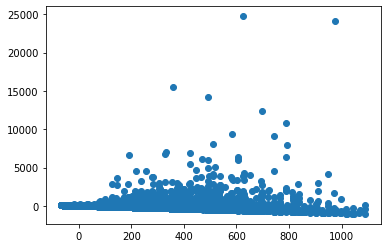

0.138072431214712
0.6452917092432857
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.605338 0.069122 8.758 0.000000
## 0.189331 0.381814 0.496 0.619999
## 2.027322 0.921582 2.200 0.027852
## -1189.143489 138.526554 -8.584 0.000000
## ---
## Mean squared error: 2159.757128 , RMSE: 46.473187
## Multiple R-squared: 0.014082 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

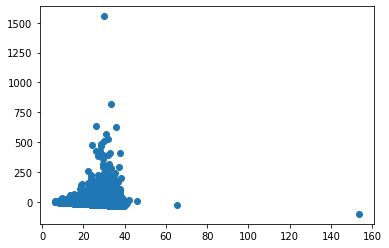

0.10849362349769116
0.7189939506575337
inst_count

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -23.049829 0.708929 -32.514 0.000000
## 2.122415 4.960139 0.428 0.668737
## 0.618865 6.528216 0.095 0.924477
## 46515.480754 1423.703523 32.672 0.000000
## ---
## Mean squared error: 421650.017111 , RMSE: 649.345838
## Multiple R-squared: 0.096955 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

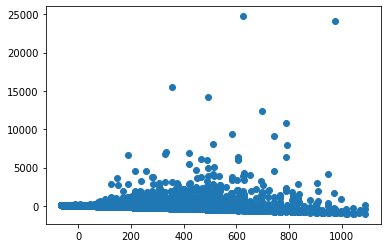

0.11863555785224338
0.8813202751471764
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.601361 0.069016 8.713 0.000000
## -1.276390 0.478453 -2.668 0.007654
## 3.262002 0.627302 5.200 0.000000
## -1180.958757 138.317704 -8.538 0.000000
## ---
## Mean squared error: 2152.923847 , RMSE: 46.399610
## Multiple R-squared: 0.017201 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

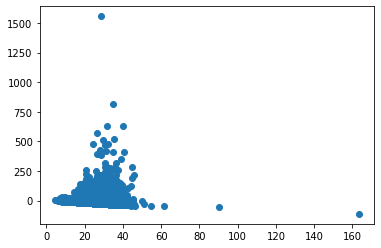

0.12465688858187489
0.8333597643659597
gender_percent

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -23.156513 0.723992 -31.985 0.000000
## 2.214472 2.404653 0.921 0.357119
## -16.796167 25.251690 -0.665 0.505970
## 46742.253440 1457.970935 32.060 0.000000
## ---
## Mean squared error: 421631.883440 , RMSE: 649.331875
## Multiple R-squared: 0.096993 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

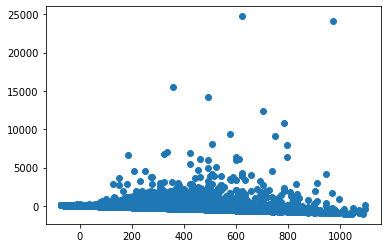

-0.2430749943286225
-0.23331749417709496
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.615475 0.070065 8.784 0.000000
## 0.835322 0.274297 3.045 0.002333
## 1.589203 2.198777 0.723 0.469847
## -1209.507455 140.715142 -8.595 0.000000
## ---
## Mean squared error: 2161.090842 , RMSE: 46.487534
## Multiple R-squared: 0.013473 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

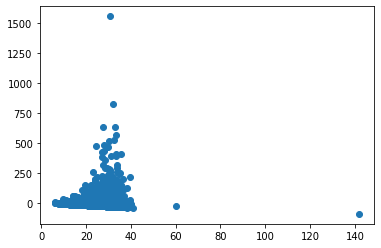

-0.1901219761253271
-0.24909721479870456
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -21.171004 0.731368 -28.947 0.000000
## 2.515154 2.363798 1.064 0.287341
## 5.254585 0.334726 15.698 0.000000
## 42692.208784 1468.647731 29.069 0.000000
## ---
## Mean squared error: 422271.649434 , RMSE: 649.824322
## Multiple R-squared: 0.112079 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

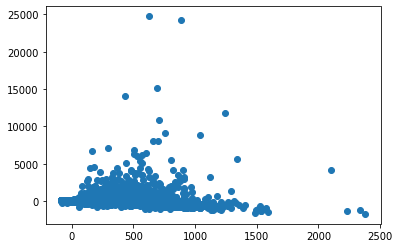

-0.12980547007464666
-0.021719192821282655
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.739216 0.068855 10.736 0.000000
## 0.777367 0.266325 2.919 0.003524
## 0.325738 0.025423 12.813 0.000000
## -1459.266594 138.015679 -10.573 0.000000
## ---
## Mean squared error: 2184.234351 , RMSE: 46.735793
## Multiple R-squared: 0.037030 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

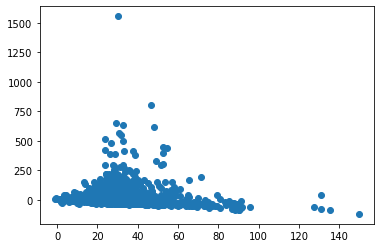

-0.08927456762825495
-0.007878574190356917
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -20.578962 0.943726 -21.806 0.000000
## 3.601901 3.889455 0.926 0.354439
## 106.507503 5.470443 19.470 0.000000
## 41355.758794 1894.059027 21.834 0.000000
## ---
## Mean squared error: 514466.374851 , RMSE: 717.263114
## Multiple R-squared: 0.119218 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

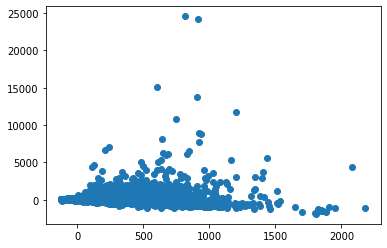

-0.18271495971763946
-0.01798307347771274
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 1.079015 0.074205 14.541 0.000000
## 0.667670 0.274990 2.428 0.015210
## 6.879505 0.379298 18.137 0.000000
## -2148.437987 148.800928 -14.438 0.000000
## ---
## Mean squared error: 2252.922264 , RMSE: 47.464958
## Multiple R-squared: 0.068979 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

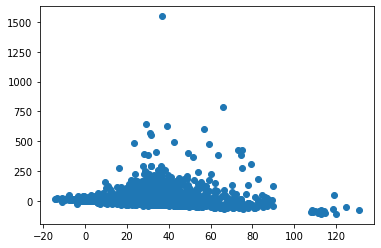

-0.15435657423590668
-0.001067216480727868
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -21.939827 0.755135 -29.054 0.000000
## 2.064291 2.402665 0.859 0.390272
## -6.142000 9.291362 -0.661 0.508602
## 44279.156621 1515.993019 29.208 0.000000
## ---
## Mean squared error: 417025.500258 , RMSE: 645.775116
## Multiple R-squared: 0.092394 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

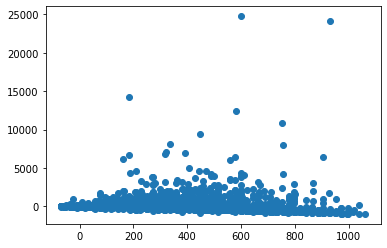

0.12231282157453444
0.0865173960881349
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.659774 0.072114 9.149 0.000000
## 0.822422 0.270390 3.042 0.002363
## -1.693070 0.819032 -2.067 0.038761
## -1297.001137 144.508256 -8.975 0.000000
## ---
## Mean squared error: 2114.691520 , RMSE: 45.985775
## Multiple R-squared: 0.016158 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

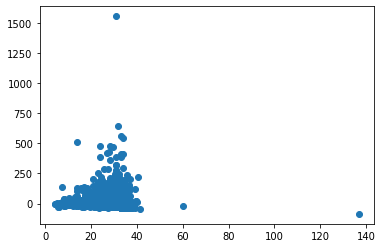

0.11250953801879496
0.12420057538060114
HIndex

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -21.831007 0.727811 -29.995 0.000000
## 2.146790 2.375765 0.904 0.366219
## 4.113306 0.313205 13.133 0.000000
## 44028.282904 1461.378804 30.128 0.000000
## ---
## Mean squared error: 424562.199226 , RMSE: 651.584376
## Multiple R-squared: 0.105504 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

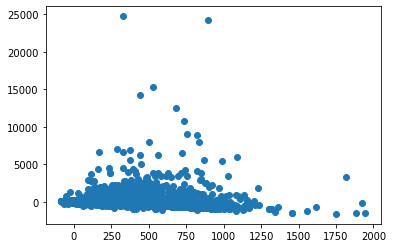

-0.07776086809713176
-0.0058210279580785795
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.709827 0.068728 10.328 0.000000
## 0.821626 0.266615 3.082 0.002066
## 0.302430 0.025237 11.984 0.000000
## -1400.122956 137.753840 -10.164 0.000000
## ---
## Mean squared error: 2184.963121 , RMSE: 46.743589
## Multiple R-squared: 0.034518 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

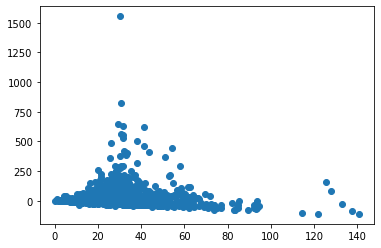

-0.05931544454965505
-0.016208983969717233
HIndex_noself

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -22.084216 0.911999 -24.215 0.000000
## 3.971593 3.834577 1.036 0.300359
## 85.019431 5.203602 16.339 0.000000
## 44414.754838 1829.730488 24.274 0.000000
## ---
## Mean squared error: 510770.490369 , RMSE: 714.682090
## Multiple R-squared: 0.108107 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

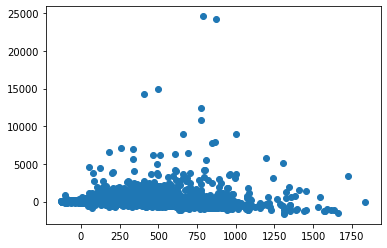

-0.1084102370491257
-0.011433023290266702
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.971548 0.073569 13.206 0.000000
## 0.796224 0.275587 2.889 0.003875
## 5.902846 0.370795 15.919 0.000000
## -1931.403515 147.487921 -13.095 0.000000
## ---
## Mean squared error: 2266.697572 , RMSE: 47.609847
## Multiple R-squared: 0.058293 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

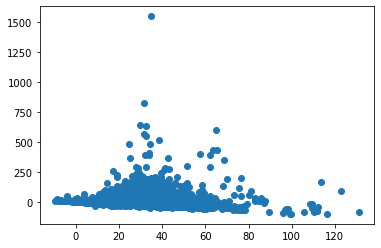

-0.10164127243046132
-0.019758074433823446
IPG_index

----------

Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## -22.099332 0.750766 -29.436 0.000000
## 1.955398 2.398997 0.815 0.415044
## -5.923548 9.833943 -0.602 0.546952
## 44600.080119 1507.425568 29.587 0.000000
## ---
## Mean squared error: 414669.423441 , RMSE: 643.948308
## Multiple R-squared: 0.093547 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

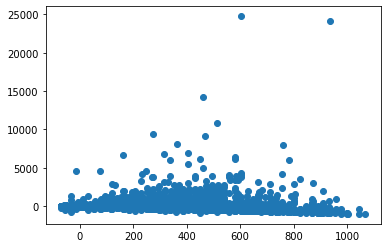

0.07285877754050339
0.10289398828814925
Note: the last rows are the information for Intercept
## -------------------------------------------------
## Estimate | Std.Error | t Values | P-value
## 0.661751 0.070767 9.351 0.000000
## 0.754252 0.264324 2.854 0.004338
## -0.833017 0.834433 -0.998 0.318172
## -1301.332311 141.816708 -9.176 0.000000
## ---
## Mean squared error: 2030.812925 , RMSE: 45.064542
## Multiple R-squared: 0.016656 , Total iterations: 0
/databricks/spark/python/pyspark/sql/context.py:134: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
 warnings.warn(

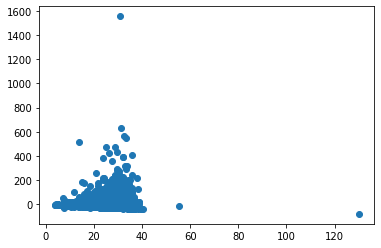

0.08137436961146939
0.1057532012777681

In [0]:
# explode 
df_hyp2 = df_hyp2.withColumn("subjareas", explode("subjareas"))

for AREA in descriptives_output_df.subjareas.unique():
  if AREA == 'undefined': continue
  print(AREA)
  print("\n-------\n")

  # loop over all the variables
  for vars in independent_vars:
    # citations overall 
    # create dataframe, for these use unique Eids
    if (vars == "country_count") | (vars == "inst_count") | (vars == "gender_percent"):
      df_hyp2_overall = df_hyp2.dropDuplicates(['Eid'])
    elif (vars == "HIndex") | (vars == "HIndex_noself"):
      df_hyp2_overall = df_hyp2.filter((col("Authorseq") == 1))
    elif (vars == "IPG_index"):
      df_hyp2_overall = df_hyp2.filter((col("Authorseq") == 1))\
        .filter((col("Inferred_Probable_Gender") == "male") | (col("Inferred_Probable_Gender") == "female"))
    elif (vars == "2HIndex") | (vars == "2HIndex_noself"):
      df_hyp2_overall = df_hyp2.filter((col("Authorseq") == col("team_size")))
      vars = vars[1:]
    elif (vars == "2IPG_index"):
      df_hyp2_overall = df_hyp2.filter((col("Authorseq") == col("team_size")))\
        .filter((col("Inferred_Probable_Gender") == "male") | (col("Inferred_Probable_Gender") == "female"))
      vars = vars[1:]    

    # also filter for subject area 
    df_hyp2_overall = df_hyp2_overall.filter(col("subjareas") == AREA)
    
    # should drop nulls in X
    vectorAssembler = VectorAssembler(inputCols = ['Year', 'team_size', vars], outputCol = "pub_year")
    df_hyp2_overall = vectorAssembler.setHandleInvalid("skip").transform(df_hyp2_overall)

    print(vars)
    print("\n----------\n")

    # put in the features X and prediction Y
    lr = LinearRegression(featuresCol = 'pub_year', labelCol = 'CitationCount')
    lr_model = lr.fit(df_hyp2_overall)
    model_output_df = modelsummary(lr_model, ("hyp2_CitationCount_"+vars+"_"+AREA), model_output_df)

    if (permissions == "default"):
      residuals = lr_model.summary.residuals.select('residuals').collect()
      predictions = lr_model.summary.predictions.select('prediction').collect()

      plt.scatter(predictions, residuals)
      plt.show()
      print(df_hyp2_overall.stat.corr("Year", vars))
      print(df_hyp2_overall.stat.corr("team_size", vars))

    ## citations_5y
    # same DF just drop NULL citations_5y and newer articles 
    # if no citationcount then don't trust citations_5y
    df_hyp2_overall = df_hyp2_overall.where(col("Citations_5y").isNotNull())\
      .filter(col("Year") < 2017)

    # put in the features X and prediction Y
    lr = LinearRegression(featuresCol = 'pub_year', labelCol = 'Citations_5y')
    lr_model = lr.fit(df_hyp2_overall)
    model_output_df = modelsummary(lr_model, ("hyp2_Citation5y_"+vars+"_"+AREA), model_output_df)

    if (permissions == "default"):
      residuals = lr_model.summary.residuals.select('residuals').collect()
      predictions = lr_model.summary.predictions.select('prediction').collect()

      plt.scatter(predictions, residuals)
      plt.show()
      print(df_hyp2_overall.stat.corr("Year", vars))
      print(df_hyp2_overall.stat.corr("team_size", vars))

# Output Tables

Output tables for writing manuscript in R markdown.

In [0]:
# write out results section until I can get download link
pd.set_option('display.max_rows', None)
model_output_df

Out[68]:

,model,coef,se,t,p,r2
0,hyp1a,0.102909,0.004338,23.722083,0.000000e+00,0.000981
1,hyp1a,-200.971800,8.717657,-23.053418,0.000000e+00,0.000981
2,hyp1a_COMP,0.074020,0.001485,49.832318,0.000000e+00,0.067167
3,hyp1a_COMP,-145.340606,2.988997,-48.625211,0.000000e+00,0.067167
4,hyp1a_IMMU,0.126950,0.004147,30.611802,0.000000e+00,0.033409
5,hyp1a_IMMU,-248.270603,8.331003,-29.800807,0.000000e+00,0.033409
6,hyp1a_MATE,0.095774,0.001308,73.237624,0.000000e+00,0.078049
7,hyp1a_MATE,-187.737619,2.630693,-71.364317,0.000000e+00,0.078049
8,hyp1a_ARTS,0.030213,0.002200,13.730582,0.000000e+00,0.017059
9,hyp1a_ARTS,-58.015819,4.418020,-13.131635,0.000000e+00,0.017059


In [0]:
descriptives_output_df

Out[69]:

,model,subjareas,mean,sd,sample,median,iqr_25,iqr_75
0,hyp1a,COMP,3.606727,2.411420,34490,3,2,4
1,hyp1a,IMMU,6.753522,6.631570,27114,6,4,8
2,hyp1a,MATE,4.926532,2.778585,63361,4,3,6
3,hyp1a,ARTS,2.645283,2.495447,10865,2,1,3
4,hyp1a,PHYS,8.519374,82.957976,73192,4,2,6
5,hyp1a,PSYC,3.600548,3.687679,18961,3,2,4
6,hyp1a,HEAL,4.910797,3.393110,6289,4,3,6
7,hyp1a,BIOC,6.538887,11.887155,113239,5,3,8
8,hyp1a,NEUR,5.699891,4.821503,25704,5,3,7
9,hyp1a,VETE,5.508495,4.337002,4179,5,3,7


Running the header notebook for project `proj_050_teamscience` with level `default`

The following are the Scopus snapshot dates available for datasets at v007:
['v007.20210611182924/', 'v007.20210818120551/']
The most recent snapshot will be used unless specified otherwise. This is "v007.20210818120551/", (18 August 2021)
(If you want to use an earlier snapshot, in the first cell of your notebook, set the variable `custom_snapshot_date` to one of the options listed above (string data type))

You will use the latest snapshot date for this version v007.20210818120551/

Setting paths to run on sample datasets